# Analisis Klasifikasi Dry Bean: Decision Tree vs. Random Forest

**Mata kuliah:** Matematika Diskrit  
**Jenis pembelajaran:** Supervised Learning  
**Tugas:** Multiclass Classification  
**Dataset:** Dry Bean  
**Target:** `Class` (7 varietas kacang)  
**Algoritma:** Decision Tree dan Random Forest

## Tujuan
Notebook ini membangun dan membandingkan dua model klasifikasi dengan prosedur yang dapat direproduksi. Notebook memuat audit dataset, pembersihan, EDA, pembagian data, baseline, penggunaan hasil 5-fold cross-validation, training ulang menggunakan parameter terbaik, evaluasi testing, visualisasi, penyimpanan model, dan bukti prediksi.

**Prinsip metodologi:** kedua model memakai pembagian data yang sama; data testing tidak digunakan untuk tuning; Macro F1 menjadi metrik utama; semua random state ditetapkan agar hasil dapat direproduksi.


## Persiapan Google Colab (otomatis)

Jika notebook dijalankan di Google Colab dan folder proyek belum tersedia, jalankan sel berikut. Colab akan meminta satu kali unggahan file `Dry_Bean_Classification_Project.zip`, mengekstraknya, lalu mengatur direktori kerja secara otomatis. Tidak perlu mengetik kode konfigurasi atau mengubah path secara manual.

Jika folder proyek sudah tersedia atau notebook dijalankan dari folder proyek di Jupyter lokal, sel ini akan mendeteksi folder tersebut.

In [1]:

# ============================================================
# SECTION 1: PROJECT SETUP & AUTOMATIC DATASET LOADING
# ============================================================

from pathlib import Path
import os
import zipfile
import shutil


# ------------------------------------------------------------
# A. PROJECT CONFIGURATION
# ------------------------------------------------------------

PROJECT_FOLDER_NAME = 'Dry_Bean_Classification_Project'
DATASET_FILENAME = 'Dry_Bean.csv'

# Menentukan lokasi kerja utama Google Colab.
COLAB_DIR = Path('/content') if Path('/content').exists() else Path.cwd()

# Menyiapkan lokasi pencarian proyek.
SEARCH_ROOTS = [Path.cwd()]

if COLAB_DIR not in SEARCH_ROOTS:
    SEARCH_ROOTS.append(COLAB_DIR)


# ------------------------------------------------------------
# B. PROJECT DIRECTORY DETECTION
# ------------------------------------------------------------

def find_project_root(search_roots):

    # Memeriksa setiap lokasi pencarian.
    for base in search_roots:

        if not base.exists():
            continue

        # Memeriksa apakah direktori aktif sudah merupakan root proyek.
        if (base / 'data' / DATASET_FILENAME).is_file():
            return base.resolve()

        # Memeriksa folder proyek dengan nama standar.
        expected = base / PROJECT_FOLDER_NAME

        if (expected / 'data' / DATASET_FILENAME).is_file():
            return expected.resolve()

        # Memeriksa folder proyek pada tingkat direktori pertama.
        for child in base.iterdir():

            if child.is_dir():

                if (child / 'data' / DATASET_FILENAME).is_file():
                    return child.resolve()

    # Pencarian lanjutan untuk proyek yang berada di dalam ZIP.
    discovered_roots = []

    for base in search_roots:

        if not base.exists():
            continue

        for current, dirs, files_list in os.walk(base):

            # Menghindari pencarian pada folder yang tidak diperlukan.
            dirs[:] = [
                d for d in dirs
                if d not in {
                    'drive',
                    'sample_data',
                    '.ipynb_checkpoints',
                    '__pycache__'
                }
            ]

            if DATASET_FILENAME in files_list:

                current_path = Path(current)

                if current_path.name.lower() == 'data':

                    discovered_roots.append(
                        current_path.parent.resolve()
                    )

    if discovered_roots:

        discovered_roots = list(dict.fromkeys(discovered_roots))

        # Memprioritaskan folder proyek dengan nama standar.
        discovered_roots.sort(
            key=lambda p: (
                p.name != PROJECT_FOLDER_NAME,
                len(p.parts)
            )
        )

        return discovered_roots[0]

    return None


# ------------------------------------------------------------
# C. SAFE ZIP EXTRACTION
# ------------------------------------------------------------

def safe_extract_zip(zip_path, destination):

    destination = destination.resolve()

    with zipfile.ZipFile(zip_path, 'r') as archive:

        # Memastikan tidak ada file ZIP yang keluar dari direktori tujuan.
        for member in archive.infolist():

            target = (destination / member.filename).resolve()

            if os.path.commonpath(
                [str(destination), str(target)]
            ) != str(destination):

                raise ValueError(
                    f'Path tidak aman ditemukan dalam ZIP: {member.filename}'
                )

        archive.extractall(destination)

    print('ZIP berhasil diekstrak:', zip_path.name)


# ------------------------------------------------------------
# D. DATASET NORMALIZATION
# ------------------------------------------------------------

def prepare_project_from_dataset(dataset_file, destination):

    # Membuat struktur direktori proyek standar.
    project_root = destination / PROJECT_FOLDER_NAME

    data_folder = project_root / 'data'

    data_folder.mkdir(parents=True, exist_ok=True)

    target_file = data_folder / DATASET_FILENAME

    # Menyalin dataset ke lokasi standar jika belum berada di sana.
    if dataset_file.resolve() != target_file.resolve():

        shutil.copy2(dataset_file, target_file)

    print('Dataset berhasil ditempatkan pada:', target_file)

    return project_root.resolve()


# ------------------------------------------------------------
# E. INITIAL PROJECT DETECTION
# ------------------------------------------------------------

PROJECT_DIR = find_project_root(SEARCH_ROOTS)

if PROJECT_DIR is not None:

    print('Proyek ditemukan secara otomatis.')

else:

    print('Folder proyek belum ditemukan.')
    print('Memulai proses upload dataset atau ZIP proyek...')

    # Memeriksa apakah notebook dijalankan melalui Google Colab.
    try:

        from google.colab import files

    except ImportError as exc:

        raise FileNotFoundError(
            'Dataset belum ditemukan. '
            'Silakan letakkan Dry_Bean.csv di folder data '
            'atau jalankan notebook melalui Google Colab.'
        ) from exc

    # Membuka dialog upload file.
    uploaded_files = files.upload()

    if not uploaded_files:

        raise FileNotFoundError(
            'Tidak ada file yang diunggah. '
            'Silakan jalankan kembali Section 1.'
        )

    # Menyimpan file hasil upload ke direktori kerja.
    uploaded_paths = []

    for filename, content in uploaded_files.items():

        safe_name = Path(filename).name

        saved_path = Path.cwd() / safe_name

        with open(saved_path, 'wb') as file:

            file.write(content)

        uploaded_paths.append(saved_path)

    # Memisahkan file ZIP dan CSV.
    zip_files = [
        p for p in uploaded_paths
        if p.suffix.lower() == '.zip'
    ]

    csv_files = [
        p for p in uploaded_paths
        if p.name.lower() == DATASET_FILENAME.lower()
    ]

    # Prioritas pertama adalah ZIP proyek.
    if zip_files:

        if len(zip_files) > 1:

            raise ValueError(
                'Unggah hanya satu ZIP proyek agar pemilihan dataset tidak ambigu.'
            )

        extract_destination = COLAB_DIR

        safe_extract_zip(
            zip_files[0],
            extract_destination
        )

        # Mencari root proyek setelah ekstraksi.
        PROJECT_DIR = find_project_root(
            [extract_destination]
        )

        # Jika struktur ZIP tidak memiliki folder data,
        # cari dataset dan susun struktur proyek standar.
        if PROJECT_DIR is None:

            candidates = []

            for current, dirs, files_list in os.walk(extract_destination):

                dirs[:] = [
                    d for d in dirs
                    if d not in {
                        'drive',
                        'sample_data',
                        '.ipynb_checkpoints',
                        '__pycache__'
                    }
                ]

                if DATASET_FILENAME in files_list:

                    candidates.append(
                        Path(current) / DATASET_FILENAME
                    )

            canonical = [
                p for p in candidates
                if p.parent.name.lower() == 'data'
            ]

            if canonical:

                canonical.sort(
                    key=lambda p: (
                        PROJECT_FOLDER_NAME not in str(p),
                        len(p.parts)
                    )
                )

                PROJECT_DIR = canonical[0].parent.parent.resolve()

            elif len(candidates) == 1:

                PROJECT_DIR = prepare_project_from_dataset(
                    candidates[0],
                    extract_destination
                )

            else:

                raise FileNotFoundError(
                    'Dry_Bean.csv tidak ditemukan atau terdapat '
                    'beberapa dataset yang tidak dapat dibedakan '
                    'dalam ZIP.'
                )

    # Alternatif kedua: upload CSV secara langsung.
    elif csv_files:

        if len(csv_files) > 1:

            raise ValueError(
                'Unggah hanya satu file Dry_Bean.csv.'
            )

        PROJECT_DIR = prepare_project_from_dataset(
            csv_files[0],
            COLAB_DIR
        )

    else:

        raise FileNotFoundError(
            'File yang diunggah tidak sesuai. '
            'Silakan unggah ZIP proyek atau Dry_Bean.csv.'
        )


# ------------------------------------------------------------
# F. ACTIVATE PROJECT DIRECTORY
# ------------------------------------------------------------

PROJECT_DIR = Path(PROJECT_DIR).resolve()

DATA_PATH = PROJECT_DIR / 'data' / DATASET_FILENAME

# Memastikan dataset benar-benar tersedia.
if not DATA_PATH.is_file():

    raise FileNotFoundError(
        f'Dataset tidak ditemukan pada lokasi: {DATA_PATH}'
    )

# Mengaktifkan direktori utama proyek.
os.chdir(PROJECT_DIR)


# ------------------------------------------------------------
# G. CREATE PROJECT DIRECTORY STRUCTURE
# ------------------------------------------------------------

OUTPUT_DIR = PROJECT_DIR / 'outputs'

MODEL_DIR = PROJECT_DIR / 'models'

EVIDENCE_DIR = PROJECT_DIR / 'evidence'

for folder in [
    OUTPUT_DIR,
    MODEL_DIR,
    EVIDENCE_DIR
]:

    folder.mkdir(
        parents=True,
        exist_ok=True
    )


# ------------------------------------------------------------
# H. FINAL PROJECT VALIDATION
# ------------------------------------------------------------

print('\n' + '=' * 60)

print('SECTION 1 BERHASIL DIJALANKAN')

print('=' * 60)

print('Project directory :', PROJECT_DIR)

print('Dataset path      :', DATA_PATH)

print('Dataset available :', DATA_PATH.is_file())

print('Output directory  :', OUTPUT_DIR)

print('Model directory   :', MODEL_DIR)

print('Evidence directory :', EVIDENCE_DIR)

print('\nProject structure:')

for folder in [
    PROJECT_DIR / 'data',
    OUTPUT_DIR,
    MODEL_DIR,
    EVIDENCE_DIR
]:

    print(
        f'- {folder.name}: '
        f'{"READY" if folder.exists() else "NOT FOUND"}'
    )

print('\nDataset loading preparation completed.')

print('Silakan lanjutkan ke SECTION 2.')

print('=' * 60)


Folder proyek belum ditemukan.
Memulai proses upload dataset atau ZIP proyek...


Saving Dry_Bean_Classification_Submission_FINAL_1 (1).zip to Dry_Bean_Classification_Submission_FINAL_1 (1).zip
ZIP berhasil diekstrak: Dry_Bean_Classification_Submission_FINAL_1 (1).zip

SECTION 1 BERHASIL DIJALANKAN
Project directory : /content/Dry_Bean_Classification_Submission
Dataset path      : /content/Dry_Bean_Classification_Submission/data/Dry_Bean.csv
Dataset available : True
Output directory  : /content/Dry_Bean_Classification_Submission/outputs
Model directory   : /content/Dry_Bean_Classification_Submission/models
Evidence directory : /content/Dry_Bean_Classification_Submission/evidence

Project structure:
- data: READY
- outputs: READY
- models: READY
- evidence: READY

Dataset loading preparation completed.
Silakan lanjutkan ke SECTION 2.


## 1. Dasar matematis dan algoritmik

### 1.1 Supervised learning dan klasifikasi
Pada supervised learning, model mempelajari pemetaan dari fitur \(X\) menuju label \(y\) menggunakan pasangan data berlabel. Pada proyek ini, \(X\) berisi 16 karakteristik geometris, sedangkan \(y\) adalah satu dari tujuh varietas kacang.

### 1.2 Entropy
Entropy mengukur ketidakpastian distribusi kelas pada suatu himpunan data:

\[
H(S)=-\sum_{i=1}^{k}p_i\log_2(p_i)
\]

Nilai \(p_i\) adalah proporsi anggota kelas ke-\(i\). Entropy bernilai nol jika seluruh anggota himpunan berasal dari satu kelas.

### 1.3 Information Gain
Decision Tree memilih pemisahan fitur yang memberikan penurunan entropy terbesar:

\[
IG(S,A)=H(S)-\sum_{v\in Values(A)}\frac{|S_v|}{|S|}H(S_v)
\]

Kriteria `entropy` pada Decision Tree menggunakan prinsip ini. Kriteria `gini` merupakan alternatif impurity measure.

### 1.4 Random Forest dan majority voting
Random Forest membangun banyak pohon dari sampel bootstrap dan subset fitur yang dipilih secara acak. Untuk klasifikasi, prediksi akhir ditentukan melalui voting mayoritas:

\[
\hat{y}=\operatorname{mode}\{T_1(x),T_2(x),\ldots,T_B(x)\}
\]

### 1.5 Kaitan dengan Matematika Diskrit
- Himpunan: partisi data training dan testing serta himpunan kelas.
- Logika: aturan percabangan IF-THEN pada Decision Tree.
- Probabilitas: distribusi kelas, bootstrap sampling, dan estimasi performa.
- Kombinatorika: kombinasi pohon dan subset fitur pada Random Forest.
- Fungsi: pemetaan vektor fitur menjadi label kelas.


## 2. Import library dan konfigurasi

In [2]:

# ============================================================
# SECTION 2: IMPORT LIBRARIES, CONFIGURATION & ENVIRONMENT SETUP
# ============================================================

# ------------------------------------------------------------
# A. IMPORT STANDARD LIBRARIES
# ------------------------------------------------------------

from pathlib import Path

import os
import json
import time
import platform
import warnings
import sys


# ------------------------------------------------------------
# B. IMPORT DATA PROCESSING LIBRARIES
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown


# ------------------------------------------------------------
# C. IMPORT SCIKIT-LEARN LIBRARIES
# ------------------------------------------------------------

import sklearn

from sklearn import __version__ as sklearn_version

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    ParameterGrid
)

from sklearn.base import clone

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree,
    export_text
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ------------------------------------------------------------
# D. IMPORT MODEL STORAGE LIBRARY
# ------------------------------------------------------------

import joblib


# ------------------------------------------------------------
# E. WARNING CONFIGURATION
# ------------------------------------------------------------

warnings.filterwarnings(
    'ignore',
    category=FutureWarning
)

warnings.filterwarnings(
    'ignore',
    category=UserWarning
)


# ------------------------------------------------------------
# F. EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

RANDOM_STATE = 42

TEST_SIZE = 0.20

CV_FOLDS = 5

N_REPEATS = 5

EXPERIMENT_SEEDS = [
    42,
    43,
    44,
    45,
    46
]

TARGET = 'Class'

SCORING_METRIC = 'f1_macro'


# ------------------------------------------------------------
# G. PROJECT DIRECTORY VALIDATION
# ------------------------------------------------------------

required_variables = [
    'PROJECT_DIR',
    'DATA_PATH',
    'OUTPUT_DIR',
    'MODEL_DIR',
    'EVIDENCE_DIR'
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:

    raise NameError(
        f'Konfigurasi Section 1 belum tersedia: {missing_variables}. '
        'Jalankan Section 1 terlebih dahulu.'
    )


# Mengubah seluruh lokasi proyek menjadi Path absolut.

PROJECT_DIR = Path(PROJECT_DIR).resolve()

DATA_PATH = Path(DATA_PATH).resolve()

OUTPUT_DIR = Path(OUTPUT_DIR).resolve()

MODEL_DIR = Path(MODEL_DIR).resolve()

EVIDENCE_DIR = Path(EVIDENCE_DIR).resolve()


# Memastikan direktori kerja berada pada root proyek.

os.chdir(PROJECT_DIR)


# ------------------------------------------------------------
# H. DIRECTORY VALIDATION
# ------------------------------------------------------------

if not DATA_PATH.is_file():

    raise FileNotFoundError(
        f'Dataset tidak ditemukan: {DATA_PATH}'
    )


for folder in [
    OUTPUT_DIR,
    MODEL_DIR,
    EVIDENCE_DIR
]:

    folder.mkdir(
        parents=True,
        exist_ok=True
    )


# ------------------------------------------------------------
# I. DISPLAY CONFIGURATION
# ------------------------------------------------------------

pd.set_option(
    'display.max_columns',
    None
)

pd.set_option(
    'display.width',
    120
)

pd.set_option(
    'display.max_rows',
    100
)


# ------------------------------------------------------------
# J. ENVIRONMENT INFORMATION
# ------------------------------------------------------------

environment_info = {

    'python_version': platform.python_version(),

    'python_implementation': platform.python_implementation(),

    'operating_system': platform.system(),

    'platform': platform.platform(),

    'pandas_version': pd.__version__,

    'numpy_version': np.__version__,

    'matplotlib_version': plt.matplotlib.__version__,

    'scikit_learn_version': sklearn_version,

    'project_directory': str(PROJECT_DIR),

    'dataset_path': str(DATA_PATH),

    'random_state': RANDOM_STATE,

    'test_size': TEST_SIZE,

    'cross_validation_folds': CV_FOLDS,

    'experiment_repetitions': N_REPEATS,

    'experiment_seeds': EXPERIMENT_SEEDS,

    'target_column': TARGET,

    'tuning_scoring': SCORING_METRIC

}


# ------------------------------------------------------------
# K. SAVE ENVIRONMENT CONFIGURATION
# ------------------------------------------------------------

with open(
    EVIDENCE_DIR / 'environment_configuration.json',
    'w',
    encoding='utf-8'
) as file:

    json.dump(
        environment_info,
        file,
        indent=4,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# L. FINAL EXECUTION SUMMARY
# ------------------------------------------------------------

print('\n' + '=' * 65)

print('SECTION 2 BERHASIL DIJALANKAN')

print('=' * 65)

print('\nLIBRARY VERSIONS')

print('Python        :', platform.python_version())

print('Pandas        :', pd.__version__)

print('NumPy         :', np.__version__)

print('Matplotlib    :', plt.matplotlib.__version__)

print('Scikit-learn  :', sklearn_version)

print('\nEXPERIMENT CONFIGURATION')

print('Random State  :', RANDOM_STATE)

print('Test Size     :', f'{TEST_SIZE:.0%}')

print('CV Folds      :', CV_FOLDS)

print('Repetitions   :', N_REPEATS)

print('Experiment Seeds:', EXPERIMENT_SEEDS)

print('Target        :', TARGET)

print('Scoring       :', SCORING_METRIC)

print('\nPROJECT DIRECTORIES')

print('Project       :', PROJECT_DIR)

print('Dataset       :', DATA_PATH)

print('Outputs       :', OUTPUT_DIR)

print('Models        :', MODEL_DIR)

print('Evidence      :', EVIDENCE_DIR)

print('\nConfiguration berhasil disimpan.')

print('File: environment_configuration.json')

print('\nSilakan lanjutkan ke SECTION 3.')

print('=' * 65)



SECTION 2 BERHASIL DIJALANKAN

LIBRARY VERSIONS
Python        : 3.13.18
Pandas        : 2.2.3
NumPy         : 2.4.6
Matplotlib    : 3.10.0
Scikit-learn  : 1.6.1

EXPERIMENT CONFIGURATION
Random State  : 42
Test Size     : 20%
CV Folds      : 5
Repetitions   : 5
Experiment Seeds: [42, 43, 44, 45, 46]
Target        : Class
Scoring       : f1_macro

PROJECT DIRECTORIES
Project       : /content/Dry_Bean_Classification_Submission
Dataset       : /content/Dry_Bean_Classification_Submission/data/Dry_Bean.csv
Outputs       : /content/Dry_Bean_Classification_Submission/outputs
Models        : /content/Dry_Bean_Classification_Submission/models
Evidence      : /content/Dry_Bean_Classification_Submission/evidence

Configuration berhasil disimpan.
File: environment_configuration.json

Silakan lanjutkan ke SECTION 3.


## 3. Memuat dataset dan memahami struktur

In [3]:

# ============================================================
# SECTION 3: DATASET LOADING & INITIAL INSPECTION
# ============================================================

# ------------------------------------------------------------
# A. PREPARATION & VALIDATION
# ------------------------------------------------------------

# Memastikan konfigurasi Section 2 tersedia.

required_variables = [
    'DATA_PATH',
    'TARGET',
    'OUTPUT_DIR',
    'EVIDENCE_DIR'
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:

    raise NameError(
        f'Variabel konfigurasi belum tersedia: {missing_variables}. '
        'Jalankan Section 2 terlebih dahulu.'
    )


# Memastikan dataset tersedia.

if not DATA_PATH.is_file():

    raise FileNotFoundError(
        f'Dataset Dry Bean tidak ditemukan: {DATA_PATH}'
    )


# ------------------------------------------------------------
# B. LOAD RAW DATASET
# ------------------------------------------------------------

df_raw = pd.read_csv(DATA_PATH)


# ------------------------------------------------------------
# C. DATASET STRUCTURE VALIDATION
# ------------------------------------------------------------

# Memastikan dataset tidak kosong.

if df_raw.empty:

    raise ValueError(
        'Dataset kosong. Periksa kembali file Dry_Bean.csv.'
    )


# Membersihkan spasi yang tidak diperlukan pada nama kolom.

df_raw.columns = df_raw.columns.astype(str).str.strip()


# Memastikan nama kolom tidak mengalami duplikasi.

if not df_raw.columns.is_unique:

    duplicated_columns = df_raw.columns[
        df_raw.columns.duplicated()
    ].tolist()

    raise ValueError(
        f'Nama kolom duplikat ditemukan: {duplicated_columns}'
    )


# Memastikan kolom target tersedia.

if TARGET not in df_raw.columns:

    raise ValueError(
        f'Kolom target {TARGET} tidak ditemukan. '
        f'Kolom yang tersedia: {df_raw.columns.tolist()}'
    )


# Memisahkan nama fitur dan target.

feature_cols = [
    column
    for column in df_raw.columns
    if column != TARGET
]


# Memastikan fitur prediktor tersedia.

if not feature_cols:

    raise ValueError(
        'Tidak ditemukan fitur prediktor dalam dataset.'
    )


# ------------------------------------------------------------
# D. BASIC DATASET INFORMATION
# ------------------------------------------------------------

total_rows = len(df_raw)

total_columns = df_raw.shape[1]

total_features = len(feature_cols)

total_classes = df_raw[TARGET].nunique()

missing_cells = int(
    df_raw.isna().sum().sum()
)


# ------------------------------------------------------------
# E. FEATURE DATA TYPE VALIDATION
# ------------------------------------------------------------

feature_dtypes = df_raw[feature_cols].dtypes

numeric_features = [
    column
    for column in feature_cols
    if pd.api.types.is_numeric_dtype(df_raw[column])
]

non_numeric_features = [
    column
    for column in feature_cols
    if not pd.api.types.is_numeric_dtype(df_raw[column])
]


# ------------------------------------------------------------
# F. TARGET CLASS INFORMATION
# ------------------------------------------------------------

target_classes = sorted(
    df_raw[TARGET].dropna().unique().tolist()
)


# ------------------------------------------------------------
# G. DATASET INSPECTION SUMMARY
# ------------------------------------------------------------

dataset_summary = {

    'dataset_name': 'Dry Bean Classification',

    'dataset_file': DATA_PATH.name,

    'total_observations': total_rows,

    'total_columns': total_columns,

    'total_features': total_features,

    'target_column': TARGET,

    'number_of_classes': total_classes,

    'target_classes': target_classes,

    'numeric_features': len(numeric_features),

    'non_numeric_features': non_numeric_features,

    'missing_cells': missing_cells

}


display(
    pd.Series(
        dataset_summary,
        name='value'
    ).to_frame()
)


# ------------------------------------------------------------
# H. DISPLAY DATASET PREVIEW
# ------------------------------------------------------------

print('\nFIVE FIRST DATASET OBSERVATIONS')

display(
    df_raw.head(5)
)


# ------------------------------------------------------------
# I. DISPLAY COLUMN INFORMATION
# ------------------------------------------------------------

print('\nDATASET COLUMN INFORMATION')

display(
    df_raw.dtypes.to_frame('data_type')
)


# ------------------------------------------------------------
# J. DISPLAY FEATURE INFORMATION
# ------------------------------------------------------------

print('\nFEATURE LIST')

for index, feature in enumerate(feature_cols, start=1):

    print(f'{index:02d}. {feature}')


# ------------------------------------------------------------
# K. DISPLAY TARGET CLASS INFORMATION
# ------------------------------------------------------------

print('\nTARGET CLASS INFORMATION')

print('Target column :', TARGET)

print('Number of classes:', total_classes)

print('Class labels:')

for index, class_name in enumerate(target_classes, start=1):

    print(f'{index}. {class_name}')


# ------------------------------------------------------------
# L. DATASET VALIDATION WARNINGS
# ------------------------------------------------------------

if total_features != 16:

    print(
        '\nWARNING: Dataset memiliki',
        total_features,
        'fitur, sedangkan dataset referensi memiliki 16 fitur.'
    )

else:

    print('\nFeature count validation: PASS')


if total_classes != 7:

    print(
        'WARNING: Jumlah kelas berbeda dari tujuh kelas '
        'pada dataset referensi.'
    )

else:

    print('Target class validation: PASS')


if non_numeric_features:

    print(
        'WARNING: Ditemukan fitur non-numerik:',
        non_numeric_features
    )

else:

    print('Numeric feature validation: PASS')


# ------------------------------------------------------------
# M. FINAL EXECUTION SUMMARY
# ------------------------------------------------------------

print('\n' + '=' * 65)

print('SECTION 3 BERHASIL DIJALANKAN')

print('=' * 65)

print(f'Dataset name       : Dry Bean Classification')

print(f'Dataset location   : {DATA_PATH}')

print(f'Total observations : {total_rows:,}')

print(f'Total columns      : {total_columns}')

print(f'Total features     : {total_features}')

print(f'Total classes      : {total_classes}')

print(f'Missing cells      : {missing_cells}')

print(f'Numeric features   : {len(numeric_features)}')

print(f'Non-numeric features: {len(non_numeric_features)}')

print('\nDataset berhasil dimuat dan diperiksa.')

print('Variabel df_raw dan feature_cols siap digunakan.')

print('Silakan lanjutkan ke SECTION 4.')

print('=' * 65)


,value
dataset_name,Dry Bean Classification
dataset_file,Dry_Bean.csv
total_observations,13611
total_columns,17
total_features,16
target_column,Class
number_of_classes,7
target_classes,"[BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKE..."
numeric_features,16
non_numeric_features,[]



FIVE FIRST DATASET OBSERVATIONS


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER



DATASET COLUMN INFORMATION


,data_type
Area,int64
Perimeter,float64
MajorAxisLength,float64
MinorAxisLength,float64
AspectRation,float64
Eccentricity,float64
ConvexArea,int64
EquivDiameter,float64
Extent,float64
Solidity,float64



FEATURE LIST
01. Area
02. Perimeter
03. MajorAxisLength
04. MinorAxisLength
05. AspectRation
06. Eccentricity
07. ConvexArea
08. EquivDiameter
09. Extent
10. Solidity
11. roundness
12. Compactness
13. ShapeFactor1
14. ShapeFactor2
15. ShapeFactor3
16. ShapeFactor4

TARGET CLASS INFORMATION
Target column : Class
Number of classes: 7
Class labels:
1. BARBUNYA
2. BOMBAY
3. CALI
4. DERMASON
5. HOROZ
6. SEKER
7. SIRA

Feature count validation: PASS
Target class validation: PASS
Numeric feature validation: PASS

SECTION 3 BERHASIL DIJALANKAN
Dataset name       : Dry Bean Classification
Dataset location   : /content/Dry_Bean_Classification_Submission/data/Dry_Bean.csv
Total observations : 13,611
Total columns      : 17
Total features     : 16
Total classes      : 7
Missing cells      : 0
Numeric features   : 16
Non-numeric features: 0

Dataset berhasil dimuat dan diperiksa.
Variabel df_raw dan feature_cols siap digunakan.
Silakan lanjutkan ke SECTION 4.


## 4. Audit kualitas data dan preprocessing

Audit mencakup missing values, tipe data, duplikasi eksak, dan konflik label. Ditemukan 68 baris duplikasi eksak, seluruhnya pada kelas HOROZ. Sumber dataset tidak menyediakan ID spesimen, sehingga tidak dapat dipastikan apakah baris identik merupakan duplikasi administrasi atau spesimen berbeda dengan pengukuran yang sama. Untuk eksperimen utama, satu salinan dari setiap baris identik dipertahankan agar rekaman identik tidak tersebar pada training dan testing. Keputusan ini dicatat sebagai keterbatasan dan perlu dijelaskan dalam laporan.


In [4]:

# ============================================================
# SECTION 4: DATA QUALITY ASSESSMENT & DATA CLEANING
# ============================================================

# ------------------------------------------------------------
# A. PREPARATION & VALIDATION
# ------------------------------------------------------------

from pathlib import Path

# Memastikan dataset dan konfigurasi tersedia.

if 'df_raw' not in globals():
    raise NameError('df_raw belum tersedia. Jalankan Section 3 terlebih dahulu.')

if 'TARGET' not in globals():
    raise NameError('TARGET belum tersedia. Jalankan Section 2 terlebih dahulu.')

if 'feature_cols' not in globals():
    raise NameError('feature_cols belum tersedia. Jalankan Section 3 terlebih dahulu.')

if TARGET not in df_raw.columns:
    raise ValueError(f'Kolom target {TARGET} tidak ditemukan.')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# B. MISSING VALUE ASSESSMENT
# ------------------------------------------------------------

missing_by_column = df_raw.isna().sum()

total_missing_values = int(
    missing_by_column.sum()
)

missing_percentage = (
    missing_by_column / len(df_raw) * 100
).round(4)


missing_summary = pd.DataFrame({

    'missing_count': missing_by_column,

    'missing_percentage': missing_percentage

})


# ------------------------------------------------------------
# C. DUPLICATE DATA ASSESSMENT
# ------------------------------------------------------------

# Menghitung jumlah baris duplikat eksak.

duplicate_exact_count = int(
    df_raw.duplicated(keep='first').sum()
)


# Mengambil seluruh baris yang termasuk kelompok duplikat.

duplicate_rows_all = df_raw.loc[
    df_raw.duplicated(keep=False)
].copy()


# Menghitung distribusi kelas pada baris duplikat.

duplicate_class_counts = {

    str(class_name): int(count)

    for class_name, count
    in duplicate_rows_all[TARGET].value_counts().items()

}


# ------------------------------------------------------------
# D. DATA TYPE VALIDATION
# ------------------------------------------------------------

non_numeric_features = [

    column

    for column in feature_cols

    if not pd.api.types.is_numeric_dtype(df_raw[column])

]


# ------------------------------------------------------------
# E. NUMERICAL VALUE VALIDATION
# ------------------------------------------------------------

if not non_numeric_features:

    numeric_values = df_raw[feature_cols].to_numpy(dtype=float)

    infinite_cells = int(
        (~np.isfinite(numeric_values)).sum()
    )

else:

    infinite_cells = None


# ------------------------------------------------------------
# F. FEATURE-LABEL CONSISTENCY CHECK
# ------------------------------------------------------------

# Memeriksa apakah fitur yang identik memiliki label berbeda.

if total_missing_values == 0 and not non_numeric_features:

    duplicate_feature_groups = (

        df_raw.groupby(
            feature_cols,
            dropna=False
        )[TARGET].nunique()

    )

    conflicting_feature_groups = int(
        (duplicate_feature_groups > 1).sum()
    )

else:

    conflicting_feature_groups = None


# ------------------------------------------------------------
# G. DATA QUALITY REPORT
# ------------------------------------------------------------

quality_summary = {

    'project': 'Dry Bean Classification',

    'raw_rows': int(len(df_raw)),

    'raw_columns': int(df_raw.shape[1]),

    'feature_count': int(len(feature_cols)),

    'target_column': TARGET,

    'missing_cells': total_missing_values,

    'exact_duplicate_rows_extra': duplicate_exact_count,

    'classes_containing_duplicate_rows': duplicate_class_counts,

    'conflicting_feature_label_groups': conflicting_feature_groups,

    'non_numeric_feature_columns': non_numeric_features,

    'infinite_numeric_cells': infinite_cells,

    'target_classes': sorted(
        df_raw[TARGET].dropna().unique().tolist()
    ),

    'target_class_count': int(df_raw[TARGET].nunique())

}


print('\nDATA QUALITY ASSESSMENT')

display(
    pd.Series(
        quality_summary,
        name='value'
    ).to_frame()
)

print('\nMISSING VALUE ASSESSMENT')

display(missing_summary)


# ------------------------------------------------------------
# H. DATA QUALITY VALIDATION
# ------------------------------------------------------------

if total_missing_values > 0:

    raise ValueError(
        'Missing values ditemukan. '
        'Strategi penanganan perlu ditentukan sebelum training.'
    )


if non_numeric_features:

    raise TypeError(
        f'Fitur non-numerik ditemukan: {non_numeric_features}'
    )


if infinite_cells > 0:

    raise ValueError(
        f'Ditemukan {infinite_cells} nilai infinite pada fitur numerik.'
    )


if conflicting_feature_groups and conflicting_feature_groups > 0:

    raise ValueError(
        'Ditemukan kombinasi fitur identik dengan label berbeda. '
        'Diperlukan investigasi sebelum proses cleaning.'
    )


# ------------------------------------------------------------
# I. REMOVE EXACT DUPLICATES
# ------------------------------------------------------------

# Menyimpan indeks asli sebelum menghapus duplikasi.

df_clean = df_raw.copy()

df_clean.insert(
    0,
    'source_row_index',
    df_raw.index
)


# Menghapus baris duplikat eksak berdasarkan seluruh
# kolom asli, termasuk target Class.

df_clean = df_clean.loc[
    ~df_raw.duplicated(keep='first')
].reset_index(drop=True)


# Memastikan daftar fitur tidak memasukkan target
# maupun source_row_index.

feature_cols = [

    column

    for column in df_clean.columns

    if column not in [TARGET, 'source_row_index']

]


# ------------------------------------------------------------
# J. POST-CLEANING VALIDATION
# ------------------------------------------------------------

assert not df_clean.duplicated(
    subset=[TARGET] + feature_cols
).any(), 'Duplikasi eksak masih ditemukan.'

assert df_clean['source_row_index'].is_unique, (
    'Indeks sumber data tidak unik.'
)

assert len(df_clean) > 0, (
    'Dataset bersih tidak boleh kosong.'
)


# Memperbarui ringkasan kualitas data.

quality_summary['clean_rows'] = int(len(df_clean))

quality_summary['removed_exact_duplicates'] = int(
    len(df_raw) - len(df_clean)
)

quality_summary['clean_missing_cells'] = int(
    df_clean.isna().sum().sum()
)


# ------------------------------------------------------------
# K. SAVE CLEANED DATASET AND EVIDENCE
# ------------------------------------------------------------

df_clean.to_csv(
    OUTPUT_DIR / 'cleaned_dry_bean.csv',
    index=False
)


missing_summary.to_csv(
    EVIDENCE_DIR / 'missing_value_report.csv'
)


duplicate_rows_all.to_csv(
    EVIDENCE_DIR / 'duplicate_rows_report.csv',
    index=False
)


with open(
    EVIDENCE_DIR / 'data_quality_report.json',
    'w',
    encoding='utf-8'
) as file:

    json.dump(
        quality_summary,
        file,
        indent=4,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# L. FINAL EXECUTION SUMMARY
# ------------------------------------------------------------

print('\n' + '=' * 65)

print('SECTION 4 BERHASIL DIJALANKAN')

print('=' * 65)

print(f'Raw observations       : {len(df_raw):,}')

print(f'Clean observations     : {len(df_clean):,}')

print(f'Removed duplicates     : {duplicate_exact_count:,}')

print(f'Remaining features     : {len(feature_cols)}')

print(f'Missing values         : {total_missing_values}')

print(f'Conflicting groups     : {conflicting_feature_groups}')

print(f'Infinite values        : {infinite_cells}')

print('\nVALIDATION STATUS')

print('Missing values        : PASS')

print('Numeric features       : PASS')

print('Duplicate consistency : PASS')

print('Source index tracking  : PASS')

print('\nSAVED FILES')

print('- cleaned_dry_bean.csv')

print('- missing_value_report.csv')

print('- duplicate_rows_report.csv')

print('- data_quality_report.json')

print('\nDataset cleaning selesai.')

print('Silakan lanjutkan ke SECTION 5.')

print('=' * 65)



DATA QUALITY ASSESSMENT


,value
project,Dry Bean Classification
raw_rows,13611
raw_columns,17
feature_count,16
target_column,Class
missing_cells,0
exact_duplicate_rows_extra,68
classes_containing_duplicate_rows,{'HOROZ': 136}
conflicting_feature_label_groups,0
non_numeric_feature_columns,[]



MISSING VALUE ASSESSMENT


,missing_count,missing_percentage
Area,0,0.0
Perimeter,0,0.0
MajorAxisLength,0,0.0
MinorAxisLength,0,0.0
AspectRation,0,0.0
Eccentricity,0,0.0
ConvexArea,0,0.0
EquivDiameter,0,0.0
Extent,0,0.0
Solidity,0,0.0



SECTION 4 BERHASIL DIJALANKAN
Raw observations       : 13,611
Clean observations     : 13,543
Removed duplicates     : 68
Remaining features     : 16
Missing values         : 0
Conflicting groups     : 0
Infinite values        : 0

VALIDATION STATUS
Missing values        : PASS
Numeric features       : PASS
Duplicate consistency : PASS
Source index tracking  : PASS

SAVED FILES
- cleaned_dry_bean.csv
- missing_value_report.csv
- duplicate_rows_report.csv
- data_quality_report.json

Dataset cleaning selesai.
Silakan lanjutkan ke SECTION 5.


## 5. Distribusi kelas dan statistik deskriptif

,class,count,percentage
0,BARBUNYA,1322,9.76
1,BOMBAY,522,3.85
2,CALI,1630,12.04
3,DERMASON,3546,26.18
4,HOROZ,1860,13.73
5,SEKER,2027,14.97
6,SIRA,2636,19.46



CLASS DISTRIBUTION SUMMARY
Total classes       : 7
Largest class       : DERMASON
Largest class count : 3546
Smallest class      : BOMBAY
Smallest class count: 522
Largest/Smallest ratio: 6.79


,count,mean,std,min,25%,50%,75%,max
Area,13543.0,53048.4604,29392.4383,20420.0000,36282.5000,44580.0000,61382.0000,254616.0000
Perimeter,13543.0,854.9934,214.7227,524.7360,703.2300,793.8960,977.1465,1985.3700
MajorAxisLength,13543.0,319.8956,85.8093,183.6012,253.0868,296.4046,376.3125,738.8602
MinorAxisLength,13543.0,202.3653,45.0516,122.5127,175.8864,192.4911,217.2454,460.1985
AspectRation,13543.0,1.5811,0.2452,1.0249,1.4307,1.5499,1.7039,2.4303
Eccentricity,13543.0,0.7503,0.0919,0.2190,0.7151,0.7640,0.8097,0.9114
ConvexArea,13543.0,53767.9867,29844.2485,20684.0000,36673.0000,45122.0000,62360.0000,263261.0000
EquivDiameter,13543.0,253.0341,59.3077,161.2438,214.9333,238.2457,279.5604,569.3744
Extent,13543.0,0.7498,0.0489,0.5553,0.7187,0.7599,0.7868,0.8662
Solidity,13543.0,0.9872,0.0047,0.9192,0.9857,0.9883,0.9900,0.9947



AVERAGE FEATURE VALUES BY CLASS


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
Class,,,,,,,,,,,,,,,,
BARBUNYA,69804.1331,1046.1058,370.0443,240.3094,1.5444,0.7547,71025.7292,297.3110,0.7493,0.9828,0.8002,0.8050,0.0054,0.0014,0.6491,0.9957
BOMBAY,173485.0594,1585.6191,593.1521,374.3525,1.5855,0.7705,175813.1169,468.9414,0.7766,0.9869,0.8644,0.7926,0.0034,0.0008,0.6292,0.9918
CALI,75538.2110,1057.6343,409.4995,236.3706,1.7337,0.8148,76688.5031,309.5353,0.7590,0.9850,0.8459,0.7567,0.0055,0.0011,0.5730,0.9906
DERMASON,32118.7109,665.2095,246.5573,165.6571,1.4905,0.7366,32498.4351,201.6838,0.7530,0.9882,0.9081,0.8191,0.0078,0.0022,0.6716,0.9969
HOROZ,53671.7328,920.1086,372.6939,184.1978,2.0265,0.8675,54463.1011,260.7916,0.7055,0.9855,0.7944,0.7008,0.0070,0.0010,0.4917,0.9919
SEKER,39881.3000,727.6724,251.2920,201.9097,1.2452,0.5848,40269.5673,224.9484,0.7717,0.9904,0.9445,0.8968,0.0063,0.0025,0.8051,0.9984
SIRA,44729.1286,796.4187,299.3803,190.8002,1.5701,0.7673,45273.0998,238.3353,0.7494,0.9880,0.8847,0.7973,0.0067,0.0017,0.6364,0.9954


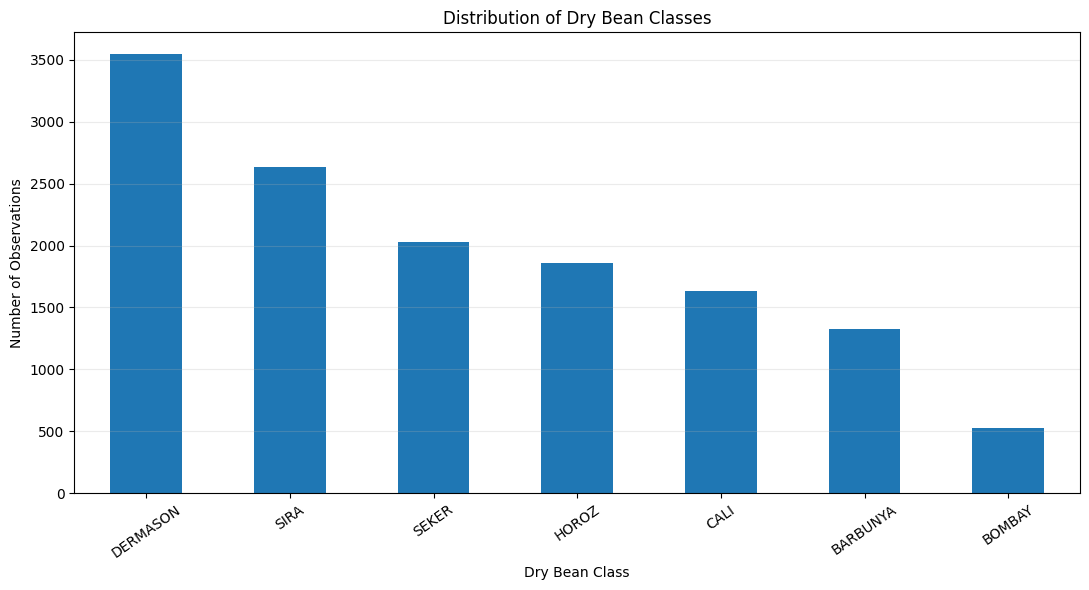


SECTION 5 BERHASIL DIJALANKAN
Total observations : 13,543
Total features     : 16
Total classes      : 7
Largest class      : DERMASON
Smallest class     : BOMBAY
Class imbalance ratio: 6.79

SAVED FILES
- class_distribution.csv
- descriptive_statistics.csv
- class_feature_means.csv
- class_distribution.png

EDA successfully completed.
Silakan lanjutkan ke SECTION 6.


In [5]:

# ============================================================
# SECTION 5: EXPLORATORY DATA ANALYSIS (EDA)
# CLASS DISTRIBUTION & DESCRIPTIVE STATISTICS
# ============================================================

# ------------------------------------------------------------
# A. PREPARATION & VALIDATION
# ------------------------------------------------------------

if 'df_clean' not in globals():
    raise NameError('df_clean belum tersedia. Jalankan Section 4.')

if TARGET not in df_clean.columns:
    raise ValueError('Kolom target tidak ditemukan.')

if not feature_cols:
    raise ValueError('Daftar fitur kosong.')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# B. DATASET VALIDATION
# ------------------------------------------------------------

if df_clean[feature_cols + [TARGET]].isna().any().any():

    raise ValueError(
        'Missing values ditemukan pada dataset bersih.'
    )


if len(df_clean) == 0:

    raise ValueError(
        'Dataset bersih tidak memiliki observasi.'
    )


# ------------------------------------------------------------
# C. CLASS DISTRIBUTION ANALYSIS
# ------------------------------------------------------------

class_counts = (

    df_clean[TARGET]

    .value_counts()

    .sort_index()

)


class_distribution = pd.DataFrame({

    'class': class_counts.index,

    'count': class_counts.values,

    'percentage': (

        class_counts.values /
        class_counts.sum() * 100

    ).round(2)

})


display(class_distribution)


# ------------------------------------------------------------
# D. CLASS DISTRIBUTION SUMMARY
# ------------------------------------------------------------

largest_class = class_counts.idxmax()

smallest_class = class_counts.idxmin()

class_imbalance_ratio = (

    class_counts.max() /
    class_counts.min()

)


print('\nCLASS DISTRIBUTION SUMMARY')

print('Total classes       :', len(class_counts))

print('Largest class       :', largest_class)

print('Largest class count :', int(class_counts.max()))

print('Smallest class      :', smallest_class)

print('Smallest class count:', int(class_counts.min()))

print(
    'Largest/Smallest ratio:',
    f'{class_imbalance_ratio:.2f}'
)


# ------------------------------------------------------------
# E. DESCRIPTIVE STATISTICS
# ------------------------------------------------------------

descriptive_statistics = (

    df_clean[feature_cols]

    .describe()

    .T

)


display(descriptive_statistics.round(4))


# ------------------------------------------------------------
# F. CLASS-BASED FEATURE ANALYSIS
# ------------------------------------------------------------

class_feature_means = (

    df_clean.groupby(TARGET)[feature_cols]

    .mean()

    .round(4)

)


print('\nAVERAGE FEATURE VALUES BY CLASS')

display(class_feature_means)


# ------------------------------------------------------------
# G. CLASS DISTRIBUTION VISUALIZATION
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(11, 6)
)


class_counts.sort_values(
    ascending=False
).plot(
    kind='bar',
    ax=ax
)


ax.set_title(
    'Distribution of Dry Bean Classes'
)

ax.set_xlabel(
    'Dry Bean Class'
)

ax.set_ylabel(
    'Number of Observations'
)

ax.tick_params(
    axis='x',
    rotation=35
)

ax.grid(
    axis='y',
    alpha=0.25
)


fig.tight_layout()


fig.savefig(
    OUTPUT_DIR / 'class_distribution.png',
    dpi=180,
    bbox_inches='tight'
)


plt.show()


# ------------------------------------------------------------
# H. SAVE EDA RESULTS
# ------------------------------------------------------------

class_distribution.to_csv(
    OUTPUT_DIR / 'class_distribution.csv',
    index=False
)


descriptive_statistics.to_csv(
    OUTPUT_DIR / 'descriptive_statistics.csv'
)


class_feature_means.to_csv(
    OUTPUT_DIR / 'class_feature_means.csv'
)


# ------------------------------------------------------------
# I. FINAL EXECUTION SUMMARY
# ------------------------------------------------------------

print('\n' + '=' * 65)

print('SECTION 5 BERHASIL DIJALANKAN')

print('=' * 65)

print(f'Total observations : {len(df_clean):,}')

print(f'Total features     : {len(feature_cols)}')

print(f'Total classes      : {len(class_counts)}')

print(f'Largest class      : {largest_class}')

print(f'Smallest class     : {smallest_class}')

print(
    f'Class imbalance ratio: {class_imbalance_ratio:.2f}'
)

print('\nSAVED FILES')

print('- class_distribution.csv')

print('- descriptive_statistics.csv')

print('- class_feature_means.csv')

print('- class_distribution.png')

print('\nEDA successfully completed.')

print('Silakan lanjutkan ke SECTION 6.')

print('=' * 65)


## 6. Exploratory Data Analysis (EDA)


PEARSON CORRELATION MATRIX


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
Area,1.0000,0.9669,0.9326,0.9520,0.2437,0.2686,0.9999,0.9850,0.0546,-0.1973,-0.3591,-0.2698,-0.8484,-0.6412,-0.2738,-0.3580
Perimeter,0.9669,1.0000,0.9776,0.9143,0.3861,0.3911,0.9679,0.9915,-0.0206,-0.3047,-0.5483,-0.4074,-0.8658,-0.7686,-0.4089,-0.4312
MajorAxisLength,0.9326,0.9776,1.0000,0.8284,0.5501,0.5410,0.9334,0.9623,-0.0773,-0.2849,-0.5957,-0.5679,-0.7758,-0.8594,-0.5676,-0.4845
MinorAxisLength,0.9520,0.9143,0.8284,1.0000,-0.0054,0.0224,0.9518,0.9492,0.1459,-0.1568,-0.2141,-0.0186,-0.9472,-0.4753,-0.0227,-0.2664
AspectRation,0.2437,0.3861,0.5501,-0.0054,1.0000,0.9242,0.2453,0.3052,-0.3712,-0.2691,-0.7650,-0.9876,0.0209,-0.8373,-0.9785,-0.4516
Eccentricity,0.2686,0.3911,0.5410,0.0224,0.9242,1.0000,0.2703,0.3194,-0.3197,-0.2983,-0.7201,-0.9703,0.0173,-0.8592,-0.9811,-0.4506
ConvexArea,0.9999,0.9679,0.9334,0.9518,0.2453,0.2703,1.0000,0.9853,0.0529,-0.2069,-0.3636,-0.2717,-0.8484,-0.6428,-0.2756,-0.3643
EquivDiameter,0.9850,0.9915,0.9623,0.9492,0.3052,0.3194,0.9853,1.0000,0.0288,-0.2323,-0.4372,-0.3290,-0.8934,-0.7147,-0.3316,-0.3947
Extent,0.0546,-0.0206,-0.0773,0.1459,-0.3712,-0.3197,0.0529,0.0288,1.0000,0.1923,0.3445,0.3549,-0.1415,0.2376,0.3482,0.1486
Solidity,-0.1973,-0.3047,-0.2849,-0.1568,-0.2691,-0.2983,-0.2069,-0.2323,0.1923,1.0000,0.6097,0.3048,0.1543,0.3443,0.3086,0.7002


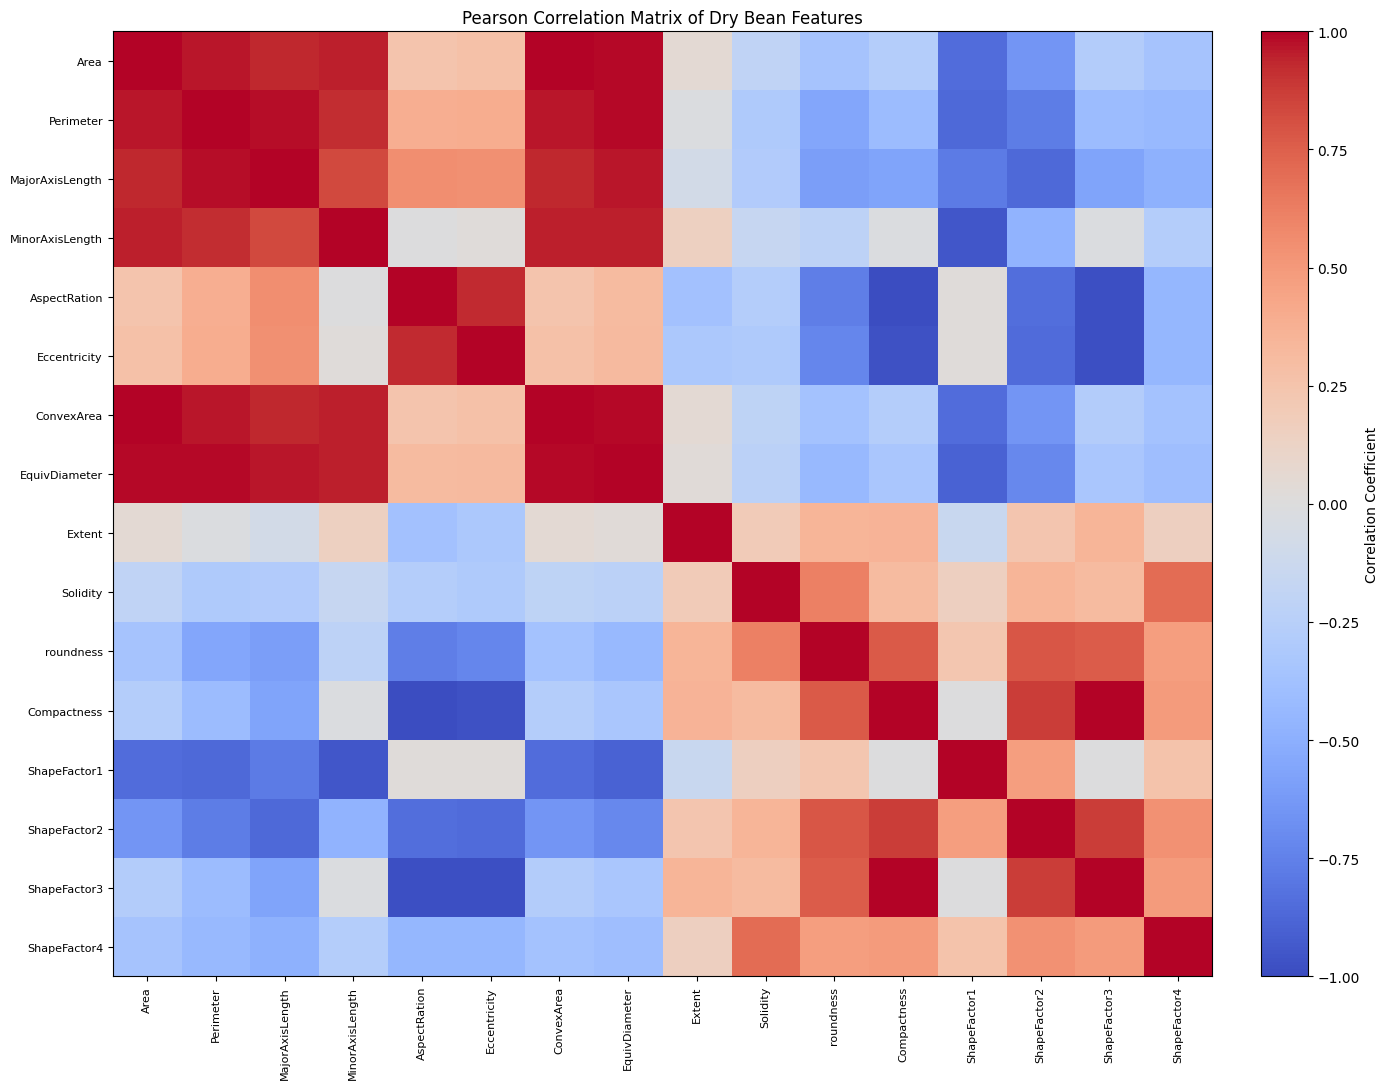


HIGHLY CORRELATED FEATURE PAIRS
Correlation threshold: 0.9


,feature_1,feature_2,correlation,absolute_correlation,relationship
0,Area,ConvexArea,0.9999,0.9999,Positive
1,Compactness,ShapeFactor3,0.9987,0.9987,Positive
2,Perimeter,EquivDiameter,0.9915,0.9915,Positive
3,AspectRation,Compactness,-0.9876,0.9876,Negative
4,ConvexArea,EquivDiameter,0.9853,0.9853,Positive
5,Area,EquivDiameter,0.9850,0.9850,Positive
6,Eccentricity,ShapeFactor3,-0.9811,0.9811,Negative
7,AspectRation,ShapeFactor3,-0.9785,0.9785,Negative
8,Perimeter,MajorAxisLength,0.9776,0.9776,Positive
9,Eccentricity,Compactness,-0.9703,0.9703,Negative



FEATURE DISTRIBUTION STATISTICS


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
Area,13543.0,53048.4604,29392.4383,20420.0000,36282.5000,44580.0000,61382.0000,254616.0000,2.9471,10.7415
Perimeter,13543.0,854.9934,214.7227,524.7360,703.2300,793.8960,977.1465,1985.3700,1.6280,3.5764
MajorAxisLength,13543.0,319.8956,85.8093,183.6012,253.0868,296.4046,376.3125,738.8602,1.3658,2.5437
MinorAxisLength,13543.0,202.3653,45.0516,122.5127,175.8864,192.4911,217.2454,460.1985,2.2320,6.6099
AspectRation,13543.0,1.5811,0.2452,1.0249,1.4307,1.5499,1.7039,2.4303,0.5890,0.1548
Eccentricity,13543.0,0.7503,0.0919,0.2190,0.7151,0.7640,0.8097,0.9114,-1.0649,1.3958
ConvexArea,13543.0,53767.9867,29844.2485,20684.0000,36673.0000,45122.0000,62360.0000,263261.0000,2.9361,10.6848
EquivDiameter,13543.0,253.0341,59.3077,161.2438,214.9333,238.2457,279.5604,569.3744,1.9473,5.1647
Extent,13543.0,0.7498,0.0489,0.5553,0.7187,0.7599,0.7868,0.8662,-0.8957,0.6523
Solidity,13543.0,0.9872,0.0047,0.9192,0.9857,0.9883,0.9900,0.9947,-2.5469,12.8323


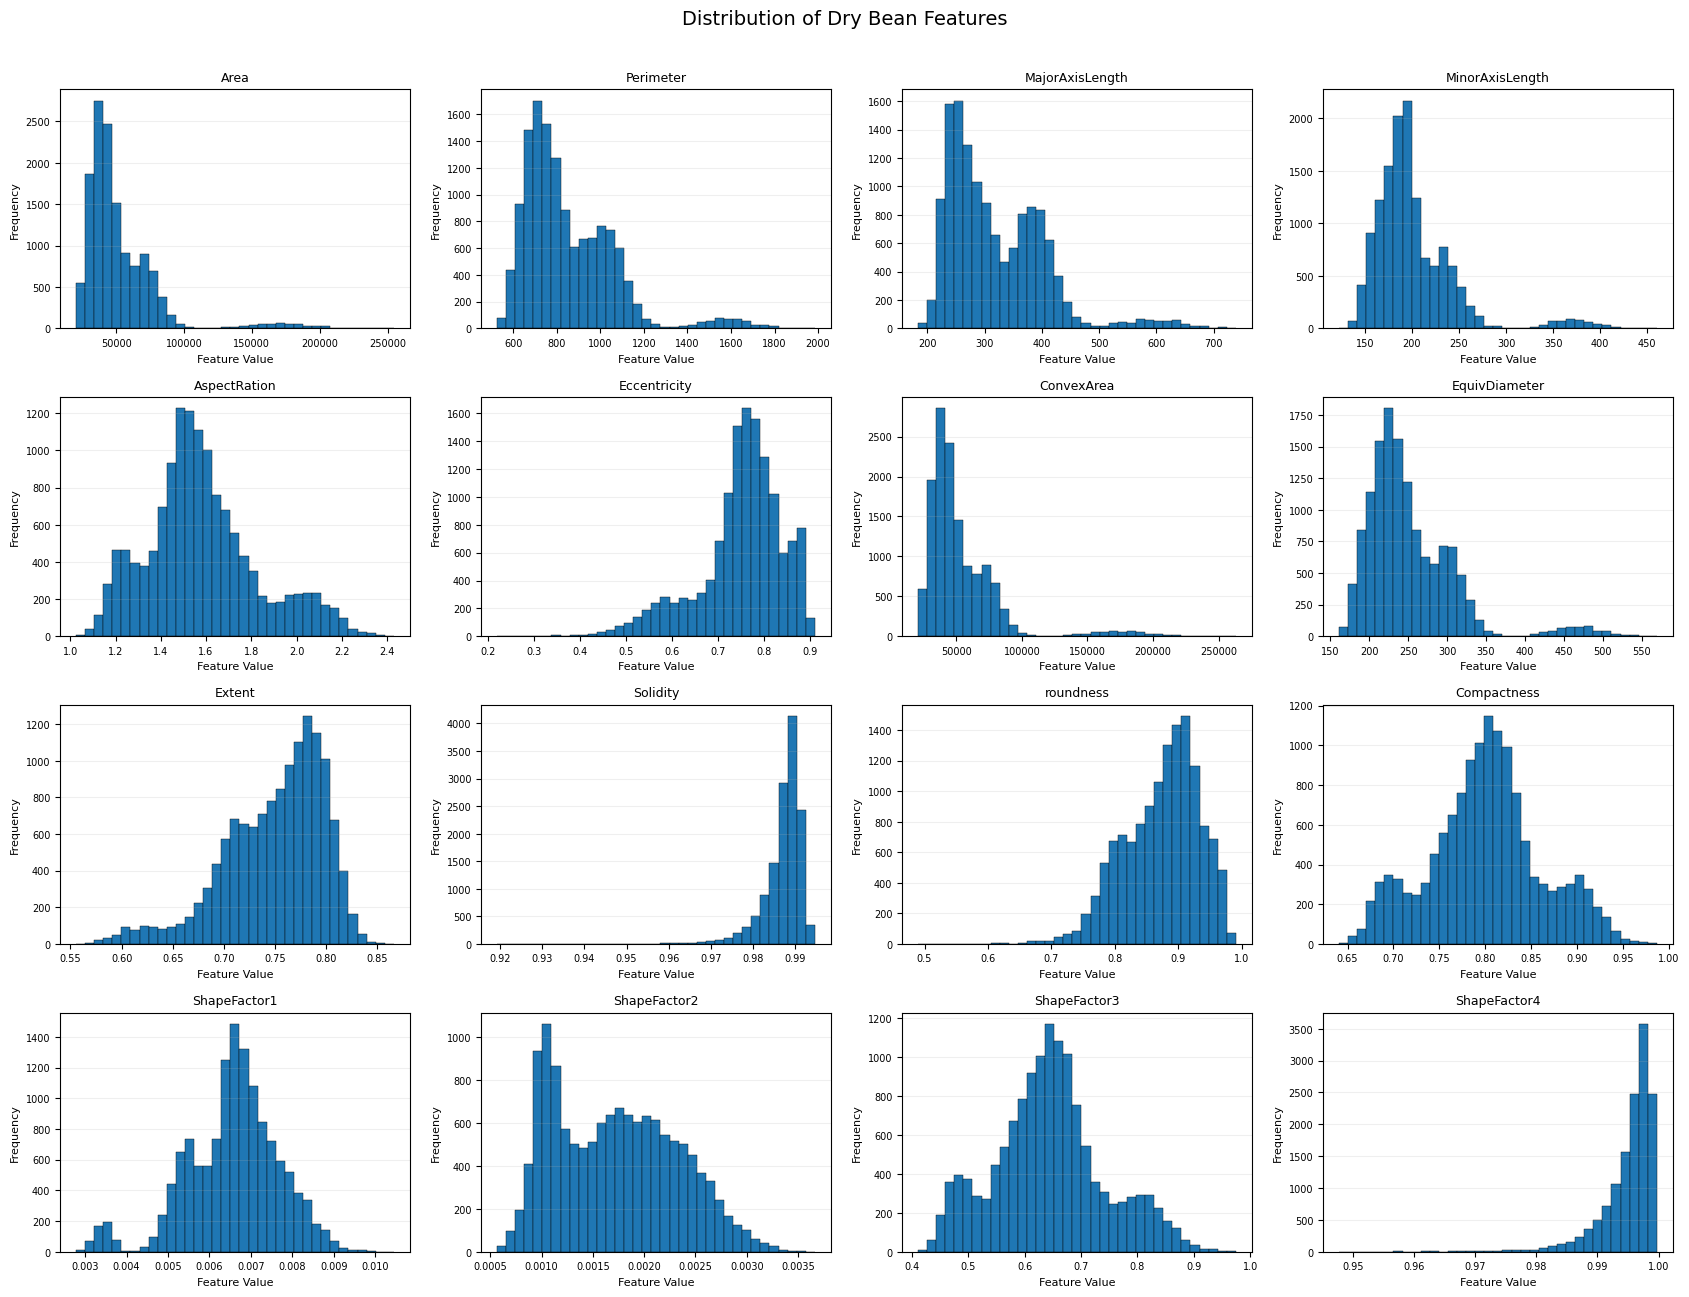


SECTION 6 BERHASIL DIJALANKAN
Features analyzed       : 16
Observations analyzed   : 13,543
Correlation threshold   : 0.9
Highly correlated pairs : 21

SAVED FILES
- correlation_matrix.csv
- high_correlation_pairs.csv
- feature_distribution_summary.csv
- correlation_heatmap.png
- feature_distributions.png

Correlation and feature distribution analysis completed.
Tidak ada fitur yang dihapus berdasarkan korelasi.
Silakan lanjutkan ke SECTION 7.


In [6]:

# ============================================================
# SECTION 6: CORRELATION ANALYSIS & FEATURE DISTRIBUTION
# ============================================================

# ------------------------------------------------------------
# A. PREPARATION & VALIDATION
# ------------------------------------------------------------

if 'df_clean' not in globals():
    raise NameError('df_clean belum tersedia. Jalankan Section 4.')

if 'feature_cols' not in globals():
    raise NameError('feature_cols belum tersedia.')

if len(feature_cols) == 0:
    raise ValueError('Tidak ada fitur untuk dianalisis.')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# Memastikan seluruh fitur bertipe numerik.

non_numeric_features = [

    column

    for column in feature_cols

    if not pd.api.types.is_numeric_dtype(df_clean[column])

]


if non_numeric_features:

    raise TypeError(
        f'Fitur non-numerik ditemukan: {non_numeric_features}'
    )


# Memastikan tidak ada missing values.

if df_clean[feature_cols].isna().any().any():

    raise ValueError(
        'Missing values ditemukan pada fitur.'
    )


# Memastikan nilai fitur bersifat finite.

if not np.isfinite(
    df_clean[feature_cols].to_numpy(dtype=float)
).all():

    raise ValueError(
        'Nilai infinite atau tidak valid ditemukan.'
    )


# ------------------------------------------------------------
# B. PEARSON CORRELATION ANALYSIS
# ------------------------------------------------------------

corr = df_clean[feature_cols].corr(
    method='pearson'
)


print('\nPEARSON CORRELATION MATRIX')

display(corr.round(4))


# ------------------------------------------------------------
# C. CORRELATION HEATMAP
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(14, 11)
)


im = ax.imshow(
    corr,
    aspect='auto',
    interpolation='nearest',
    vmin=-1,
    vmax=1,
    cmap='coolwarm'
)


ax.set_xticks(
    range(len(feature_cols))
)

ax.set_yticks(
    range(len(feature_cols))
)


ax.set_xticklabels(
    feature_cols,
    rotation=90,
    fontsize=8
)

ax.set_yticklabels(
    feature_cols,
    fontsize=8
)


ax.set_title(
    'Pearson Correlation Matrix of Dry Bean Features'
)


fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04,
    label='Correlation Coefficient'
)


fig.tight_layout()


fig.savefig(
    OUTPUT_DIR / 'correlation_heatmap.png',
    dpi=180,
    bbox_inches='tight'
)


plt.show()


# ------------------------------------------------------------
# D. IDENTIFICATION OF HIGHLY CORRELATED FEATURES
# ------------------------------------------------------------

CORRELATION_THRESHOLD = 0.90


# Membuat matriks segitiga atas agar setiap pasangan
# fitur hanya dihitung satu kali.

upper_triangle = np.triu(
    np.ones(corr.shape, dtype=bool),
    k=1
)


upper_corr = corr.where(
    upper_triangle
)


high_corr_pairs = (

    upper_corr

    .stack()

    .rename('correlation')

    .reset_index()

)


high_corr_pairs.columns = [

    'feature_1',

    'feature_2',

    'correlation'

]


high_corr_pairs['absolute_correlation'] = (

    high_corr_pairs['correlation'].abs()

)


high_corr_pairs['relationship'] = np.where(

    high_corr_pairs['correlation'] > 0,

    'Positive',

    'Negative'

)


high_corr_pairs = (

    high_corr_pairs.loc[

        high_corr_pairs['absolute_correlation']
        >= CORRELATION_THRESHOLD

    ]

    .sort_values(
        'absolute_correlation',
        ascending=False
    )

    .reset_index(drop=True)

)


print('\nHIGHLY CORRELATED FEATURE PAIRS')

print(
    'Correlation threshold:',
    CORRELATION_THRESHOLD
)

display(high_corr_pairs.round(4))


# ------------------------------------------------------------
# E. FEATURE DISTRIBUTION SUMMARY
# ------------------------------------------------------------

feature_distribution_summary = (

    df_clean[feature_cols]

    .describe()

    .T

)


feature_distribution_summary['skewness'] = (

    df_clean[feature_cols]

    .skew()

)


feature_distribution_summary['kurtosis'] = (

    df_clean[feature_cols]

    .kurt()

)


print('\nFEATURE DISTRIBUTION STATISTICS')

display(
    feature_distribution_summary.round(4)
)


# ------------------------------------------------------------
# F. FEATURE DISTRIBUTION HISTOGRAMS
# ------------------------------------------------------------

n_cols = 4

n_rows = int(
    np.ceil(len(feature_cols) / n_cols)
)


fig, axes = plt.subplots(

    n_rows,

    n_cols,

    figsize=(17, n_rows * 3.2)

)


axes = np.asarray(
    axes
).reshape(-1)


for index, feature in enumerate(feature_cols):

    axes[index].hist(

        df_clean[feature],

        bins=35,

        edgecolor='black',

        linewidth=0.3

    )


    axes[index].set_title(
        feature,
        fontsize=9
    )


    axes[index].set_xlabel(
        'Feature Value',
        fontsize=8
    )


    axes[index].set_ylabel(
        'Frequency',
        fontsize=8
    )


    axes[index].tick_params(
        axis='both',
        labelsize=7
    )


    axes[index].grid(
        axis='y',
        alpha=0.2
    )


# Menonaktifkan subplot yang tidak digunakan.

for index in range(
    len(feature_cols),
    len(axes)
):

    axes[index].axis('off')


fig.suptitle(
    'Distribution of Dry Bean Features',
    fontsize=14,
    y=1.01
)


fig.tight_layout()


fig.savefig(
    OUTPUT_DIR / 'feature_distributions.png',
    dpi=180,
    bbox_inches='tight'
)


plt.show()


# ------------------------------------------------------------
# G. SAVE CORRELATION AND DISTRIBUTION RESULTS
# ------------------------------------------------------------

corr.to_csv(
    OUTPUT_DIR / 'correlation_matrix.csv'
)


high_corr_pairs.to_csv(
    OUTPUT_DIR / 'high_correlation_pairs.csv',
    index=False
)


feature_distribution_summary.to_csv(
    OUTPUT_DIR / 'feature_distribution_summary.csv'
)


# ------------------------------------------------------------
# H. FINAL EXECUTION SUMMARY
# ------------------------------------------------------------

print('\n' + '=' * 65)

print('SECTION 6 BERHASIL DIJALANKAN')

print('=' * 65)

print(f'Features analyzed       : {len(feature_cols)}')

print(f'Observations analyzed   : {len(df_clean):,}')

print(f'Correlation threshold   : {CORRELATION_THRESHOLD}')

print(f'Highly correlated pairs : {len(high_corr_pairs)}')


print('\nSAVED FILES')

print('- correlation_matrix.csv')

print('- high_correlation_pairs.csv')

print('- feature_distribution_summary.csv')

print('- correlation_heatmap.png')

print('- feature_distributions.png')


print('\nCorrelation and feature distribution analysis completed.')

print('Tidak ada fitur yang dihapus berdasarkan korelasi.')

print('Silakan lanjutkan ke SECTION 7.')

print('=' * 65)


## 7. Pembagian training dan testing

Pembagian menggunakan stratified sampling 80:20. Stratifikasi menjaga proporsi relatif tujuh kelas pada kedua subset. Kedua algoritma menerima data yang sama agar perbandingan adil.


In [7]:

# ============================================================
# SECTION 7: REPEATED DATA SPLITTING
# FIVE EXPERIMENTAL RUNS (TRAINING & TESTING)
# ============================================================

# ------------------------------------------------------------
# A. PREPARATION & VALIDATION
# ------------------------------------------------------------

if 'df_clean' not in globals():
    raise NameError('df_clean belum tersedia. Jalankan Section 4.')

if 'feature_cols' not in globals():
    raise NameError('feature_cols belum tersedia.')

if 'TARGET' not in globals():
    raise NameError('TARGET belum tersedia.')

if 'TEST_SIZE' not in globals():
    raise NameError('TEST_SIZE belum tersedia. Jalankan Section 2.')

if 'RANDOM_STATE' not in globals():
    raise NameError('RANDOM_STATE belum tersedia. Jalankan Section 2.')


# ------------------------------------------------------------
# B. EXPERIMENT SEED CONFIGURATION
# ------------------------------------------------------------

# Menggunakan konfigurasi seed dari Section 2 jika tersedia.

if 'EXPERIMENT_SEEDS' in globals():

    RUN_SEEDS = [
        int(seed) for seed in EXPERIMENT_SEEDS
    ]

elif 'RUN_SEEDS' in globals():

    RUN_SEEDS = [
        int(seed) for seed in RUN_SEEDS
    ]

else:

    repetition_count = int(
        globals().get('REPETITIONS', 5)
    )

    RUN_SEEDS = list(
        range(
            int(RANDOM_STATE),
            int(RANDOM_STATE) + repetition_count
        )
    )


# Memastikan eksperimen terdiri dari lima run.

if len(RUN_SEEDS) != 5:

    raise ValueError(
        f'Dibutuhkan tepat 5 seed, ditemukan {len(RUN_SEEDS)}.'
    )


if len(set(RUN_SEEDS)) != 5:

    raise ValueError(
        'Setiap eksperimen harus memiliki seed yang berbeda.'
    )


# Memastikan daftar seed dapat digunakan kembali oleh Section 9.

EXPERIMENT_SEEDS = RUN_SEEDS.copy()


# ------------------------------------------------------------
# C. PREPARATION OF FEATURES AND TARGET
# ------------------------------------------------------------

X = df_clean[feature_cols].copy()

y = df_clean[TARGET].copy()


if X.isna().any().any() or y.isna().any():

    raise ValueError(
        'Missing values ditemukan pada fitur atau target.'
    )


if y.value_counts().min() < 2:

    raise ValueError(
        'Jumlah observasi suatu kelas terlalu sedikit untuk stratified splitting.'
    )


# ------------------------------------------------------------
# D. INITIALIZE EXPERIMENT STORAGE
# ------------------------------------------------------------

run_data_by_seed = {}

split_summary_rows = []

split_class_rows = []


# ------------------------------------------------------------
# E. REPEATED STRATIFIED DATA SPLITTING
# ------------------------------------------------------------

for seed in RUN_SEEDS:

    print(f'\nProcessing Experiment Seed: {seed}')

    # Membagi indeks menjadi training dan testing.

    train_idx, test_idx = train_test_split(

        np.arange(len(df_clean)),

        test_size=TEST_SIZE,

        random_state=seed,

        stratify=y

    )


    # Mengambil fitur training.

    X_train_run = X.iloc[train_idx].copy()


    # Mengambil fitur testing.

    X_test_run = X.iloc[test_idx].copy()


    # Mengambil target training.

    y_train_run = y.iloc[train_idx].copy()


    # Mengambil target testing.

    y_test_run = y.iloc[test_idx].copy()


    # Memastikan indeks tidak mengalami overlap.

    assert set(train_idx).isdisjoint(
        set(test_idx)
    )


    # Memastikan semua kelas tersedia pada kedua subset.

    assert set(y_train_run.unique()) == set(y.unique())

    assert set(y_test_run.unique()) == set(y.unique())


    # Menyimpan seluruh data eksperimen untuk Section 9.

    run_data_by_seed[seed] = {

        'X_train': X_train_run,

        'X_test': X_test_run,

        'y_train': y_train_run,

        'y_test': y_test_run,

        'train_idx': train_idx,

        'test_idx': test_idx

    }


    # Menyimpan bukti training dan testing.

    train_evidence_run = df_clean.iloc[
        train_idx
    ].copy()


    test_evidence_run = df_clean.iloc[
        test_idx
    ].copy()


    train_evidence_run.to_csv(

        EVIDENCE_DIR / f'training_set_seed_{seed}.csv',

        index=False

    )


    test_evidence_run.to_csv(

        EVIDENCE_DIR / f'testing_set_seed_{seed}.csv',

        index=False

    )


    # Mencatat ringkasan jumlah data.

    split_summary_rows.extend([

        {

            'seed': seed,

            'subset': 'Training',

            'observations': len(train_idx),

            'percentage': len(train_idx) / len(df_clean) * 100

        },

        {

            'seed': seed,

            'subset': 'Testing',

            'observations': len(test_idx),

            'percentage': len(test_idx) / len(df_clean) * 100

        }

    ])


    # Mencatat distribusi kelas setiap run.

    train_counts = y_train_run.value_counts().sort_index()

    test_counts = y_test_run.value_counts().sort_index()


    for class_name in sorted(y.unique()):

        split_class_rows.append({

            'seed': seed,

            'class': class_name,

            'training_count': int(
                train_counts[class_name]
            ),

            'testing_count': int(
                test_counts[class_name]
            )

        })


    print(
        f'Training: {len(X_train_run):,} | '
        f'Testing: {len(X_test_run):,}'
    )


# ------------------------------------------------------------
# F. CREATE EXPERIMENT SUMMARY TABLES
# ------------------------------------------------------------

split_summary_by_seed = pd.DataFrame(
    split_summary_rows
)


split_class_distribution_by_seed = pd.DataFrame(
    split_class_rows
)


print('\nREPEATED DATA SPLIT SUMMARY')

display(split_summary_by_seed)


print('\nCLASS DISTRIBUTION FOR FIVE RUNS')

display(split_class_distribution_by_seed)


# ------------------------------------------------------------
# G. BACKWARD COMPATIBILITY FOR EXISTING SECTIONS
# ------------------------------------------------------------

# Menggunakan seed pertama (42) sebagai referensi
# untuk variabel single-run yang masih digunakan
# oleh beberapa bagian notebook sebelumnya.

PRIMARY_SEED = RUN_SEEDS[0]

primary_run = run_data_by_seed[PRIMARY_SEED]


X_train = primary_run['X_train']

X_test = primary_run['X_test']

y_train = primary_run['y_train']

y_test = primary_run['y_test']

train_idx = primary_run['train_idx']

test_idx = primary_run['test_idx']


train_evidence = df_clean.iloc[
    train_idx
].copy()


test_evidence = df_clean.iloc[
    test_idx
].copy()


# Ringkasan kompatibilitas untuk seed pertama.

split_summary = (

    split_summary_by_seed.loc[

        split_summary_by_seed['seed'] == PRIMARY_SEED,

        ['subset', 'observations', 'percentage']

    ]

    .reset_index(drop=True)

)


split_class = (

    split_class_distribution_by_seed.loc[

        split_class_distribution_by_seed['seed'] == PRIMARY_SEED

    ]

    .set_index('class')[

        ['training_count', 'testing_count']

    ]

)


# ------------------------------------------------------------
# H. SAVE EXPERIMENT EVIDENCE
# ------------------------------------------------------------

split_summary_by_seed.to_csv(

    EVIDENCE_DIR / 'split_summary_all_runs.csv',

    index=False

)


split_class_distribution_by_seed.to_csv(

    EVIDENCE_DIR / 'split_class_distribution_all_runs.csv',

    index=False

)


# Menyimpan daftar seed eksperimen.

with open(

    EVIDENCE_DIR / 'experiment_seeds.json',

    'w',

    encoding='utf-8'

) as file:

    json.dump(

        RUN_SEEDS,

        file,

        indent=4

    )


# ------------------------------------------------------------
# I. FINAL EXECUTION SUMMARY
# ------------------------------------------------------------

print('\n' + '=' * 65)

print('SECTION 7 BERHASIL DIJALANKAN')

print('=' * 65)

print(f'Total observations : {len(df_clean):,}')

print(f'Total features     : {len(feature_cols)}')

print(f'Total classes      : {y.nunique()}')

print(f'Number of runs     : {len(RUN_SEEDS)}')

print(f'Test size          : {TEST_SIZE:.0%}')

print(f'Experiment seeds   : {RUN_SEEDS}')


print('\nRUN CONFIGURATION')

for seed in RUN_SEEDS:

    data = run_data_by_seed[seed]

    print(

        f'Seed {seed}: '

        f'Train={len(data["X_train"]):,} | '

        f'Test={len(data["X_test"]):,} | '

        f'Validation=PASS'

    )


print('\nSAVED FILES')

print('- split_summary_all_runs.csv')

print('- split_class_distribution_all_runs.csv')

print('- experiment_seeds.json')

print('- training_set_seed_42.csv through seed_46.csv')

print('- testing_set_seed_42.csv through seed_46.csv')


print('\nAll five data splitting experiments completed.')

print('run_data_by_seed siap digunakan oleh SECTION 9.')

print('=' * 65)



Processing Experiment Seed: 42
Training: 10,834 | Testing: 2,709

Processing Experiment Seed: 43
Training: 10,834 | Testing: 2,709

Processing Experiment Seed: 44
Training: 10,834 | Testing: 2,709

Processing Experiment Seed: 45
Training: 10,834 | Testing: 2,709

Processing Experiment Seed: 46
Training: 10,834 | Testing: 2,709

REPEATED DATA SPLIT SUMMARY


,seed,subset,observations,percentage
0,42,Training,10834,79.997046
1,42,Testing,2709,20.002954
2,43,Training,10834,79.997046
3,43,Testing,2709,20.002954
4,44,Training,10834,79.997046
5,44,Testing,2709,20.002954
6,45,Training,10834,79.997046
7,45,Testing,2709,20.002954
8,46,Training,10834,79.997046
9,46,Testing,2709,20.002954



CLASS DISTRIBUTION FOR FIVE RUNS


,seed,class,training_count,testing_count
0,42,BARBUNYA,1057,265
1,42,BOMBAY,418,104
2,42,CALI,1304,326
3,42,DERMASON,2837,709
4,42,HOROZ,1488,372
5,42,SEKER,1621,406
6,42,SIRA,2109,527
7,43,BARBUNYA,1057,265
8,43,BOMBAY,418,104
9,43,CALI,1304,326



SECTION 7 BERHASIL DIJALANKAN
Total observations : 13,543
Total features     : 16
Total classes      : 7
Number of runs     : 5
Test size          : 20%
Experiment seeds   : [42, 43, 44, 45, 46]

RUN CONFIGURATION
Seed 42: Train=10,834 | Test=2,709 | Validation=PASS
Seed 43: Train=10,834 | Test=2,709 | Validation=PASS
Seed 44: Train=10,834 | Test=2,709 | Validation=PASS
Seed 45: Train=10,834 | Test=2,709 | Validation=PASS
Seed 46: Train=10,834 | Test=2,709 | Validation=PASS

SAVED FILES
- split_summary_all_runs.csv
- split_class_distribution_all_runs.csv
- experiment_seeds.json
- training_set_seed_42.csv through seed_46.csv
- testing_set_seed_42.csv through seed_46.csv

All five data splitting experiments completed.
run_data_by_seed siap digunakan oleh SECTION 9.


## 8. Baseline training

In [8]:

# ============================================================
# SECTION 8: REPEATED BASELINE MODEL TRAINING & EVALUATION
# DECISION TREE VS RANDOM FOREST
# ============================================================

# ------------------------------------------------------------
# A. PREPARATION & VALIDATION
# ------------------------------------------------------------

if 'run_data_by_seed' not in globals():

    raise NameError(
        'run_data_by_seed belum tersedia. Jalankan Section 7.'
    )


if 'RUN_SEEDS' not in globals():

    raise NameError(
        'RUN_SEEDS belum tersedia. Jalankan Section 7.'
    )


if 'RANDOM_STATE' not in globals():

    raise NameError(
        'RANDOM_STATE belum tersedia. Jalankan Section 2.'
    )


# Memastikan seluruh eksperimen memiliki data.

for seed in RUN_SEEDS:

    if seed not in run_data_by_seed:

        raise ValueError(
            f'Data eksperimen seed {seed} tidak ditemukan.'
        )


OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# B. METRIC CALCULATION FUNCTION
# ------------------------------------------------------------

def calculate_metrics(y_true, y_pred):

    return {

        'accuracy': accuracy_score(
            y_true, y_pred
        ),

        'balanced_accuracy': balanced_accuracy_score(
            y_true, y_pred
        ),

        'precision_macro': precision_score(
            y_true,
            y_pred,
            average='macro',
            zero_division=0
        ),

        'recall_macro': recall_score(
            y_true,
            y_pred,
            average='macro',
            zero_division=0
        ),

        'f1_macro': f1_score(
            y_true,
            y_pred,
            average='macro',
            zero_division=0
        ),

        'f1_weighted': f1_score(
            y_true,
            y_pred,
            average='weighted',
            zero_division=0
        ),

        'matthews_corrcoef': matthews_corrcoef(
            y_true, y_pred
        ),

        'cohen_kappa': cohen_kappa_score(
            y_true, y_pred
        )

    }


# ------------------------------------------------------------
# C. INITIALIZE BASELINE EXPERIMENT STORAGE
# ------------------------------------------------------------

baseline_models_by_run = {}

baseline_fitted_by_run = {}

baseline_predictions_by_run = {}

baseline_metrics_by_run = {}

baseline_rows_all = []


# ------------------------------------------------------------
# D. REPEATED BASELINE MODEL TRAINING
# ------------------------------------------------------------

for seed in RUN_SEEDS:

    print('\n' + '=' * 60)

    print(f'BASELINE EXPERIMENT - SEED {seed}')

    print('=' * 60)


    # Mengambil data training dan testing
    # berdasarkan seed yang sedang diproses.

    run_data = run_data_by_seed[seed]

    X_train_run = run_data['X_train']

    X_test_run = run_data['X_test']

    y_train_run = run_data['y_train']

    y_test_run = run_data['y_test']


    # Membuat model baseline dengan random state
    # yang sama dengan pembagian data eksperimen.

    models = {

        'Decision Tree': DecisionTreeClassifier(
            random_state=seed
        ),

        'Random Forest': RandomForestClassifier(
            random_state=seed,
            n_jobs=1
        )

    }


    baseline_models_by_run[seed] = models

    baseline_fitted_by_run[seed] = {}

    baseline_predictions_by_run[seed] = {}

    baseline_rows = []


    # --------------------------------------------------------
    # E. TRAINING AND TESTING EACH BASELINE MODEL
    # --------------------------------------------------------

    for name, model in models.items():

        print(f'\nTraining {name}...')


        # Mencatat waktu awal training.

        t0 = time.perf_counter()


        # Melatih model menggunakan data training.

        model.fit(
            X_train_run,
            y_train_run
        )


        # Menghitung durasi training.

        elapsed = time.perf_counter() - t0


        # Melakukan prediksi pada data testing.

        test_pred = model.predict(
            X_test_run
        )


        # Melakukan prediksi pada data training
        # untuk mengukur indikasi overfitting.

        train_pred = model.predict(
            X_train_run
        )


        # Menghitung akurasi training.

        train_accuracy = accuracy_score(
            y_train_run,
            train_pred
        )


        # Menghitung seluruh metrik testing.

        metrics = calculate_metrics(
            y_test_run,
            test_pred
        )


        # Menghitung selisih akurasi training dan testing.

        generalization_gap = (

            train_accuracy - metrics['accuracy']

        )


        # Menyimpan model yang sudah dilatih.

        baseline_fitted_by_run[seed][name] = model


        # Menyimpan hasil prediksi testing.

        baseline_predictions_by_run[seed][name] = test_pred


        # Membuat ringkasan hasil evaluasi.

        row = {

            'seed': seed,

            'model': name,

            'fit_seconds': elapsed,

            'train_accuracy': train_accuracy,

            'generalization_gap': generalization_gap,

            **metrics

        }


        baseline_rows.append(row)

        baseline_rows_all.append(row)


        # Menampilkan hasil evaluasi.

        print(f'Model              : {name}')

        print(f'Training rows      : {len(X_train_run):,}')

        print(f'Testing rows       : {len(X_test_run):,}')

        print(f'Training Accuracy  : {train_accuracy:.4f}')

        print(f'Testing Accuracy   : {metrics["accuracy"]:.4f}')

        print(f'Macro F1            : {metrics["f1_macro"]:.4f}')

        print(f'Generalization Gap : {generalization_gap:.4f}')

        print(f'Fit Time           : {elapsed:.2f} seconds')


        # Menyimpan bukti prediksi setiap model.

        prediction_evidence = pd.DataFrame({

            'actual_class': y_test_run.values,

            'predicted_class': test_pred,

            'correct': (
                y_test_run.values == test_pred
            )

        })


        prediction_evidence.to_csv(

            EVIDENCE_DIR /
            f'baseline_predictions_{name.lower().replace(" ", "_")}_seed_{seed}.csv',

            index=False

        )


    # --------------------------------------------------------
    # F. SAVE INDIVIDUAL RUN METRICS
    # --------------------------------------------------------

    baseline_metrics_by_run[seed] = (

        pd.DataFrame(baseline_rows)

        .set_index('model')

    )


    baseline_metrics_by_run[seed].to_csv(

        OUTPUT_DIR / f'baseline_metrics_seed_{seed}.csv'

    )


# ------------------------------------------------------------
# G. COMBINE ALL BASELINE EXPERIMENT RESULTS
# ------------------------------------------------------------

baseline_results_df = pd.DataFrame(
    baseline_rows_all
)


print('\nALL BASELINE EXPERIMENT RESULTS')

display(
    baseline_results_df.round(4)
)


baseline_results_df.to_csv(

    OUTPUT_DIR / 'baseline_metrics_all_runs.csv',

    index=False

)


# ------------------------------------------------------------
# H. CALCULATE FIVE-RUN PERFORMANCE SUMMARY
# ------------------------------------------------------------

metric_columns = [

    'accuracy',

    'balanced_accuracy',

    'precision_macro',

    'recall_macro',

    'f1_macro',

    'f1_weighted',

    'matthews_corrcoef',

    'cohen_kappa',

    'train_accuracy',

    'generalization_gap',

    'fit_seconds'

]


baseline_metrics_summary = (

    baseline_results_df

    .groupby('model')[metric_columns]

    .agg(['mean', 'std'])

)


# Merapikan nama kolom agar mudah dibaca.

baseline_metrics_summary.columns = [

    f'{metric}_{statistic}'

    for metric, statistic
    in baseline_metrics_summary.columns

]


baseline_metrics_summary = (
    baseline_metrics_summary.reset_index()
)


print('\nFIVE-RUN BASELINE PERFORMANCE SUMMARY')

display(
    baseline_metrics_summary.round(4)
)


baseline_metrics_summary.to_csv(

    OUTPUT_DIR / 'baseline_metrics_summary.csv',

    index=False

)


# ------------------------------------------------------------
# I. BACKWARD COMPATIBILITY
# ------------------------------------------------------------

# Mempertahankan variabel single-run dari eksperimen pertama
# agar bagian notebook lama tetap memiliki referensi seed 42.

baseline_metrics = baseline_metrics_by_run[
    RUN_SEEDS[0]
].copy()


baseline_fitted = baseline_fitted_by_run[
    RUN_SEEDS[0]
]


baseline_predictions = baseline_predictions_by_run[
    RUN_SEEDS[0]
]


baseline_models = baseline_models_by_run[
    RUN_SEEDS[0]
]


# ------------------------------------------------------------
# J. BASELINE PERFORMANCE COMPARISON
# ------------------------------------------------------------

print('\nBASELINE MODEL COMPARISON')


for model_name in ['Decision Tree', 'Random Forest']:

    model_summary = baseline_metrics_summary.loc[

        baseline_metrics_summary['model'] == model_name

    ].iloc[0]


    print('\n' + model_name)

    print(

        f'Mean Accuracy : '
        f'{model_summary["accuracy_mean"]:.4f}'

    )

    print(

        f'Std Accuracy  : '
        f'{model_summary["accuracy_std"]:.4f}'

    )

    print(

        f'Mean Macro F1 : '
        f'{model_summary["f1_macro_mean"]:.4f}'

    )

    print(

        f'Std Macro F1  : '
        f'{model_summary["f1_macro_std"]:.4f}'

    )


# ------------------------------------------------------------
# K. FINAL EXECUTION SUMMARY
# ------------------------------------------------------------

print('\n' + '=' * 65)

print('SECTION 8 BERHASIL DIJALANKAN')

print('=' * 65)

print(f'Number of experiments : {len(RUN_SEEDS)}')

print(f'Total models trained  : {len(baseline_results_df)}')

print(f'Model algorithms      : 2')

print(f'Training configuration: 80%')

print(f'Testing configuration : 20%')


print('\nEXPERIMENT SEEDS')

print(RUN_SEEDS)


print('\nBASELINE MODELS')

print('- Decision Tree')

print('- Random Forest')


print('\nSAVED FILES')

print('- baseline_metrics_all_runs.csv')

print('- baseline_metrics_summary.csv')

print('- baseline_metrics_seed_42.csv')

print('- baseline_metrics_seed_43.csv')

print('- baseline_metrics_seed_44.csv')

print('- baseline_metrics_seed_45.csv')

print('- baseline_metrics_seed_46.csv')


print('\nFive-run baseline evaluation completed.')

print('Data eksperimen siap untuk hyperparameter tuning.')

print('Silakan lanjutkan ke SECTION 9.')

print('=' * 65)



BASELINE EXPERIMENT - SEED 42

Training Decision Tree...
Model              : Decision Tree
Training rows      : 10,834
Testing rows       : 2,709
Training Accuracy  : 1.0000
Testing Accuracy   : 0.8966
Macro F1            : 0.9109
Generalization Gap : 0.1034
Fit Time           : 0.56 seconds

Training Random Forest...
Model              : Random Forest
Training rows      : 10,834
Testing rows       : 2,709
Training Accuracy  : 1.0000
Testing Accuracy   : 0.9199
Macro F1            : 0.9315
Generalization Gap : 0.0801
Fit Time           : 6.32 seconds

BASELINE EXPERIMENT - SEED 43

Training Decision Tree...
Model              : Decision Tree
Training rows      : 10,834
Testing rows       : 2,709
Training Accuracy  : 1.0000
Testing Accuracy   : 0.9000
Macro F1            : 0.9133
Generalization Gap : 0.1000
Fit Time           : 0.39 seconds

Training Random Forest...
Model              : Random Forest
Training rows      : 10,834
Testing rows       : 2,709
Training Accuracy  : 1.0000
T

,seed,model,fit_seconds,train_accuracy,generalization_gap,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,matthews_corrcoef,cohen_kappa
0,42,Decision Tree,0.5609,1.0,0.1034,0.8966,0.9112,0.9109,0.9112,0.9109,0.8964,0.8750,0.8750
1,42,Random Forest,6.3225,1.0,0.0801,0.9199,0.9303,0.9330,0.9303,0.9315,0.9198,0.9031,0.9031
2,43,Decision Tree,0.3884,1.0,0.1000,0.9000,0.9136,0.9131,0.9136,0.9133,0.9000,0.8790,0.8790
3,43,Random Forest,6.8033,1.0,0.0786,0.9214,0.9314,0.9338,0.9314,0.9325,0.9214,0.9049,0.9048
4,44,Decision Tree,0.5236,1.0,0.1082,0.8918,0.9056,0.9049,0.9056,0.9051,0.8917,0.8692,0.8692
5,44,Random Forest,6.0855,1.0,0.0768,0.9232,0.9318,0.9356,0.9318,0.9336,0.9231,0.9071,0.9070
6,45,Decision Tree,0.4477,1.0,0.1148,0.8852,0.9027,0.9012,0.9027,0.9018,0.8852,0.8612,0.8612
7,45,Random Forest,7.0168,1.0,0.0860,0.9140,0.9238,0.9283,0.9238,0.9259,0.9139,0.8959,0.8958
8,46,Decision Tree,0.3934,1.0,0.1141,0.8859,0.9047,0.9011,0.9047,0.9027,0.8861,0.8622,0.8622
9,46,Random Forest,6.0727,1.0,0.0849,0.9151,0.9263,0.9277,0.9263,0.9269,0.9153,0.8973,0.8973



FIVE-RUN BASELINE PERFORMANCE SUMMARY


,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,f1_macro_mean,f1_macro_std,f1_weighted_mean,f1_weighted_std,matthews_corrcoef_mean,matthews_corrcoef_std,cohen_kappa_mean,cohen_kappa_std,train_accuracy_mean,train_accuracy_std,generalization_gap_mean,generalization_gap_std,fit_seconds_mean,fit_seconds_std
0,Decision Tree,0.8919,0.0065,0.9075,0.0046,0.9062,0.0055,0.9075,0.0046,0.9068,0.0051,0.8919,0.0064,0.8693,0.0078,0.8693,0.0078,1.0,0.0,0.1081,0.0065,0.4628,0.0773
1,Random Forest,0.9187,0.0040,0.9287,0.0035,0.9317,0.0035,0.9287,0.0035,0.9301,0.0035,0.9187,0.0040,0.9017,0.0048,0.9016,0.0049,1.0,0.0,0.0813,0.0040,6.4602,0.4293



BASELINE MODEL COMPARISON

Decision Tree
Mean Accuracy : 0.8919
Std Accuracy  : 0.0065
Mean Macro F1 : 0.9068
Std Macro F1  : 0.0051

Random Forest
Mean Accuracy : 0.9187
Std Accuracy  : 0.0040
Mean Macro F1 : 0.9301
Std Macro F1  : 0.0035

SECTION 8 BERHASIL DIJALANKAN
Number of experiments : 5
Total models trained  : 10
Model algorithms      : 2
Training configuration: 80%
Testing configuration : 20%

EXPERIMENT SEEDS
[42, 43, 44, 45, 46]

BASELINE MODELS
- Decision Tree
- Random Forest

SAVED FILES
- baseline_metrics_all_runs.csv
- baseline_metrics_summary.csv
- baseline_metrics_seed_42.csv
- baseline_metrics_seed_43.csv
- baseline_metrics_seed_44.csv
- baseline_metrics_seed_45.csv
- baseline_metrics_seed_46.csv

Five-run baseline evaluation completed.
Data eksperimen siap untuk hyperparameter tuning.
Silakan lanjutkan ke SECTION 9.


## 9. Hyperparameter tuning dan cross-validation

Hasil pencarian kandidat 5-fold Stratified Cross-Validation yang sudah dijalankan disimpan di folder `evidence/`. Secara default notebook membaca hasil pencarian tersebut, kemudian melatih ulang model dari awal menggunakan parameter terbaik. Dengan demikian, bukti pencarian parameter tetap tersedia dan notebook dapat dijalankan lebih cepat.

Jika ingin mengulang seluruh pencarian dari awal, ubah `RUN_FULL_TUNING` menjadi `True`. Proses ini akan menguji 8 kandidat Decision Tree dan 7 kandidat Random Forest menggunakan 5-fold CV dan dapat memerlukan waktu lebih lama.


In [9]:

# ============================================================
# SECTION 9: REPEATED HYPERPARAMETER TUNING & CROSS-VALIDATION
# ============================================================

# ------------------------------------------------------------
# A. IMPORT LIBRARIES & CONFIGURATION
# ------------------------------------------------------------

from pathlib import Path  # Mengimpor Path untuk mengatur lokasi penyimpanan hasil eksperimen.

import time  # Mengimpor time untuk menghitung durasi proses tuning.

import json  # Mengimpor JSON untuk menyimpan kombinasi parameter dalam format yang dapat dibaca kembali.

import numpy as np  # Mengimpor NumPy untuk operasi numerik dan pengolahan indeks dataset.

import pandas as pd  # Mengimpor Pandas untuk membuat tabel hasil eksperimen.

from sklearn.base import clone  # Mengimpor clone untuk membuat salinan estimator tanpa membawa hasil training sebelumnya.

from sklearn.model_selection import (  # Mengimpor fungsi dan metode untuk pembagian data serta evaluasi model.
    train_test_split,  # Membagi dataset menjadi data training dan testing.
    StratifiedKFold,  # Membagi data Cross-Validation dengan mempertahankan proporsi kelas.
    cross_val_score,  # Menghitung performa model menggunakan Cross-Validation.
    ParameterGrid  # Menghasilkan seluruh kombinasi hyperparameter yang akan diuji.
)

from sklearn.tree import DecisionTreeClassifier  # Mengimpor algoritma Decision Tree.

from sklearn.ensemble import RandomForestClassifier  # Mengimpor algoritma Random Forest.


# ------------------------------------------------------------
# B. EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

RUN_SEEDS = [42, 43, 44, 45, 46]  # Menentukan lima random seed untuk menghasilkan lima eksperimen independen.

TUNING_SCORING = 'f1_macro'  # Menetapkan Macro F1 sebagai metrik utama pemilihan hyperparameter.

N_CANDIDATES_DT = 8  # Menentukan jumlah kombinasi hyperparameter Decision Tree.

N_CANDIDATES_RF = 8  # Menentukan jumlah kombinasi hyperparameter Random Forest.

TOTAL_RUNS = len(RUN_SEEDS)  # Menghitung jumlah keseluruhan putaran eksperimen.

# Memastikan konfigurasi utama dari Section 2 tersedia.
if 'TEST_SIZE' not in globals():
    raise NameError('TEST_SIZE belum tersedia. Jalankan Section 2 terlebih dahulu.')

if 'CV_FOLDS' not in globals():
    raise NameError('CV_FOLDS belum tersedia. Jalankan Section 2 terlebih dahulu.')

if CV_FOLDS != 5:
    raise ValueError('Eksperimen ini membutuhkan Stratified 5-Fold Cross-Validation.')

# Memastikan dataset fitur dan target dari Section 7 tersedia.
if 'X' not in globals() or 'y' not in globals():
    raise NameError('X atau y belum tersedia. Jalankan Section 7 terlebih dahulu.')

# Memastikan folder penyimpanan tersedia.
if 'OUTPUT_DIR' not in globals():
    OUTPUT_DIR = Path.cwd() / 'outputs'

if 'EVIDENCE_DIR' not in globals():
    EVIDENCE_DIR = Path.cwd() / 'evidence'

# Membuat folder utama penyimpanan jika belum tersedia.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)

# Menentukan folder khusus untuk menyimpan hasil lima eksperimen.
REPEATED_OUTPUT_DIR = OUTPUT_DIR / 'repeated_runs'

# Menentukan folder khusus untuk menyimpan bukti lima eksperimen.
REPEATED_EVIDENCE_DIR = EVIDENCE_DIR / 'repeated_runs'

# Membuat kedua folder eksperimen jika belum tersedia.
REPEATED_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REPEATED_EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# C. HYPERPARAMETER SEARCH SPACE
# ------------------------------------------------------------

# Menentukan kombinasi hyperparameter Decision Tree.
# Parameter dipilih untuk menguji tingkat kompleksitas pohon keputusan.

dt_param_grid = {
    'max_depth': [12, None],  # Menguji pohon dengan kedalaman maksimal 12 dan tanpa batas kedalaman.
    'min_samples_split': [2, 10],  # Menguji jumlah minimum sampel yang diperlukan untuk membagi sebuah node.
    'min_samples_leaf': [1, 3]  # Menguji jumlah minimum sampel yang harus berada pada setiap node daun.
}

# Menentukan kombinasi hyperparameter Random Forest.
# Parameter dipilih untuk menguji jumlah pohon dan kompleksitas model.

rf_param_grid = {
    'n_estimators': [150, 250],  # Menguji Random Forest dengan 150 dan 250 pohon keputusan.
    'max_depth': [None, 20],  # Menguji pohon tanpa batas kedalaman dan dengan kedalaman maksimal 20.
    'min_samples_leaf': [1, 2]  # Menguji jumlah minimum sampel pada setiap node daun.
}

# Menghasilkan seluruh kombinasi parameter Decision Tree.
dt_candidates = list(ParameterGrid(dt_param_grid))

# Menghasilkan seluruh kombinasi parameter Random Forest.
rf_candidates = list(ParameterGrid(rf_param_grid))

# Memastikan jumlah kandidat sesuai dengan konfigurasi.
assert len(dt_candidates) == N_CANDIDATES_DT

assert len(rf_candidates) == N_CANDIDATES_RF

# Menampilkan ruang pencarian hyperparameter.
print('DECISION TREE CANDIDATES:', len(dt_candidates))

print('RANDOM FOREST CANDIDATES:', len(rf_candidates))

print('TOTAL CANDIDATES:', len(dt_candidates) + len(rf_candidates))


# ------------------------------------------------------------
# D. PREPARATION OF EXPERIMENT RESULTS
# ------------------------------------------------------------

run_data_by_seed = {}  # Menyimpan data training, testing, dan indeks untuk setiap random seed.

best_params_by_run = {}  # Menyimpan kombinasi parameter terbaik setiap algoritma pada setiap putaran.

best_cv_by_run = {}  # Menyimpan nilai Macro F1 Cross-Validation terbaik setiap algoritma pada setiap putaran.

tuning_tables_by_run = {}  # Menyimpan seluruh tabel hasil pengujian kandidat setiap putaran.

tuning_summary_rows = []  # Menyimpan ringkasan hasil tuning seluruh putaran.

split_summary_rows = []  # Menyimpan informasi pembagian data setiap putaran.


# ------------------------------------------------------------
# E. FIVE INDEPENDENT EXPERIMENTS
# ------------------------------------------------------------

# Melakukan lima putaran eksperimen dengan random seed yang berbeda.
for run_number, seed in enumerate(RUN_SEEDS, start=1):

    # Menampilkan identitas eksperimen yang sedang dijalankan.
    print('\n' + '=' * 70)

    print(f'EXPERIMENT RUN {run_number}/{TOTAL_RUNS} | RANDOM STATE: {seed}')

    print('=' * 70)

    # Membuat folder khusus untuk menyimpan hasil putaran ini.
    run_output_dir = REPEATED_OUTPUT_DIR / f'run_{run_number}_seed_{seed}'

    run_evidence_dir = REPEATED_EVIDENCE_DIR / f'run_{run_number}_seed_{seed}'

    run_output_dir.mkdir(parents=True, exist_ok=True)

    run_evidence_dir.mkdir(parents=True, exist_ok=True)


    # --------------------------------------------------------
    # E1. STRATIFIED TRAINING AND TESTING SPLIT
    # --------------------------------------------------------

    # Membuat indeks seluruh observasi dataset.
    all_indices = np.arange(len(X))

    # Membagi indeks menjadi training dan testing dengan proporsi kelas yang dipertahankan.
    train_idx, test_idx = train_test_split(
        all_indices,
        test_size=TEST_SIZE,
        random_state=seed,
        stratify=y
    )

    # Mengambil fitur data training berdasarkan indeks eksperimen.
    X_train_run = X.iloc[train_idx].copy()

    # Mengambil fitur data testing berdasarkan indeks eksperimen.
    X_test_run = X.iloc[test_idx].copy()

    # Mengambil label data training berdasarkan indeks eksperimen.
    y_train_run = y.iloc[train_idx].copy()

    # Mengambil label data testing berdasarkan indeks eksperimen.
    y_test_run = y.iloc[test_idx].copy()

    # Memastikan semua kelas tersedia dalam data training.
    assert set(y_train_run.unique()) == set(y.unique())

    # Memastikan semua kelas tersedia dalam data testing.
    assert set(y_test_run.unique()) == set(y.unique())

    # Memastikan indeks training dan testing tidak saling tumpang tindih.
    assert set(train_idx).isdisjoint(set(test_idx))

    # Menyimpan seluruh data eksperimen agar dapat digunakan kembali pada Section 10 dan seterusnya.
    run_data_by_seed[seed] = {
        'X_train': X_train_run,
        'X_test': X_test_run,
        'y_train': y_train_run,
        'y_test': y_test_run,
        'train_idx': train_idx,
        'test_idx': test_idx
    }

    # Menyimpan ringkasan jumlah data training dan testing.
    split_summary_rows.append({
        'run': run_number,
        'random_state': seed,
        'training_rows': len(train_idx),
        'testing_rows': len(test_idx),
        'training_percentage': len(train_idx) / len(X) * 100,
        'testing_percentage': len(test_idx) / len(X) * 100
    })

    # Menyimpan indeks training beserta label kelasnya.
    pd.DataFrame({
        'row_index': train_idx,
        'class': y.iloc[train_idx].values
    }).to_csv(run_evidence_dir / 'training_indices.csv', index=False)

    # Menyimpan indeks testing beserta label kelasnya.
    pd.DataFrame({
        'row_index': test_idx,
        'class': y.iloc[test_idx].values
    }).to_csv(run_evidence_dir / 'testing_indices.csv', index=False)

    # Menampilkan informasi jumlah data.
    print(f'Training rows: {len(X_train_run):,}')

    print(f'Testing rows : {len(X_test_run):,}')


    # --------------------------------------------------------
    # E2. STRATIFIED FIVE-FOLD CROSS-VALIDATION
    # --------------------------------------------------------

    # Membuat strategi Cross-Validation khusus untuk putaran ini.
    cv_strategy_run = StratifiedKFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=seed
    )

    # Menyimpan model dasar untuk kedua algoritma.
    base_estimators_run = {
        'Decision Tree': DecisionTreeClassifier(
            random_state=seed
        ),
        'Random Forest': RandomForestClassifier(
            random_state=seed,
            n_jobs=1
        )
    }

    # Menghubungkan setiap algoritma dengan kandidat hyperparameter masing-masing.
    candidate_map = {
        'Decision Tree': dt_candidates,
        'Random Forest': rf_candidates
    }

    # Menyiapkan tempat penyimpanan hasil tuning putaran ini.
    best_params_by_run[seed] = {}

    best_cv_by_run[seed] = {}

    tuning_tables_by_run[seed] = {}


    # --------------------------------------------------------
    # E3. HYPERPARAMETER TUNING FOR BOTH MODELS
    # --------------------------------------------------------

    # Melakukan tuning Decision Tree dan Random Forest secara bergantian.
    for model_name, candidates in candidate_map.items():

        # Menampilkan nama algoritma yang sedang diuji.
        print(f'\nTUNING MODEL: {model_name}')

        # Membuat list untuk menyimpan hasil seluruh kandidat.
        candidate_rows = []

        # Mencatat waktu awal proses tuning algoritma.
        model_tuning_start = time.perf_counter()

        # Menguji setiap kombinasi hyperparameter.
        for candidate_id, params in enumerate(candidates, start=1):

            # Membuat salinan model dasar dan menerapkan kombinasi parameter.
            estimator = clone(
                base_estimators_run[model_name]
            ).set_params(**params)

            # Mencatat waktu awal evaluasi kandidat.
            candidate_start = time.perf_counter()

            # Melakukan evaluasi kandidat menggunakan Stratified 5-Fold CV.
            scores = cross_val_score(
                estimator,
                X_train_run,
                y_train_run,
                cv=cv_strategy_run,
                scoring=TUNING_SCORING,
                n_jobs=1,
                error_score='raise'
            )

            # Menghitung rata-rata Macro F1 dari lima fold.
            mean_score = float(np.mean(scores))

            # Menghitung standar deviasi Macro F1 antar-fold.
            std_score = float(np.std(scores, ddof=1))

            # Menyimpan hasil evaluasi kandidat.
            candidate_rows.append({
                'candidate_id': candidate_id,
                'params': json.dumps(params, sort_keys=True, default=str),
                'mean_cv_macro_f1': mean_score,
                'std_cv_macro_f1': std_score,
                'fold_scores': json.dumps(
                    [float(value) for value in scores]
                ),
                'evaluation_seconds': time.perf_counter() - candidate_start
            })

            # Menampilkan progres kandidat yang sedang diuji.
            print(
                f'Candidate {candidate_id}/{len(candidates)}'
                f' | Mean Macro F1: {mean_score:.5f}'
            )

        # Mengubah hasil seluruh kandidat menjadi DataFrame.
        candidate_df = pd.DataFrame(candidate_rows)

        # Mengurutkan kandidat berdasarkan Macro F1 tertinggi dan standar deviasi terendah.
        candidate_df = candidate_df.sort_values(
            by=['mean_cv_macro_f1', 'std_cv_macro_f1'],
            ascending=[False, True]
        ).reset_index(drop=True)

        # Memberikan peringkat berdasarkan hasil Cross-Validation.
        candidate_df['rank_test_score'] = np.arange(
            1,
            len(candidate_df) + 1
        )

        # Menentukan kandidat terbaik berdasarkan hasil CV.
        best_row = candidate_df.iloc[0]

        # Mengambil kombinasi parameter terbaik.
        best_params = json.loads(best_row['params'])

        # Mengambil nilai Macro F1 Cross-Validation terbaik.
        best_cv_score = float(best_row['mean_cv_macro_f1'])

        # Menghitung total durasi tuning algoritma.
        tuning_duration = time.perf_counter() - model_tuning_start

        # Menyimpan parameter terbaik untuk putaran ini.
        best_params_by_run[seed][model_name] = best_params

        # Menyimpan skor Cross-Validation terbaik.
        best_cv_by_run[seed][model_name] = best_cv_score

        # Menyimpan tabel lengkap kandidat.
        tuning_tables_by_run[seed][model_name] = candidate_df.copy()

        # Menentukan nama file hasil berdasarkan algoritma.
        safe_name = model_name.lower().replace(' ', '_')

        # Menyimpan seluruh hasil kandidat ke folder evidence putaran ini.
        candidate_df.to_csv(
            run_evidence_dir / f'cv_results_{safe_name}.csv',
            index=False
        )

        # Menambahkan ringkasan hasil tuning ke daftar keseluruhan eksperimen.
        tuning_summary_rows.append({
            'run': run_number,
            'random_state': seed,
            'model': model_name,
            'candidate_count': len(candidate_df),
            'cv_folds': CV_FOLDS,
            'best_cv_macro_f1': best_cv_score,
            'best_cv_std': float(best_row['std_cv_macro_f1']),
            'best_params': json.dumps(
                best_params,
                sort_keys=True,
                default=str
            ),
            'tuning_seconds': tuning_duration
        })

        # Menampilkan hasil terbaik algoritma pada putaran ini.
        print(f'\nBest {model_name} parameters: {best_params}')

        print(f'Best CV Macro F1: {best_cv_score:.5f}')

        print(f'Tuning duration: {tuning_duration:.2f} seconds')

        # Menampilkan tabel kandidat berdasarkan peringkat.
        display(candidate_df)


    # --------------------------------------------------------
    # E4. SAVE CURRENT RUN SUMMARY
    # --------------------------------------------------------

    # Mengambil seluruh ringkasan tuning untuk putaran yang sedang berjalan.
    current_run_summary = [
        row for row in tuning_summary_rows
        if row['random_state'] == seed
    ]

    # Mengubah ringkasan putaran menjadi DataFrame.
    current_run_df = pd.DataFrame(current_run_summary)

    # Menyimpan ringkasan tuning putaran ini.
    current_run_df.to_csv(
        run_output_dir / 'tuning_summary.csv',
        index=False
    )

    # Menampilkan ringkasan hasil tuning putaran ini.
    display(current_run_df)

    # Menampilkan informasi penyelesaian putaran.
    print(f'\nRUN {run_number} SEED {seed} TUNING COMPLETED.')


# ------------------------------------------------------------
# F. COMBINE FIVE-RUN TUNING RESULTS
# ------------------------------------------------------------

# Menggabungkan seluruh hasil tuning lima putaran menjadi satu DataFrame.
tuning_summary = pd.DataFrame(tuning_summary_rows)

# Menggabungkan seluruh ringkasan pembagian dataset.
split_summary = pd.DataFrame(split_summary_rows)

# Menampilkan ringkasan seluruh hasil tuning.
print('\nFIVE-RUN HYPERPARAMETER TUNING SUMMARY')

display(tuning_summary)

# Menampilkan ringkasan pembagian training dan testing.
print('\nFIVE-RUN DATA SPLIT SUMMARY')

display(split_summary)

# Menyimpan hasil tuning keseluruhan ke folder outputs.
tuning_summary.to_csv(
    REPEATED_OUTPUT_DIR / 'five_run_tuning_summary.csv',
    index=False
)

# Menyimpan hasil pembagian dataset keseluruhan.
split_summary.to_csv(
    REPEATED_OUTPUT_DIR / 'five_run_split_summary.csv',
    index=False
)


# ------------------------------------------------------------
# G. FINAL EXECUTION SUMMARY
# ------------------------------------------------------------

# Menghitung total kandidat yang dievaluasi.
total_candidates = (
    TOTAL_RUNS * (N_CANDIDATES_DT + N_CANDIDATES_RF)
)

# Menghitung total proses fitting selama Cross-Validation.
total_cv_fits = total_candidates * CV_FOLDS

# Menampilkan garis pemisah.
print('\n' + '=' * 70)

# Menampilkan status keberhasilan Section 9.
print('SECTION 9: FIVE-RUN HYPERPARAMETER TUNING COMPLETED')

# Menampilkan garis pemisah.
print('=' * 70)

# Menampilkan jumlah putaran eksperimen.
print(f'Total experiments          : {TOTAL_RUNS}')

# Menampilkan daftar random seed.
print(f'Random seeds               : {RUN_SEEDS}')

# Menampilkan jumlah algoritma.
print('Algorithms                 : Decision Tree and Random Forest')

# Menampilkan jumlah kandidat setiap algoritma.
print(f'Decision Tree candidates   : {N_CANDIDATES_DT}')

print(f'Random Forest candidates   : {N_CANDIDATES_RF}')

# Menampilkan jumlah total kandidat yang diuji.
print(f'Total candidate evaluations: {total_candidates}')

# Menampilkan jumlah keseluruhan fitting Cross-Validation.
print(f'Total CV model fits        : {total_cv_fits}')

# Menampilkan jumlah fold.
print(f'Cross-Validation           : {CV_FOLDS}-Fold Stratified')

# Menampilkan metrik tuning.
print(f'Tuning metric              : {TUNING_SCORING}')

# Menampilkan folder hasil eksperimen.
print(f'Output directory           : {REPEATED_OUTPUT_DIR.resolve()}')

# Menampilkan folder bukti eksperimen.
print(f'Evidence directory         : {REPEATED_EVIDENCE_DIR.resolve()}')

# Menampilkan nama file ringkasan utama.
print('\nFiles successfully saved:')

print('- five_run_tuning_summary.csv')

print('- five_run_split_summary.csv')

# Menampilkan status akhir.
print('\nSECTION 9 BERHASIL DIJALANKAN.')


DECISION TREE CANDIDATES: 8
RANDOM FOREST CANDIDATES: 8
TOTAL CANDIDATES: 16

EXPERIMENT RUN 1/5 | RANDOM STATE: 42
Training rows: 10,834
Testing rows : 2,709

TUNING MODEL: Decision Tree
Candidate 1/8 | Mean Macro F1: 0.91488
Candidate 2/8 | Mean Macro F1: 0.91826
Candidate 3/8 | Mean Macro F1: 0.91893
Candidate 4/8 | Mean Macro F1: 0.92090
Candidate 5/8 | Mean Macro F1: 0.91051
Candidate 6/8 | Mean Macro F1: 0.91293
Candidate 7/8 | Mean Macro F1: 0.91676
Candidate 8/8 | Mean Macro F1: 0.91723

Best Decision Tree parameters: {'max_depth': 12, 'min_samples_leaf': 3, 'min_samples_split': 10}
Best CV Macro F1: 0.92090
Tuning duration: 12.28 seconds


,candidate_id,params,mean_cv_macro_f1,std_cv_macro_f1,fold_scores,evaluation_seconds,rank_test_score
0,4,"{""max_depth"": 12, ""min_samples_leaf"": 3, ""min_...",0.920897,0.003532,"[0.9204252749247112, 0.9228280807921625, 0.923...",1.610372,1
1,3,"{""max_depth"": 12, ""min_samples_leaf"": 3, ""min_...",0.918929,0.003342,"[0.9215837628503601, 0.916667299568006, 0.9193...",1.810108,2
2,2,"{""max_depth"": 12, ""min_samples_leaf"": 1, ""min_...",0.918265,0.002756,"[0.9196600642709597, 0.9195906177434977, 0.920...",1.498106,3
3,8,"{""max_depth"": null, ""min_samples_leaf"": 3, ""mi...",0.917226,0.003829,"[0.9162202053404391, 0.9188469740891048, 0.920...",1.473565,4
4,7,"{""max_depth"": null, ""min_samples_leaf"": 3, ""mi...",0.916757,0.001856,"[0.9189562185744312, 0.9160974918092231, 0.916...",1.464431,5
5,1,"{""max_depth"": 12, ""min_samples_leaf"": 1, ""min_...",0.914880,0.006290,"[0.9201967484168746, 0.9076504083498239, 0.916...",1.355935,6
6,6,"{""max_depth"": null, ""min_samples_leaf"": 1, ""mi...",0.912931,0.003212,"[0.9132904838140881, 0.9141944248401862, 0.915...",1.528558,7
7,5,"{""max_depth"": null, ""min_samples_leaf"": 1, ""mi...",0.910507,0.005801,"[0.9142668570985776, 0.9046856809618812, 0.909...",1.532739,8



TUNING MODEL: Random Forest
Candidate 1/8 | Mean Macro F1: 0.93491
Candidate 2/8 | Mean Macro F1: 0.93379
Candidate 3/8 | Mean Macro F1: 0.93454
Candidate 4/8 | Mean Macro F1: 0.93562
Candidate 5/8 | Mean Macro F1: 0.93455
Candidate 6/8 | Mean Macro F1: 0.93455
Candidate 7/8 | Mean Macro F1: 0.93440
Candidate 8/8 | Mean Macro F1: 0.93514

Best Random Forest parameters: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 250}
Best CV Macro F1: 0.93562
Tuning duration: 397.94 seconds


,candidate_id,params,mean_cv_macro_f1,std_cv_macro_f1,fold_scores,evaluation_seconds,rank_test_score
0,4,"{""max_depth"": null, ""min_samples_leaf"": 2, ""n_...",0.935623,0.006709,"[0.9406071303826632, 0.9303726950726626, 0.929...",61.539434,1
1,8,"{""max_depth"": 20, ""min_samples_leaf"": 2, ""n_es...",0.935140,0.006731,"[0.9418929025567495, 0.9294661749160461, 0.929...",61.923513,2
2,1,"{""max_depth"": null, ""min_samples_leaf"": 1, ""n_...",0.934910,0.006559,"[0.9412482820308747, 0.928019635260081, 0.9284...",37.819971,3
3,5,"{""max_depth"": 20, ""min_samples_leaf"": 1, ""n_es...",0.934554,0.005782,"[0.9390234658903093, 0.9299961279732862, 0.929...",37.688668,4
4,6,"{""max_depth"": 20, ""min_samples_leaf"": 1, ""n_es...",0.934553,0.006881,"[0.9408483207103068, 0.928308126489661, 0.9276...",61.868045,5
5,3,"{""max_depth"": null, ""min_samples_leaf"": 2, ""n_...",0.934536,0.005986,"[0.9408366774303077, 0.9283552239356389, 0.930...",36.526200,6
6,7,"{""max_depth"": 20, ""min_samples_leaf"": 2, ""n_es...",0.934400,0.005646,"[0.9400071018652305, 0.9293831539583601, 0.929...",37.124086,7
7,2,"{""max_depth"": null, ""min_samples_leaf"": 1, ""n_...",0.933788,0.006986,"[0.939311572094157, 0.9272940215933423, 0.9267...",63.445392,8


,run,random_state,model,candidate_count,cv_folds,best_cv_macro_f1,best_cv_std,best_params,tuning_seconds
0,1,42,Decision Tree,8,5,0.920897,0.003532,"{""max_depth"": 12, ""min_samples_leaf"": 3, ""min_...",12.280502
1,1,42,Random Forest,8,5,0.935623,0.006709,"{""max_depth"": null, ""min_samples_leaf"": 2, ""n_...",397.944069



RUN 1 SEED 42 TUNING COMPLETED.

EXPERIMENT RUN 2/5 | RANDOM STATE: 43
Training rows: 10,834
Testing rows : 2,709

TUNING MODEL: Decision Tree
Candidate 1/8 | Mean Macro F1: 0.91546
Candidate 2/8 | Mean Macro F1: 0.91732
Candidate 3/8 | Mean Macro F1: 0.91794
Candidate 4/8 | Mean Macro F1: 0.92025
Candidate 5/8 | Mean Macro F1: 0.90902
Candidate 6/8 | Mean Macro F1: 0.91462
Candidate 7/8 | Mean Macro F1: 0.91413
Candidate 8/8 | Mean Macro F1: 0.91775

Best Decision Tree parameters: {'max_depth': 12, 'min_samples_leaf': 3, 'min_samples_split': 10}
Best CV Macro F1: 0.92025
Tuning duration: 12.12 seconds


... (20 outputs left out)

,run,random_state,model,candidate_count,cv_folds,best_cv_macro_f1,best_cv_std,best_params,tuning_seconds
0,1,42,Decision Tree,8,5,0.920897,0.003532,"{""max_depth"": 12, ""min_samples_leaf"": 3, ""min_...",12.280502
1,1,42,Random Forest,8,5,0.935623,0.006709,"{""max_depth"": null, ""min_samples_leaf"": 2, ""n_...",397.944069
2,2,43,Decision Tree,8,5,0.920246,0.008298,"{""max_depth"": 12, ""min_samples_leaf"": 3, ""min_...",12.123344
3,2,43,Random Forest,8,5,0.935118,0.007299,"{""max_depth"": 20, ""min_samples_leaf"": 2, ""n_es...",391.139858
4,3,44,Decision Tree,8,5,0.918065,0.009068,"{""max_depth"": 12, ""min_samples_leaf"": 3, ""min_...",13.186319
5,3,44,Random Forest,8,5,0.934574,0.003882,"{""max_depth"": 20, ""min_samples_leaf"": 2, ""n_es...",396.549901
6,4,45,Decision Tree,8,5,0.919917,0.004278,"{""max_depth"": 12, ""min_samples_leaf"": 3, ""min_...",12.916852
7,4,45,Random Forest,8,5,0.936965,0.003807,"{""max_depth"": null, ""min_samples_leaf"": 1, ""n_...",393.852711
8,5,46,Decision Tree,8,5,0.917864,0.007326,"{""max_depth"": 12, ""min_samples_leaf"": 3, ""min_...",12.616007
9,5,46,Random Forest,8,5,0.935986,0.004822,"{""max_depth"": null, ""min_samples_leaf"": 1, ""n_...",396.065019



FIVE-RUN DATA SPLIT SUMMARY


,run,random_state,training_rows,testing_rows,training_percentage,testing_percentage
0,1,42,10834,2709,79.997046,20.002954
1,2,43,10834,2709,79.997046,20.002954
2,3,44,10834,2709,79.997046,20.002954
3,4,45,10834,2709,79.997046,20.002954
4,5,46,10834,2709,79.997046,20.002954



SECTION 9: FIVE-RUN HYPERPARAMETER TUNING COMPLETED
Total experiments          : 5
Random seeds               : [42, 43, 44, 45, 46]
Algorithms                 : Decision Tree and Random Forest
Decision Tree candidates   : 8
Random Forest candidates   : 8
Total candidate evaluations: 80
Total CV model fits        : 400
Cross-Validation           : 5-Fold Stratified
Tuning metric              : f1_macro
Output directory           : /content/Dry_Bean_Classification_Submission/outputs/repeated_runs
Evidence directory         : /content/Dry_Bean_Classification_Submission/evidence/repeated_runs

Files successfully saved:
- five_run_tuning_summary.csv
- five_run_split_summary.csv

SECTION 9 BERHASIL DIJALANKAN.


## 10. Training ulang menggunakan parameter terbaik

In [10]:

# ============================================================
# SECTION 10: MODEL TRAINING FOR FIVE EXPERIMENT RUNS
# ============================================================

# ------------------------------------------------------------
# A. IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

from sklearn.base import clone  # Mengimpor clone untuk membuat salinan estimator baru yang belum dilatih.

from sklearn.tree import DecisionTreeClassifier  # Mengimpor algoritma Decision Tree untuk klasifikasi.

from sklearn.ensemble import RandomForestClassifier  # Mengimpor algoritma Random Forest untuk klasifikasi.

import time  # Mengimpor time untuk menghitung durasi proses training.

import pandas as pd  # Mengimpor Pandas untuk menyimpan dan menampilkan ringkasan hasil training.


# ------------------------------------------------------------
# B. VALIDATE SECTION 9 OUTPUTS
# ------------------------------------------------------------

# Memastikan hasil eksperimen lima putaran dari Section 9 sudah tersedia.
required_variables = [
    'RUN_SEEDS',
    'run_data_by_seed',
    'best_params_by_run',
    'best_cv_by_run',
    'REPEATED_OUTPUT_DIR'
]

# Mengidentifikasi variabel yang belum tersedia.
missing_variables = [
    variable for variable in required_variables
    if variable not in globals()
]

# Menghentikan proses jika hasil Section 9 belum tersedia.
if missing_variables:
    raise NameError(
        f'Variabel Section 9 belum tersedia: {missing_variables}. '
        'Jalankan Section 9 terlebih dahulu.'
    )

# Menentukan nama kedua algoritma yang akan dilatih.
MODEL_NAMES = ['Decision Tree', 'Random Forest']

# Memastikan seluruh random seed memiliki hasil tuning.
for seed in RUN_SEEDS:

    if seed not in run_data_by_seed:
        raise KeyError(f'Data eksperimen untuk seed {seed} tidak ditemukan.')

    if seed not in best_params_by_run:
        raise KeyError(f'Parameter terbaik untuk seed {seed} tidak ditemukan.')

    if seed not in best_cv_by_run:
        raise KeyError(f'Nilai CV untuk seed {seed} tidak ditemukan.')

    for model_name in MODEL_NAMES:

        if model_name not in best_params_by_run[seed]:
            raise KeyError(f'Parameter {model_name} untuk seed {seed} tidak ditemukan.')


# ------------------------------------------------------------
# C. PREPARE MODEL STORAGE
# ------------------------------------------------------------

# Membuat dictionary untuk menyimpan model tuned dari setiap putaran.
tuned_models_by_run = {}

# Membuat dictionary untuk menyimpan durasi training setiap model.
tuned_fit_times_by_run = {}

# Membuat list untuk menyimpan ringkasan hasil training.
training_summary_rows = []


# ------------------------------------------------------------
# D. TRAIN MODELS FOR FIVE EXPERIMENT RUNS
# ------------------------------------------------------------

# Melakukan training pada setiap putaran eksperimen.
for run_number, seed in enumerate(RUN_SEEDS, start=1):

    # Menampilkan informasi putaran yang sedang diproses.
    print('\n' + '=' * 70)

    print(f'MODEL TRAINING: RUN {run_number}/5 | RANDOM STATE: {seed}')

    print('=' * 70)

    # Mengambil data training khusus untuk putaran saat ini.
    X_train_run = run_data_by_seed[seed]['X_train']

    # Mengambil label training khusus untuk putaran saat ini.
    y_train_run = run_data_by_seed[seed]['y_train']

    # Mengambil parameter terbaik hasil tuning Decision Tree dan Random Forest.
    run_best_params = best_params_by_run[seed]

    # Mengambil skor Cross-Validation terbaik setiap algoritma.
    run_best_cv = best_cv_by_run[seed]

    # Membuat model dasar dengan random state sesuai putaran eksperimen.
    base_estimators_run = {

        'Decision Tree': DecisionTreeClassifier(
            random_state=seed
        ),

        'Random Forest': RandomForestClassifier(
            random_state=seed,
            n_jobs=1
        )
    }

    # Membuat dictionary penyimpanan model untuk putaran ini.
    tuned_models_by_run[seed] = {}

    # Membuat dictionary penyimpanan waktu training untuk putaran ini.
    tuned_fit_times_by_run[seed] = {}


    # --------------------------------------------------------
    # D1. TRAIN DECISION TREE AND RANDOM FOREST
    # --------------------------------------------------------

    # Melakukan training terhadap kedua algoritma.
    for name in MODEL_NAMES:

        # Mengambil parameter terbaik dari hasil tuning Section 9.
        params = run_best_params[name]

        # Membuat salinan model dasar dan menerapkan parameter terbaik.
        model = clone(
            base_estimators_run[name]
        ).set_params(**params)

        # Mencatat waktu sebelum proses training dimulai.
        t0 = time.perf_counter()

        # Melatih model menggunakan seluruh data training pada putaran ini.
        model.fit(
            X_train_run,
            y_train_run
        )

        # Menghitung durasi proses training dalam detik.
        elapsed = time.perf_counter() - t0

        # Menyimpan model yang sudah dilatih berdasarkan random seed dan nama algoritma.
        tuned_models_by_run[seed][name] = model

        # Menyimpan waktu training berdasarkan random seed dan nama algoritma.
        tuned_fit_times_by_run[seed][name] = elapsed

        # Menambahkan informasi training ke dalam ringkasan eksperimen.
        training_summary_rows.append({

            'run': run_number,

            'random_state': seed,

            'model': name,

            'training_rows': len(X_train_run),

            'feature_count': X_train_run.shape[1],

            'best_cv_macro_f1': run_best_cv[name],

            'fit_seconds': elapsed,

            'best_parameters': str(params)

        })

        # Menampilkan hasil training model.
        print(
            f'{name}: '
            f'{len(X_train_run):,} training rows | '
            f'CV Macro F1: {run_best_cv[name]:.5f} | '
            f'Training time: {elapsed:.2f} seconds'
        )


    # --------------------------------------------------------
    # D2. VERIFY CURRENT RUN MODELS
    # --------------------------------------------------------

    # Memastikan kedua algoritma berhasil dilatih.
    assert len(tuned_models_by_run[seed]) == 2

    # Memastikan seluruh model memiliki atribut hasil training.
    for name, model in tuned_models_by_run[seed].items():

        assert hasattr(model, 'classes_'), (
            f'Model {name} pada seed {seed} belum berhasil dilatih.'
        )

    # Menampilkan status penyelesaian putaran.
    print(f'\nRUN {run_number} BERHASIL: KEDUA MODEL SELESAI DILATIH.')


# ------------------------------------------------------------
# E. CREATE TRAINING SUMMARY
# ------------------------------------------------------------

# Mengubah seluruh hasil training menjadi DataFrame.
training_summary = pd.DataFrame(training_summary_rows)

# Mengurutkan hasil berdasarkan putaran dan nama algoritma.
training_summary = training_summary.sort_values(
    by=['run', 'model']
).reset_index(drop=True)

# Menampilkan seluruh ringkasan hasil training.
print('\nFIVE-RUN MODEL TRAINING SUMMARY')

display(training_summary)


# ------------------------------------------------------------
# F. SAVE TRAINING RESULTS
# ------------------------------------------------------------

# Menentukan lokasi file ringkasan training lima putaran.
training_summary_path = (
    REPEATED_OUTPUT_DIR / 'five_run_training_summary.csv'
)

# Menyimpan hasil training dalam format CSV.
training_summary.to_csv(
    training_summary_path,
    index=False
)

# Menyimpan ringkasan training setiap putaran secara terpisah.
for run_number, seed in enumerate(RUN_SEEDS, start=1):

    # Menentukan folder hasil putaran saat ini.
    run_output_dir = (
        REPEATED_OUTPUT_DIR / f'run_{run_number}_seed_{seed}'
    )

    # Memastikan folder tersedia.
    run_output_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # Mengambil ringkasan training untuk putaran saat ini.
    current_run_summary = training_summary.loc[
        training_summary['random_state'] == seed
    ].copy()

    # Menyimpan hasil training putaran ini.
    current_run_summary.to_csv(
        run_output_dir / 'training_summary.csv',
        index=False
    )


# ------------------------------------------------------------
# G. FINAL EXECUTION SUMMARY
# ------------------------------------------------------------

# Menghitung jumlah keseluruhan model yang berhasil dilatih.
total_models_trained = sum(
    len(models) for models in tuned_models_by_run.values()
)

# Menghitung jumlah keseluruhan data training yang digunakan.
total_training_rows = sum(
    len(run_data_by_seed[seed]['X_train'])
    for seed in RUN_SEEDS
)

# Menampilkan garis pemisah.
print('\n' + '=' * 70)

# Menampilkan status keberhasilan Section 10.
print('SECTION 10 BERHASIL DIJALANKAN')

# Menampilkan garis pemisah.
print('=' * 70)

# Menampilkan jumlah putaran eksperimen.
print(f'Total experiment runs : {len(RUN_SEEDS)}')

# Menampilkan jumlah algoritma.
print(f'Total algorithms      : {len(MODEL_NAMES)}')

# Menampilkan jumlah keseluruhan model yang berhasil dilatih.
print(f'Total trained models  : {total_models_trained}')

# Menampilkan daftar random seed.
print(f'Random seeds          : {RUN_SEEDS}')

# Menampilkan jumlah model Decision Tree.
print('Decision Tree models  : 5')

# Menampilkan jumlah model Random Forest.
print('Random Forest models  : 5')

# Menampilkan lokasi penyimpanan ringkasan training.
print(f'Training summary      : {training_summary_path}')

# Menampilkan status akhir.
print('\n10 MODEL BERHASIL DILATIH.')

print('Model siap digunakan untuk evaluasi pada Section 11.')



MODEL TRAINING: RUN 1/5 | RANDOM STATE: 42
Decision Tree: 10,834 training rows | CV Macro F1: 0.92090 | Training time: 0.33 seconds
Random Forest: 10,834 training rows | CV Macro F1: 0.93562 | Training time: 15.91 seconds

RUN 1 BERHASIL: KEDUA MODEL SELESAI DILATIH.

MODEL TRAINING: RUN 2/5 | RANDOM STATE: 43
Decision Tree: 10,834 training rows | CV Macro F1: 0.92025 | Training time: 0.45 seconds
Random Forest: 10,834 training rows | CV Macro F1: 0.93512 | Training time: 16.32 seconds

RUN 2 BERHASIL: KEDUA MODEL SELESAI DILATIH.

MODEL TRAINING: RUN 3/5 | RANDOM STATE: 44
Decision Tree: 10,834 training rows | CV Macro F1: 0.91807 | Training time: 0.35 seconds
Random Forest: 10,834 training rows | CV Macro F1: 0.93457 | Training time: 8.80 seconds

RUN 3 BERHASIL: KEDUA MODEL SELESAI DILATIH.

MODEL TRAINING: RUN 4/5 | RANDOM STATE: 45
Decision Tree: 10,834 training rows | CV Macro F1: 0.91992 | Training time: 0.35 seconds
Random Forest: 10,834 training rows | CV Macro F1: 0.93697 | 

,run,random_state,model,training_rows,feature_count,best_cv_macro_f1,fit_seconds,best_parameters
0,1,42,Decision Tree,10834,16,0.920897,0.325641,"{'max_depth': 12, 'min_samples_leaf': 3, 'min_..."
1,1,42,Random Forest,10834,16,0.935623,15.906467,"{'max_depth': None, 'min_samples_leaf': 2, 'n_..."
2,2,43,Decision Tree,10834,16,0.920246,0.449175,"{'max_depth': 12, 'min_samples_leaf': 3, 'min_..."
3,2,43,Random Forest,10834,16,0.935118,16.318427,"{'max_depth': 20, 'min_samples_leaf': 2, 'n_es..."
4,3,44,Decision Tree,10834,16,0.918065,0.346981,"{'max_depth': 12, 'min_samples_leaf': 3, 'min_..."
5,3,44,Random Forest,10834,16,0.934574,8.796825,"{'max_depth': 20, 'min_samples_leaf': 2, 'n_es..."
6,4,45,Decision Tree,10834,16,0.919917,0.353151,"{'max_depth': 12, 'min_samples_leaf': 3, 'min_..."
7,4,45,Random Forest,10834,16,0.936965,17.021878,"{'max_depth': None, 'min_samples_leaf': 1, 'n_..."
8,5,46,Decision Tree,10834,16,0.917864,0.382219,"{'max_depth': 12, 'min_samples_leaf': 3, 'min_..."
9,5,46,Random Forest,10834,16,0.935986,9.098724,"{'max_depth': None, 'min_samples_leaf': 1, 'n_..."



SECTION 10 BERHASIL DIJALANKAN
Total experiment runs : 5
Total algorithms      : 2
Total trained models  : 10
Random seeds          : [42, 43, 44, 45, 46]
Decision Tree models  : 5
Random Forest models  : 5
Training summary      : /content/Dry_Bean_Classification_Submission/outputs/repeated_runs/five_run_training_summary.csv

10 MODEL BERHASIL DILATIH.
Model siap digunakan untuk evaluasi pada Section 11.


## 11. Evaluasi final pada testing set

In [11]:

# ============================================================
# SECTION 11: FIVE-RUN MODEL EVALUATION & PERFORMANCE ANALYSIS
# ============================================================

# ------------------------------------------------------------
# A. IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

from pathlib import Path  # Mengimpor Path untuk mengatur lokasi penyimpanan hasil evaluasi.

import numpy as np  # Mengimpor NumPy untuk operasi numerik dan pengolahan array.

import pandas as pd  # Mengimpor Pandas untuk membuat tabel hasil evaluasi.

from sklearn.metrics import (  # Mengimpor berbagai metrik untuk mengevaluasi performa klasifikasi.
    accuracy_score,  # Mengukur persentase prediksi yang benar.
    balanced_accuracy_score,  # Mengukur rata-rata recall setiap kelas.
    precision_score,  # Mengukur ketepatan hasil prediksi positif.
    recall_score,  # Mengukur kemampuan model menemukan anggota kelas yang benar.
    f1_score,  # Mengukur keseimbangan antara precision dan recall.
    matthews_corrcoef,  # Mengukur kualitas klasifikasi berdasarkan korelasi antara prediksi dan label aktual.
    cohen_kappa_score,  # Mengukur kesesuaian prediksi dengan mempertimbangkan kemungkinan kesepakatan secara kebetulan.
    classification_report  # Menghasilkan laporan evaluasi terperinci untuk setiap kelas.
)


# ------------------------------------------------------------
# B. VALIDATE REQUIRED VARIABLES
# ------------------------------------------------------------

# Menentukan seluruh variabel yang harus tersedia dari Section 9 dan Section 10.
required_variables = [
    'RUN_SEEDS',
    'run_data_by_seed',
    'best_cv_by_run',
    'tuned_models_by_run',
    'tuned_fit_times_by_run',
    'REPEATED_OUTPUT_DIR',
    'REPEATED_EVIDENCE_DIR'
]

# Memeriksa apakah terdapat variabel yang belum dibuat.
missing_variables = [
    variable for variable in required_variables
    if variable not in globals()
]

# Menghentikan proses apabila variabel yang diperlukan belum tersedia.
if missing_variables:
    raise NameError(
        f'Variabel yang belum tersedia: {missing_variables}. '
        'Jalankan Section 9 dan Section 10 terlebih dahulu.'
    )

# Menentukan nama kedua algoritma yang akan dievaluasi.
MODEL_NAMES = [
    'Decision Tree',
    'Random Forest'
]

# Memastikan seluruh putaran memiliki model dan data testing.
for seed in RUN_SEEDS:

    if seed not in run_data_by_seed:
        raise KeyError(f'Data eksperimen seed {seed} tidak ditemukan.')

    if seed not in tuned_models_by_run:
        raise KeyError(f'Model hasil training seed {seed} tidak ditemukan.')

    for name in MODEL_NAMES:

        if name not in tuned_models_by_run[seed]:
            raise KeyError(f'Model {name} pada seed {seed} tidak ditemukan.')


# ------------------------------------------------------------
# C. DEFINE CLASS LABELS
# ------------------------------------------------------------

# Mengambil seluruh nama kelas dari target dataset.
class_labels = sorted(
    pd.Series(y).dropna().unique().tolist()
)

# Memastikan jumlah kelas sesuai dengan dataset Dry Bean.
assert len(class_labels) == 7, (
    f'Diharapkan terdapat 7 kelas, tetapi ditemukan {len(class_labels)} kelas.'
)

# Menampilkan seluruh kelas yang akan dievaluasi.
print('Class labels:', class_labels)


# ------------------------------------------------------------
# D. PREPARE EVALUATION STORAGE
# ------------------------------------------------------------

# Membuat dictionary untuk menyimpan prediksi setiap putaran dan algoritma.
final_predictions_by_run = {}

# Membuat list untuk menampung hasil evaluasi seluruh model.
final_rows = []

# Menyimpan hasil classification report setiap model.
classification_reports_by_run = {}


# ------------------------------------------------------------
# E. EVALUATE MODELS FOR FIVE EXPERIMENT RUNS
# ------------------------------------------------------------

# Melakukan evaluasi terhadap seluruh model pada lima putaran eksperimen.
for run_number, seed in enumerate(RUN_SEEDS, start=1):

    # Menampilkan identitas eksperimen yang sedang dievaluasi.
    print('\n' + '=' * 70)

    print(f'MODEL EVALUATION: RUN {run_number}/5 | RANDOM STATE: {seed}')

    print('=' * 70)

    # Mengambil data training dari putaran eksperimen saat ini.
    X_train_run = run_data_by_seed[seed]['X_train']

    # Mengambil label training dari putaran eksperimen saat ini.
    y_train_run = run_data_by_seed[seed]['y_train']

    # Mengambil data testing dari putaran eksperimen saat ini.
    X_test_run = run_data_by_seed[seed]['X_test']

    # Mengambil label testing dari putaran eksperimen saat ini.
    y_test_run = run_data_by_seed[seed]['y_test']

    # Mengambil indeks data testing dari dataset awal.
    test_idx = run_data_by_seed[seed]['test_idx']

    # Menyiapkan dictionary untuk menyimpan prediksi pada putaran ini.
    final_predictions_by_run[seed] = {}

    # Menyiapkan dictionary untuk menyimpan laporan klasifikasi.
    classification_reports_by_run[seed] = {}

    # Menentukan folder penyimpanan hasil putaran ini.
    run_output_dir = (
        REPEATED_OUTPUT_DIR / f'run_{run_number}_seed_{seed}'
    )

    # Menentukan folder penyimpanan bukti pengujian putaran ini.
    run_evidence_dir = (
        REPEATED_EVIDENCE_DIR / f'run_{run_number}_seed_{seed}'
    )

    # Memastikan kedua folder tersedia.
    run_output_dir.mkdir(parents=True, exist_ok=True)

    run_evidence_dir.mkdir(parents=True, exist_ok=True)


    # --------------------------------------------------------
    # E1. EVALUATE DECISION TREE AND RANDOM FOREST
    # --------------------------------------------------------

    # Melakukan evaluasi pada kedua algoritma.
    for name in MODEL_NAMES:

        # Mengambil model yang sudah dilatih pada Section 10.
        model = tuned_models_by_run[seed][name]

        # Mengambil nilai Cross-Validation terbaik dari Section 9.
        cv_best_score = best_cv_by_run[seed][name]

        # Mengambil waktu training model dari Section 10.
        fit_seconds = tuned_fit_times_by_run[seed][name]

        # Memastikan jumlah fitur model sesuai dengan data testing.
        assert model.n_features_in_ == X_test_run.shape[1], (
            f'Jumlah fitur model {name} tidak sesuai dengan data testing.'
        )

        # Menghasilkan prediksi kelas berdasarkan data testing.
        pred = model.predict(X_test_run)

        # Menyimpan hasil prediksi untuk digunakan pada Section 12 dan seterusnya.
        final_predictions_by_run[seed][name] = pred

        # Menghitung akurasi model pada data testing.
        test_accuracy = accuracy_score(y_test_run, pred)

        # Menghitung akurasi model pada data training.
        train_accuracy = accuracy_score(
            y_train_run,
            model.predict(X_train_run)
        )

        # Menghitung seluruh metrik evaluasi model pada data testing.
        metrics = {
            'accuracy': test_accuracy,

            'balanced_accuracy': balanced_accuracy_score(
                y_test_run,
                pred
            ),

            'precision_macro': precision_score(
                y_test_run,
                pred,
                labels=class_labels,
                average='macro',
                zero_division=0
            ),

            'recall_macro': recall_score(
                y_test_run,
                pred,
                labels=class_labels,
                average='macro',
                zero_division=0
            ),

            'f1_macro': f1_score(
                y_test_run,
                pred,
                labels=class_labels,
                average='macro',
                zero_division=0
            ),

            'f1_weighted': f1_score(
                y_test_run,
                pred,
                labels=class_labels,
                average='weighted',
                zero_division=0
            ),

            'matthews_corrcoef': matthews_corrcoef(
                y_test_run,
                pred
            ),

            'cohen_kappa': cohen_kappa_score(
                y_test_run,
                pred,
                labels=class_labels
            )
        }

        # Menghitung selisih akurasi training dan testing.
        generalization_gap = train_accuracy - test_accuracy

        # Membuat ringkasan hasil evaluasi model.
        row = {
            'run': run_number,
            'random_state': seed,
            'model': name,
            **metrics,
            'train_accuracy': train_accuracy,
            'generalization_gap': generalization_gap,
            'cv_best_macro_f1': cv_best_score,
            'fit_seconds': fit_seconds
        }

        # Menambahkan hasil evaluasi model ke dalam daftar keseluruhan.
        final_rows.append(row)


        # ----------------------------------------------------
        # E2. GENERATE CLASSIFICATION REPORT
        # ----------------------------------------------------

        # Membuat classification report untuk setiap kelas kacang.
        report = classification_report(
            y_test_run,
            pred,
            labels=class_labels,
            output_dict=True,
            zero_division=0
        )

        # Mengubah laporan klasifikasi menjadi DataFrame.
        report_df = pd.DataFrame(report).T

        # Menyimpan laporan klasifikasi dalam dictionary.
        classification_reports_by_run[seed][name] = report_df

        # Menentukan nama file berdasarkan algoritma.
        safe_name = name.lower().replace(' ', '_')

        # Menyimpan classification report ke folder outputs.
        report_df.to_csv(
            run_output_dir / f'classification_report_{safe_name}.csv'
        )


        # ----------------------------------------------------
        # E3. SAVE INDIVIDUAL PREDICTIONS
        # ----------------------------------------------------

        # Membuat tabel untuk membandingkan label sebenarnya dan hasil prediksi.
        prediction_data = {
            'test_row_position': np.asarray(test_idx),
            'actual_class': np.asarray(y_test_run),
            'predicted_class': np.asarray(pred),
            'correct': np.asarray(y_test_run) == np.asarray(pred)
        }

        # Menambahkan indeks sumber apabila tersedia dalam dataset bersih.
        if (
            'df_clean' in globals()
            and 'source_row_index' in df_clean.columns
        ):

            prediction_data['source_row_index'] = (
                df_clean.iloc[test_idx]['source_row_index'].to_numpy()
            )

        # Mengubah hasil prediksi menjadi DataFrame.
        prediction_df = pd.DataFrame(prediction_data)

        # Menyimpan hasil prediksi pada folder evidence.
        prediction_df.to_csv(
            run_evidence_dir / f'predictions_{safe_name}.csv',
            index=False
        )

        # Menghitung jumlah prediksi yang benar.
        correct_count = int(prediction_df['correct'].sum())

        # Menghitung jumlah prediksi yang salah.
        incorrect_count = int((~prediction_df['correct']).sum())

        # Menampilkan hasil evaluasi algoritma saat ini.
        print(f'\nModel: {name}')

        print(f'Training Accuracy : {train_accuracy:.4%}')

        print(f'Testing Accuracy  : {test_accuracy:.4%}')

        print(f'Precision Macro   : {metrics["precision_macro"]:.4%}')

        print(f'Recall Macro      : {metrics["recall_macro"]:.4%}')

        print(f'Macro F1          : {metrics["f1_macro"]:.4%}')

        print(f'Weighted F1       : {metrics["f1_weighted"]:.4%}')

        print(f'Best CV Macro F1  : {cv_best_score:.4%}')

        print(f'Correct predictions   : {correct_count}')

        print(f'Incorrect predictions : {incorrect_count}')


    # --------------------------------------------------------
    # E4. SAVE CURRENT RUN EVALUATION
    # --------------------------------------------------------

    # Mengambil seluruh hasil evaluasi untuk putaran saat ini.
    current_run_metrics = pd.DataFrame([
        row for row in final_rows
        if row['random_state'] == seed
    ])

    # Menyimpan hasil evaluasi putaran saat ini.
    current_run_metrics.to_csv(
        run_output_dir / 'final_test_metrics.csv',
        index=False
    )

    # Menampilkan hasil evaluasi kedua model pada putaran saat ini.
    print(f'\nRUN {run_number} EVALUATION SUMMARY')

    display(
        current_run_metrics.round(4)
    )


# ------------------------------------------------------------
# F. COMBINE ALL FIVE-RUN EVALUATION RESULTS
# ------------------------------------------------------------

# Menggabungkan hasil evaluasi sepuluh model menjadi satu DataFrame.
final_metrics_by_run = pd.DataFrame(final_rows)

# Mengurutkan hasil berdasarkan nomor putaran dan nama model.
final_metrics_by_run = final_metrics_by_run.sort_values(
    by=['run', 'model']
).reset_index(drop=True)

# Menampilkan seluruh hasil evaluasi lima putaran.
print('\nFIVE-RUN FINAL MODEL EVALUATION')

display(final_metrics_by_run.round(4))

# Menyimpan seluruh hasil evaluasi ke folder outputs.
final_metrics_by_run.to_csv(
    REPEATED_OUTPUT_DIR / 'five_run_final_metrics.csv',
    index=False
)


# ------------------------------------------------------------
# G. CALCULATE MEAN AND STANDARD DEVIATION
# ------------------------------------------------------------

# Menentukan metrik numerik yang akan dirangkum dari lima putaran.
summary_metric_columns = [
    'accuracy',
    'balanced_accuracy',
    'precision_macro',
    'recall_macro',
    'f1_macro',
    'f1_weighted',
    'matthews_corrcoef',
    'cohen_kappa',
    'train_accuracy',
    'generalization_gap',
    'cv_best_macro_f1',
    'fit_seconds'
]

# Menghitung rata-rata, standar deviasi, nilai minimum, dan maksimum setiap metrik.
five_run_performance_summary = (
    final_metrics_by_run
    .groupby('model')[summary_metric_columns]
    .agg(['mean', 'std', 'min', 'max'])
)

# Menggabungkan nama metrik dan jenis statistik menjadi nama kolom.
five_run_performance_summary.columns = [
    f'{metric}_{statistic}'
    for metric, statistic in five_run_performance_summary.columns
]

# Mengembalikan nama algoritma menjadi kolom biasa.
five_run_performance_summary = (
    five_run_performance_summary.reset_index()
)

# Menampilkan ringkasan statistik lima putaran.
print('\nFIVE-RUN PERFORMANCE SUMMARY')

display(
    five_run_performance_summary.round(4)
)

# Menyimpan ringkasan rata-rata dan standar deviasi.
five_run_performance_summary.to_csv(
    REPEATED_OUTPUT_DIR / 'five_run_performance_summary.csv',
    index=False
)


# ------------------------------------------------------------
# H. SAVE SUMMARY TO MAIN OUTPUT DIRECTORY
# ------------------------------------------------------------

# Memastikan folder outputs utama tersedia.
if 'OUTPUT_DIR' in globals():

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    # Menyimpan hasil evaluasi seluruh putaran.
    final_metrics_by_run.to_csv(
        OUTPUT_DIR / 'five_run_final_metrics.csv',
        index=False
    )

    # Menyimpan ringkasan performa lima putaran.
    five_run_performance_summary.to_csv(
        OUTPUT_DIR / 'five_run_performance_summary.csv',
        index=False
    )


# ------------------------------------------------------------
# I. FINAL EXECUTION SUMMARY
# ------------------------------------------------------------

# Menghitung jumlah keseluruhan model yang berhasil dievaluasi.
total_evaluated_models = len(final_metrics_by_run)

# Menghitung jumlah seluruh observasi testing pada lima putaran.
total_testing_observations = sum(
    len(run_data_by_seed[seed]['y_test'])
    for seed in RUN_SEEDS
)

# Menampilkan garis pemisah.
print('\n' + '=' * 70)

# Menampilkan status keberhasilan Section 11.
print('SECTION 11: FIVE-RUN MODEL EVALUATION COMPLETED')

# Menampilkan garis pemisah.
print('=' * 70)

# Menampilkan jumlah eksperimen.
print(f'Total experiment runs       : {len(RUN_SEEDS)}')

# Menampilkan jumlah algoritma.
print(f'Total algorithms            : {len(MODEL_NAMES)}')

# Menampilkan jumlah model yang berhasil dievaluasi.
print(f'Total evaluated models      : {total_evaluated_models}')

# Menampilkan jumlah testing observations seluruh putaran.
print(f'Total testing observations  : {total_testing_observations:,}')

# Menampilkan daftar random seed.
print(f'Random seeds                 : {RUN_SEEDS}')

# Menampilkan nama file hasil evaluasi.
print('\nFiles successfully saved:')

print('- five_run_final_metrics.csv')

print('- five_run_performance_summary.csv')

# Menampilkan status akhir.
print('\nSECTION 11 BERHASIL DIJALANKAN.')

print('Seluruh hasil evaluasi siap digunakan pada Section 12.')


Class labels: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']

MODEL EVALUATION: RUN 1/5 | RANDOM STATE: 42

Model: Decision Tree
Training Accuracy : 95.9479%
Testing Accuracy  : 90.6977%
Precision Macro   : 92.0387%
Recall Macro      : 92.0272%
Macro F1          : 92.0228%
Weighted F1       : 90.6760%
Best CV Macro F1  : 92.0897%
Correct predictions   : 2457
Incorrect predictions : 252

Model: Random Forest
Training Accuracy : 98.8278%
Testing Accuracy  : 91.6205%
Precision Macro   : 92.9520%
Recall Macro      : 92.7366%
Macro F1          : 92.8332%
Weighted F1       : 91.6087%
Best CV Macro F1  : 93.5623%
Correct predictions   : 2482
Incorrect predictions : 227

RUN 1 EVALUATION SUMMARY


,run,random_state,model,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,matthews_corrcoef,cohen_kappa,train_accuracy,generalization_gap,cv_best_macro_f1,fit_seconds
0,1,42,Decision Tree,0.9070,0.9203,0.9204,0.9203,0.9202,0.9068,0.8875,0.8875,0.9595,0.0525,0.9209,0.3256
1,1,42,Random Forest,0.9162,0.9274,0.9295,0.9274,0.9283,0.9161,0.8986,0.8986,0.9883,0.0721,0.9356,15.9065



MODEL EVALUATION: RUN 2/5 | RANDOM STATE: 43

Model: Decision Tree
Training Accuracy : 96.1602%
Testing Accuracy  : 90.3654%
Precision Macro   : 91.9056%
Recall Macro      : 91.6899%
Macro F1          : 91.7877%
Weighted F1       : 90.3929%
Best CV Macro F1  : 92.0246%
Correct predictions   : 2448
Incorrect predictions : 261

Model: Random Forest
Training Accuracy : 98.7262%
Testing Accuracy  : 91.9158%
Precision Macro   : 93.1662%
Recall Macro      : 92.9289%
Macro F1          : 93.0418%
Weighted F1       : 91.9300%
Best CV Macro F1  : 93.5118%
Correct predictions   : 2490
Incorrect predictions : 219

RUN 2 EVALUATION SUMMARY


,run,random_state,model,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,matthews_corrcoef,cohen_kappa,train_accuracy,generalization_gap,cv_best_macro_f1,fit_seconds
0,2,43,Decision Tree,0.9037,0.9169,0.9191,0.9169,0.9179,0.9039,0.8834,0.8834,0.9616,0.0579,0.9202,0.4492
1,2,43,Random Forest,0.9192,0.9293,0.9317,0.9293,0.9304,0.9193,0.9022,0.9022,0.9873,0.0681,0.9351,16.3184



MODEL EVALUATION: RUN 3/5 | RANDOM STATE: 44

Model: Decision Tree
Training Accuracy : 95.9664%
Testing Accuracy  : 90.0332%
Precision Macro   : 91.2995%
Recall Macro      : 91.0490%
Macro F1          : 91.1650%
Weighted F1       : 90.0355%
Best CV Macro F1  : 91.8065%
Correct predictions   : 2439
Incorrect predictions : 270

Model: Random Forest
Training Accuracy : 98.7170%
Testing Accuracy  : 92.3588%
Precision Macro   : 93.4522%
Recall Macro      : 93.1568%
Macro F1          : 93.2985%
Weighted F1       : 92.3549%
Best CV Macro F1  : 93.4574%
Correct predictions   : 2502
Incorrect predictions : 207

RUN 3 EVALUATION SUMMARY


,run,random_state,model,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,matthews_corrcoef,cohen_kappa,train_accuracy,generalization_gap,cv_best_macro_f1,fit_seconds
0,3,44,Decision Tree,0.9003,0.9105,0.9130,0.9105,0.9116,0.9004,0.8794,0.8794,0.9597,0.0593,0.9181,0.3470
1,3,44,Random Forest,0.9236,0.9316,0.9345,0.9316,0.9330,0.9235,0.9076,0.9075,0.9872,0.0636,0.9346,8.7968


... (5 outputs left out)

,run,random_state,model,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,matthews_corrcoef,cohen_kappa,train_accuracy,generalization_gap,cv_best_macro_f1,fit_seconds
0,1,42,Decision Tree,0.9070,0.9203,0.9204,0.9203,0.9202,0.9068,0.8875,0.8875,0.9595,0.0525,0.9209,0.3256
1,1,42,Random Forest,0.9162,0.9274,0.9295,0.9274,0.9283,0.9161,0.8986,0.8986,0.9883,0.0721,0.9356,15.9065
2,2,43,Decision Tree,0.9037,0.9169,0.9191,0.9169,0.9179,0.9039,0.8834,0.8834,0.9616,0.0579,0.9202,0.4492
3,2,43,Random Forest,0.9192,0.9293,0.9317,0.9293,0.9304,0.9193,0.9022,0.9022,0.9873,0.0681,0.9351,16.3184
4,3,44,Decision Tree,0.9003,0.9105,0.9130,0.9105,0.9116,0.9004,0.8794,0.8794,0.9597,0.0593,0.9181,0.3470
5,3,44,Random Forest,0.9236,0.9316,0.9345,0.9316,0.9330,0.9235,0.9076,0.9075,0.9872,0.0636,0.9346,8.7968
6,4,45,Decision Tree,0.9007,0.9148,0.9183,0.9148,0.9164,0.9009,0.8798,0.8798,0.9612,0.0605,0.9199,0.3532
7,4,45,Random Forest,0.9144,0.9247,0.9290,0.9247,0.9267,0.9143,0.8964,0.8963,1.0000,0.0856,0.9370,17.0219
8,5,46,Decision Tree,0.8974,0.9135,0.9133,0.9135,0.9132,0.8976,0.8759,0.8759,0.9595,0.0621,0.9179,0.3822
9,5,46,Random Forest,0.9144,0.9263,0.9277,0.9263,0.9269,0.9146,0.8964,0.8964,1.0000,0.0856,0.9360,9.0987



FIVE-RUN PERFORMANCE SUMMARY


,model,accuracy_mean,accuracy_std,accuracy_min,accuracy_max,balanced_accuracy_mean,balanced_accuracy_std,balanced_accuracy_min,balanced_accuracy_max,precision_macro_mean,precision_macro_std,precision_macro_min,precision_macro_max,recall_macro_mean,recall_macro_std,recall_macro_min,recall_macro_max,f1_macro_mean,f1_macro_std,f1_macro_min,f1_macro_max,f1_weighted_mean,f1_weighted_std,f1_weighted_min,f1_weighted_max,matthews_corrcoef_mean,matthews_corrcoef_std,matthews_corrcoef_min,matthews_corrcoef_max,cohen_kappa_mean,cohen_kappa_std,cohen_kappa_min,cohen_kappa_max,train_accuracy_mean,train_accuracy_std,train_accuracy_min,train_accuracy_max,generalization_gap_mean,generalization_gap_std,generalization_gap_min,generalization_gap_max,cv_best_macro_f1_mean,cv_best_macro_f1_std,cv_best_macro_f1_min,cv_best_macro_f1_max,fit_seconds_mean,fit_seconds_std,fit_seconds_min,fit_seconds_max
0,Decision Tree,0.9018,0.0036,0.8974,0.9070,0.9152,0.0037,0.9105,0.9203,0.9168,0.0034,0.9130,0.9204,0.9152,0.0037,0.9105,0.9203,0.9159,0.0035,0.9116,0.9202,0.9019,0.0035,0.8976,0.9068,0.8812,0.0044,0.8759,0.8875,0.8812,0.0044,0.8759,0.8875,0.9603,0.0010,0.9595,0.9616,0.0585,0.0037,0.0525,0.0621,0.9194,0.0014,0.9179,0.9209,0.3714,0.0479,0.3256,0.4492
1,Random Forest,0.9175,0.0039,0.9144,0.9236,0.9278,0.0027,0.9247,0.9316,0.9305,0.0027,0.9277,0.9345,0.9278,0.0027,0.9247,0.9316,0.9291,0.0026,0.9267,0.9330,0.9176,0.0039,0.9143,0.9235,0.9002,0.0047,0.8964,0.9076,0.9002,0.0047,0.8963,0.9075,0.9925,0.0068,0.9872,1.0000,0.0750,0.0102,0.0636,0.0856,0.9357,0.0009,0.9346,0.9370,13.4285,4.1111,8.7968,17.0219



SECTION 11: FIVE-RUN MODEL EVALUATION COMPLETED
Total experiment runs       : 5
Total algorithms            : 2
Total evaluated models      : 10
Total testing observations  : 13,545
Random seeds                 : [42, 43, 44, 45, 46]

Files successfully saved:
- five_run_final_metrics.csv
- five_run_performance_summary.csv

SECTION 11 BERHASIL DIJALANKAN.
Seluruh hasil evaluasi siap digunakan pada Section 12.


## 12. Confusion matrix dan analisis kesalahan

CLASS LABELS:
- BARBUNYA
- BOMBAY
- CALI
- DERMASON
- HOROZ
- SEKER
- SIRA

CONFUSION MATRIX ANALYSIS: RUN 1/5 | SEED 42


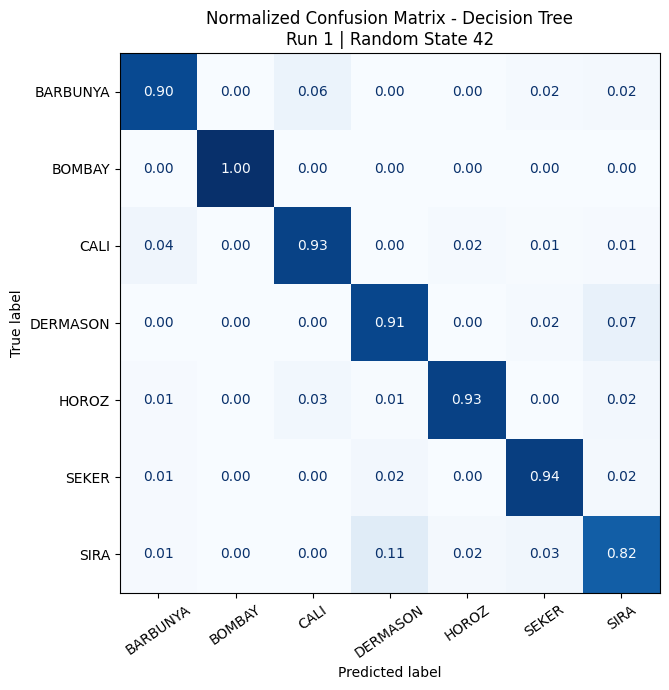


MODEL: Decision Tree
Total testing rows     : 2,709
Correct predictions    : 2,457
Incorrect predictions  : 252
Accuracy               : 90.6977%
Error rate             : 9.3023%


,run,random_state,model,class,support,correct_predictions,incorrect_predictions,class_recall,class_error_rate
0,1,42,Decision Tree,BARBUNYA,265,239,26,0.901887,0.098113
1,1,42,Decision Tree,BOMBAY,104,104,0,1.000000,0.000000
2,1,42,Decision Tree,CALI,326,302,24,0.926380,0.073620
3,1,42,Decision Tree,DERMASON,709,648,61,0.913963,0.086037
4,1,42,Decision Tree,HOROZ,372,347,25,0.932796,0.067204
5,1,42,Decision Tree,SEKER,406,383,23,0.943350,0.056650
6,1,42,Decision Tree,SIRA,527,434,93,0.823529,0.176471


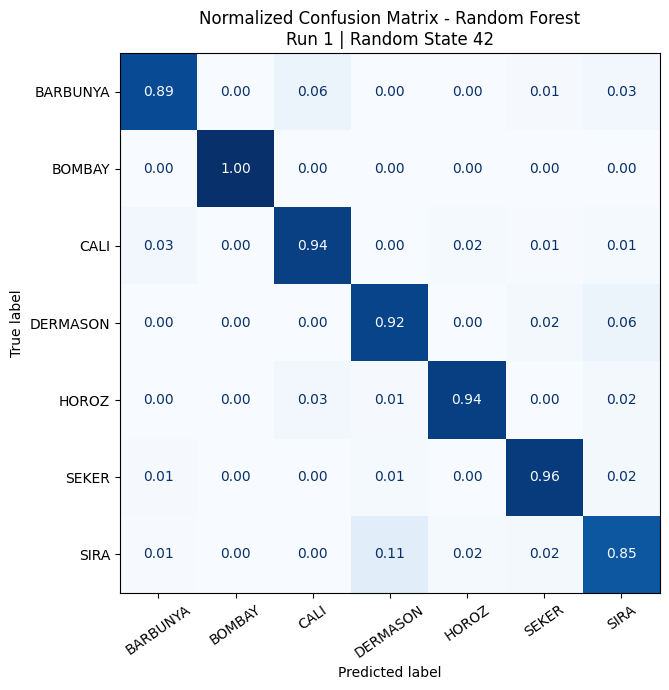


MODEL: Random Forest
Total testing rows     : 2,709
Correct predictions    : 2,482
Incorrect predictions  : 227
Accuracy               : 91.6205%
Error rate             : 8.3795%


,run,random_state,model,class,support,correct_predictions,incorrect_predictions,class_recall,class_error_rate
0,1,42,Random Forest,BARBUNYA,265,237,28,0.894340,0.105660
1,1,42,Random Forest,BOMBAY,104,104,0,1.000000,0.000000
2,1,42,Random Forest,CALI,326,305,21,0.935583,0.064417
3,1,42,Random Forest,DERMASON,709,652,57,0.919605,0.080395
4,1,42,Random Forest,HOROZ,372,349,23,0.938172,0.061828
5,1,42,Random Forest,SEKER,406,388,18,0.955665,0.044335
6,1,42,Random Forest,SIRA,527,447,80,0.848197,0.151803



CONFUSION MATRIX ANALYSIS: RUN 2/5 | SEED 43


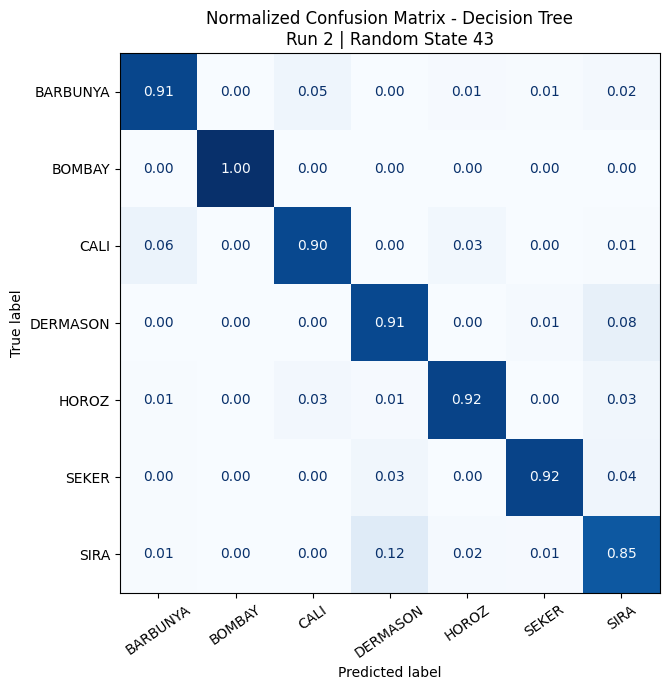


MODEL: Decision Tree
Total testing rows     : 2,709
Correct predictions    : 2,448
Incorrect predictions  : 261
Accuracy               : 90.3654%
Error rate             : 9.6346%


,run,random_state,model,class,support,correct_predictions,incorrect_predictions,class_recall,class_error_rate
0,2,43,Decision Tree,BARBUNYA,265,242,23,0.913208,0.086792
1,2,43,Decision Tree,BOMBAY,104,104,0,1.000000,0.000000
2,2,43,Decision Tree,CALI,326,295,31,0.904908,0.095092
3,2,43,Decision Tree,DERMASON,709,642,67,0.905501,0.094499
4,2,43,Decision Tree,HOROZ,372,344,28,0.924731,0.075269
5,2,43,Decision Tree,SEKER,406,375,31,0.923645,0.076355
6,2,43,Decision Tree,SIRA,527,446,81,0.846300,0.153700


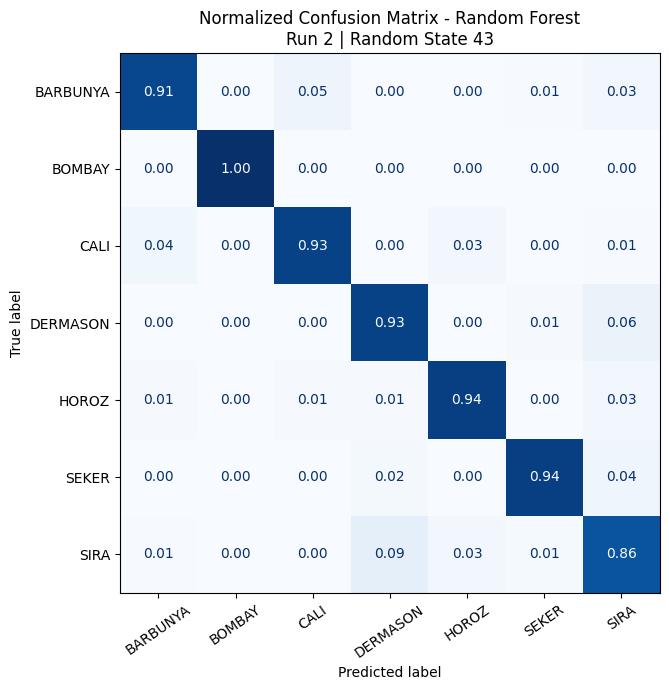


MODEL: Random Forest
Total testing rows     : 2,709
Correct predictions    : 2,490
Incorrect predictions  : 219
Accuracy               : 91.9158%
Error rate             : 8.0842%


,run,random_state,model,class,support,correct_predictions,incorrect_predictions,class_recall,class_error_rate
0,2,43,Random Forest,BARBUNYA,265,241,24,0.909434,0.090566
1,2,43,Random Forest,BOMBAY,104,104,0,1.000000,0.000000
2,2,43,Random Forest,CALI,326,303,23,0.929448,0.070552
3,2,43,Random Forest,DERMASON,709,658,51,0.928068,0.071932
4,2,43,Random Forest,HOROZ,372,349,23,0.938172,0.061828
5,2,43,Random Forest,SEKER,406,381,25,0.938424,0.061576
6,2,43,Random Forest,SIRA,527,454,73,0.861480,0.138520



CONFUSION MATRIX ANALYSIS: RUN 3/5 | SEED 44


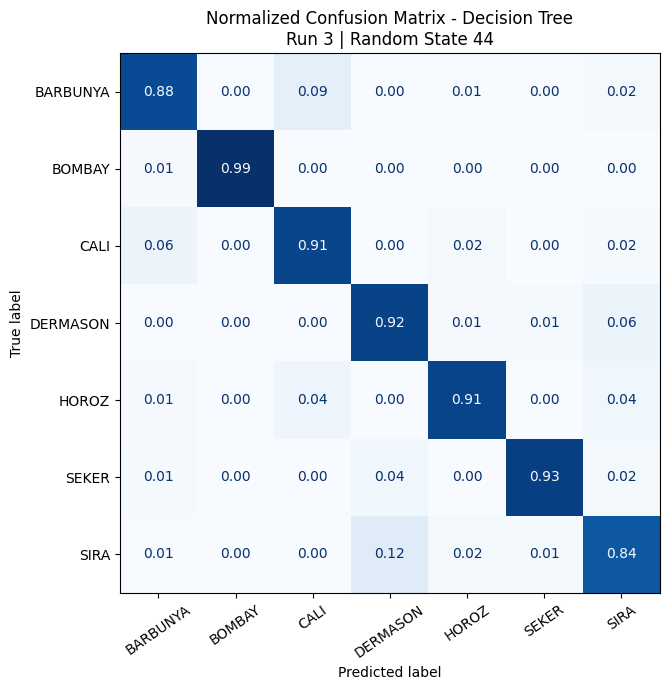


MODEL: Decision Tree
Total testing rows     : 2,709
Correct predictions    : 2,439
Incorrect predictions  : 270
Accuracy               : 90.0332%
Error rate             : 9.9668%


,run,random_state,model,class,support,correct_predictions,incorrect_predictions,class_recall,class_error_rate
0,3,44,Decision Tree,BARBUNYA,265,234,31,0.883019,0.116981
1,3,44,Decision Tree,BOMBAY,104,103,1,0.990385,0.009615
2,3,44,Decision Tree,CALI,326,296,30,0.907975,0.092025
3,3,44,Decision Tree,DERMASON,709,649,60,0.915374,0.084626
4,3,44,Decision Tree,HOROZ,372,339,33,0.911290,0.088710
5,3,44,Decision Tree,SEKER,406,377,29,0.928571,0.071429
6,3,44,Decision Tree,SIRA,527,441,86,0.836812,0.163188


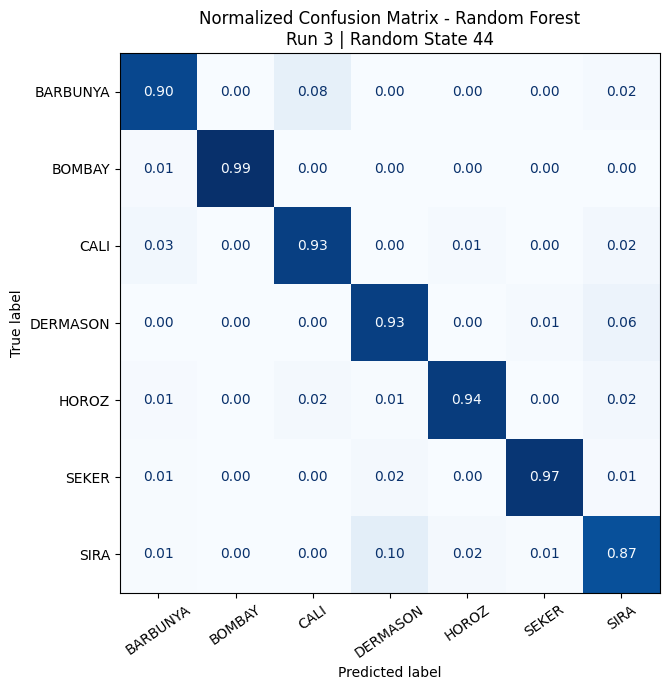


MODEL: Random Forest
Total testing rows     : 2,709
Correct predictions    : 2,502
Incorrect predictions  : 207
Accuracy               : 92.3588%
Error rate             : 7.6412%


,run,random_state,model,class,support,correct_predictions,incorrect_predictions,class_recall,class_error_rate
0,3,44,Random Forest,BARBUNYA,265,238,27,0.898113,0.101887
1,3,44,Random Forest,BOMBAY,104,103,1,0.990385,0.009615
2,3,44,Random Forest,CALI,326,303,23,0.929448,0.070552
3,3,44,Random Forest,DERMASON,709,659,50,0.929478,0.070522
4,3,44,Random Forest,HOROZ,372,350,22,0.940860,0.059140
5,3,44,Random Forest,SEKER,406,392,14,0.965517,0.034483
6,3,44,Random Forest,SIRA,527,457,70,0.867173,0.132827



CONFUSION MATRIX ANALYSIS: RUN 4/5 | SEED 45


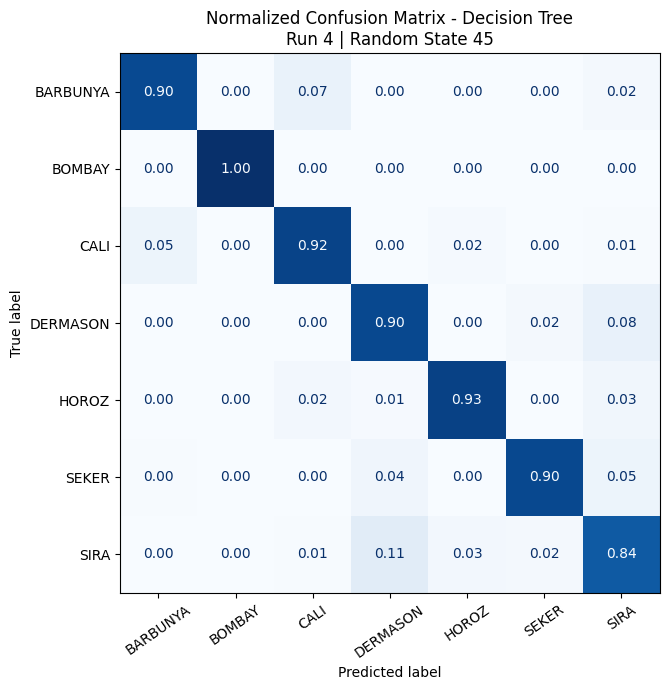


MODEL: Decision Tree
Total testing rows     : 2,709
Correct predictions    : 2,440
Incorrect predictions  : 269
Accuracy               : 90.0701%
Error rate             : 9.9299%


,run,random_state,model,class,support,correct_predictions,incorrect_predictions,class_recall,class_error_rate
0,4,45,Decision Tree,BARBUNYA,265,239,26,0.901887,0.098113
1,4,45,Decision Tree,BOMBAY,104,104,0,1.000000,0.000000
2,4,45,Decision Tree,CALI,326,301,25,0.923313,0.076687
3,4,45,Decision Tree,DERMASON,709,640,69,0.902680,0.097320
4,4,45,Decision Tree,HOROZ,372,347,25,0.932796,0.067204
5,4,45,Decision Tree,SEKER,406,367,39,0.903941,0.096059
6,4,45,Decision Tree,SIRA,527,442,85,0.838710,0.161290


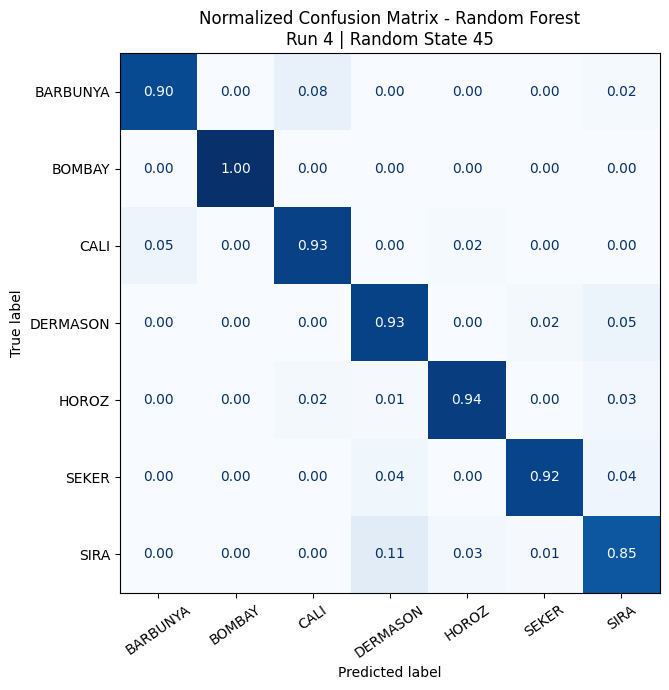


MODEL: Random Forest
Total testing rows     : 2,709
Correct predictions    : 2,477
Incorrect predictions  : 232
Accuracy               : 91.4360%
Error rate             : 8.5640%


,run,random_state,model,class,support,correct_predictions,incorrect_predictions,class_recall,class_error_rate
0,4,45,Random Forest,BARBUNYA,265,238,27,0.898113,0.101887
1,4,45,Random Forest,BOMBAY,104,104,0,1.000000,0.000000
2,4,45,Random Forest,CALI,326,304,22,0.932515,0.067485
3,4,45,Random Forest,DERMASON,709,659,50,0.929478,0.070522
4,4,45,Random Forest,HOROZ,372,351,21,0.943548,0.056452
5,4,45,Random Forest,SEKER,406,374,32,0.921182,0.078818
6,4,45,Random Forest,SIRA,527,447,80,0.848197,0.151803



CONFUSION MATRIX ANALYSIS: RUN 5/5 | SEED 46


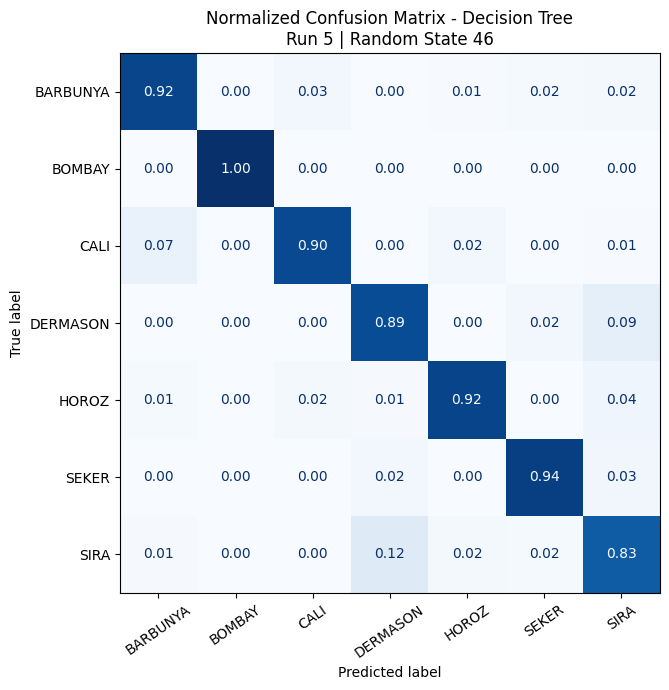


MODEL: Decision Tree
Total testing rows     : 2,709
Correct predictions    : 2,431
Incorrect predictions  : 278
Accuracy               : 89.7379%
Error rate             : 10.2621%


,run,random_state,model,class,support,correct_predictions,incorrect_predictions,class_recall,class_error_rate
0,5,46,Decision Tree,BARBUNYA,265,243,22,0.916981,0.083019
1,5,46,Decision Tree,BOMBAY,104,104,0,1.000000,0.000000
2,5,46,Decision Tree,CALI,326,294,32,0.901840,0.098160
3,5,46,Decision Tree,DERMASON,709,630,79,0.888575,0.111425
4,5,46,Decision Tree,HOROZ,372,342,30,0.919355,0.080645
5,5,46,Decision Tree,SEKER,406,381,25,0.938424,0.061576
6,5,46,Decision Tree,SIRA,527,437,90,0.829222,0.170778


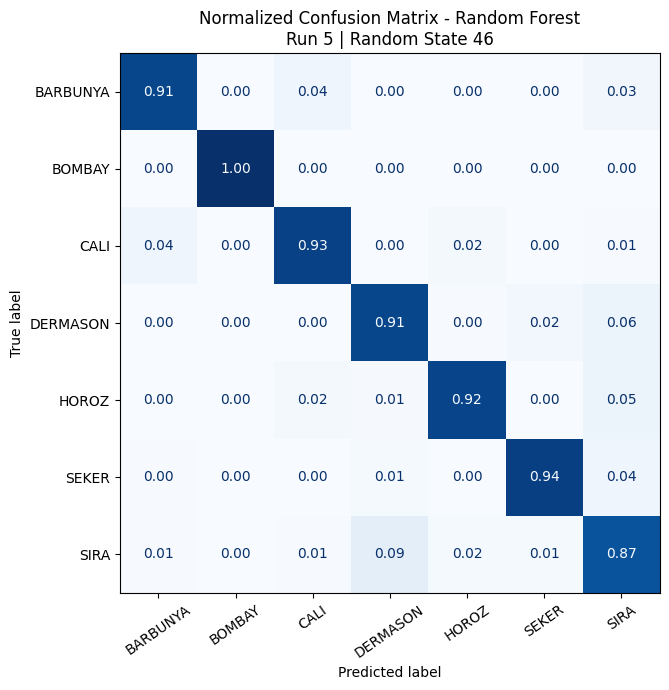


MODEL: Random Forest
Total testing rows     : 2,709
Correct predictions    : 2,477
Incorrect predictions  : 232
Accuracy               : 91.4360%
Error rate             : 8.5640%


,run,random_state,model,class,support,correct_predictions,incorrect_predictions,class_recall,class_error_rate
0,5,46,Random Forest,BARBUNYA,265,242,23,0.913208,0.086792
1,5,46,Random Forest,BOMBAY,104,104,0,1.000000,0.000000
2,5,46,Random Forest,CALI,326,304,22,0.932515,0.067485
3,5,46,Random Forest,DERMASON,709,647,62,0.912553,0.087447
4,5,46,Random Forest,HOROZ,372,342,30,0.919355,0.080645
5,5,46,Random Forest,SEKER,406,382,24,0.940887,0.059113
6,5,46,Random Forest,SIRA,527,456,71,0.865275,0.134725



FIVE-RUN MISCLASSIFICATION SUMMARY


,run,random_state,model,total_testing_rows,correct_predictions,incorrect_predictions,accuracy,error_rate
0,1,42,Decision Tree,2709,2457,252,0.9070,0.0930
1,1,42,Random Forest,2709,2482,227,0.9162,0.0838
2,2,43,Decision Tree,2709,2448,261,0.9037,0.0963
3,2,43,Random Forest,2709,2490,219,0.9192,0.0808
4,3,44,Decision Tree,2709,2439,270,0.9003,0.0997
5,3,44,Random Forest,2709,2502,207,0.9236,0.0764
6,4,45,Decision Tree,2709,2440,269,0.9007,0.0993
7,4,45,Random Forest,2709,2477,232,0.9144,0.0856
8,5,46,Decision Tree,2709,2431,278,0.8974,0.1026
9,5,46,Random Forest,2709,2477,232,0.9144,0.0856



FIVE-RUN CLASS-WISE ERROR ANALYSIS


,run,random_state,model,class,support,correct_predictions,incorrect_predictions,class_recall,class_error_rate
0,1,42,Decision Tree,BARBUNYA,265,239,26,0.9019,0.0981
1,1,42,Decision Tree,BOMBAY,104,104,0,1.0000,0.0000
2,1,42,Decision Tree,CALI,326,302,24,0.9264,0.0736
3,1,42,Decision Tree,DERMASON,709,648,61,0.9140,0.0860
4,1,42,Decision Tree,HOROZ,372,347,25,0.9328,0.0672
5,1,42,Decision Tree,SEKER,406,383,23,0.9433,0.0567
6,1,42,Decision Tree,SIRA,527,434,93,0.8235,0.1765
7,1,42,Random Forest,BARBUNYA,265,237,28,0.8943,0.1057
8,1,42,Random Forest,BOMBAY,104,104,0,1.0000,0.0000
9,1,42,Random Forest,CALI,326,305,21,0.9356,0.0644



AVERAGE MISCLASSIFICATION PERFORMANCE


,model,mean_incorrect_predictions,std_incorrect_predictions,mean_error_rate,std_error_rate,mean_accuracy,std_accuracy
0,Decision Tree,266.0,9.8742,0.0982,0.0036,0.9018,0.0036
1,Random Forest,223.4,10.5972,0.0825,0.0039,0.9175,0.0039


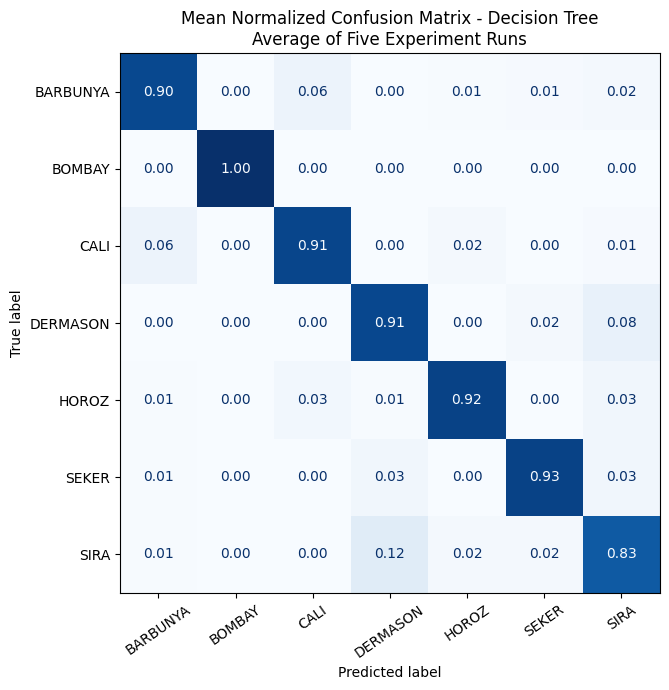

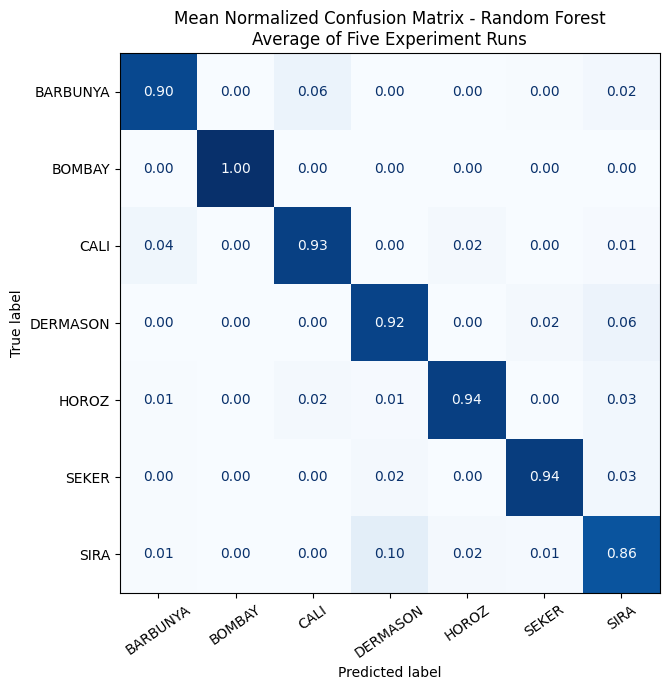


SECTION 12: FIVE-RUN CONFUSION MATRIX ANALYSIS COMPLETED
Total experiment runs       : 5
Total classification models : 2
Total confusion matrices    : 10
Total classes               : 7
Total testing observations  : 13,545
Class analysis records      : 70

MAIN FILES SUCCESSFULLY SAVED:
- five_run_misclassification_summary.csv
- five_run_class_error_analysis.csv
- five_run_error_performance_summary.csv
- mean_normalized_confusion_matrix_decision_tree.csv
- mean_normalized_confusion_matrix_random_forest.csv
- mean_confusion_matrix_decision_tree.png
- mean_confusion_matrix_random_forest.png

Output directory: /content/Dry_Bean_Classification_Submission/outputs/repeated_runs
Evidence directory: /content/Dry_Bean_Classification_Submission/evidence/repeated_runs

SECTION 12 BERHASIL DIJALANKAN.
Seluruh Confusion Matrix dan analisis kesalahan siap digunakan.


In [12]:

# ============================================================
# SECTION 12: FIVE-RUN CONFUSION MATRIX & MISCLASSIFICATION ANALYSIS
# ============================================================

# ------------------------------------------------------------
# A. IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

from pathlib import Path  # Mengimpor Path untuk mengatur lokasi penyimpanan hasil analisis.

import numpy as np  # Mengimpor NumPy untuk operasi numerik dan pengolahan matriks.

import pandas as pd  # Mengimpor Pandas untuk membuat tabel hasil analisis.

import matplotlib.pyplot as plt  # Mengimpor Matplotlib untuk membuat visualisasi Confusion Matrix.

from sklearn.metrics import (  # Mengimpor fungsi untuk menghitung dan memvisualisasikan Confusion Matrix.
    confusion_matrix,  # Menghitung jumlah prediksi benar dan salah untuk setiap kelas.
    ConfusionMatrixDisplay  # Membuat visualisasi Confusion Matrix.
)


# ------------------------------------------------------------
# B. VALIDATE REQUIRED VARIABLES
# ------------------------------------------------------------

# Menentukan seluruh variabel yang harus tersedia dari Section sebelumnya.
required_variables = [
    'RUN_SEEDS',
    'run_data_by_seed',
    'final_predictions_by_run',
    'REPEATED_OUTPUT_DIR',
    'REPEATED_EVIDENCE_DIR',
    'y'
]

# Memeriksa variabel yang belum tersedia.
missing_variables = [
    variable for variable in required_variables
    if variable not in globals()
]

# Menghentikan proses jika terdapat variabel yang belum tersedia.
if missing_variables:
    raise NameError(
        f'Variabel yang belum tersedia: {missing_variables}. '
        'Jalankan Section 9, 10, dan 11 terlebih dahulu.'
    )

# Menentukan nama kedua algoritma yang akan dianalisis.
MODEL_NAMES = [
    'Decision Tree',
    'Random Forest'
]

# Mengambil seluruh nama kelas dari target dataset.
class_labels = sorted(
    pd.Series(y).dropna().unique().tolist()
)

# Memastikan dataset memiliki tujuh kelas kacang.
assert len(class_labels) == 7, (
    f'Diharapkan 7 kelas, tetapi ditemukan {len(class_labels)} kelas.'
)

# Memastikan seluruh hasil prediksi tersedia untuk setiap putaran.
for seed in RUN_SEEDS:

    if seed not in final_predictions_by_run:
        raise KeyError(
            f'Hasil prediksi untuk random seed {seed} tidak ditemukan.'
        )

    if seed not in run_data_by_seed:
        raise KeyError(
            f'Data eksperimen untuk random seed {seed} tidak ditemukan.'
        )

    for name in MODEL_NAMES:

        if name not in final_predictions_by_run[seed]:
            raise KeyError(
                f'Prediksi {name} pada seed {seed} tidak ditemukan.'
            )


# ------------------------------------------------------------
# C. PREPARE STORAGE FOR CONFUSION MATRIX ANALYSIS
# ------------------------------------------------------------

# Membuat dictionary untuk menyimpan Confusion Matrix setiap putaran.
confusion_matrices_by_run = {}

# Membuat dictionary untuk menyimpan Confusion Matrix yang sudah dinormalisasi.
normalized_confusion_matrices_by_run = {}

# Membuat list untuk menyimpan ringkasan kesalahan prediksi.
misclassification_summary_rows = []

# Membuat list untuk menyimpan analisis kesalahan setiap kelas.
per_class_error_rows = []

# Menampilkan seluruh kelas yang akan dianalisis.
print('CLASS LABELS:')

for label in class_labels:
    print('-', label)


# ------------------------------------------------------------
# D. CONFUSION MATRIX ANALYSIS FOR FIVE RUNS
# ------------------------------------------------------------

# Melakukan analisis Confusion Matrix pada seluruh putaran eksperimen.
for run_number, seed in enumerate(RUN_SEEDS, start=1):

    # Menampilkan identitas putaran yang sedang dianalisis.
    print('\n' + '=' * 70)

    print(f'CONFUSION MATRIX ANALYSIS: RUN {run_number}/5 | SEED {seed}')

    print('=' * 70)

    # Mengambil label sebenarnya dari data testing putaran saat ini.
    y_test_run = run_data_by_seed[seed]['y_test']

    # Mengambil indeks data testing dari dataset bersih.
    test_idx = np.asarray(
        run_data_by_seed[seed]['test_idx']
    )

    # Membuat dictionary untuk menyimpan matriks putaran saat ini.
    confusion_matrices_by_run[seed] = {}

    # Membuat dictionary untuk menyimpan matriks normalisasi putaran saat ini.
    normalized_confusion_matrices_by_run[seed] = {}

    # Menentukan folder penyimpanan hasil putaran saat ini.
    run_output_dir = (
        REPEATED_OUTPUT_DIR / f'run_{run_number}_seed_{seed}'
    )

    # Menentukan folder penyimpanan bukti putaran saat ini.
    run_evidence_dir = (
        REPEATED_EVIDENCE_DIR / f'run_{run_number}_seed_{seed}'
    )

    # Memastikan folder penyimpanan tersedia.
    run_output_dir.mkdir(parents=True, exist_ok=True)

    run_evidence_dir.mkdir(parents=True, exist_ok=True)


    # --------------------------------------------------------
    # D1. ANALYZE EACH CLASSIFICATION MODEL
    # --------------------------------------------------------

    # Melakukan analisis terhadap Decision Tree dan Random Forest.
    for name in MODEL_NAMES:

        # Mengambil prediksi model dari Section 11.
        pred = np.asarray(
            final_predictions_by_run[seed][name]
        )

        # Mengubah label sebenarnya menjadi array NumPy.
        y_true = np.asarray(y_test_run)

        # Memastikan jumlah prediksi sama dengan jumlah data testing.
        assert len(pred) == len(y_true), (
            f'Jumlah prediksi {name} pada seed {seed} tidak sesuai.'
        )

        # Memastikan urutan prediksi sesuai dengan urutan indeks testing.
        assert len(test_idx) == len(y_true), (
            f'Jumlah indeks testing pada seed {seed} tidak sesuai.'
        )


        # ----------------------------------------------------
        # D2. CALCULATE CONFUSION MATRIX
        # ----------------------------------------------------

        # Menghitung Confusion Matrix berdasarkan jumlah prediksi.
        cm = confusion_matrix(
            y_true,
            pred,
            labels=class_labels
        )

        # Menghitung Confusion Matrix berdasarkan proporsi setiap kelas sebenarnya.
        cmn = confusion_matrix(
            y_true,
            pred,
            labels=class_labels,
            normalize='true'
        )

        # Memastikan total observasi pada matriks sesuai dengan data testing.
        assert cm.sum() == len(y_true)

        # Menyimpan Confusion Matrix berdasarkan random seed dan nama model.
        confusion_matrices_by_run[seed][name] = cm

        # Menyimpan Confusion Matrix normalisasi.
        normalized_confusion_matrices_by_run[seed][name] = cmn


        # ----------------------------------------------------
        # D3. SAVE CONFUSION MATRIX COUNTS
        # ----------------------------------------------------

        # Mengubah Confusion Matrix jumlah prediksi menjadi DataFrame.
        cm_df = pd.DataFrame(
            cm,
            index=class_labels,
            columns=class_labels
        )

        # Memberikan nama pada indeks kelas sebenarnya.
        cm_df.index.name = 'actual_class'

        # Memberikan nama pada kolom kelas hasil prediksi.
        cm_df.columns.name = 'predicted_class'

        # Mengubah nama model menjadi format aman untuk nama file.
        safe = name.lower().replace(' ', '_')

        # Menyimpan Confusion Matrix jumlah prediksi ke folder evidence.
        cm_df.to_csv(
            run_evidence_dir / f'confusion_matrix_counts_{safe}.csv'
        )


        # ----------------------------------------------------
        # D4. SAVE NORMALIZED CONFUSION MATRIX
        # ----------------------------------------------------

        # Mengubah Confusion Matrix normalisasi menjadi DataFrame.
        cmn_df = pd.DataFrame(
            cmn,
            index=class_labels,
            columns=class_labels
        )

        # Memberikan nama pada indeks kelas sebenarnya.
        cmn_df.index.name = 'actual_class'

        # Memberikan nama pada kolom kelas hasil prediksi.
        cmn_df.columns.name = 'predicted_class'

        # Menyimpan Confusion Matrix normalisasi.
        cmn_df.to_csv(
            run_evidence_dir / f'confusion_matrix_normalized_{safe}.csv'
        )


        # ----------------------------------------------------
        # D5. CONFUSION MATRIX VISUALIZATION
        # ----------------------------------------------------

        # Membuat area visualisasi dengan ukuran 9 x 7 inci.
        fig, ax = plt.subplots(figsize=(9, 7))

        # Membuat visualisasi Confusion Matrix normalisasi.
        ConfusionMatrixDisplay(
            confusion_matrix=cmn,
            display_labels=class_labels
        ).plot(
            ax=ax,
            cmap='Blues',
            values_format='.2f',
            colorbar=False,
            xticks_rotation=35
        )

        # Memberikan judul berdasarkan nama algoritma dan putaran eksperimen.
        ax.set_title(
            f'Normalized Confusion Matrix - {name}\n'
            f'Run {run_number} | Random State {seed}'
        )

        # Mengatur tata letak visualisasi.
        fig.tight_layout()

        # Menyimpan visualisasi Confusion Matrix ke folder outputs.
        fig.savefig(
            run_output_dir / f'confusion_matrix_{safe}.png',
            dpi=180,
            bbox_inches='tight'
        )

        # Menampilkan visualisasi pada Google Colab.
        plt.show()

        # Menutup figure untuk menghemat memori.
        plt.close(fig)


        # ----------------------------------------------------
        # D6. PREDICTION RESULTS
        # ----------------------------------------------------

        # Membuat DataFrame untuk menyimpan hasil prediksi.
        prediction_data = {
            'test_row_position': test_idx,
            'actual_class': y_true,
            'predicted_class': pred,
            'correct': y_true == pred
        }

        # Memeriksa ketersediaan dataset bersih dan identitas baris sumber.
        if (
            'df_clean' in globals()
            and 'source_row_index' in df_clean.columns
        ):

            # Menambahkan indeks sumber dari dataset sebelum pembersihan.
            prediction_data['source_row_index'] = (
                df_clean.iloc[test_idx]['source_row_index'].to_numpy()
            )

        # Mengubah hasil prediksi menjadi DataFrame.
        pred_df = pd.DataFrame(prediction_data)

        # Menyimpan seluruh hasil prediksi ke folder evidence.
        pred_df.to_csv(
            run_evidence_dir / f'predictions_{safe}.csv',
            index=False
        )

        # Memilih baris yang hasil prediksinya salah.
        misclassified_df = pred_df.loc[
            ~pred_df['correct']
        ].copy()

        # Menyimpan hanya data yang salah diklasifikasikan.
        misclassified_df.to_csv(
            run_evidence_dir / f'misclassified_rows_{safe}.csv',
            index=False
        )


        # ----------------------------------------------------
        # D7. CLASS-WISE MISCLASSIFICATION ANALYSIS
        # ----------------------------------------------------

        # Membuat list untuk menyimpan kesalahan setiap kelas.
        current_class_errors = []

        # Menganalisis setiap kelas berdasarkan Confusion Matrix.
        for class_index, class_name in enumerate(class_labels):

            # Menghitung jumlah observasi sebenarnya pada kelas tersebut.
            support = int(cm[class_index].sum())

            # Menghitung jumlah prediksi yang benar untuk kelas tersebut.
            correct_count = int(cm[class_index, class_index])

            # Menghitung jumlah prediksi yang salah untuk kelas tersebut.
            incorrect_count = support - correct_count

            # Menghitung recall kelas tersebut.
            class_recall = (
                correct_count / support
                if support > 0
                else 0.0
            )

            # Menghitung error rate kelas tersebut.
            class_error_rate = (
                incorrect_count / support
                if support > 0
                else 0.0
            )

            # Membuat ringkasan kesalahan per kelas.
            class_error_row = {
                'run': run_number,
                'random_state': seed,
                'model': name,
                'class': class_name,
                'support': support,
                'correct_predictions': correct_count,
                'incorrect_predictions': incorrect_count,
                'class_recall': class_recall,
                'class_error_rate': class_error_rate
            }

            # Menambahkan hasil analisis kelas ke dalam list keseluruhan.
            per_class_error_rows.append(class_error_row)

            # Menambahkan hasil analisis kelas ke dalam list putaran saat ini.
            current_class_errors.append(class_error_row)

        # Mengubah analisis kesalahan kelas menjadi DataFrame.
        class_error_df = pd.DataFrame(current_class_errors)

        # Menyimpan analisis kesalahan setiap kelas.
        class_error_df.to_csv(
            run_evidence_dir / f'class_error_analysis_{safe}.csv',
            index=False
        )


        # ----------------------------------------------------
        # D8. MODEL ERROR SUMMARY
        # ----------------------------------------------------

        # Menghitung jumlah seluruh observasi testing.
        total_observations = len(y_true)

        # Menghitung jumlah prediksi yang benar.
        correct_predictions = int(pred_df['correct'].sum())

        # Menghitung jumlah prediksi yang salah.
        incorrect_predictions = int((~pred_df['correct']).sum())

        # Menghitung akurasi berdasarkan Confusion Matrix.
        accuracy = (
            correct_predictions / total_observations
        )

        # Menghitung persentase kesalahan prediksi.
        error_rate = (
            incorrect_predictions / total_observations
        )

        # Menyimpan ringkasan kesalahan model.
        misclassification_summary_rows.append({
            'run': run_number,
            'random_state': seed,
            'model': name,
            'total_testing_rows': total_observations,
            'correct_predictions': correct_predictions,
            'incorrect_predictions': incorrect_predictions,
            'accuracy': accuracy,
            'error_rate': error_rate
        })

        # Menampilkan hasil analisis model.
        print(f'\nMODEL: {name}')

        print(f'Total testing rows     : {total_observations:,}')

        print(f'Correct predictions    : {correct_predictions:,}')

        print(f'Incorrect predictions  : {incorrect_predictions:,}')

        print(f'Accuracy               : {accuracy:.4%}')

        print(f'Error rate             : {error_rate:.4%}')

        # Menampilkan analisis kesalahan setiap kelas.
        display(class_error_df)


# ------------------------------------------------------------
# E. COMBINE FIVE-RUN MISCLASSIFICATION RESULTS
# ------------------------------------------------------------

# Menggabungkan seluruh ringkasan kesalahan menjadi DataFrame.
misclassification_summary = pd.DataFrame(
    misclassification_summary_rows
)

# Mengurutkan hasil berdasarkan putaran dan algoritma.
misclassification_summary = misclassification_summary.sort_values(
    by=['run', 'model']
).reset_index(drop=True)

# Menampilkan seluruh hasil kesalahan lima putaran.
print('\nFIVE-RUN MISCLASSIFICATION SUMMARY')

display(
    misclassification_summary.round(4)
)

# Menyimpan seluruh ringkasan kesalahan ke folder outputs.
misclassification_summary.to_csv(
    REPEATED_OUTPUT_DIR / 'five_run_misclassification_summary.csv',
    index=False
)


# ------------------------------------------------------------
# F. COMBINE CLASS-WISE ERROR ANALYSIS
# ------------------------------------------------------------

# Menggabungkan seluruh analisis kesalahan per kelas.
per_class_error_summary = pd.DataFrame(
    per_class_error_rows
)

# Mengurutkan hasil berdasarkan putaran, algoritma, dan kelas.
per_class_error_summary = per_class_error_summary.sort_values(
    by=['run', 'model', 'class']
).reset_index(drop=True)

# Menampilkan hasil analisis kesalahan setiap kelas.
print('\nFIVE-RUN CLASS-WISE ERROR ANALYSIS')

display(
    per_class_error_summary.round(4)
)

# Menyimpan seluruh analisis kesalahan per kelas.
per_class_error_summary.to_csv(
    REPEATED_OUTPUT_DIR / 'five_run_class_error_analysis.csv',
    index=False
)


# ------------------------------------------------------------
# G. CALCULATE AVERAGE MISCLASSIFICATION PERFORMANCE
# ------------------------------------------------------------

# Menghitung rata-rata dan standar deviasi kesalahan setiap algoritma.
misclassification_performance_summary = (
    misclassification_summary
    .groupby('model')
    .agg(
        mean_incorrect_predictions=(
            'incorrect_predictions', 'mean'
        ),
        std_incorrect_predictions=(
            'incorrect_predictions', 'std'
        ),
        mean_error_rate=(
            'error_rate', 'mean'
        ),
        std_error_rate=(
            'error_rate', 'std'
        ),
        mean_accuracy=(
            'accuracy', 'mean'
        ),
        std_accuracy=(
            'accuracy', 'std'
        )
    )
    .reset_index()
)

# Menampilkan ringkasan rata-rata kesalahan lima putaran.
print('\nAVERAGE MISCLASSIFICATION PERFORMANCE')

display(
    misclassification_performance_summary.round(4)
)

# Menyimpan ringkasan performa kesalahan.
misclassification_performance_summary.to_csv(
    REPEATED_OUTPUT_DIR / 'five_run_error_performance_summary.csv',
    index=False
)


# ------------------------------------------------------------
# H. CALCULATE MEAN NORMALIZED CONFUSION MATRIX
# ------------------------------------------------------------

# Membuat dictionary untuk menyimpan rata-rata Confusion Matrix setiap algoritma.
mean_normalized_confusion_matrices = {}

# Melakukan perhitungan rata-rata matriks untuk setiap algoritma.
for name in MODEL_NAMES:

    # Mengambil seluruh Confusion Matrix normalisasi dari lima putaran.
    matrices = [
        normalized_confusion_matrices_by_run[seed][name]
        for seed in RUN_SEEDS
    ]

    # Menghitung rata-rata matriks normalisasi dari lima putaran.
    mean_cmn = np.mean(
        np.stack(matrices, axis=0),
        axis=0
    )

    # Menyimpan rata-rata matriks berdasarkan nama algoritma.
    mean_normalized_confusion_matrices[name] = mean_cmn

    # Mengubah matriks rata-rata menjadi DataFrame.
    mean_cmn_df = pd.DataFrame(
        mean_cmn,
        index=class_labels,
        columns=class_labels
    )

    # Memberikan nama indeks kelas sebenarnya.
    mean_cmn_df.index.name = 'actual_class'

    # Memberikan nama kolom kelas hasil prediksi.
    mean_cmn_df.columns.name = 'predicted_class'

    # Menentukan nama file yang aman.
    safe = name.lower().replace(' ', '_')

    # Menyimpan rata-rata Confusion Matrix normalisasi.
    mean_cmn_df.to_csv(
        REPEATED_OUTPUT_DIR / f'mean_normalized_confusion_matrix_{safe}.csv'
    )

    # Membuat visualisasi rata-rata Confusion Matrix.
    fig, ax = plt.subplots(figsize=(9, 7))

    # Menggambar rata-rata Confusion Matrix normalisasi.
    ConfusionMatrixDisplay(
        confusion_matrix=mean_cmn,
        display_labels=class_labels
    ).plot(
        ax=ax,
        cmap='Blues',
        values_format='.2f',
        colorbar=False,
        xticks_rotation=35
    )

    # Memberikan judul grafik.
    ax.set_title(
        f'Mean Normalized Confusion Matrix - {name}\n'
        f'Average of Five Experiment Runs'
    )

    # Mengatur tata letak grafik.
    fig.tight_layout()

    # Menyimpan grafik rata-rata Confusion Matrix.
    fig.savefig(
        REPEATED_OUTPUT_DIR / f'mean_confusion_matrix_{safe}.png',
        dpi=180,
        bbox_inches='tight'
    )

    # Menampilkan grafik rata-rata.
    plt.show()

    # Menutup figure untuk menghemat memori.
    plt.close(fig)


# ------------------------------------------------------------
# I. SAVE MAIN ANALYSIS FILES
# ------------------------------------------------------------

# Memastikan folder evidence tersedia.
REPEATED_EVIDENCE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Menyimpan ringkasan kesalahan seluruh putaran.
misclassification_summary.to_csv(
    REPEATED_EVIDENCE_DIR / 'five_run_misclassification_summary.csv',
    index=False
)

# Menyimpan analisis kesalahan seluruh kelas.
per_class_error_summary.to_csv(
    REPEATED_EVIDENCE_DIR / 'five_run_class_error_analysis.csv',
    index=False
)

# Menyimpan ringkasan performa kesalahan.
misclassification_performance_summary.to_csv(
    REPEATED_EVIDENCE_DIR / 'five_run_error_performance_summary.csv',
    index=False
)


# ------------------------------------------------------------
# J. FINAL EXECUTION SUMMARY
# ------------------------------------------------------------

# Menghitung jumlah keseluruhan Confusion Matrix yang dihasilkan.
total_confusion_matrices = sum(
    len(confusion_matrices_by_run[seed])
    for seed in RUN_SEEDS
)

# Menghitung jumlah keseluruhan data testing yang dianalisis.
total_testing_rows = sum(
    len(run_data_by_seed[seed]['y_test'])
    for seed in RUN_SEEDS
)

# Menghitung jumlah seluruh baris analisis kesalahan kelas.
total_class_analysis_rows = len(
    per_class_error_summary
)

# Menampilkan garis pemisah.
print('\n' + '=' * 70)

# Menampilkan status keberhasilan Section 12.
print('SECTION 12: FIVE-RUN CONFUSION MATRIX ANALYSIS COMPLETED')

# Menampilkan garis pemisah.
print('=' * 70)

# Menampilkan jumlah putaran eksperimen.
print(f'Total experiment runs       : {len(RUN_SEEDS)}')

# Menampilkan jumlah algoritma.
print(f'Total classification models : {len(MODEL_NAMES)}')

# Menampilkan jumlah Confusion Matrix yang berhasil dibuat.
print(f'Total confusion matrices    : {total_confusion_matrices}')

# Menampilkan jumlah kelas.
print(f'Total classes               : {len(class_labels)}')

# Menampilkan jumlah keseluruhan observasi testing.
print(f'Total testing observations  : {total_testing_rows:,}')

# Menampilkan jumlah baris analisis kelas.
print(f'Class analysis records      : {total_class_analysis_rows}')

# Menampilkan daftar file hasil analisis.
print('\nMAIN FILES SUCCESSFULLY SAVED:')

print('- five_run_misclassification_summary.csv')

print('- five_run_class_error_analysis.csv')

print('- five_run_error_performance_summary.csv')

print('- mean_normalized_confusion_matrix_decision_tree.csv')

print('- mean_normalized_confusion_matrix_random_forest.csv')

print('- mean_confusion_matrix_decision_tree.png')

print('- mean_confusion_matrix_random_forest.png')

# Menampilkan folder penyimpanan hasil.
print(f'\nOutput directory: {REPEATED_OUTPUT_DIR.resolve()}')

print(f'Evidence directory: {REPEATED_EVIDENCE_DIR.resolve()}')

# Menampilkan status akhir.
print('\nSECTION 12 BERHASIL DIJALANKAN.')

print('Seluruh Confusion Matrix dan analisis kesalahan siap digunakan.')


## 13. Feature importance dan interpretasi

FEATURE IMPORTANCE CONFIGURATION
Total experiment runs : 5
Total algorithms      : 2
Total features         : 16
Permutation repeats   : 5
Permutation scoring   : f1_macro

FEATURE IMPORTANCE: RUN 1/5 | RANDOM STATE: 42


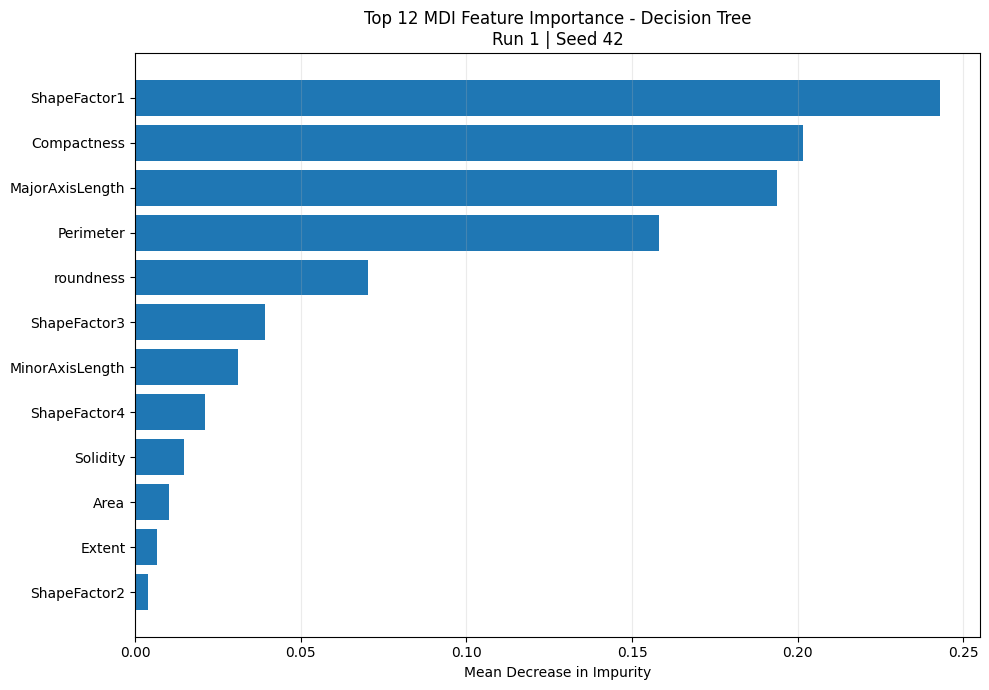


MDI FEATURE IMPORTANCE: Decision Tree


,feature,importance,rank,top_12
0,ShapeFactor1,0.242866,1,True
1,Compactness,0.201646,2,True
2,MajorAxisLength,0.193621,3,True
3,Perimeter,0.158197,4,True
4,roundness,0.070330,5,True
5,ShapeFactor3,0.039255,6,True
6,MinorAxisLength,0.030925,7,True
7,ShapeFactor4,0.021183,8,True
8,Solidity,0.014703,9,True
9,Area,0.010107,10,True


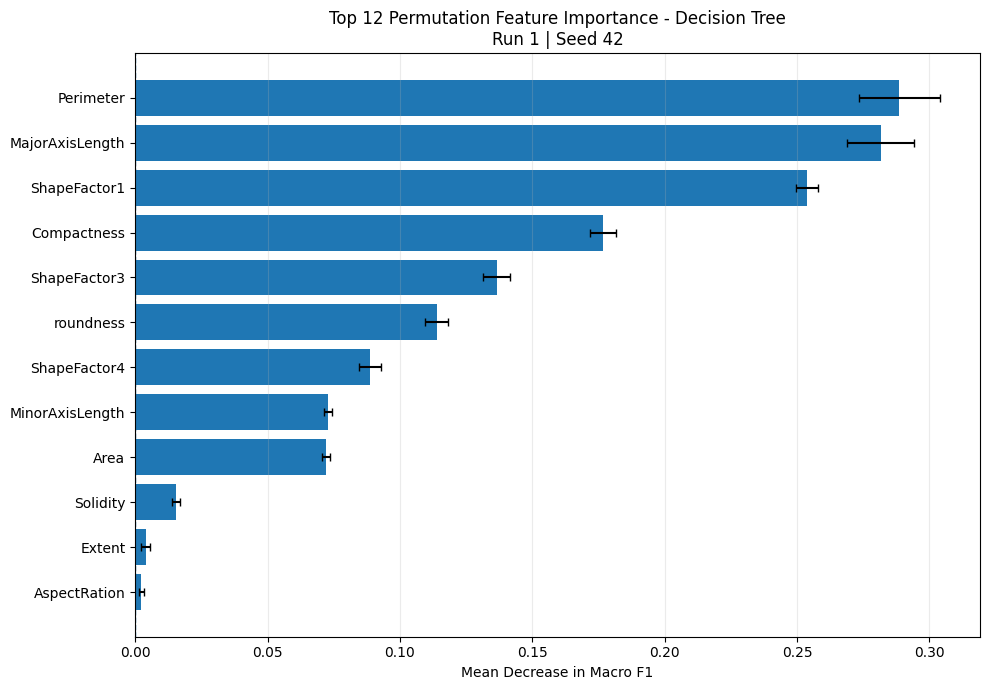


PERMUTATION FEATURE IMPORTANCE: Decision Tree


,feature,importance_mean,importance_std,rank,top_12
0,Perimeter,0.288610,0.015300,1,True
1,MajorAxisLength,0.281640,0.012596,2,True
2,ShapeFactor1,0.253795,0.004157,3,True
3,Compactness,0.176691,0.005072,4,True
4,ShapeFactor3,0.136572,0.005120,5,True
5,roundness,0.113973,0.004342,6,True
6,ShapeFactor4,0.088689,0.004246,7,True
7,MinorAxisLength,0.072872,0.001415,8,True
8,Area,0.072188,0.001512,9,True
9,Solidity,0.015432,0.001434,10,True


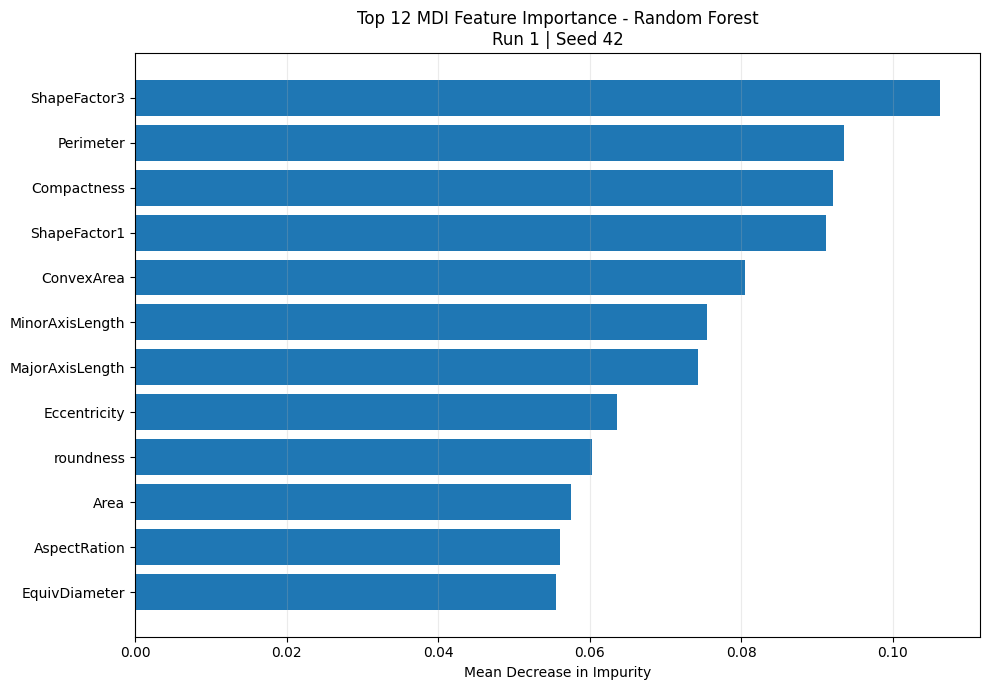


MDI FEATURE IMPORTANCE: Random Forest


,feature,importance,rank,top_12
0,ShapeFactor3,0.106231,1,True
1,Perimeter,0.093534,2,True
2,Compactness,0.092196,3,True
3,ShapeFactor1,0.091228,4,True
4,ConvexArea,0.080476,5,True
5,MinorAxisLength,0.075537,6,True
6,MajorAxisLength,0.074291,7,True
7,Eccentricity,0.063560,8,True
8,roundness,0.060264,9,True
9,Area,0.057561,10,True


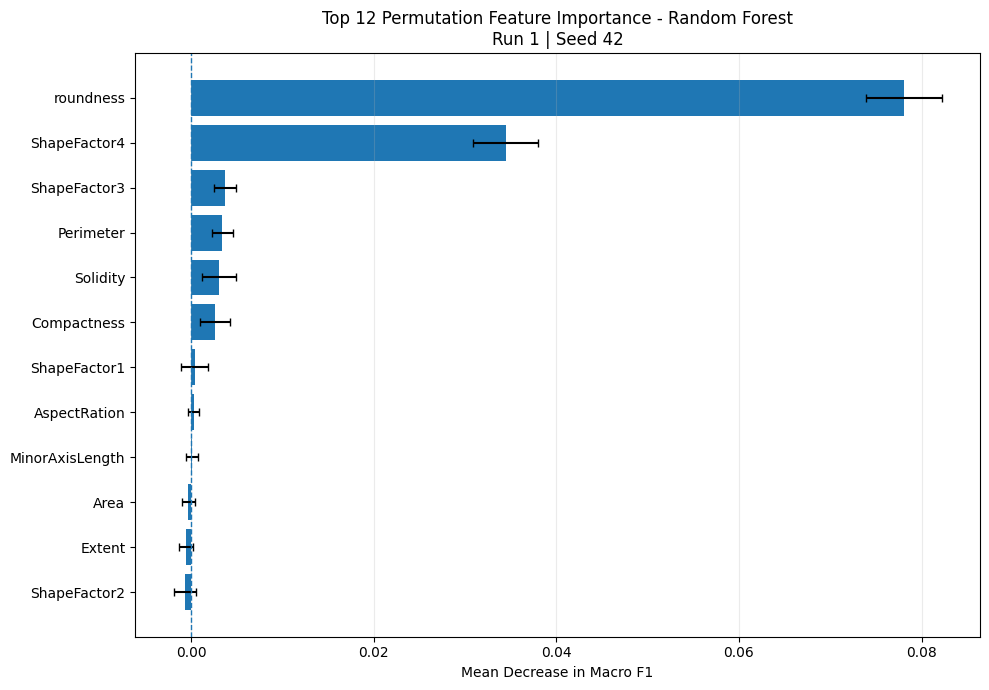


PERMUTATION FEATURE IMPORTANCE: Random Forest


,feature,importance_mean,importance_std,rank,top_12
0,roundness,0.078079,0.004115,1,True
1,ShapeFactor4,0.034429,0.003526,2,True
2,ShapeFactor3,0.003712,0.001230,3,True
3,Perimeter,0.003419,0.001141,4,True
4,Solidity,0.003078,0.001864,5,True
5,Compactness,0.002621,0.001669,6,True
6,ShapeFactor1,0.000372,0.001484,7,True
7,AspectRation,0.000267,0.000578,8,True
8,MinorAxisLength,0.000068,0.000673,9,True
9,Area,-0.000329,0.000690,10,True



FEATURE IMPORTANCE: RUN 2/5 | RANDOM STATE: 43


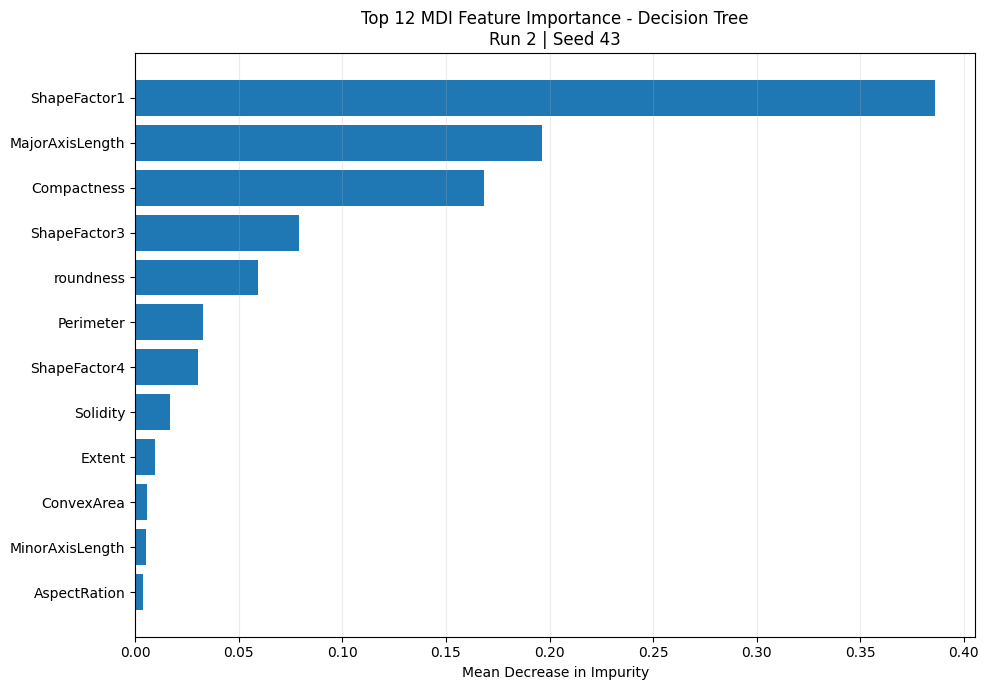


MDI FEATURE IMPORTANCE: Decision Tree


,feature,importance,rank,top_12
0,ShapeFactor1,0.386123,1,True
1,MajorAxisLength,0.196269,2,True
2,Compactness,0.168536,3,True
3,ShapeFactor3,0.078845,4,True
4,roundness,0.059153,5,True
5,Perimeter,0.032724,6,True
6,ShapeFactor4,0.030382,7,True
7,Solidity,0.016578,8,True
8,Extent,0.009425,9,True
9,ConvexArea,0.005462,10,True


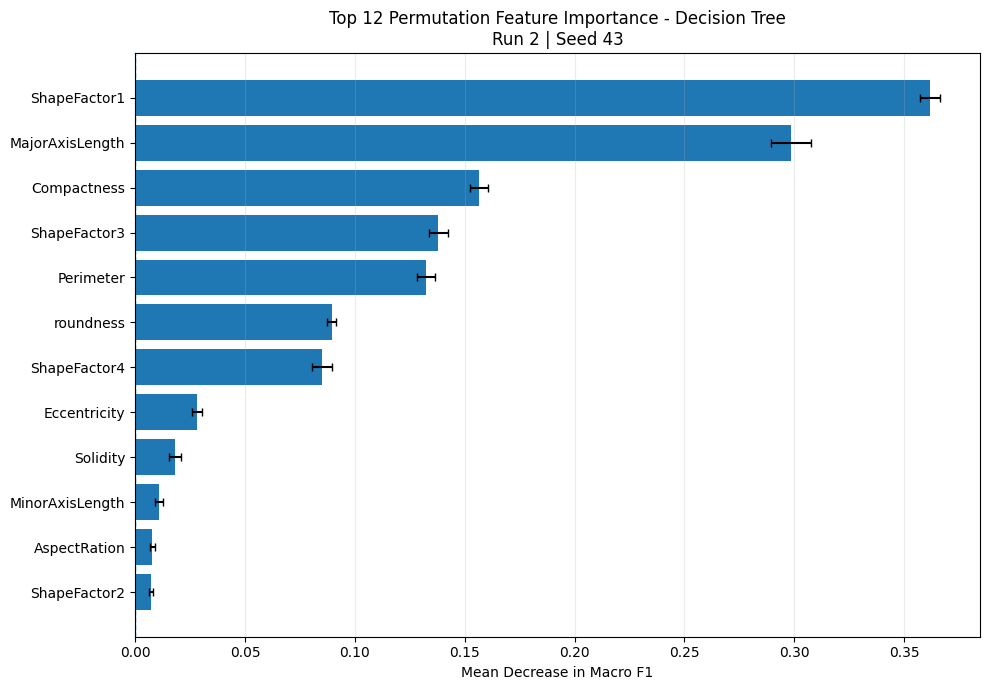


PERMUTATION FEATURE IMPORTANCE: Decision Tree


,feature,importance_mean,importance_std,rank,top_12
0,ShapeFactor1,0.361664,0.004612,1,True
1,MajorAxisLength,0.298706,0.009141,2,True
2,Compactness,0.156429,0.004229,3,True
3,ShapeFactor3,0.138007,0.004319,4,True
4,Perimeter,0.132337,0.004156,5,True
5,roundness,0.089470,0.002145,6,True
6,ShapeFactor4,0.084941,0.004674,7,True
7,Eccentricity,0.028274,0.002317,8,True
8,Solidity,0.018078,0.002643,9,True
9,MinorAxisLength,0.010744,0.001720,10,True


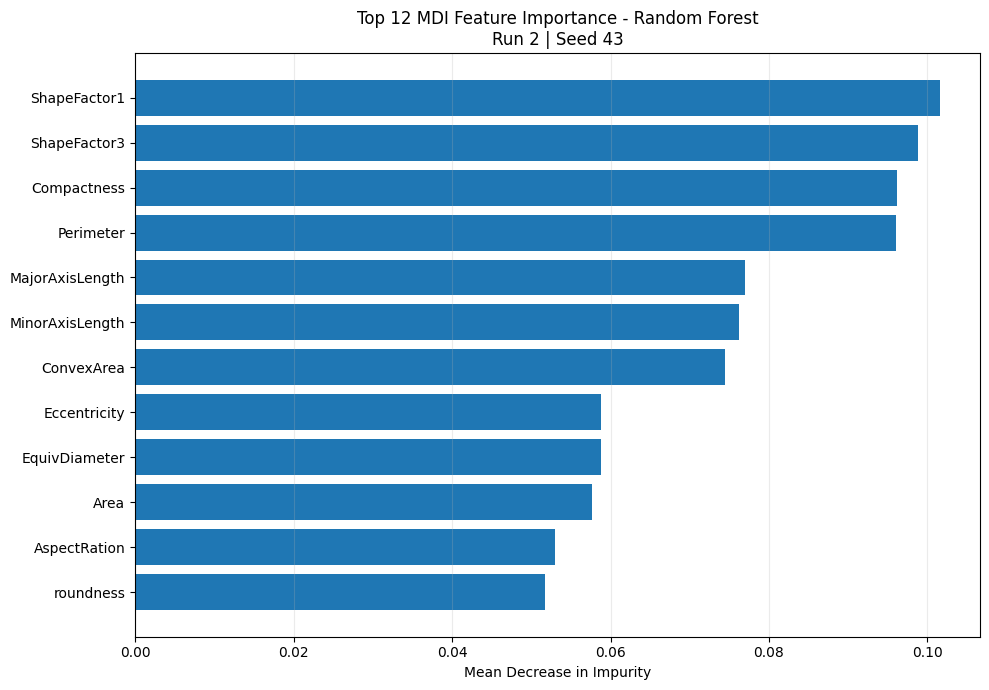


MDI FEATURE IMPORTANCE: Random Forest


,feature,importance,rank,top_12
0,ShapeFactor1,0.101558,1,True
1,ShapeFactor3,0.098870,2,True
2,Compactness,0.096147,3,True
3,Perimeter,0.096066,4,True
4,MajorAxisLength,0.076966,5,True
5,MinorAxisLength,0.076177,6,True
6,ConvexArea,0.074415,7,True
7,Eccentricity,0.058845,8,True
8,EquivDiameter,0.058791,9,True
9,Area,0.057666,10,True


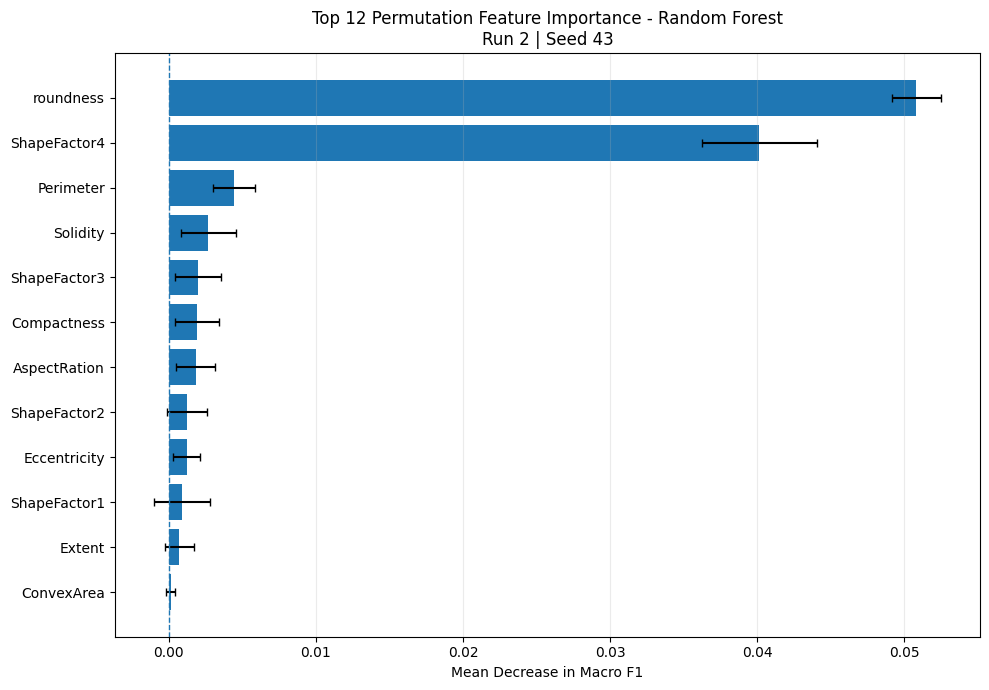


PERMUTATION FEATURE IMPORTANCE: Random Forest


,feature,importance_mean,importance_std,rank,top_12
0,roundness,0.050835,0.001650,1,True
1,ShapeFactor4,0.040146,0.003920,2,True
2,Perimeter,0.004454,0.001430,3,True
3,Solidity,0.002689,0.001844,4,True
4,ShapeFactor3,0.001971,0.001570,5,True
5,Compactness,0.001888,0.001489,6,True
6,AspectRation,0.001817,0.001336,7,True
7,ShapeFactor2,0.001221,0.001357,8,True
8,Eccentricity,0.001203,0.000890,9,True
9,ShapeFactor1,0.000892,0.001892,10,True



FEATURE IMPORTANCE: RUN 3/5 | RANDOM STATE: 44


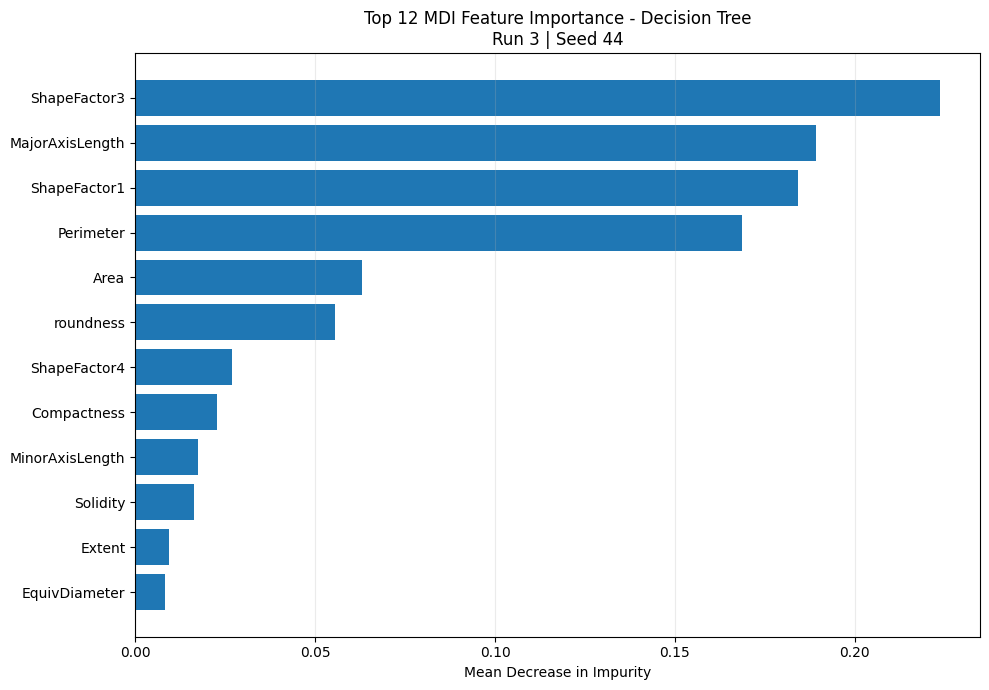


MDI FEATURE IMPORTANCE: Decision Tree


,feature,importance,rank,top_12
0,ShapeFactor3,0.223579,1,True
1,MajorAxisLength,0.189201,2,True
2,ShapeFactor1,0.184049,3,True
3,Perimeter,0.168583,4,True
4,Area,0.062899,5,True
5,roundness,0.055438,6,True
6,ShapeFactor4,0.027026,7,True
7,Compactness,0.022652,8,True
8,MinorAxisLength,0.017487,9,True
9,Solidity,0.016368,10,True


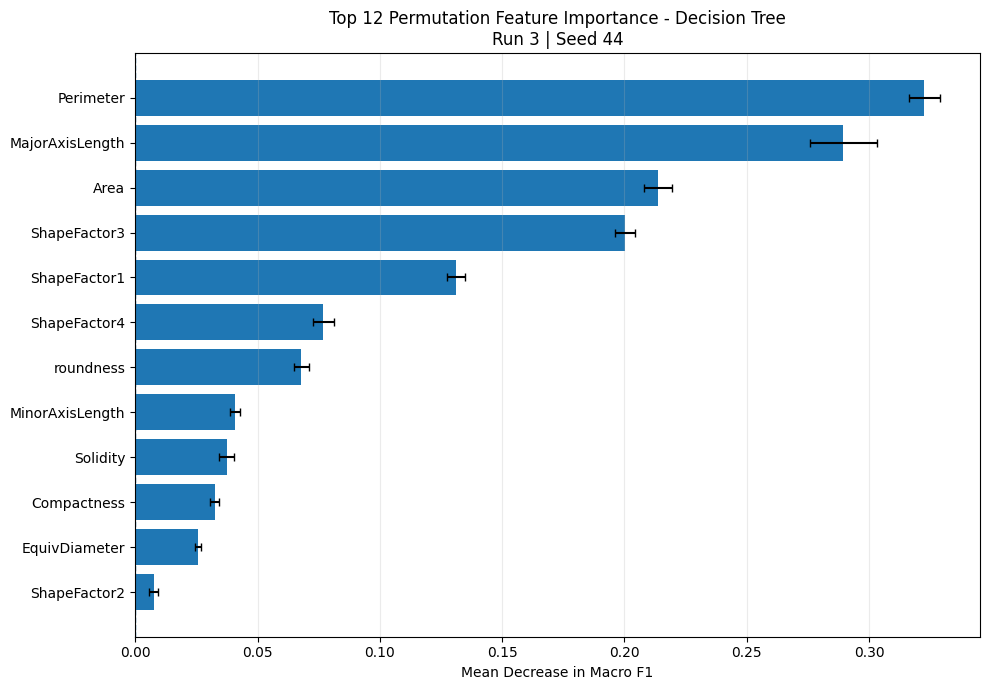


PERMUTATION FEATURE IMPORTANCE: Decision Tree


,feature,importance_mean,importance_std,rank,top_12
0,Perimeter,0.322614,0.006304,1,True
1,MajorAxisLength,0.289510,0.013682,2,True
2,Area,0.213703,0.005575,3,True
3,ShapeFactor3,0.200359,0.004137,4,True
4,ShapeFactor1,0.131224,0.003665,5,True
5,ShapeFactor4,0.076910,0.004156,6,True
6,roundness,0.067854,0.003062,7,True
7,MinorAxisLength,0.040786,0.002177,8,True
8,Solidity,0.037344,0.003164,9,True
9,Compactness,0.032549,0.001780,10,True


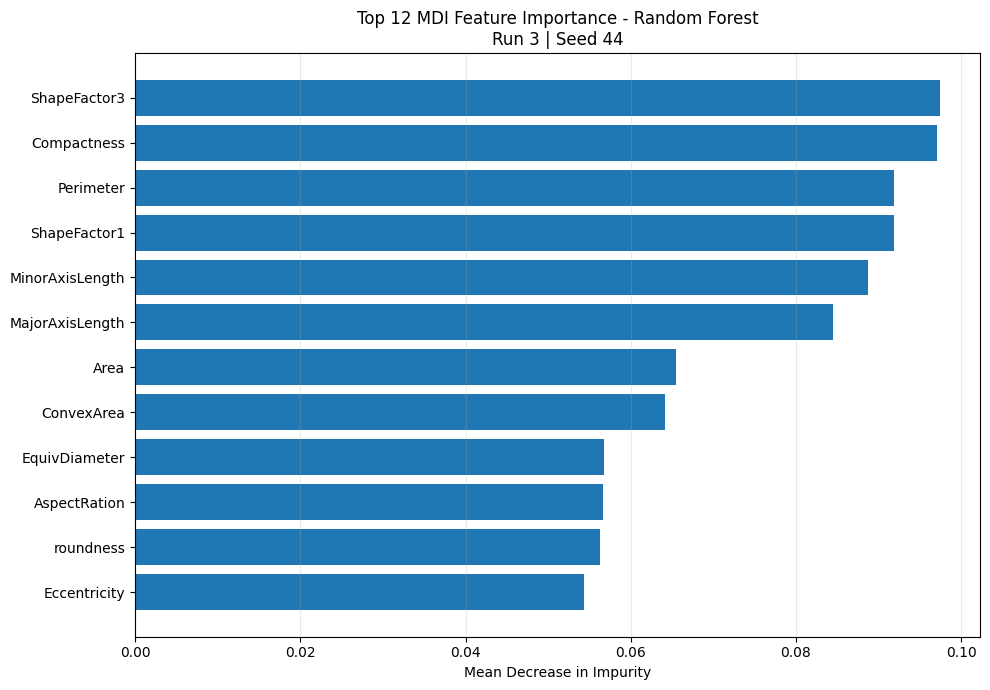


MDI FEATURE IMPORTANCE: Random Forest


,feature,importance,rank,top_12
0,ShapeFactor3,0.097419,1,True
1,Compactness,0.097078,2,True
2,Perimeter,0.091933,3,True
3,ShapeFactor1,0.091864,4,True
4,MinorAxisLength,0.088698,5,True
5,MajorAxisLength,0.084523,6,True
6,Area,0.065511,7,True
7,ConvexArea,0.064141,8,True
8,EquivDiameter,0.056775,9,True
9,AspectRation,0.056654,10,True


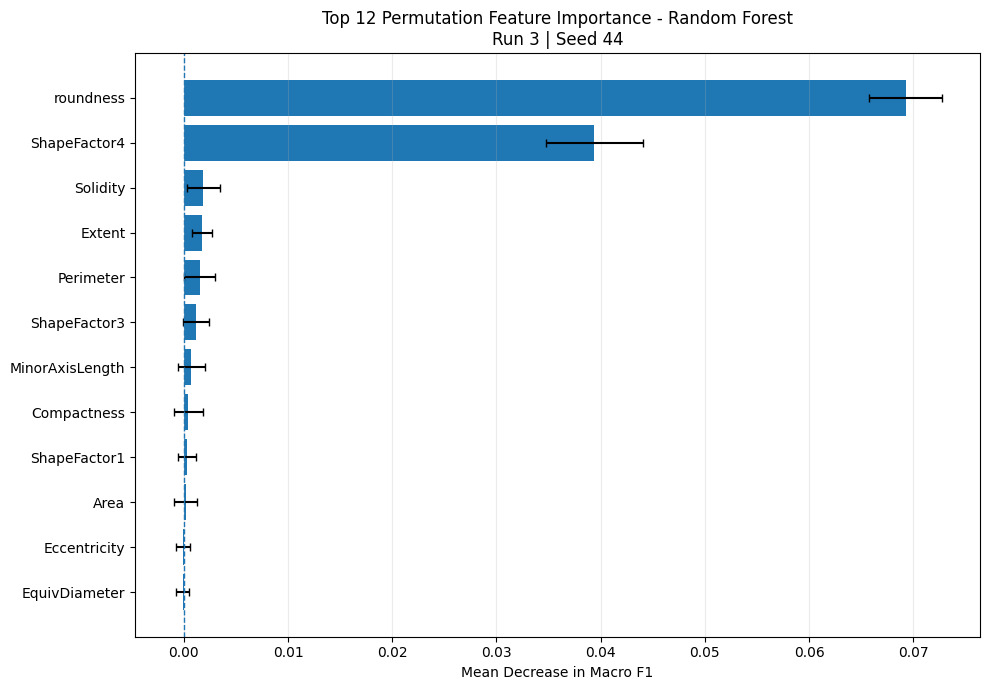


PERMUTATION FEATURE IMPORTANCE: Random Forest


,feature,importance_mean,importance_std,rank,top_12
0,roundness,0.069252,0.003463,1,True
1,ShapeFactor4,0.039407,0.004698,2,True
2,Solidity,0.001882,0.001567,3,True
3,Extent,0.001746,0.000985,4,True
4,Perimeter,0.001532,0.001469,5,True
5,ShapeFactor3,0.001149,0.001225,6,True
6,MinorAxisLength,0.000728,0.001264,7,True
7,Compactness,0.000416,0.001389,8,True
8,ShapeFactor1,0.000343,0.000859,9,True
9,Area,0.000167,0.001143,10,True



FEATURE IMPORTANCE: RUN 4/5 | RANDOM STATE: 45


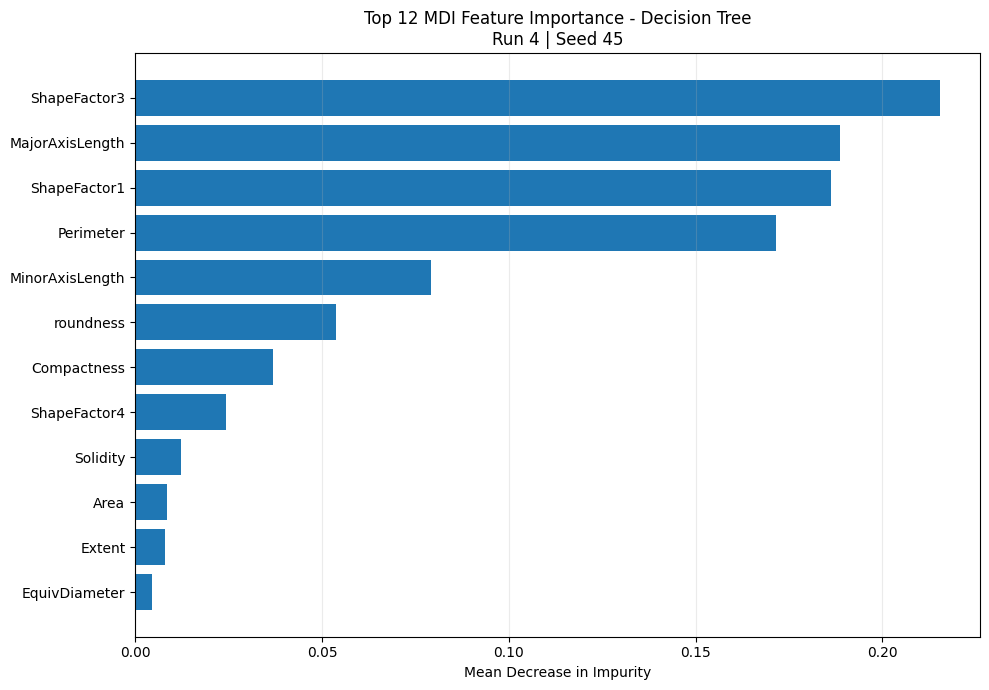


MDI FEATURE IMPORTANCE: Decision Tree


,feature,importance,rank,top_12
0,ShapeFactor3,0.215348,1,True
1,MajorAxisLength,0.188721,2,True
2,ShapeFactor1,0.186289,3,True
3,Perimeter,0.171626,4,True
4,MinorAxisLength,0.079041,5,True
5,roundness,0.053847,6,True
6,Compactness,0.036786,7,True
7,ShapeFactor4,0.024402,8,True
8,Solidity,0.012337,9,True
9,Area,0.008617,10,True


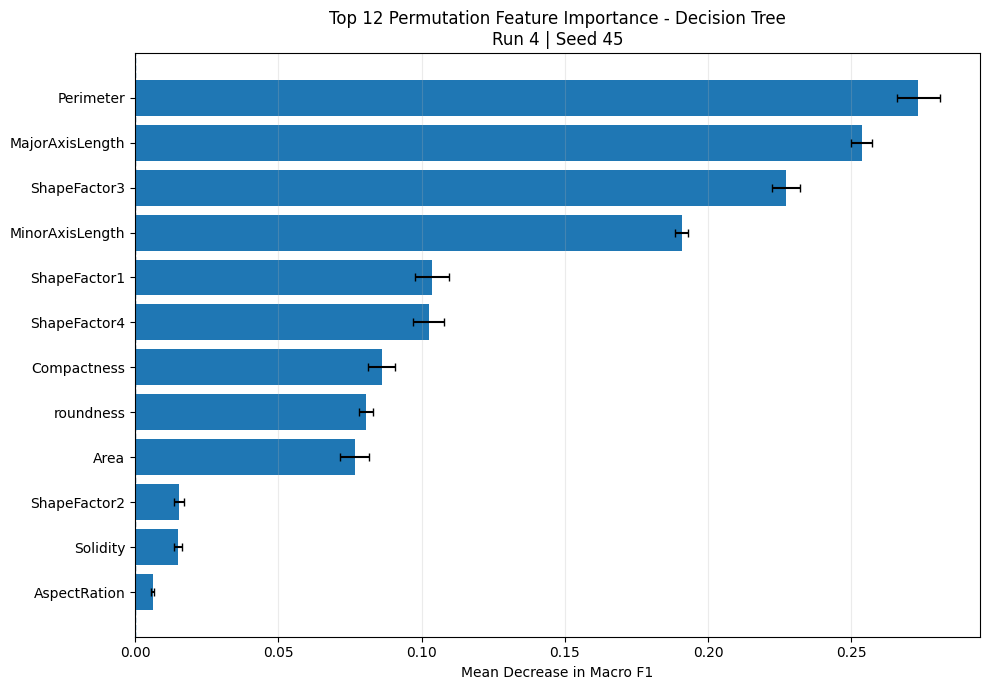


PERMUTATION FEATURE IMPORTANCE: Decision Tree


,feature,importance_mean,importance_std,rank,top_12
0,Perimeter,0.273322,0.007492,1,True
1,MajorAxisLength,0.253550,0.003569,2,True
2,ShapeFactor3,0.227124,0.004747,3,True
3,MinorAxisLength,0.190695,0.002403,4,True
4,ShapeFactor1,0.103608,0.005886,5,True
5,ShapeFactor4,0.102412,0.005341,6,True
6,Compactness,0.085981,0.004728,7,True
7,roundness,0.080576,0.002507,8,True
8,Area,0.076568,0.005091,9,True
9,ShapeFactor2,0.015182,0.001813,10,True


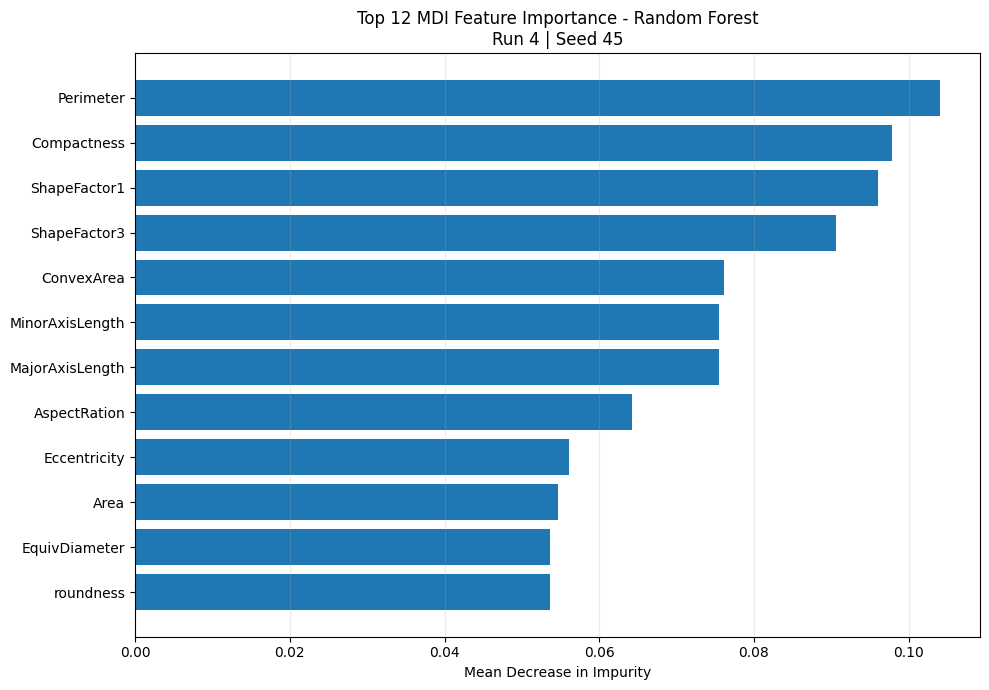


MDI FEATURE IMPORTANCE: Random Forest


,feature,importance,rank,top_12
0,Perimeter,0.104022,1,True
1,Compactness,0.097840,2,True
2,ShapeFactor1,0.095991,3,True
3,ShapeFactor3,0.090655,4,True
4,ConvexArea,0.076108,5,True
5,MinorAxisLength,0.075523,6,True
6,MajorAxisLength,0.075443,7,True
7,AspectRation,0.064251,8,True
8,Eccentricity,0.056050,9,True
9,Area,0.054598,10,True


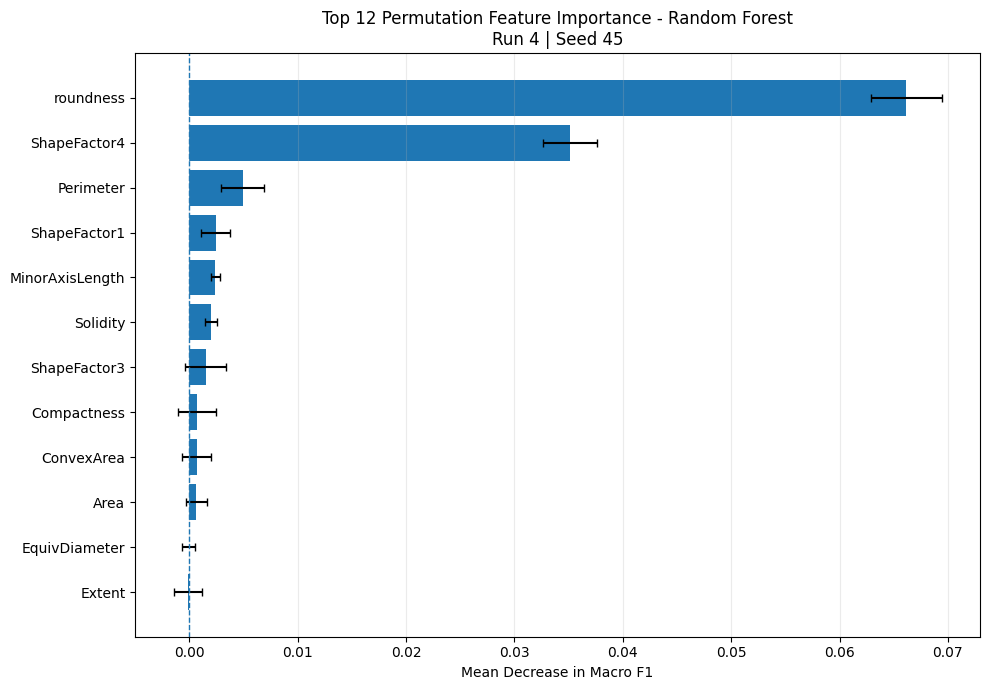


PERMUTATION FEATURE IMPORTANCE: Random Forest


,feature,importance_mean,importance_std,rank,top_12
0,roundness,0.066164,0.003252,1,True
1,ShapeFactor4,0.035122,0.002517,2,True
2,Perimeter,0.004923,0.001979,3,True
3,ShapeFactor1,0.002417,0.001304,4,True
4,MinorAxisLength,0.002383,0.000428,5,True
5,Solidity,0.001998,0.000587,6,True
6,ShapeFactor3,0.001495,0.001924,7,True
7,Compactness,0.000699,0.001724,8,True
8,ConvexArea,0.000670,0.001300,9,True
9,Area,0.000640,0.000983,10,True



FEATURE IMPORTANCE: RUN 5/5 | RANDOM STATE: 46


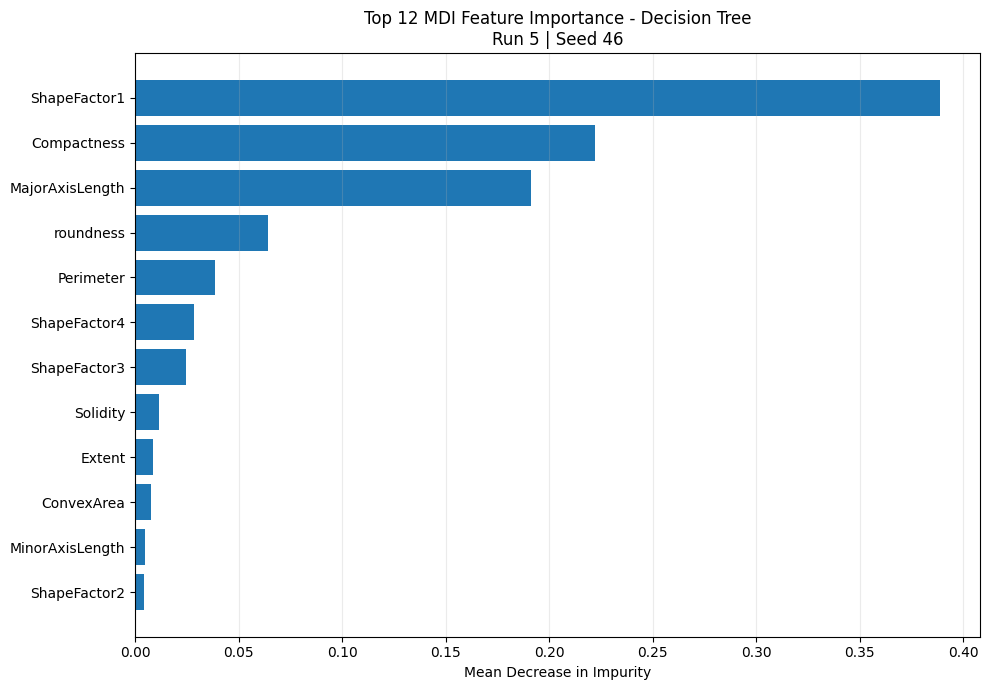


MDI FEATURE IMPORTANCE: Decision Tree


,feature,importance,rank,top_12
0,ShapeFactor1,0.388554,1,True
1,Compactness,0.222142,2,True
2,MajorAxisLength,0.191259,3,True
3,roundness,0.064313,4,True
4,Perimeter,0.038628,5,True
5,ShapeFactor4,0.028484,6,True
6,ShapeFactor3,0.024624,7,True
7,Solidity,0.011541,8,True
8,Extent,0.008487,9,True
9,ConvexArea,0.007446,10,True


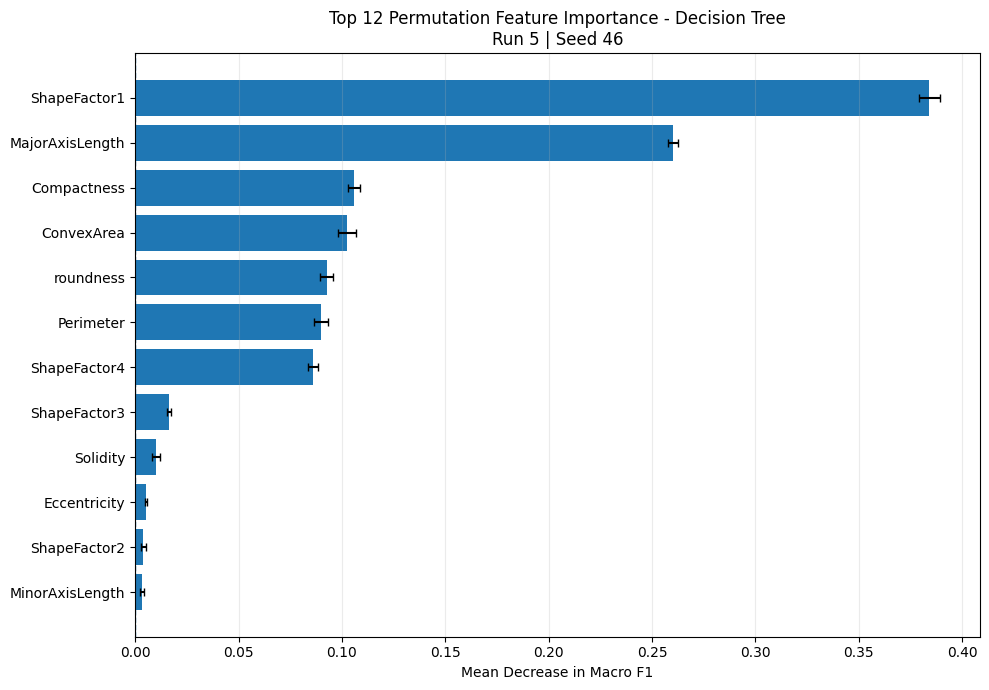


PERMUTATION FEATURE IMPORTANCE: Decision Tree


,feature,importance_mean,importance_std,rank,top_12
0,ShapeFactor1,0.384115,0.005124,1,True
1,MajorAxisLength,0.260110,0.002334,2,True
2,Compactness,0.105884,0.002788,3,True
3,ConvexArea,0.102366,0.004305,4,True
4,roundness,0.092557,0.003207,5,True
5,Perimeter,0.089820,0.003379,6,True
6,ShapeFactor4,0.085991,0.002199,7,True
7,ShapeFactor3,0.016430,0.000993,8,True
8,Solidity,0.010211,0.001908,9,True
9,Eccentricity,0.005048,0.000478,10,True


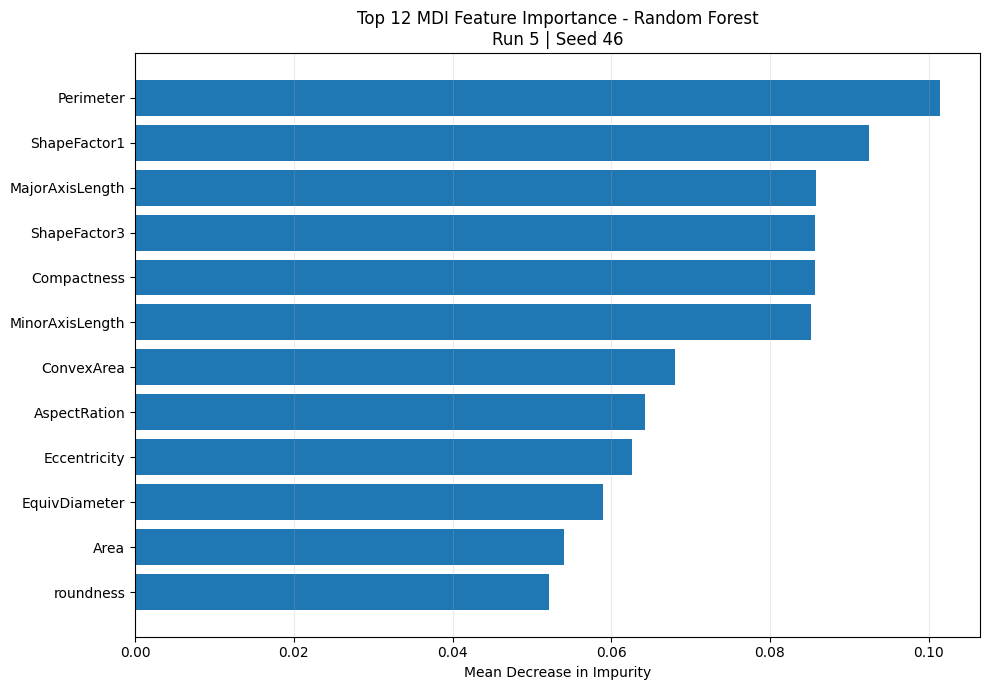


MDI FEATURE IMPORTANCE: Random Forest


,feature,importance,rank,top_12
0,Perimeter,0.101416,1,True
1,ShapeFactor1,0.092466,2,True
2,MajorAxisLength,0.085772,3,True
3,ShapeFactor3,0.085665,4,True
4,Compactness,0.085663,5,True
5,MinorAxisLength,0.085244,6,True
6,ConvexArea,0.068023,7,True
7,AspectRation,0.064211,8,True
8,Eccentricity,0.062574,9,True
9,EquivDiameter,0.058911,10,True


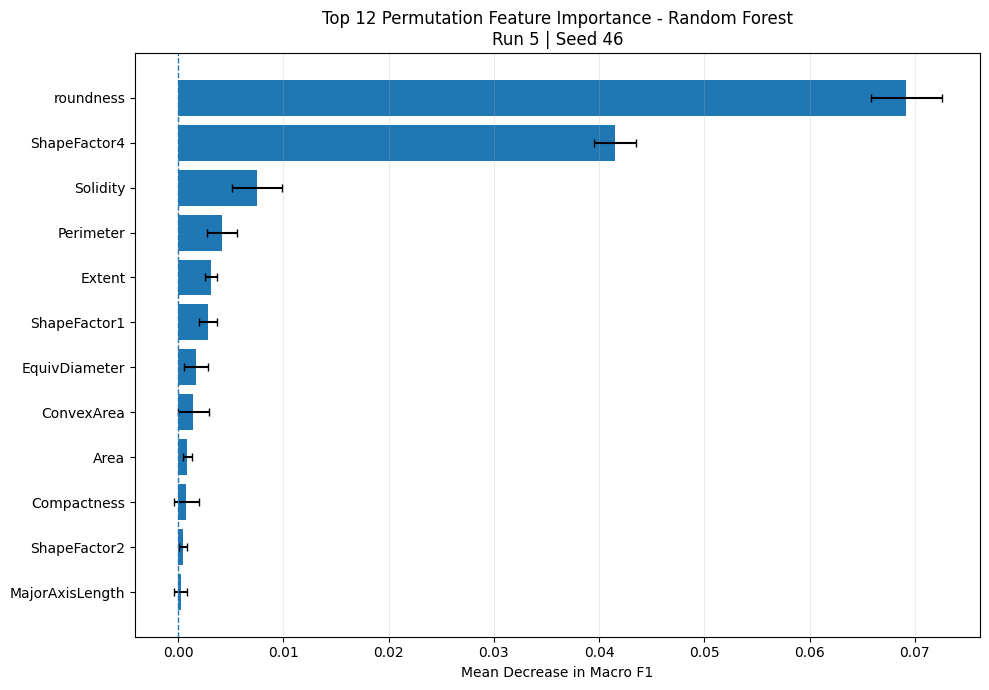


PERMUTATION FEATURE IMPORTANCE: Random Forest


,feature,importance_mean,importance_std,rank,top_12
0,roundness,0.069164,0.003369,1,True
1,ShapeFactor4,0.041503,0.002027,2,True
2,Solidity,0.007508,0.002397,3,True
3,Perimeter,0.004207,0.001413,4,True
4,Extent,0.003137,0.000562,5,True
5,ShapeFactor1,0.002849,0.000817,6,True
6,EquivDiameter,0.001734,0.001145,7,True
7,ConvexArea,0.001449,0.001482,8,True
8,Area,0.000885,0.000411,9,True
9,Compactness,0.000806,0.001184,10,True



ALL FIVE-RUN MDI FEATURE IMPORTANCE RESULTS


,run,random_state,model,feature,importance,rank,top_12
0,1,42,Decision Tree,ShapeFactor1,0.242866,1,True
1,1,42,Decision Tree,Compactness,0.201646,2,True
2,1,42,Decision Tree,MajorAxisLength,0.193621,3,True
3,1,42,Decision Tree,Perimeter,0.158197,4,True
4,1,42,Decision Tree,roundness,0.070330,5,True
...,...,...,...,...,...,...,...
155,5,46,Random Forest,roundness,0.052194,12,True
156,5,46,Random Forest,ShapeFactor2,0.042106,13,False
157,5,46,Random Forest,ShapeFactor4,0.031310,14,False
158,5,46,Random Forest,Solidity,0.018596,15,False



FIVE-RUN MDI FEATURE IMPORTANCE SUMMARY


,model,feature,mean_importance,std_importance,mean_rank,std_rank,top_12_runs,top_12_frequency_pct
0,Decision Tree,ShapeFactor1,0.27758,0.10294,1.8,1.09545,5,100.0
1,Decision Tree,MajorAxisLength,0.19181,0.00315,2.4,0.54772,5,100.0
2,Decision Tree,Compactness,0.13035,0.09397,4.4,2.88097,5,100.0
3,Decision Tree,ShapeFactor3,0.11633,0.09626,3.8,2.77489,5,100.0
4,Decision Tree,Perimeter,0.11395,0.07166,4.6,0.89443,5,100.0
5,Decision Tree,roundness,0.06062,0.00676,5.2,0.83666,5,100.0
6,Decision Tree,MinorAxisLength,0.02750,0.03074,8.6,2.60768,5,100.0
7,Decision Tree,ShapeFactor4,0.02630,0.00360,7.2,0.83666,5,100.0
8,Decision Tree,Area,0.01682,0.02608,11.2,4.43847,3,60.0
9,Decision Tree,Solidity,0.01431,0.00230,8.8,0.83666,5,100.0



ALL FIVE-RUN PERMUTATION IMPORTANCE RESULTS


,run,random_state,model,feature,importance_mean,importance_std,rank,top_12
0,1,42,Decision Tree,Perimeter,0.288610,0.015300,1,True
1,1,42,Decision Tree,MajorAxisLength,0.281640,0.012596,2,True
2,1,42,Decision Tree,ShapeFactor1,0.253795,0.004157,3,True
3,1,42,Decision Tree,Compactness,0.176691,0.005072,4,True
4,1,42,Decision Tree,ShapeFactor3,0.136572,0.005120,5,True
...,...,...,...,...,...,...,...,...
155,5,46,Random Forest,MajorAxisLength,0.000242,0.000654,12,True
156,5,46,Random Forest,MinorAxisLength,0.000207,0.001169,13,False
157,5,46,Random Forest,AspectRation,-0.000507,0.000472,14,False
158,5,46,Random Forest,ShapeFactor3,-0.001003,0.000405,15,False



FIVE-RUN PERMUTATION IMPORTANCE SUMMARY


,model,feature,mean_importance,std_importance_across_runs,mean_within_run_std,mean_rank,std_rank,top_12_runs,top_12_frequency_pct
0,Decision Tree,MajorAxisLength,0.27670,0.01926,0.00826,2.0,0.00000,5,100.0
1,Decision Tree,ShapeFactor1,0.24688,0.12841,0.00469,3.0,2.00000,5,100.0
2,Decision Tree,Perimeter,0.22134,0.10332,0.00733,2.8,2.48998,5,100.0
3,Decision Tree,ShapeFactor3,0.14370,0.08132,0.00386,4.8,1.92354,5,100.0
4,Decision Tree,Compactness,0.11151,0.05741,0.00372,5.4,3.04959,5,100.0
5,Decision Tree,roundness,0.08889,0.01699,0.00305,6.4,1.14018,5,100.0
6,Decision Tree,ShapeFactor4,0.08779,0.00928,0.00412,6.6,0.54772,5,100.0
7,Decision Tree,Area,0.07317,0.08657,0.00261,10.0,4.79583,3,60.0
8,Decision Tree,MinorAxisLength,0.06365,0.07617,0.00174,8.4,2.96648,5,100.0
9,Decision Tree,ConvexArea,0.02346,0.04417,0.00134,12.2,4.71169,1,20.0


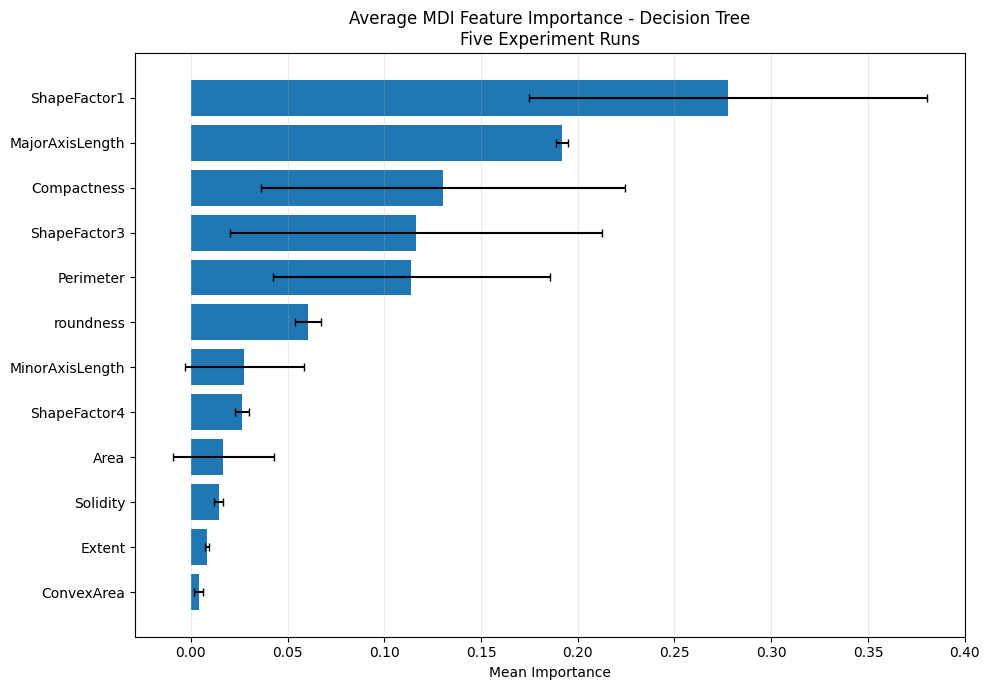

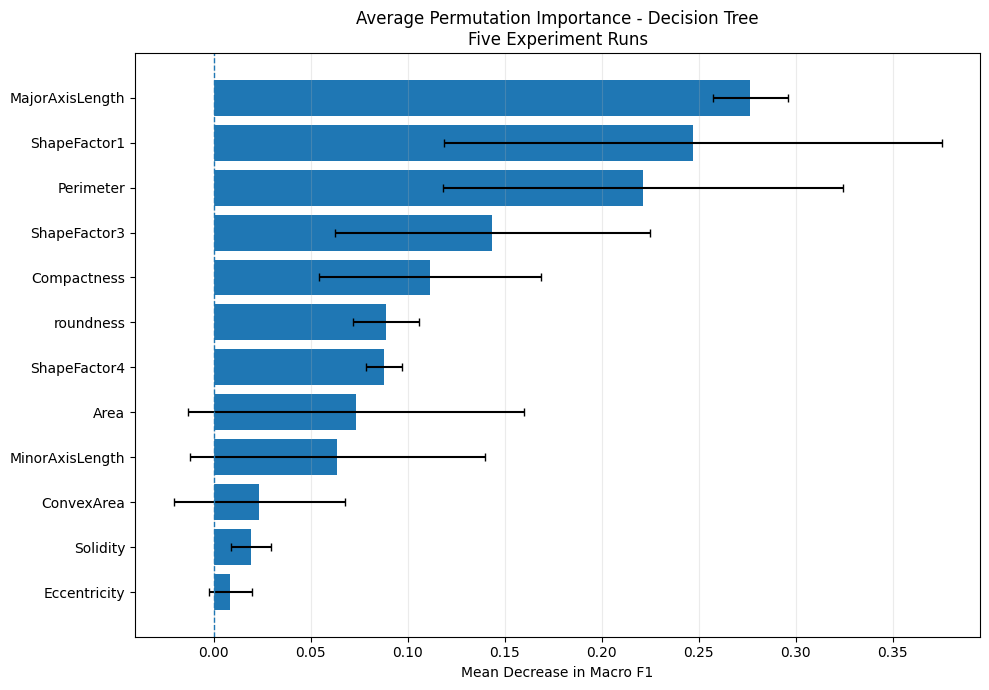

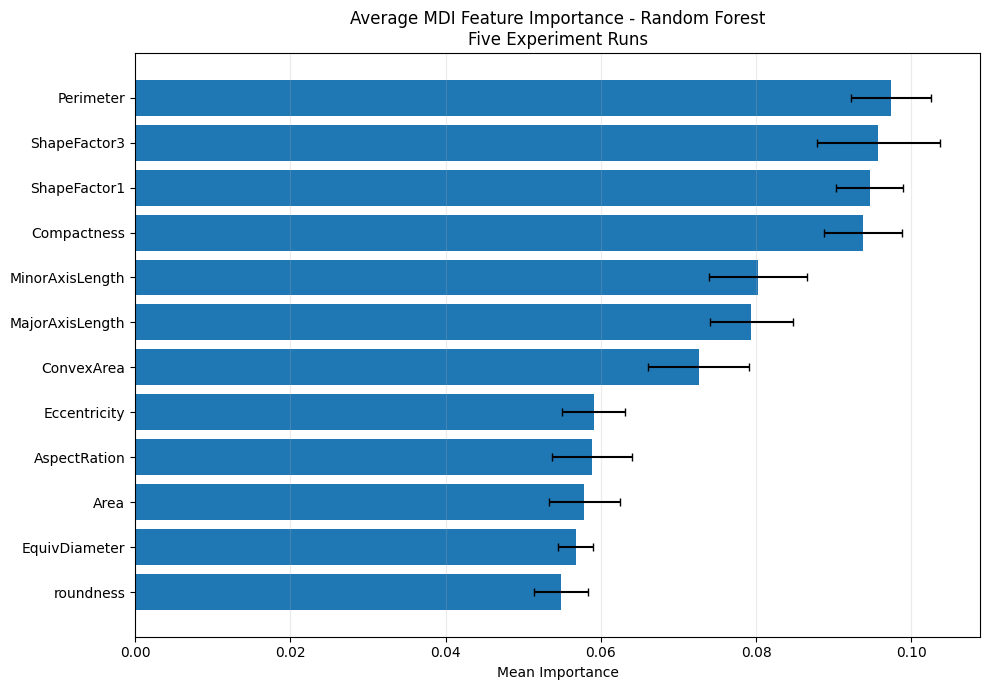

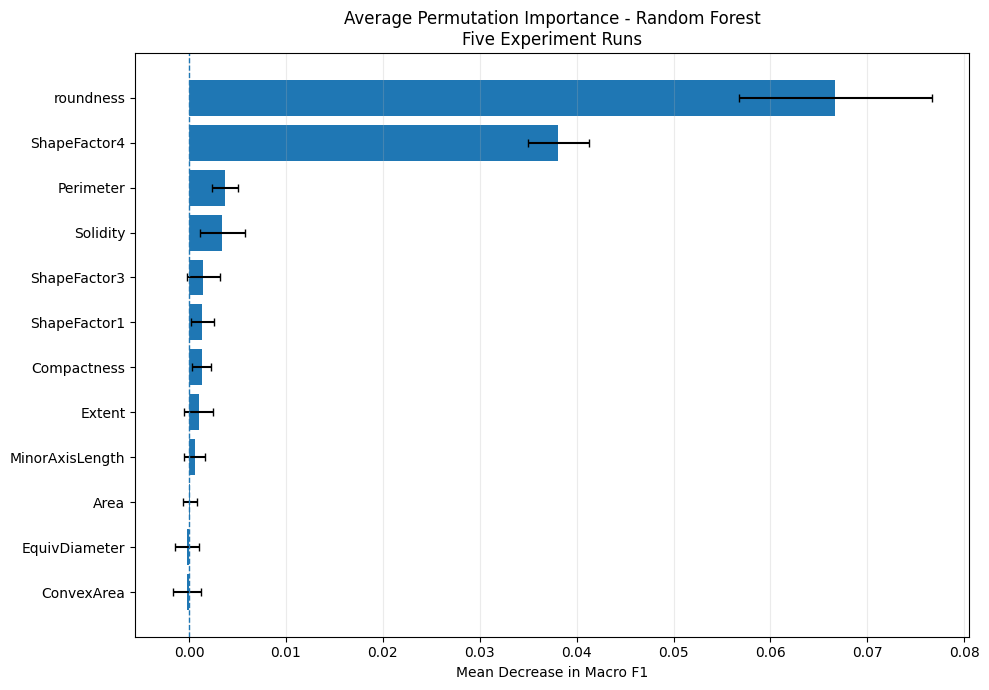


SECTION 13: FIVE-RUN FEATURE IMPORTANCE COMPLETED
Total experiment runs          : 5
Total algorithms               : 2
Total models analyzed          : 10
Total features                 : 16
Total MDI records              : 160
Total permutation records      : 160
Permutation repetitions        : 5

MAIN OUTPUT FILES:
- five_run_mdi_importance_all.csv
- five_run_mdi_importance_summary.csv
- five_run_permutation_importance_all.csv
- five_run_permutation_importance_summary.csv
- mean_mdi_importance_decision_tree.png
- mean_mdi_importance_random_forest.png
- mean_permutation_importance_decision_tree.png
- mean_permutation_importance_random_forest.png

Output directory: /content/Dry_Bean_Classification_Submission/outputs/repeated_runs

SECTION 13 BERHASIL DIJALANKAN.
Seluruh hasil feature importance lima putaran berhasil disiapkan.


In [13]:

# ============================================================
# SECTION 13: FIVE-RUN FEATURE IMPORTANCE ANALYSIS
# ============================================================

# ------------------------------------------------------------
# A. IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

from pathlib import Path  # Mengimpor Path untuk mengatur lokasi penyimpanan hasil analisis.

import numpy as np  # Mengimpor NumPy untuk operasi numerik dan perhitungan statistik.

import pandas as pd  # Mengimpor Pandas untuk mengolah tabel feature importance.

import matplotlib.pyplot as plt  # Mengimpor Matplotlib untuk membuat grafik feature importance.

from sklearn.inspection import permutation_importance  # Mengimpor metode permutation importance untuk mengukur kontribusi fitur terhadap performa prediksi.


# ------------------------------------------------------------
# B. VALIDATE REQUIRED VARIABLES
# ------------------------------------------------------------

# Menentukan variabel yang harus tersedia dari Section sebelumnya.
required_variables = [
    'RUN_SEEDS',
    'tuned_models_by_run',
    'run_data_by_seed',
    'feature_cols',
    'REPEATED_OUTPUT_DIR',
    'REPEATED_EVIDENCE_DIR'
]

# Memeriksa variabel yang belum tersedia.
missing_variables = [
    variable for variable in required_variables
    if variable not in globals()
]

# Menghentikan proses apabila terdapat variabel yang belum tersedia.
if missing_variables:
    raise NameError(
        f'Variabel yang belum tersedia: {missing_variables}. '
        'Jalankan Section 9 dan Section 10 terlebih dahulu.'
    )

# Menentukan nama algoritma yang akan dianalisis.
MODEL_NAMES = [
    'Decision Tree',
    'Random Forest'
]

# Menentukan jumlah pengulangan permutation importance.
PERMUTATION_REPEATS = 5

# Menentukan metrik evaluasi untuk permutation importance.
PERMUTATION_SCORING = 'f1_macro'

# Mengubah daftar fitur menjadi list agar urutannya konsisten.
feature_cols = list(feature_cols)

# Memastikan jumlah fitur sesuai dengan dataset.
if len(feature_cols) == 0:
    raise ValueError('Daftar fitur kosong. Periksa kembali Section 3.')

# Memastikan setiap putaran memiliki model dan data testing.
for seed in RUN_SEEDS:

    if seed not in tuned_models_by_run:
        raise KeyError(f'Model pada seed {seed} tidak ditemukan.')

    if seed not in run_data_by_seed:
        raise KeyError(f'Data eksperimen seed {seed} tidak ditemukan.')

    for name in MODEL_NAMES:

        if name not in tuned_models_by_run[seed]:
            raise KeyError(
                f'Model {name} pada seed {seed} tidak ditemukan.'
            )

# Memastikan folder penyimpanan tersedia.
REPEATED_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

REPEATED_EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# C. PREPARE FEATURE IMPORTANCE STORAGE
# ------------------------------------------------------------

# Menyimpan hasil MDI feature importance setiap putaran.
feature_importance_tables_by_run = {}

# Menyimpan hasil permutation importance setiap putaran.
permutation_importance_tables_by_run = {}

# Menyiapkan list untuk menggabungkan seluruh hasil MDI.
mdi_importance_rows = []

# Menyiapkan list untuk menggabungkan seluruh hasil permutation importance.
permutation_importance_rows = []

# Menampilkan konfigurasi analisis.
print('FEATURE IMPORTANCE CONFIGURATION')

print(f'Total experiment runs : {len(RUN_SEEDS)}')

print(f'Total algorithms      : {len(MODEL_NAMES)}')

print(f'Total features         : {len(feature_cols)}')

print(f'Permutation repeats   : {PERMUTATION_REPEATS}')

print(f'Permutation scoring   : {PERMUTATION_SCORING}')


# ------------------------------------------------------------
# D. FEATURE IMPORTANCE ANALYSIS FOR FIVE RUNS
# ------------------------------------------------------------

# Melakukan analisis feature importance pada lima putaran eksperimen.
for run_number, seed in enumerate(RUN_SEEDS, start=1):

    # Menampilkan identitas putaran yang sedang dianalisis.
    print('\n' + '=' * 70)

    print(f'FEATURE IMPORTANCE: RUN {run_number}/5 | RANDOM STATE: {seed}')

    print('=' * 70)

    # Mengambil data testing pada putaran saat ini.
    X_test_run = run_data_by_seed[seed]['X_test']

    # Mengambil label testing pada putaran saat ini.
    y_test_run = run_data_by_seed[seed]['y_test']

    # Membuat dictionary untuk menyimpan hasil MDI pada putaran ini.
    feature_importance_tables_by_run[seed] = {}

    # Membuat dictionary untuk menyimpan hasil permutation pada putaran ini.
    permutation_importance_tables_by_run[seed] = {}

    # Menentukan folder penyimpanan hasil putaran saat ini.
    run_output_dir = (
        REPEATED_OUTPUT_DIR / f'run_{run_number}_seed_{seed}'
    )

    # Menentukan folder penyimpanan bukti putaran saat ini.
    run_evidence_dir = (
        REPEATED_EVIDENCE_DIR / f'run_{run_number}_seed_{seed}'
    )

    # Memastikan folder tersedia.
    run_output_dir.mkdir(parents=True, exist_ok=True)

    run_evidence_dir.mkdir(parents=True, exist_ok=True)


    # --------------------------------------------------------
    # D1. ANALYZE EACH CLASSIFICATION MODEL
    # --------------------------------------------------------

    # Melakukan analisis terhadap Decision Tree dan Random Forest.
    for name in MODEL_NAMES:

        # Mengambil model hasil training dari Section 10.
        model = tuned_models_by_run[seed][name]

        # Mengubah nama model menjadi format aman untuk nama file.
        safe = name.lower().replace(' ', '_')

        # Memastikan jumlah fitur model sesuai dengan daftar fitur.
        if model.n_features_in_ != len(feature_cols):
            raise ValueError(
                f'Jumlah fitur model {name} pada seed {seed} tidak sesuai.'
            )


        # ----------------------------------------------------
        # D2. IMPURITY-BASED FEATURE IMPORTANCE (MDI)
        # ----------------------------------------------------

        # Mengambil nilai feature importance dari model yang sudah dilatih.
        mdi_values = np.asarray(
            model.feature_importances_,
            dtype=float
        )

        # Memastikan jumlah nilai importance sesuai dengan jumlah fitur.
        assert len(mdi_values) == len(feature_cols)

        # Memastikan nilai importance tidak mengandung NaN atau infinity.
        assert np.isfinite(mdi_values).all()

        # Membuat DataFrame yang berisi nama fitur dan nilai importance.
        imp = pd.DataFrame({
            'feature': feature_cols,
            'importance': mdi_values
        })

        # Memberikan peringkat berdasarkan nilai importance tertinggi.
        imp['rank'] = (
            imp['importance']
            .rank(method='min', ascending=False)
            .astype(int)
        )

        # Menandai fitur yang masuk dalam 12 peringkat teratas.
        imp['top_12'] = imp['rank'] <= 12

        # Mengurutkan fitur berdasarkan importance tertinggi.
        imp = imp.sort_values(
            'importance',
            ascending=False
        ).reset_index(drop=True)

        # Menyimpan tabel MDI berdasarkan seed dan algoritma.
        feature_importance_tables_by_run[seed][name] = imp.copy()

        # Menambahkan informasi putaran dan model ke setiap baris.
        for _, row in imp.iterrows():

            mdi_importance_rows.append({
                'run': run_number,
                'random_state': seed,
                'model': name,
                'feature': row['feature'],
                'importance': row['importance'],
                'rank': row['rank'],
                'top_12': row['top_12']
            })

        # Menyimpan seluruh hasil MDI ke folder outputs putaran.
        imp.to_csv(
            run_output_dir / f'feature_importance_mdi_{safe}.csv',
            index=False
        )


        # ----------------------------------------------------
        # D3. VISUALIZE MDI FEATURE IMPORTANCE
        # ----------------------------------------------------

        # Mengambil 12 fitur dengan importance tertinggi.
        top_mdi = imp.head(12).sort_values(
            'importance',
            ascending=True
        )

        # Membuat area grafik horizontal.
        fig, ax = plt.subplots(figsize=(10, 7))

        # Membuat grafik batang horizontal feature importance.
        ax.barh(
            top_mdi['feature'],
            top_mdi['importance']
        )

        # Memberikan judul grafik.
        ax.set_title(
            f'Top 12 MDI Feature Importance - {name}\n'
            f'Run {run_number} | Seed {seed}'
        )

        # Memberikan label sumbu horizontal.
        ax.set_xlabel('Mean Decrease in Impurity')

        # Menambahkan garis bantu pada sumbu horizontal.
        ax.grid(
            axis='x',
            alpha=0.25
        )

        # Mengatur tata letak grafik.
        fig.tight_layout()

        # Menyimpan grafik MDI ke folder outputs.
        fig.savefig(
            run_output_dir / f'feature_importance_mdi_{safe}.png',
            dpi=180,
            bbox_inches='tight'
        )

        # Menampilkan grafik pada Google Colab.
        plt.show()

        # Menutup figure untuk menghemat memori.
        plt.close(fig)

        # Menampilkan 12 fitur terpenting.
        print(f'\nMDI FEATURE IMPORTANCE: {name}')

        display(imp.head(12))


        # ----------------------------------------------------
        # D4. PERMUTATION FEATURE IMPORTANCE
        # ----------------------------------------------------

        # Menghitung permutation importance menggunakan data testing.
        # Fitur diacak satu per satu untuk mengukur penurunan Macro F1.
        permutation_result = permutation_importance(
            model,
            X_test_run,
            y_test_run,
            scoring=PERMUTATION_SCORING,
            n_repeats=PERMUTATION_REPEATS,
            random_state=seed,
            n_jobs=1
        )

        # Membuat DataFrame hasil permutation importance.
        permutation_df = pd.DataFrame({

            'feature': feature_cols,

            'importance_mean': permutation_result.importances_mean,

            'importance_std': permutation_result.importances_std

        })

        # Memberikan peringkat berdasarkan rata-rata importance tertinggi.
        permutation_df['rank'] = (
            permutation_df['importance_mean']
            .rank(method='min', ascending=False)
            .astype(int)
        )

        # Menandai fitur yang termasuk dalam 12 peringkat teratas.
        permutation_df['top_12'] = (
            permutation_df['rank'] <= 12
        )

        # Mengurutkan hasil berdasarkan rata-rata importance tertinggi.
        permutation_df = permutation_df.sort_values(
            'importance_mean',
            ascending=False
        ).reset_index(drop=True)

        # Menyimpan hasil permutation importance berdasarkan seed dan model.
        permutation_importance_tables_by_run[seed][name] = (
            permutation_df.copy()
        )

        # Menambahkan hasil permutation ke dalam daftar keseluruhan.
        for _, row in permutation_df.iterrows():

            permutation_importance_rows.append({

                'run': run_number,

                'random_state': seed,

                'model': name,

                'feature': row['feature'],

                'importance_mean': row['importance_mean'],

                'importance_std': row['importance_std'],

                'rank': row['rank'],

                'top_12': row['top_12']

            })

        # Menyimpan hasil permutation importance ke folder outputs.
        permutation_df.to_csv(
            run_output_dir / f'permutation_importance_{safe}.csv',
            index=False
        )


        # ----------------------------------------------------
        # D5. VISUALIZE PERMUTATION IMPORTANCE
        # ----------------------------------------------------

        # Mengambil 12 fitur dengan permutation importance tertinggi.
        top_permutation = permutation_df.head(12).sort_values(
            'importance_mean',
            ascending=True
        )

        # Membuat area grafik permutation importance.
        fig, ax = plt.subplots(figsize=(10, 7))

        # Membuat grafik batang horizontal dengan error bar.
        ax.barh(
            top_permutation['feature'],
            top_permutation['importance_mean'],
            xerr=top_permutation['importance_std'],
            capsize=3
        )

        # Memberikan garis vertikal pada nilai nol.
        ax.axvline(
            x=0,
            linewidth=1,
            linestyle='--'
        )

        # Memberikan judul grafik.
        ax.set_title(
            f'Top 12 Permutation Feature Importance - {name}\n'
            f'Run {run_number} | Seed {seed}'
        )

        # Memberikan label sumbu horizontal.
        ax.set_xlabel('Mean Decrease in Macro F1')

        # Menambahkan garis bantu horizontal.
        ax.grid(
            axis='x',
            alpha=0.25
        )

        # Mengatur tata letak grafik.
        fig.tight_layout()

        # Menyimpan grafik permutation importance.
        fig.savefig(
            run_output_dir / f'permutation_importance_{safe}.png',
            dpi=180,
            bbox_inches='tight'
        )

        # Menampilkan grafik pada Google Colab.
        plt.show()

        # Menutup figure untuk menghemat memori.
        plt.close(fig)

        # Menampilkan tabel permutation importance.
        print(f'\nPERMUTATION FEATURE IMPORTANCE: {name}')

        display(permutation_df.head(12))


# ------------------------------------------------------------
# E. COMBINE ALL MDI FEATURE IMPORTANCE RESULTS
# ------------------------------------------------------------

# Menggabungkan hasil MDI dari seluruh putaran menjadi satu DataFrame.
mdi_importance_all = pd.DataFrame(
    mdi_importance_rows
)

# Menampilkan seluruh hasil MDI.
print('\nALL FIVE-RUN MDI FEATURE IMPORTANCE RESULTS')

display(mdi_importance_all)


# ------------------------------------------------------------
# F. CALCULATE MDI IMPORTANCE STABILITY
# ------------------------------------------------------------

# Menghitung rata-rata, standar deviasi, dan kestabilan peringkat MDI.
mdi_importance_summary = (
    mdi_importance_all
    .groupby(['model', 'feature'])
    .agg(
        mean_importance=('importance', 'mean'),
        std_importance=('importance', 'std'),
        mean_rank=('rank', 'mean'),
        std_rank=('rank', 'std'),
        top_12_runs=('top_12', 'sum')
    )
    .reset_index()
)

# Menghitung persentase kemunculan fitur dalam 12 besar.
mdi_importance_summary['top_12_frequency_pct'] = (
    mdi_importance_summary['top_12_runs']
    / len(RUN_SEEDS)
    * 100
)

# Mengurutkan hasil berdasarkan algoritma dan importance rata-rata.
mdi_importance_summary = mdi_importance_summary.sort_values(
    by=['model', 'mean_importance'],
    ascending=[True, False]
).reset_index(drop=True)

# Menampilkan ringkasan kestabilan MDI.
print('\nFIVE-RUN MDI FEATURE IMPORTANCE SUMMARY')

display(
    mdi_importance_summary.round(5)
)

# Menyimpan ringkasan MDI lima putaran.
mdi_importance_summary.to_csv(
    REPEATED_OUTPUT_DIR / 'five_run_mdi_importance_summary.csv',
    index=False
)


# ------------------------------------------------------------
# G. COMBINE ALL PERMUTATION IMPORTANCE RESULTS
# ------------------------------------------------------------

# Menggabungkan hasil permutation importance dari seluruh putaran.
permutation_importance_all = pd.DataFrame(
    permutation_importance_rows
)

# Menampilkan seluruh hasil permutation importance.
print('\nALL FIVE-RUN PERMUTATION IMPORTANCE RESULTS')

display(permutation_importance_all)


# ------------------------------------------------------------
# H. CALCULATE PERMUTATION IMPORTANCE STABILITY
# ------------------------------------------------------------

# Menghitung rata-rata dan kestabilan permutation importance.
permutation_importance_summary = (
    permutation_importance_all
    .groupby(['model', 'feature'])
    .agg(
        mean_importance=('importance_mean', 'mean'),
        std_importance_across_runs=('importance_mean', 'std'),
        mean_within_run_std=('importance_std', 'mean'),
        mean_rank=('rank', 'mean'),
        std_rank=('rank', 'std'),
        top_12_runs=('top_12', 'sum')
    )
    .reset_index()
)

# Menghitung persentase kemunculan fitur dalam 12 besar.
permutation_importance_summary['top_12_frequency_pct'] = (
    permutation_importance_summary['top_12_runs']
    / len(RUN_SEEDS)
    * 100
)

# Mengurutkan hasil berdasarkan algoritma dan rata-rata importance.
permutation_importance_summary = (
    permutation_importance_summary
    .sort_values(
        by=['model', 'mean_importance'],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

# Menampilkan ringkasan permutation importance lima putaran.
print('\nFIVE-RUN PERMUTATION IMPORTANCE SUMMARY')

display(
    permutation_importance_summary.round(5)
)

# Menyimpan ringkasan permutation importance.
permutation_importance_summary.to_csv(
    REPEATED_OUTPUT_DIR / 'five_run_permutation_importance_summary.csv',
    index=False
)


# ------------------------------------------------------------
# I. CREATE AGGREGATED FEATURE IMPORTANCE VISUALIZATIONS
# ------------------------------------------------------------

# Membuat grafik ringkasan untuk setiap algoritma.
for name in MODEL_NAMES:

    # Menentukan nama file yang aman.
    safe = name.lower().replace(' ', '_')

    # --------------------------------------------------------
    # I1. MEAN MDI IMPORTANCE
    # --------------------------------------------------------

    # Mengambil hasil MDI untuk algoritma saat ini.
    model_mdi_summary = mdi_importance_summary.loc[
        mdi_importance_summary['model'] == name
    ].copy()

    # Mengambil 12 fitur berdasarkan rata-rata MDI tertinggi.
    top_mdi_mean = model_mdi_summary.nlargest(
        12,
        'mean_importance'
    ).sort_values('mean_importance')

    # Membuat grafik rata-rata MDI.
    fig, ax = plt.subplots(figsize=(10, 7))

    # Membuat grafik batang horizontal.
    ax.barh(
        top_mdi_mean['feature'],
        top_mdi_mean['mean_importance'],
        xerr=top_mdi_mean['std_importance'].fillna(0),
        capsize=3
    )

    # Memberikan judul grafik.
    ax.set_title(
        f'Average MDI Feature Importance - {name}\n'
        f'Five Experiment Runs'
    )

    # Memberikan label sumbu horizontal.
    ax.set_xlabel('Mean Importance')

    # Menambahkan garis bantu.
    ax.grid(axis='x', alpha=0.25)

    # Mengatur tata letak.
    fig.tight_layout()

    # Menyimpan grafik rata-rata MDI.
    fig.savefig(
        REPEATED_OUTPUT_DIR / f'mean_mdi_importance_{safe}.png',
        dpi=180,
        bbox_inches='tight'
    )

    # Menampilkan grafik.
    plt.show()

    # Menutup figure.
    plt.close(fig)


    # --------------------------------------------------------
    # I2. MEAN PERMUTATION IMPORTANCE
    # --------------------------------------------------------

    # Mengambil hasil permutation importance algoritma saat ini.
    model_permutation_summary = (
        permutation_importance_summary.loc[
            permutation_importance_summary['model'] == name
        ].copy()
    )

    # Mengambil 12 fitur berdasarkan permutation importance tertinggi.
    top_permutation_mean = model_permutation_summary.nlargest(
        12,
        'mean_importance'
    ).sort_values('mean_importance')

    # Membuat grafik rata-rata permutation importance.
    fig, ax = plt.subplots(figsize=(10, 7))

    # Membuat grafik batang horizontal dengan error bar.
    ax.barh(
        top_permutation_mean['feature'],
        top_permutation_mean['mean_importance'],
        xerr=top_permutation_mean[
            'std_importance_across_runs'
        ].fillna(0),
        capsize=3
    )

    # Memberikan garis vertikal pada nilai nol.
    ax.axvline(
        x=0,
        linewidth=1,
        linestyle='--'
    )

    # Memberikan judul grafik.
    ax.set_title(
        f'Average Permutation Importance - {name}\n'
        f'Five Experiment Runs'
    )

    # Memberikan label sumbu horizontal.
    ax.set_xlabel('Mean Decrease in Macro F1')

    # Menambahkan garis bantu.
    ax.grid(axis='x', alpha=0.25)

    # Mengatur tata letak.
    fig.tight_layout()

    # Menyimpan grafik rata-rata permutation importance.
    fig.savefig(
        REPEATED_OUTPUT_DIR / f'mean_permutation_importance_{safe}.png',
        dpi=180,
        bbox_inches='tight'
    )

    # Menampilkan grafik.
    plt.show()

    # Menutup figure.
    plt.close(fig)


# ------------------------------------------------------------
# J. SAVE FEATURE IMPORTANCE RESULTS
# ------------------------------------------------------------

# Menyimpan seluruh hasil MDI ke folder outputs.
mdi_importance_all.to_csv(
    REPEATED_OUTPUT_DIR / 'five_run_mdi_importance_all.csv',
    index=False
)

# Menyimpan seluruh hasil permutation importance.
permutation_importance_all.to_csv(
    REPEATED_OUTPUT_DIR / 'five_run_permutation_importance_all.csv',
    index=False
)

# Menyimpan ringkasan MDI ke folder evidence.
mdi_importance_summary.to_csv(
    REPEATED_EVIDENCE_DIR / 'five_run_mdi_importance_summary.csv',
    index=False
)

# Menyimpan ringkasan permutation importance ke folder evidence.
permutation_importance_summary.to_csv(
    REPEATED_EVIDENCE_DIR / 'five_run_permutation_importance_summary.csv',
    index=False
)


# ------------------------------------------------------------
# K. FINAL EXECUTION SUMMARY
# ------------------------------------------------------------

# Menghitung jumlah keseluruhan model yang dianalisis.
total_models_analyzed = (
    len(RUN_SEEDS) * len(MODEL_NAMES)
)

# Menghitung jumlah keseluruhan hasil MDI.
total_mdi_records = len(
    mdi_importance_all
)

# Menghitung jumlah keseluruhan hasil permutation importance.
total_permutation_records = len(
    permutation_importance_all
)

# Menampilkan garis pemisah.
print('\n' + '=' * 70)

# Menampilkan status keberhasilan Section 13.
print('SECTION 13: FIVE-RUN FEATURE IMPORTANCE COMPLETED')

# Menampilkan garis pemisah.
print('=' * 70)

# Menampilkan jumlah putaran eksperimen.
print(f'Total experiment runs          : {len(RUN_SEEDS)}')

# Menampilkan jumlah algoritma.
print(f'Total algorithms               : {len(MODEL_NAMES)}')

# Menampilkan jumlah model yang dianalisis.
print(f'Total models analyzed          : {total_models_analyzed}')

# Menampilkan jumlah fitur.
print(f'Total features                 : {len(feature_cols)}')

# Menampilkan jumlah hasil MDI.
print(f'Total MDI records              : {total_mdi_records}')

# Menampilkan jumlah hasil permutation importance.
print(f'Total permutation records      : {total_permutation_records}')

# Menampilkan jumlah pengulangan permutation.
print(f'Permutation repetitions        : {PERMUTATION_REPEATS}')

# Menampilkan file ringkasan utama.
print('\nMAIN OUTPUT FILES:')

print('- five_run_mdi_importance_all.csv')

print('- five_run_mdi_importance_summary.csv')

print('- five_run_permutation_importance_all.csv')

print('- five_run_permutation_importance_summary.csv')

print('- mean_mdi_importance_decision_tree.png')

print('- mean_mdi_importance_random_forest.png')

print('- mean_permutation_importance_decision_tree.png')

print('- mean_permutation_importance_random_forest.png')

# Menampilkan lokasi penyimpanan hasil.
print(f'\nOutput directory: {REPEATED_OUTPUT_DIR.resolve()}')

# Menampilkan status akhir.
print('\nSECTION 13 BERHASIL DIJALANKAN.')

print('Seluruh hasil feature importance lima putaran berhasil disiapkan.')


## 14. Visualisasi Decision Tree dan perbandingan model

FIVE-RUN MODEL COMPARISON CONFIGURATION
Total experiment runs : 5
Total algorithms      : 2
Total features        : 16
Random states         : [42, 43, 44, 45, 46]

DECISION TREE VISUALIZATION: RUN 1/5 | SEED 42


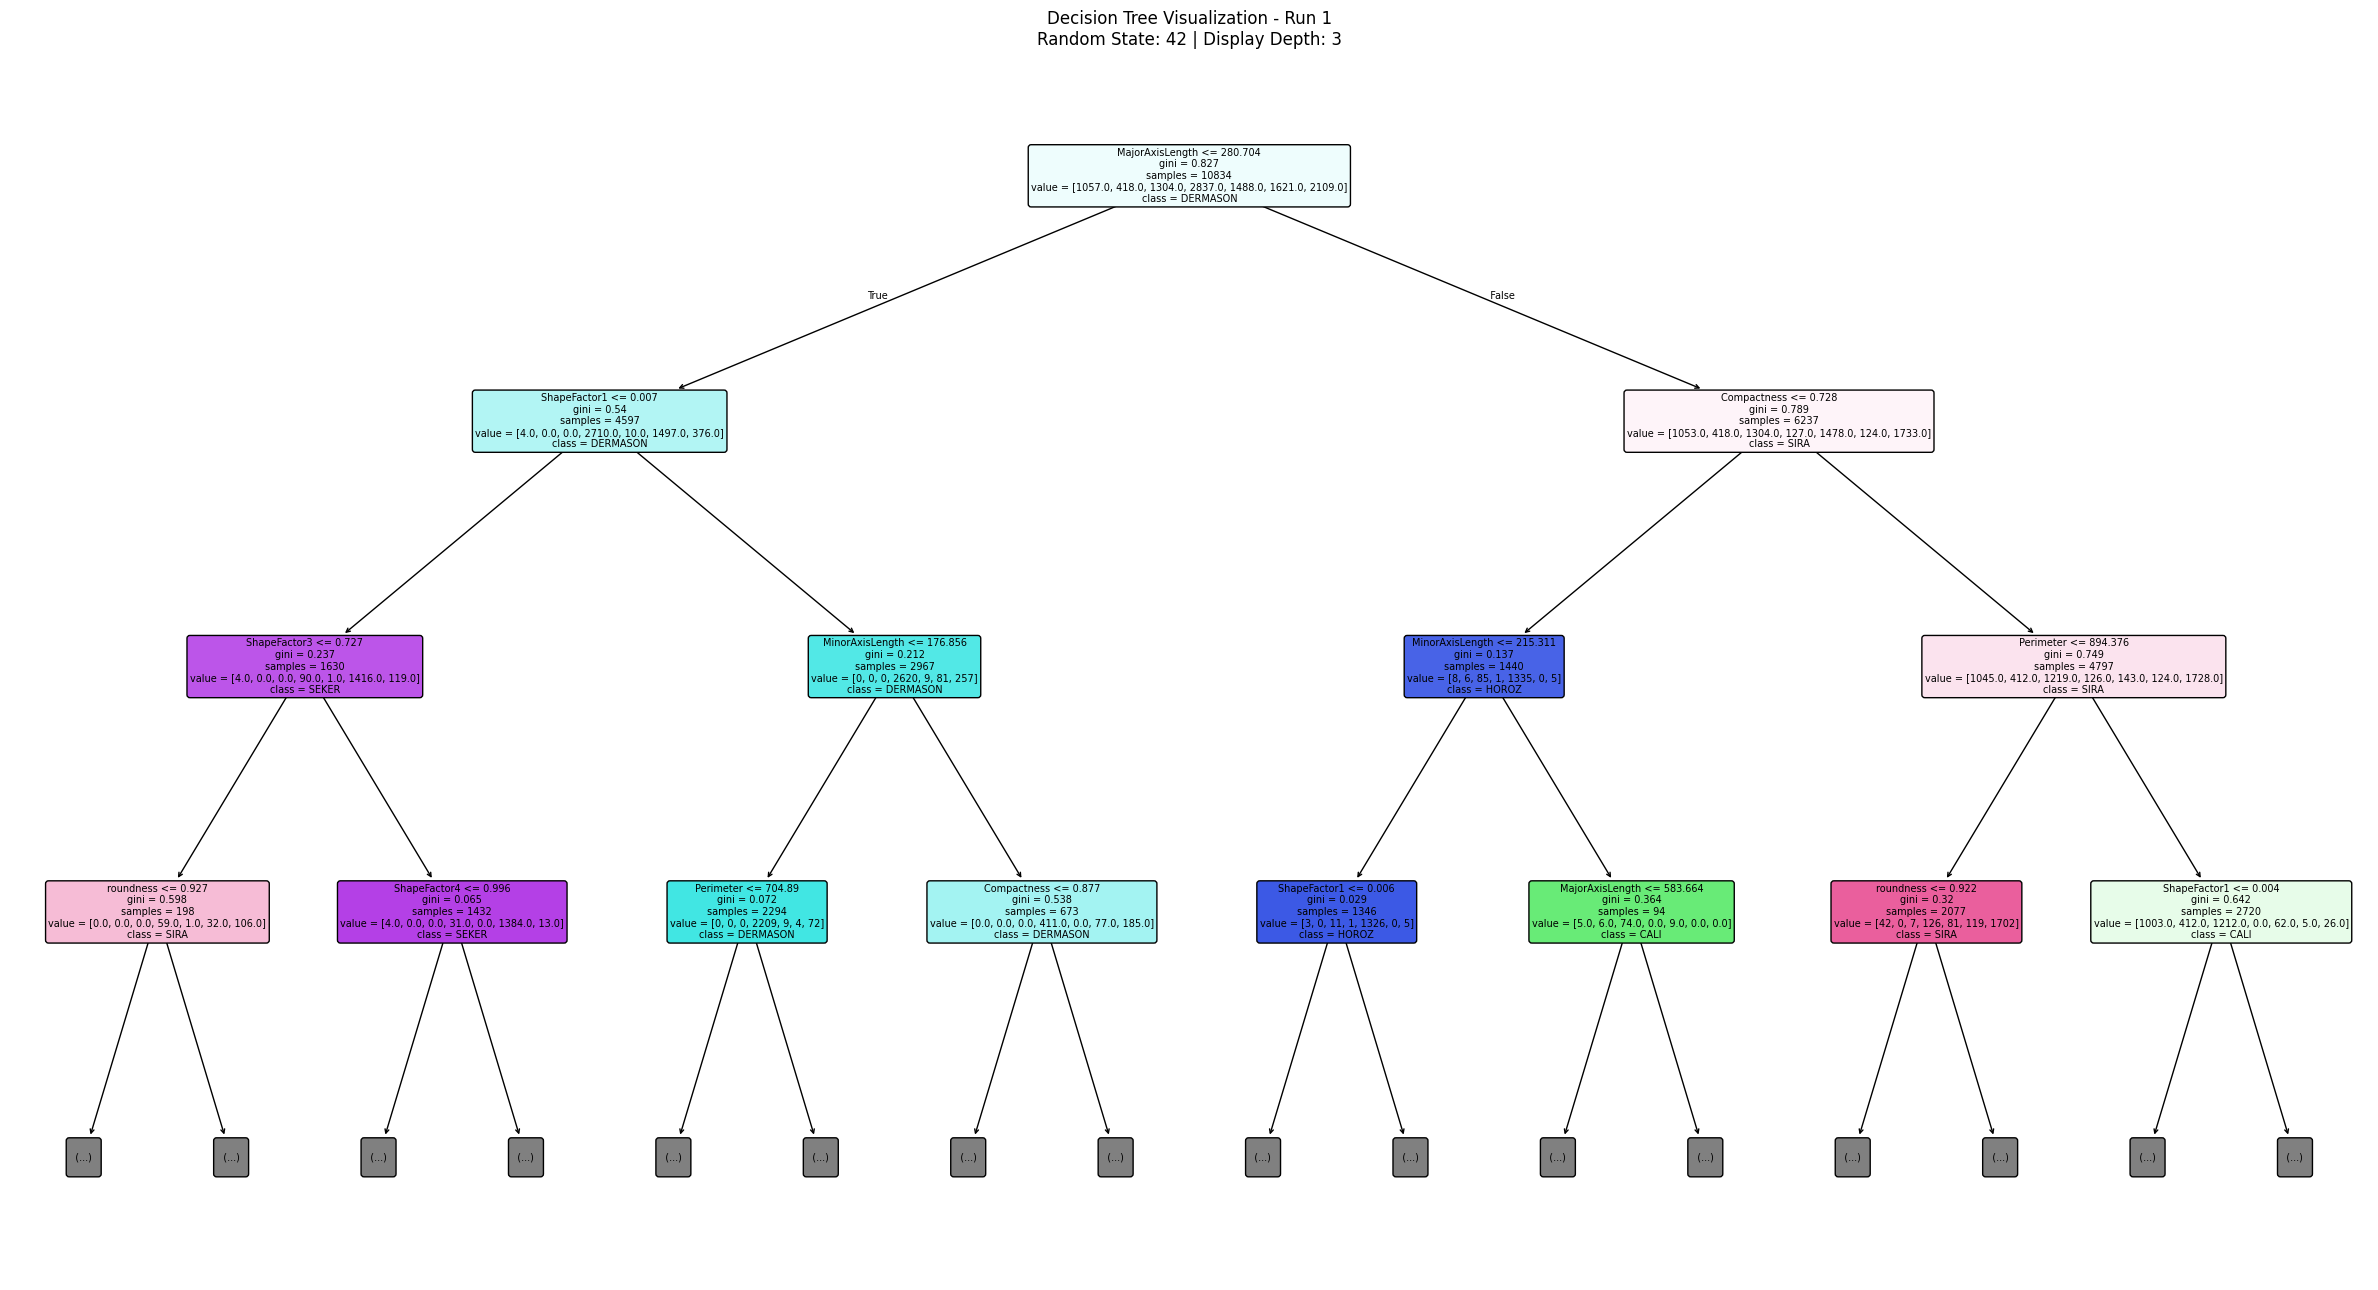


DECISION TREE STRUCTURE SUMMARY
Tree depth       : 12
Number of leaves : 318
Number of nodes  : 635
Number of splits : 317
Training accuracy: 0.9595
Testing accuracy : 0.9070
Testing Macro F1 : 0.9202
CV Best Macro F1 : 0.9209

DECISION TREE VISUALIZATION: RUN 2/5 | SEED 43


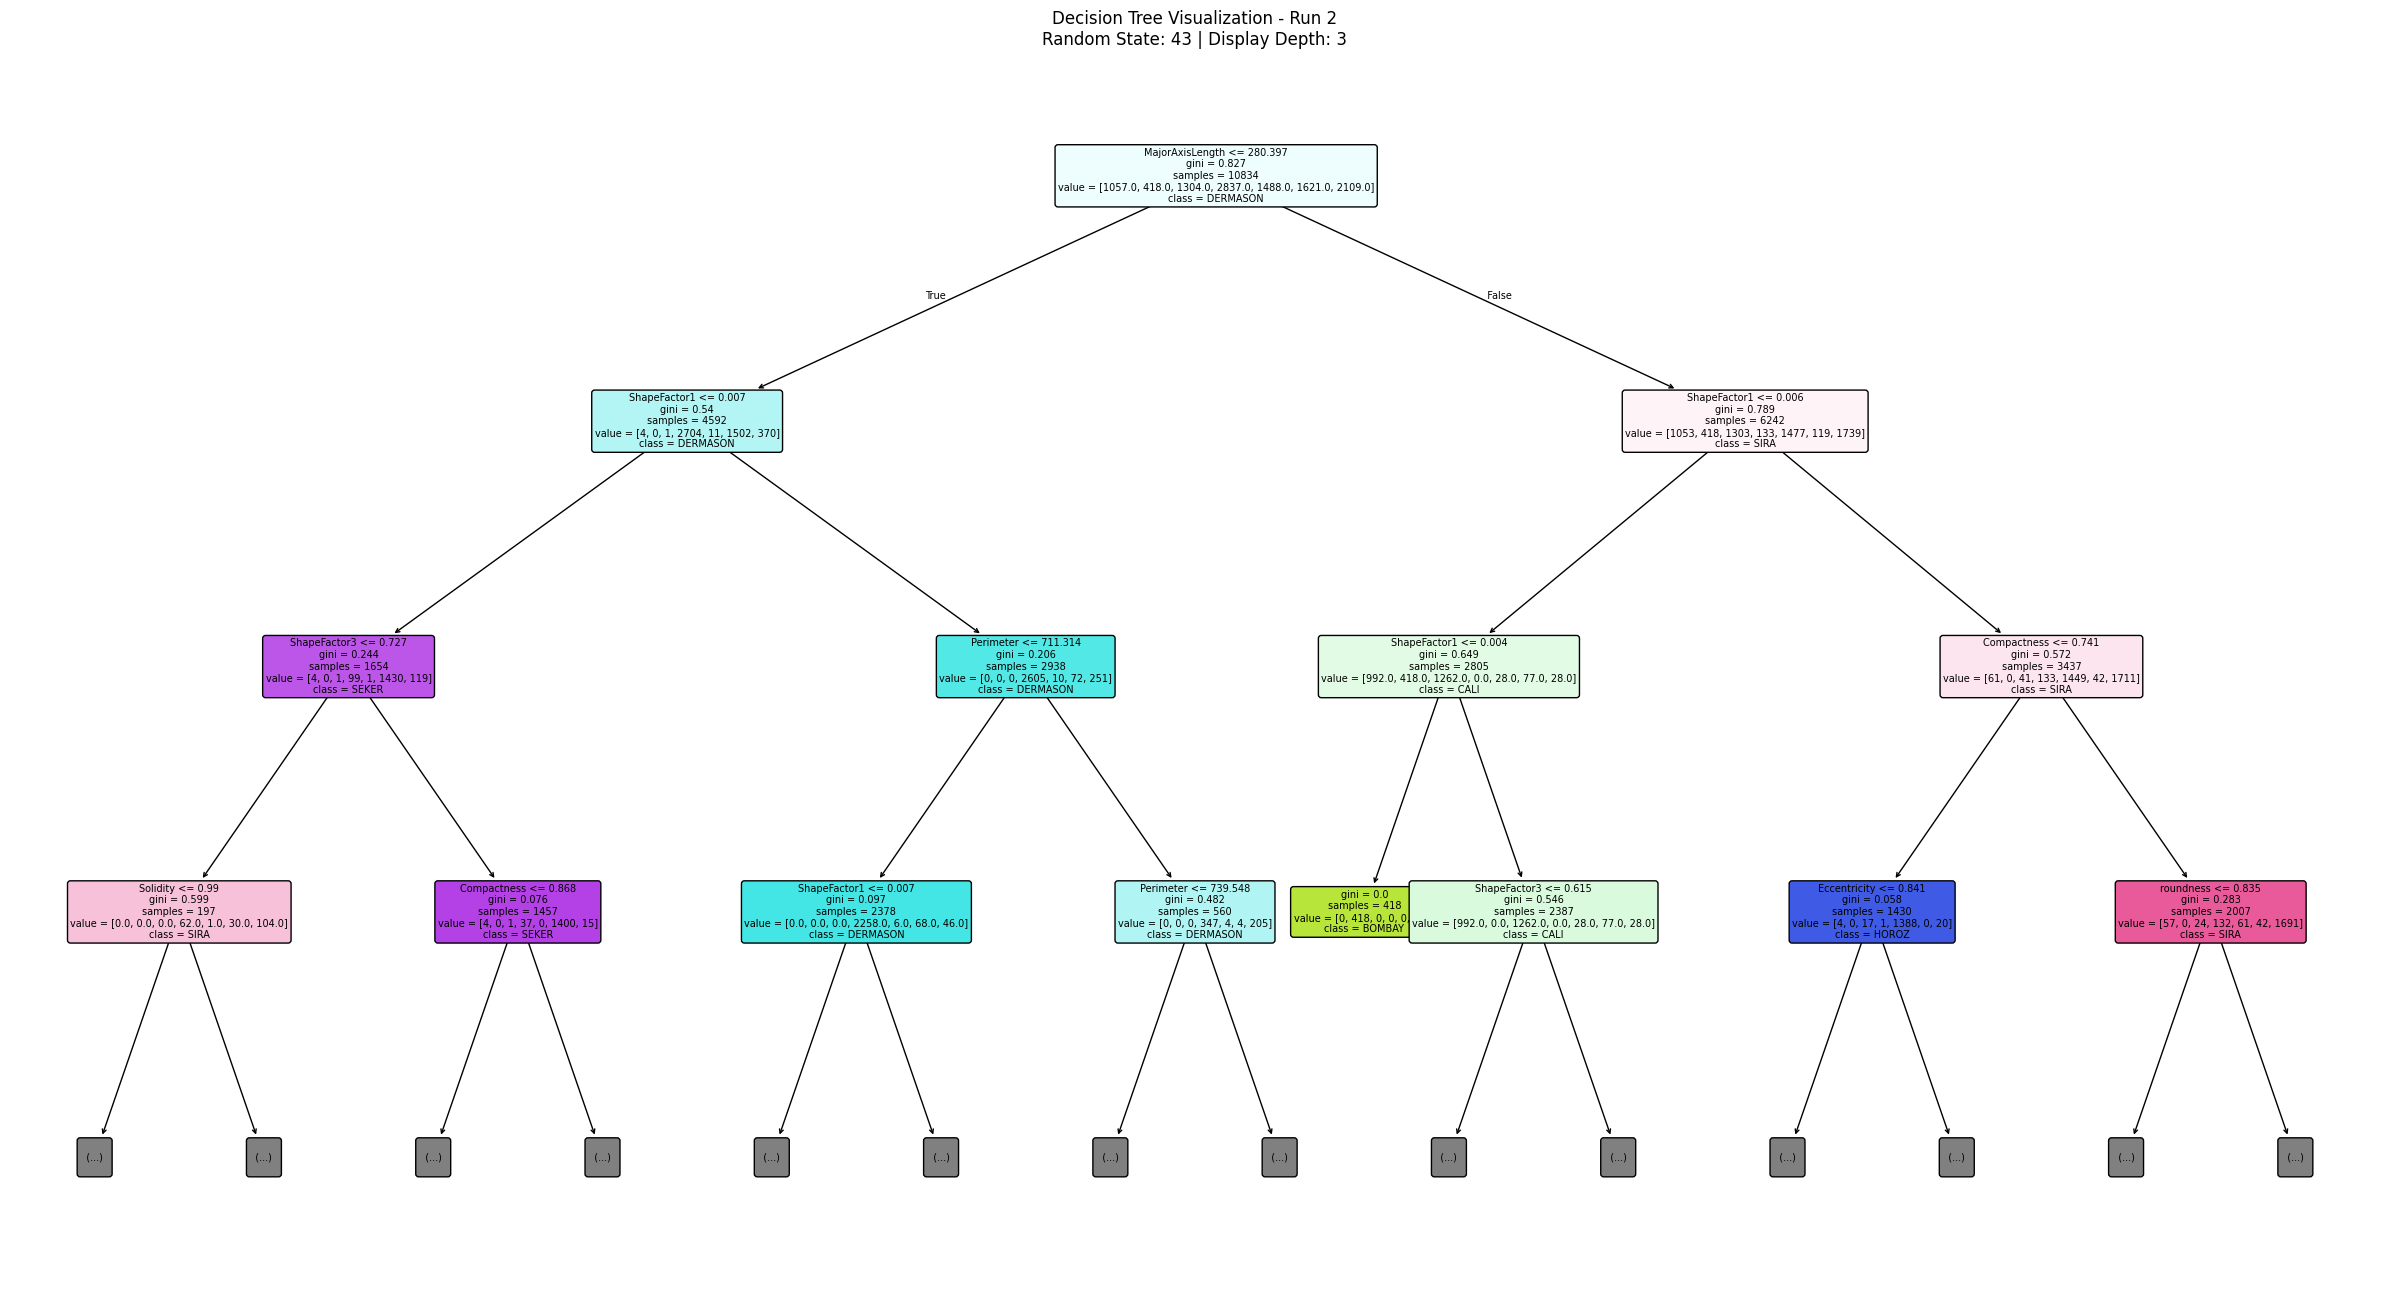


DECISION TREE STRUCTURE SUMMARY
Tree depth       : 12
Number of leaves : 336
Number of nodes  : 671
Number of splits : 335
Training accuracy: 0.9616
Testing accuracy : 0.9037
Testing Macro F1 : 0.9179
CV Best Macro F1 : 0.9202

DECISION TREE VISUALIZATION: RUN 3/5 | SEED 44


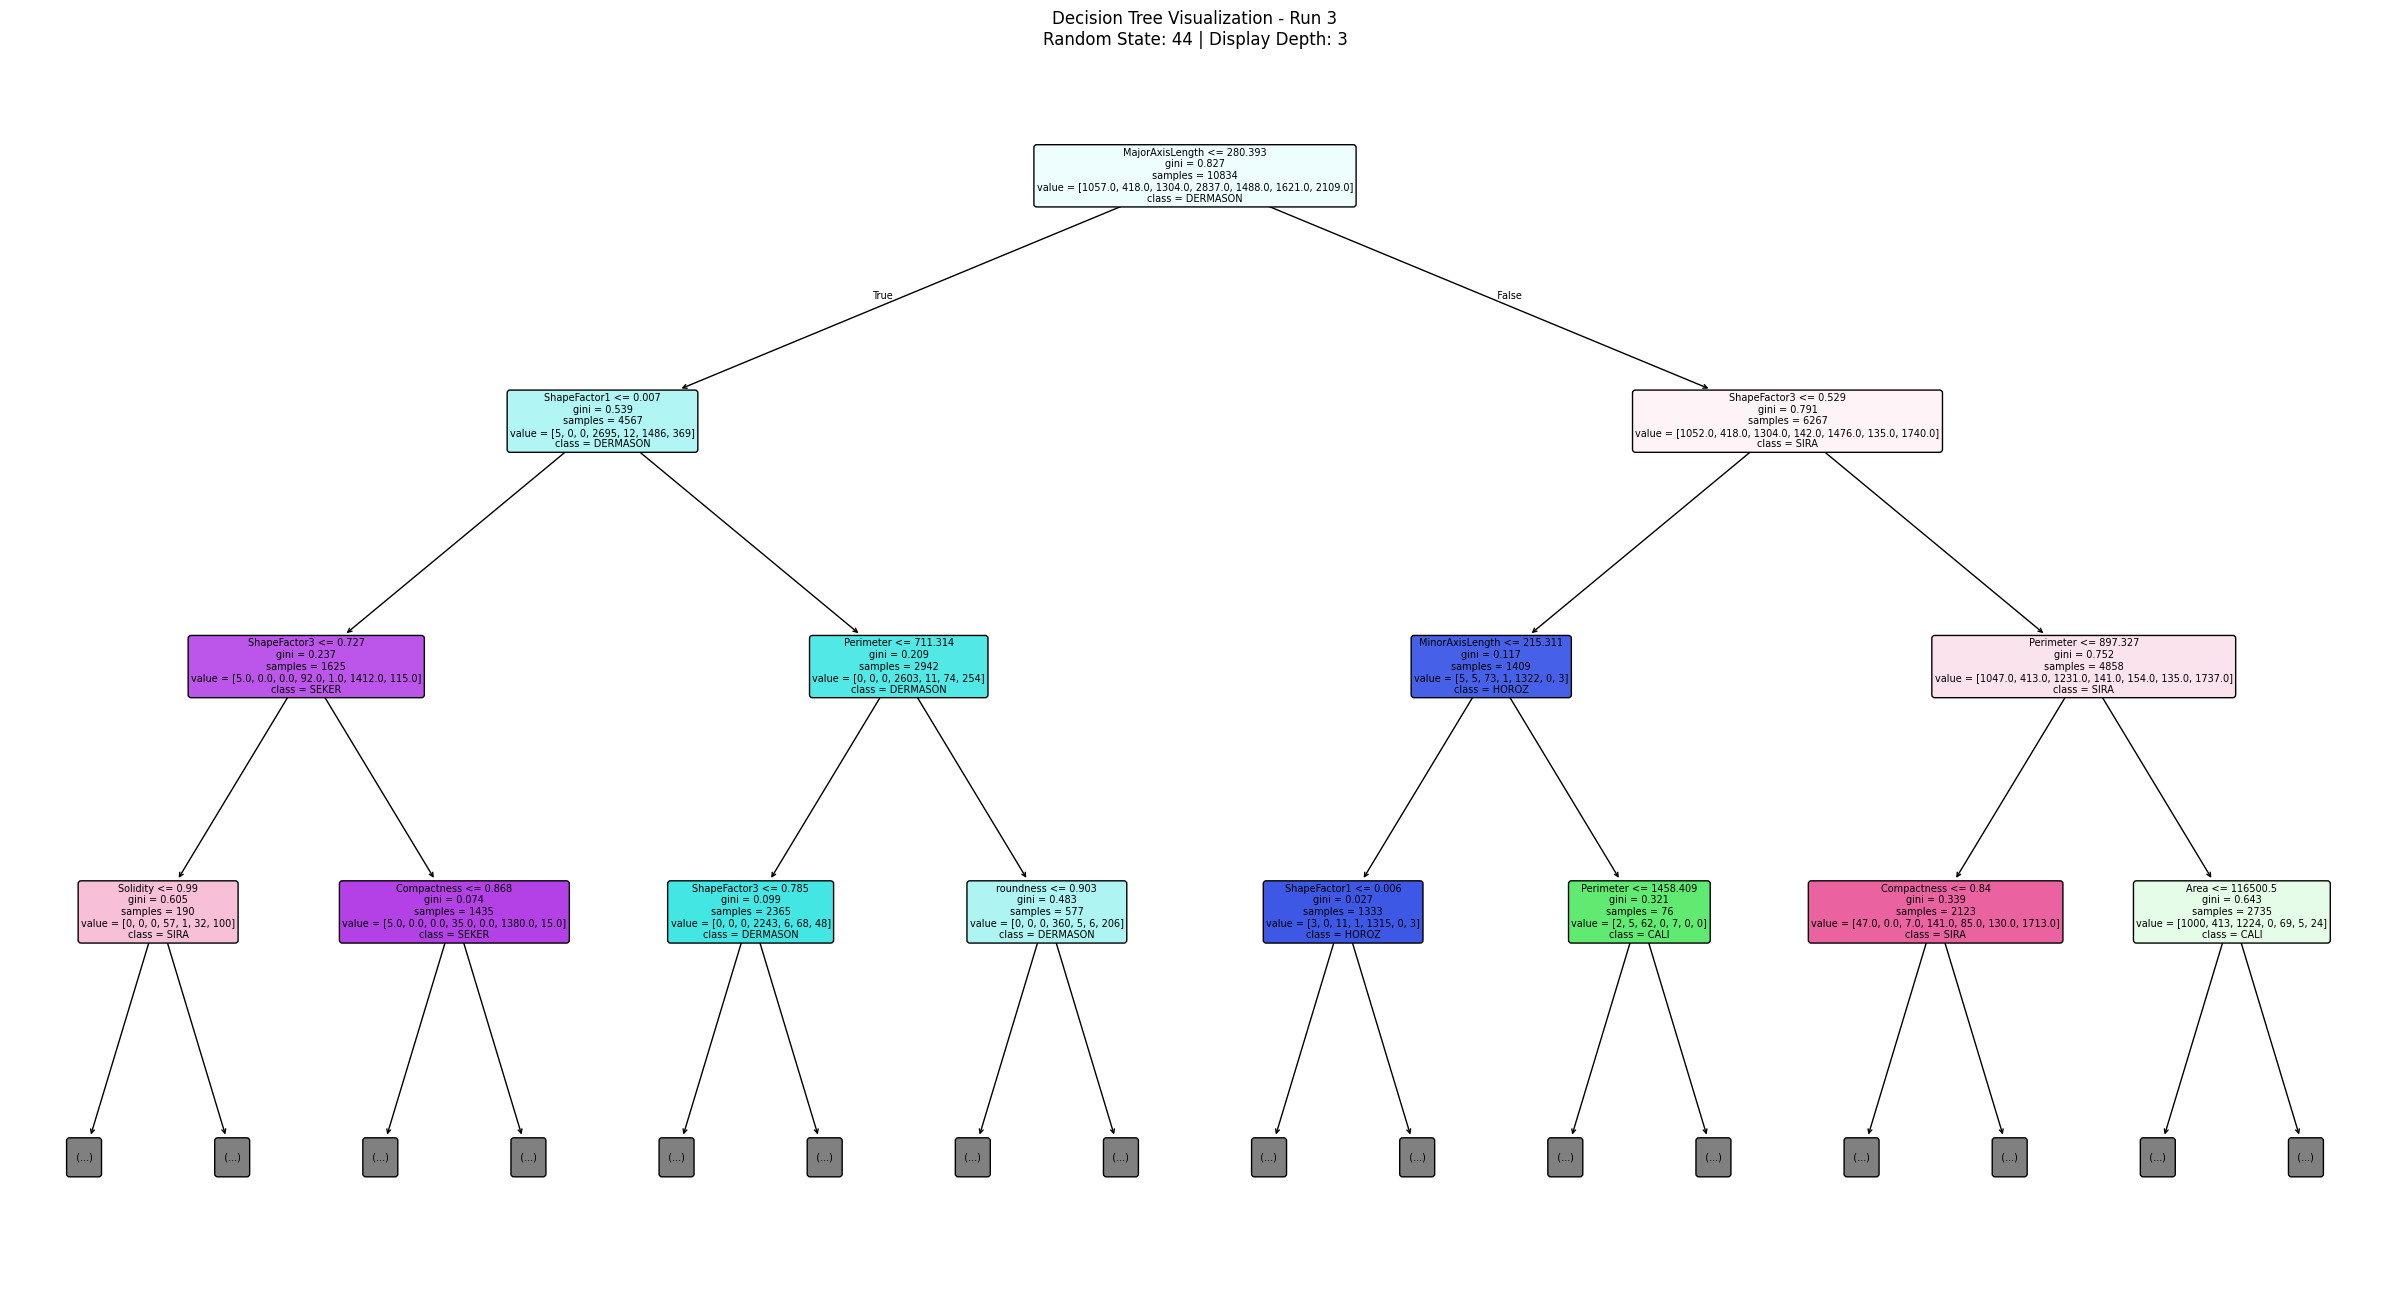


DECISION TREE STRUCTURE SUMMARY
Tree depth       : 12
Number of leaves : 331
Number of nodes  : 661
Number of splits : 330
Training accuracy: 0.9597
Testing accuracy : 0.9003
Testing Macro F1 : 0.9116
CV Best Macro F1 : 0.9181

DECISION TREE VISUALIZATION: RUN 4/5 | SEED 45


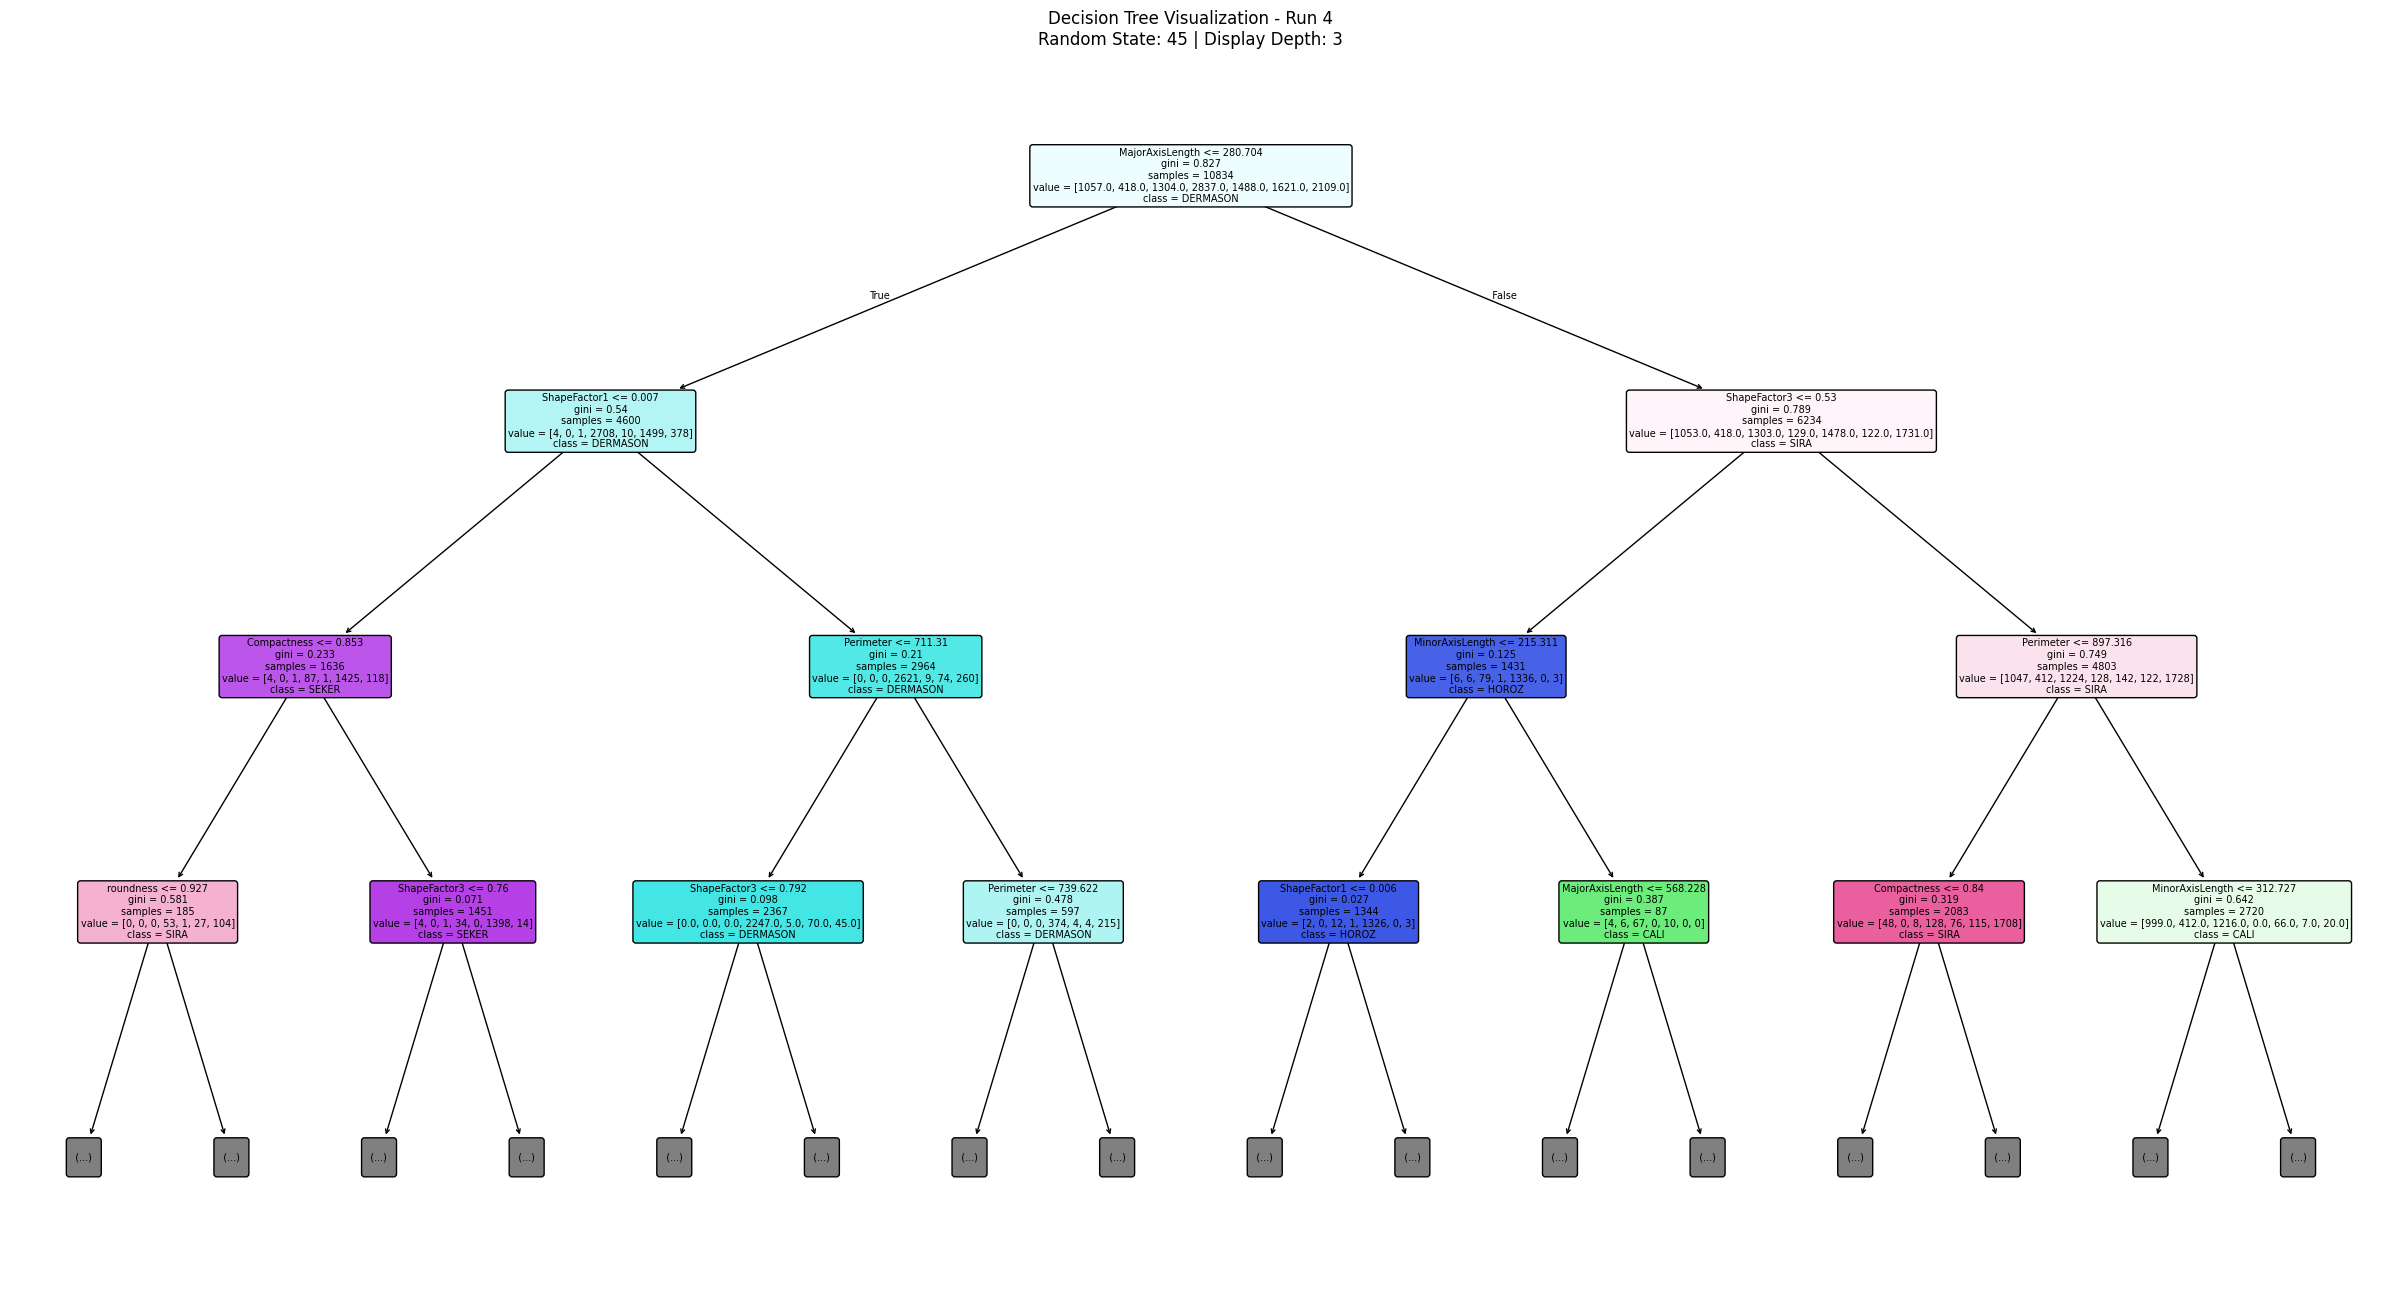


DECISION TREE STRUCTURE SUMMARY
Tree depth       : 12
Number of leaves : 322
Number of nodes  : 643
Number of splits : 321
Training accuracy: 0.9612
Testing accuracy : 0.9007
Testing Macro F1 : 0.9164
CV Best Macro F1 : 0.9199

DECISION TREE VISUALIZATION: RUN 5/5 | SEED 46


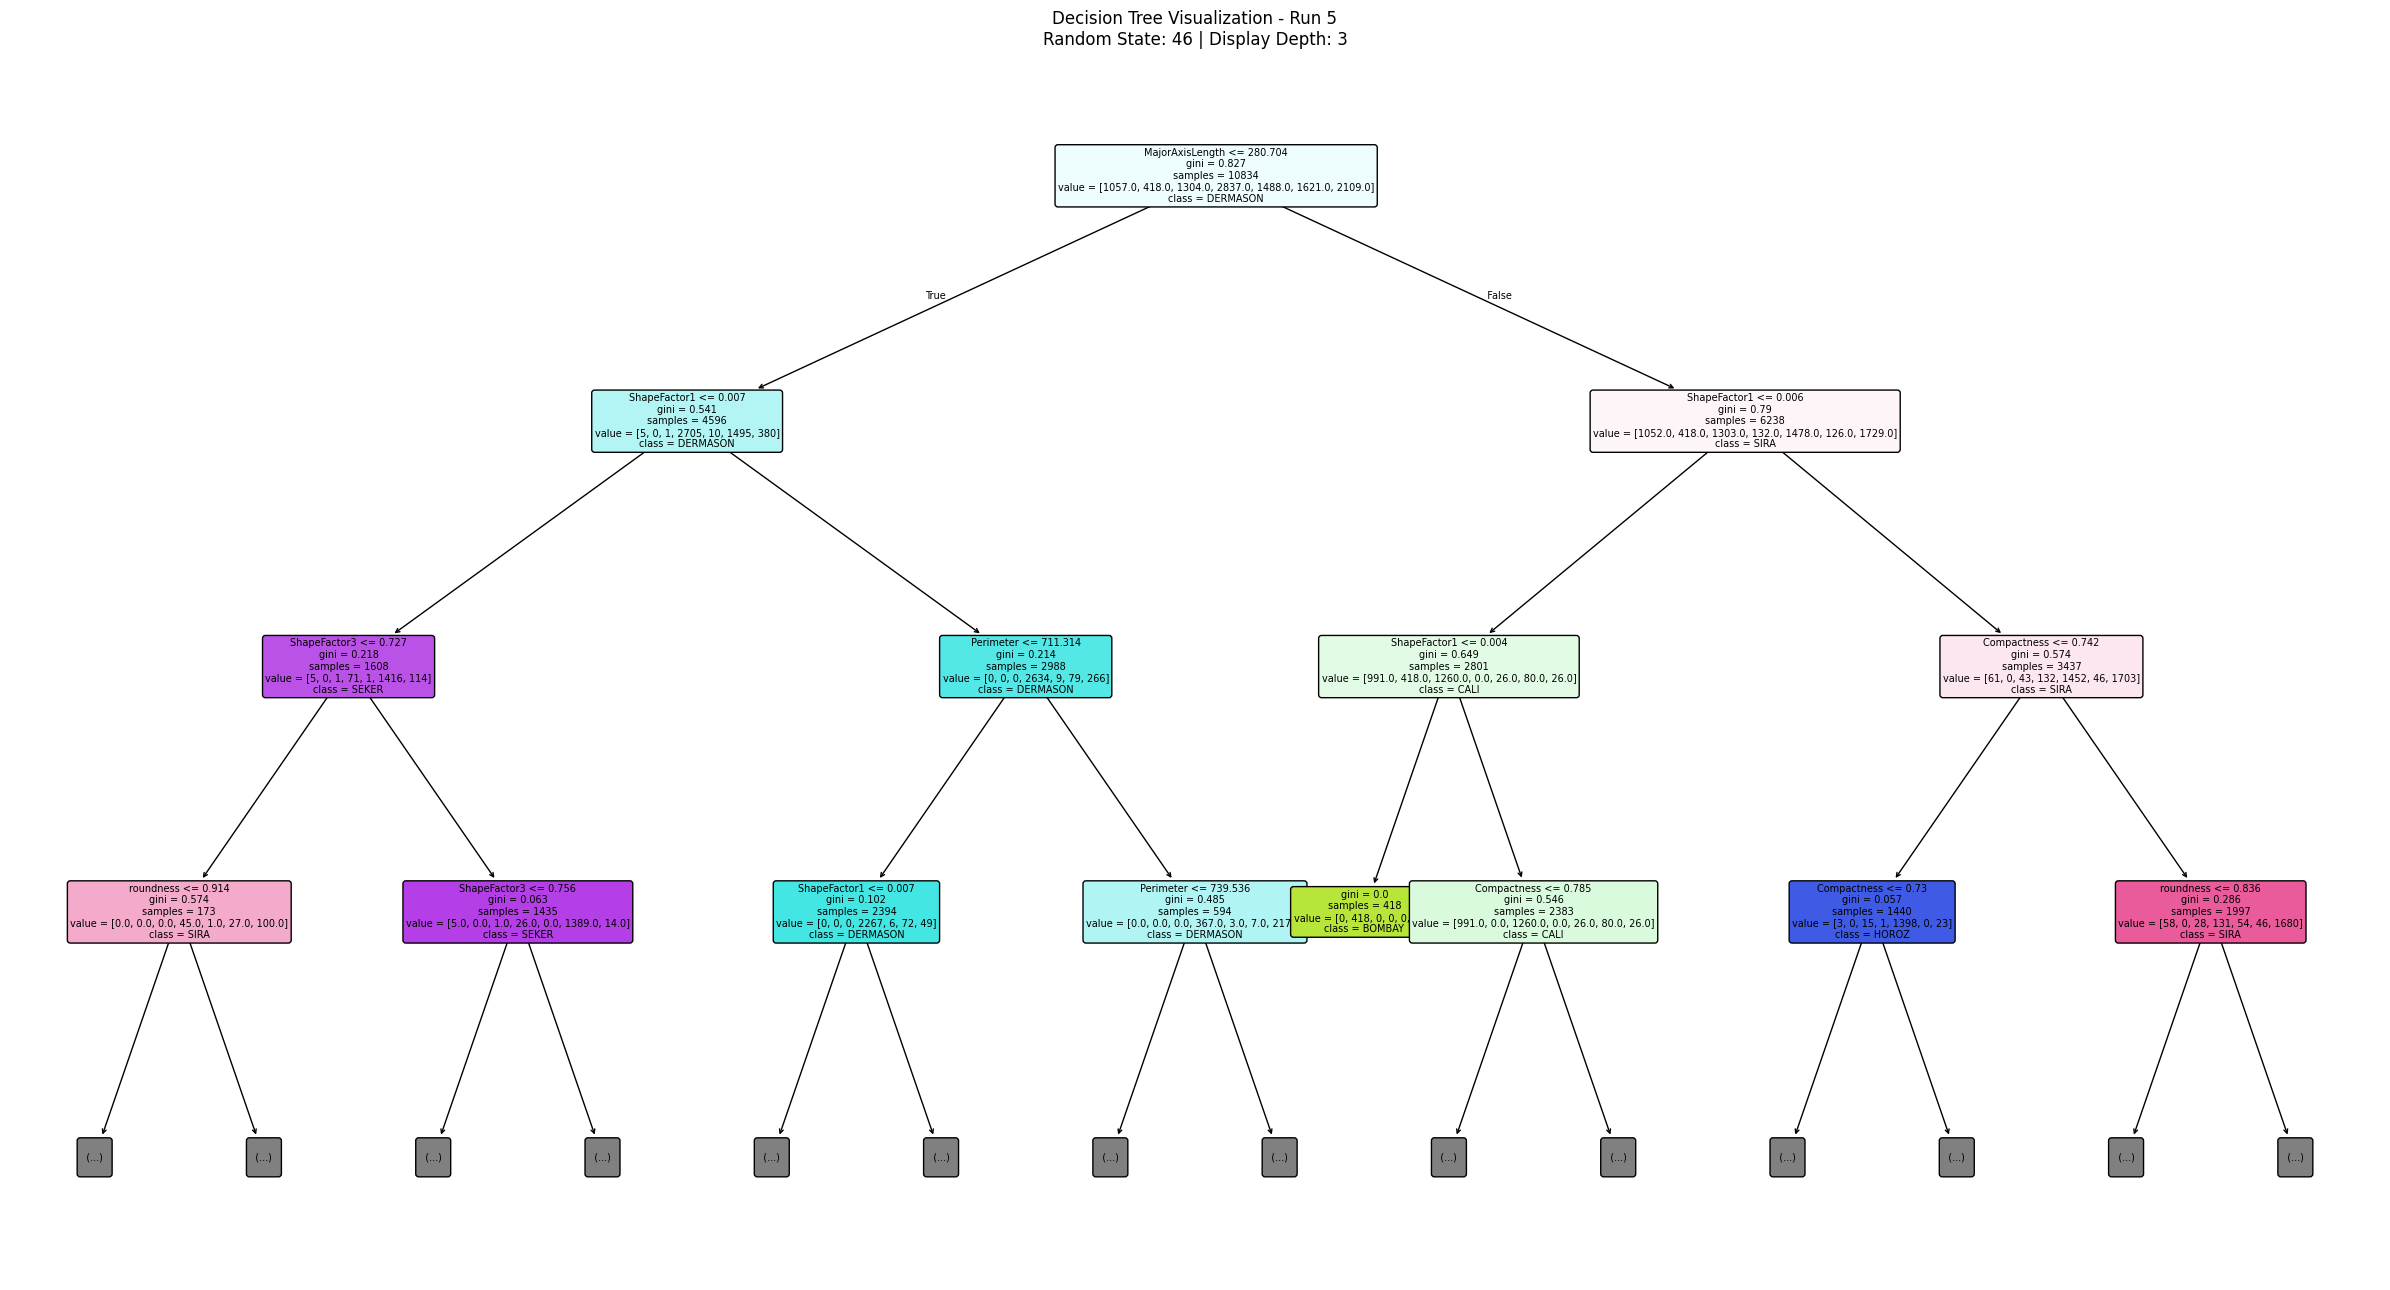


DECISION TREE STRUCTURE SUMMARY
Tree depth       : 12
Number of leaves : 316
Number of nodes  : 631
Number of splits : 315
Training accuracy: 0.9595
Testing accuracy : 0.8974
Testing Macro F1 : 0.9132
CV Best Macro F1 : 0.9179

BASELINE VS TUNED COMPARISON: RUN 1/5

MODEL: Decision Tree
Baseline Accuracy : 89.6641%
Tuned Accuracy    : 90.6977%
Baseline Macro F1 : 0.9109
Tuned Macro F1    : 0.9202
Tuned CV Macro F1 : 0.9209
Baseline Training : 0.39 seconds

MODEL: Random Forest
Baseline Accuracy : 91.9897%
Tuned Accuracy    : 91.6205%
Baseline Macro F1 : 0.9315
Tuned Macro F1    : 0.9283
Tuned CV Macro F1 : 0.9356
Baseline Training : 7.05 seconds

BASELINE VS TUNED COMPARISON: RUN 2/5

MODEL: Decision Tree
Baseline Accuracy : 89.9963%
Tuned Accuracy    : 90.3654%
Baseline Macro F1 : 0.9133
Tuned Macro F1    : 0.9179
Tuned CV Macro F1 : 0.9202
Baseline Training : 0.38 seconds

MODEL: Random Forest
Baseline Accuracy : 92.1373%
Tuned Accuracy    : 91.9158%
Baseline Macro F1 : 0.9325
Tuned

,run,random_state,model,stage,test_accuracy,test_macro_f1,cv_best_macro_f1,fit_seconds
0,1,42,Decision Tree,Baseline,0.89664,0.91092,NaN,0.39138
1,1,42,Decision Tree,Tuned,0.90698,0.92023,0.92090,NaN
2,1,42,Random Forest,Baseline,0.91990,0.93154,NaN,7.04782
3,1,42,Random Forest,Tuned,0.91621,0.92833,0.93562,NaN
4,2,43,Decision Tree,Baseline,0.89996,0.91326,NaN,0.37967
5,2,43,Decision Tree,Tuned,0.90365,0.91788,0.92025,NaN
6,2,43,Random Forest,Baseline,0.92137,0.93251,NaN,6.02381
7,2,43,Random Forest,Tuned,0.91916,0.93042,0.93512,NaN
8,3,44,Decision Tree,Baseline,0.89184,0.90514,NaN,0.54363
9,3,44,Decision Tree,Tuned,0.90033,0.91165,0.91807,NaN



FIVE-RUN PERFORMANCE COMPARISON SUMMARY


,model,stage,mean_test_accuracy,std_test_accuracy,mean_test_macro_f1,std_test_macro_f1
0,Decision Tree,Baseline,0.89192,0.00648,0.90678,0.00506
1,Decision Tree,Tuned,0.90181,0.00364,0.91588,0.00347
2,Random Forest,Baseline,0.91872,0.00400,0.93009,0.00348
3,Random Forest,Tuned,0.91753,0.00391,0.92907,0.00265


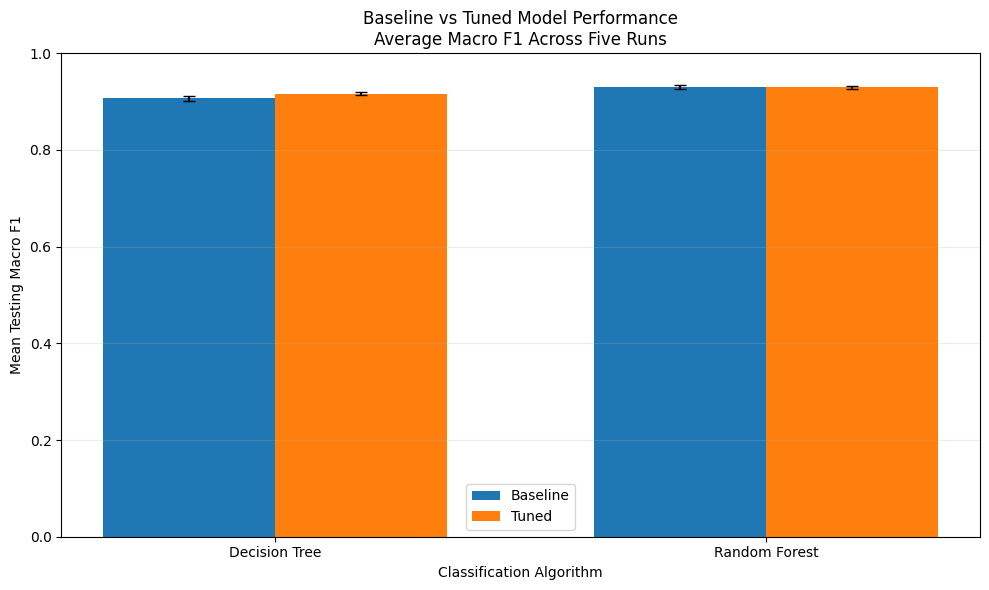


FIVE-RUN CROSS-VALIDATION PERFORMANCE


,model,mean_cv_macro_f1,std_cv_macro_f1,minimum_cv_macro_f1,maximum_cv_macro_f1
0,Random Forest,0.93565,0.00091,0.93457,0.93697
1,Decision Tree,0.91940,0.00136,0.91786,0.92090


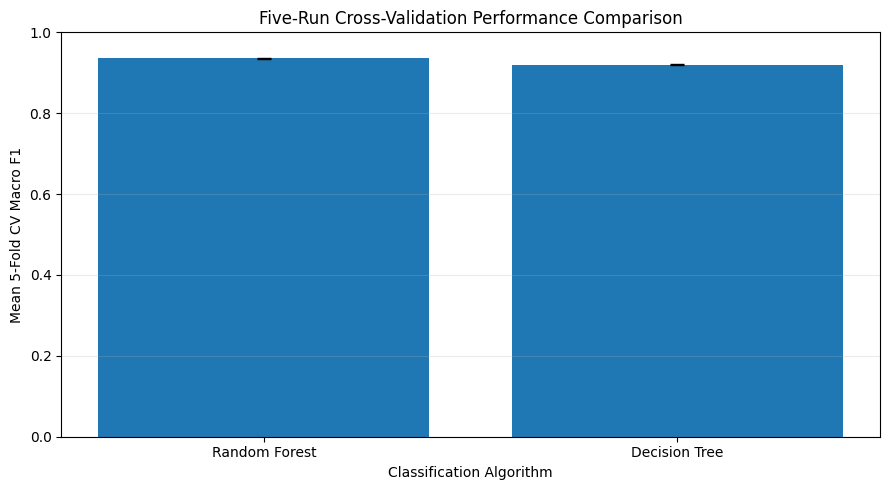


BEST MODEL SELECTION
Best algorithm       : Random Forest
Mean CV Macro F1     : 0.93565
Std CV Macro F1      : 0.00091
Selection criterion : Highest average 5-fold CV Macro F1

FIVE-RUN DECISION TREE STRUCTURE SUMMARY


,run,random_state,model,tree_depth,number_of_leaves,number_of_nodes,number_of_splits,number_of_features,train_accuracy,test_accuracy,test_macro_f1,cv_best_macro_f1
0,1,42,Decision Tree,12,318,635,317,16,0.95948,0.90698,0.92023,0.92090
1,2,43,Decision Tree,12,336,671,335,16,0.96160,0.90365,0.91788,0.92025
2,3,44,Decision Tree,12,331,661,330,16,0.95966,0.90033,0.91165,0.91807
3,4,45,Decision Tree,12,322,643,321,16,0.96123,0.90070,0.91643,0.91992
4,5,46,Decision Tree,12,316,631,315,16,0.95948,0.89738,0.91321,0.91786



SECTION 14: FIVE-RUN MODEL COMPARISON COMPLETED
Total experiment runs       : 5
Total algorithms            : 2
Tree visualizations         : 5
Tree rule files             : 5
Model comparison records    : 20
Best model based on CV      : Random Forest
Mean CV Macro F1            : 0.93565
Std CV Macro F1             : 0.00091

MAIN OUTPUT FILES:
- five_run_model_comparison.csv
- five_run_model_comparison_summary.csv
- five_run_model_comparison_macro_f1.png
- five_run_cross_validation_results.csv
- five_run_cross_validation_summary.csv
- five_run_cross_validation_comparison.png
- five_run_decision_tree_structure.csv

DECISION TREE FILES:
- run_1_seed_42/decision_tree_top_depth_3.png
- run_2_seed_43/decision_tree_top_depth_3.png
- run_3_seed_44/decision_tree_top_depth_3.png
- run_4_seed_45/decision_tree_top_depth_3.png
- run_5_seed_46/decision_tree_top_depth_3.png

Output directory: /content/Dry_Bean_Classification_Submission/outputs/repeated_runs
Evidence directory: /content/Dry_Bean_

In [14]:

# ============================================================
# SECTION 14: FIVE-RUN DECISION TREE VISUALIZATION & MODEL COMPARISON
# ============================================================

# ------------------------------------------------------------
# A. IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

from pathlib import Path  # Mengimpor Path untuk mengatur lokasi penyimpanan hasil visualisasi.

import time  # Mengimpor time untuk mengukur durasi training model baseline.

import numpy as np  # Mengimpor NumPy untuk perhitungan numerik dan pengaturan posisi grafik.

import pandas as pd  # Mengimpor Pandas untuk mengolah hasil perbandingan model.

import matplotlib.pyplot as plt  # Mengimpor Matplotlib untuk membuat grafik dan visualisasi pohon keputusan.

from sklearn.tree import plot_tree, export_text  # Mengimpor fungsi visualisasi pohon keputusan dan ekspor aturan Decision Tree.

from sklearn.tree import DecisionTreeClassifier  # Mengimpor algoritma Decision Tree untuk membangun model baseline.

from sklearn.ensemble import RandomForestClassifier  # Mengimpor algoritma Random Forest untuk membangun model baseline.

from sklearn.metrics import accuracy_score, f1_score  # Mengimpor metrik Accuracy dan Macro F1 untuk mengevaluasi performa model.


# ------------------------------------------------------------
# B. VALIDATE REQUIRED VARIABLES
# ------------------------------------------------------------

# Menentukan seluruh variabel yang harus tersedia dari Section sebelumnya.
required_variables = [
    'RUN_SEEDS',
    'run_data_by_seed',
    'tuned_models_by_run',
    'best_cv_by_run',
    'feature_cols',
    'REPEATED_OUTPUT_DIR',
    'REPEATED_EVIDENCE_DIR'
]

# Memeriksa variabel yang belum tersedia.
missing_variables = [
    variable for variable in required_variables
    if variable not in globals()
]

# Menghentikan proses apabila terdapat variabel yang belum tersedia.
if missing_variables:
    raise NameError(
        f'Variabel yang belum tersedia: {missing_variables}. '
        'Jalankan Section 9, 10, dan 11 terlebih dahulu.'
    )

# Memastikan eksperimen menggunakan tepat lima putaran.
if len(RUN_SEEDS) != 5:
    raise ValueError(
        f'Dibutuhkan tepat 5 putaran, tetapi ditemukan {len(RUN_SEEDS)}.'
    )

# Menentukan nama kedua algoritma klasifikasi.
MODEL_NAMES = [
    'Decision Tree',
    'Random Forest'
]

# Mengubah daftar fitur menjadi list agar urutannya konsisten.
feature_cols = list(feature_cols)

# Memastikan seluruh variabel eksperimen tersedia pada setiap seed.
for seed in RUN_SEEDS:

    # Memastikan data eksperimen tersedia.
    if seed not in run_data_by_seed:
        raise KeyError(f'Data eksperimen seed {seed} tidak ditemukan.')

    # Memastikan model hasil tuning tersedia.
    if seed not in tuned_models_by_run:
        raise KeyError(f'Model hasil tuning seed {seed} tidak ditemukan.')

    # Memastikan hasil Cross-Validation tersedia.
    if seed not in best_cv_by_run:
        raise KeyError(f'Hasil Cross-Validation seed {seed} tidak ditemukan.')

    # Memastikan kedua model tersedia.
    for name in MODEL_NAMES:

        if name not in tuned_models_by_run[seed]:
            raise KeyError(
                f'Model {name} pada seed {seed} tidak ditemukan.'
            )

        if name not in best_cv_by_run[seed]:
            raise KeyError(
                f'Nilai CV {name} pada seed {seed} tidak ditemukan.'
            )

    # Memastikan seluruh komponen dataset tersedia.
    for key in ['X_train', 'X_test', 'y_train', 'y_test']:

        if key not in run_data_by_seed[seed]:
            raise KeyError(
                f'Data {key} pada seed {seed} tidak ditemukan.'
            )

# Memastikan folder outputs tersedia.
REPEATED_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Memastikan folder evidence tersedia.
REPEATED_EVIDENCE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# C. PREPARE EXPERIMENT STORAGE
# ------------------------------------------------------------

# Membuat dictionary untuk menyimpan model baseline setiap putaran.
baseline_models_by_run = {}

# Membuat list untuk menyimpan hasil perbandingan seluruh model.
model_comparison_rows = []

# Membuat list untuk menyimpan hasil Cross-Validation setiap putaran.
cv_comparison_rows = []

# Membuat list untuk menyimpan struktur Decision Tree.
tree_structure_rows = []

# Membuat dictionary untuk menyimpan aturan Decision Tree.
tree_rules_by_run = {}

# Menampilkan konfigurasi eksperimen.
print('FIVE-RUN MODEL COMPARISON CONFIGURATION')

print(f'Total experiment runs : {len(RUN_SEEDS)}')

print(f'Total algorithms      : {len(MODEL_NAMES)}')

print(f'Total features        : {len(feature_cols)}')

print(f'Random states         : {RUN_SEEDS}')


# ------------------------------------------------------------
# D. DECISION TREE VISUALIZATION FOR FIVE RUNS
# ------------------------------------------------------------

# Melakukan visualisasi Decision Tree pada setiap putaran eksperimen.
for run_number, seed in enumerate(RUN_SEEDS, start=1):

    # Menampilkan identitas putaran eksperimen.
    print('\n' + '=' * 70)

    print(f'DECISION TREE VISUALIZATION: RUN {run_number}/5 | SEED {seed}')

    print('=' * 70)

    # Mengambil data training pada putaran saat ini.
    X_train_run = run_data_by_seed[seed]['X_train']

    # Mengambil data testing pada putaran saat ini.
    X_test_run = run_data_by_seed[seed]['X_test']

    # Mengambil label training pada putaran saat ini.
    y_train_run = run_data_by_seed[seed]['y_train']

    # Mengambil label testing pada putaran saat ini.
    y_test_run = run_data_by_seed[seed]['y_test']

    # Mengambil model Decision Tree hasil tuning.
    best_dt = tuned_models_by_run[seed]['Decision Tree']

    # Memastikan jumlah fitur model sesuai dengan daftar fitur.
    if best_dt.n_features_in_ != len(feature_cols):
        raise ValueError(
            f'Jumlah fitur Decision Tree seed {seed} tidak sesuai.'
        )

    # Mengambil urutan kelas sesuai dengan model.
    tree_class_names = [
        str(label) for label in best_dt.classes_
    ]

    # Menentukan folder output putaran saat ini.
    run_output_dir = (
        REPEATED_OUTPUT_DIR / f'run_{run_number}_seed_{seed}'
    )

    # Menentukan folder evidence putaran saat ini.
    run_evidence_dir = (
        REPEATED_EVIDENCE_DIR / f'run_{run_number}_seed_{seed}'
    )

    # Memastikan kedua folder tersedia.
    run_output_dir.mkdir(parents=True, exist_ok=True)

    run_evidence_dir.mkdir(parents=True, exist_ok=True)


    # --------------------------------------------------------
    # D1. VISUALIZE DECISION TREE
    # --------------------------------------------------------

    # Membuat area visualisasi pohon keputusan.
    fig, ax = plt.subplots(figsize=(24, 13))

    # Menggambar struktur Decision Tree hingga kedalaman tiga.
    plot_tree(
        best_dt,
        feature_names=feature_cols,
        class_names=tree_class_names,
        filled=True,
        rounded=True,
        max_depth=3,
        fontsize=7,
        precision=3,
        ax=ax
    )

    # Memberikan judul sesuai putaran eksperimen.
    ax.set_title(
        f'Decision Tree Visualization - Run {run_number}\n'
        f'Random State: {seed} | Display Depth: 3'
    )

    # Mengatur tata letak grafik.
    fig.tight_layout()

    # Menyimpan visualisasi Decision Tree ke folder outputs.
    fig.savefig(
        run_output_dir / 'decision_tree_top_depth_3.png',
        dpi=180,
        bbox_inches='tight'
    )

    # Menampilkan visualisasi di Google Colab.
    plt.show()

    # Menutup figure untuk menghemat memori.
    plt.close(fig)


    # --------------------------------------------------------
    # D2. EXPORT DECISION TREE RULES
    # --------------------------------------------------------

    # Menentukan kedalaman maksimum pohon keputusan yang sebenarnya.
    full_tree_depth = max(
        1,
        int(best_dt.get_depth())
    )

    # Menghasilkan aturan keputusan berdasarkan seluruh kedalaman pohon.
    try:

        # Mengekspor aturan dengan nama fitur dan nama kelas.
        tree_rules = export_text(
            best_dt,
            feature_names=feature_cols,
            class_names=tree_class_names,
            max_depth=full_tree_depth,
            decimals=3
        )

    except TypeError:

        # Menggunakan kompatibilitas alternatif jika versi sklearn belum mendukung class_names.
        tree_rules = export_text(
            best_dt,
            feature_names=feature_cols,
            max_depth=full_tree_depth,
            decimals=3
        )

    # Menambahkan informasi eksperimen pada bagian awal file aturan.
    rules_header = (
        f'DECISION TREE RULES\n'
        f'Run: {run_number}\n'
        f'Random State: {seed}\n'
        f'Model: Decision Tree\n'
        f'Actual Tree Depth: {best_dt.get_depth()}\n'
        f'Number of Leaves: {best_dt.get_n_leaves()}\n'
        f'Classes: {tree_class_names}\n'
        f'{"=" * 70}\n\n'
    )

    # Menggabungkan informasi model dan seluruh aturan keputusan.
    complete_rules = rules_header + tree_rules

    # Menyimpan aturan keputusan pada folder evidence.
    rules_path = (
        run_evidence_dir / 'decision_tree_rules.txt'
    )

    # Menulis aturan keputusan ke dalam file teks.
    rules_path.write_text(
        complete_rules,
        encoding='utf-8'
    )

    # Menyimpan aturan keputusan dalam dictionary.
    tree_rules_by_run[seed] = complete_rules


    # --------------------------------------------------------
    # D3. ANALYZE DECISION TREE STRUCTURE
    # --------------------------------------------------------

    # Menghitung akurasi model pada data training.
    tree_train_accuracy = accuracy_score(
        y_train_run,
        best_dt.predict(X_train_run)
    )

    # Menghitung akurasi model pada data testing.
    tree_test_accuracy = accuracy_score(
        y_test_run,
        best_dt.predict(X_test_run)
    )

    # Menghitung Macro F1 pada data testing.
    tree_test_macro_f1 = f1_score(
        y_test_run,
        best_dt.predict(X_test_run),
        average='macro',
        zero_division=0
    )

    # Mengambil nilai Cross-Validation terbaik dari Section 9.
    tree_cv_score = float(
        best_cv_by_run[seed]['Decision Tree']
    )

    # Menyimpan informasi struktur dan performa Decision Tree.
    tree_structure_rows.append({

        'run': run_number,

        'random_state': seed,

        'model': 'Decision Tree',

        'tree_depth': best_dt.get_depth(),

        'number_of_leaves': best_dt.get_n_leaves(),

        'number_of_nodes': best_dt.tree_.node_count,

        'number_of_splits': int(
            np.sum(best_dt.tree_.feature >= 0)
        ),

        'number_of_features': best_dt.n_features_in_,

        'train_accuracy': tree_train_accuracy,

        'test_accuracy': tree_test_accuracy,

        'test_macro_f1': tree_test_macro_f1,

        'cv_best_macro_f1': tree_cv_score

    })

    # Menampilkan ringkasan struktur pohon keputusan.
    print('\nDECISION TREE STRUCTURE SUMMARY')

    print(f'Tree depth       : {best_dt.get_depth()}')

    print(f'Number of leaves : {best_dt.get_n_leaves()}')

    print(f'Number of nodes  : {best_dt.tree_.node_count}')

    print(f'Number of splits : {np.sum(best_dt.tree_.feature >= 0)}')

    print(f'Training accuracy: {tree_train_accuracy:.4f}')

    print(f'Testing accuracy : {tree_test_accuracy:.4f}')

    print(f'Testing Macro F1 : {tree_test_macro_f1:.4f}')

    print(f'CV Best Macro F1 : {tree_cv_score:.4f}')


# ------------------------------------------------------------
# E. BASELINE VS TUNED MODEL COMPARISON
# ------------------------------------------------------------

# Melakukan perbandingan baseline dan tuned pada setiap putaran.
for run_number, seed in enumerate(RUN_SEEDS, start=1):

    # Menampilkan identitas putaran yang sedang dibandingkan.
    print('\n' + '=' * 70)

    print(f'BASELINE VS TUNED COMPARISON: RUN {run_number}/5')

    print('=' * 70)

    # Mengambil data training.
    X_train_run = run_data_by_seed[seed]['X_train']

    # Mengambil data testing.
    X_test_run = run_data_by_seed[seed]['X_test']

    # Mengambil label training.
    y_train_run = run_data_by_seed[seed]['y_train']

    # Mengambil label testing.
    y_test_run = run_data_by_seed[seed]['y_test']

    # Menyiapkan dictionary model baseline untuk putaran saat ini.
    baseline_models_by_run[seed] = {}

    # Membuat model baseline dengan parameter default Decision Tree dan Random Forest.
    baseline_models = {

        'Decision Tree': DecisionTreeClassifier(
            random_state=seed
        ),

        'Random Forest': RandomForestClassifier(
            random_state=seed,
            n_jobs=1
        )

    }

    # Melakukan evaluasi terhadap kedua algoritma.
    for name in MODEL_NAMES:

        # Mengambil model baseline.
        baseline_model = baseline_models[name]

        # Mencatat waktu awal training baseline.
        start_time = time.perf_counter()

        # Melatih model baseline menggunakan data training putaran saat ini.
        baseline_model.fit(
            X_train_run,
            y_train_run
        )

        # Menghitung durasi training baseline.
        baseline_fit_seconds = (
            time.perf_counter() - start_time
        )

        # Menyimpan model baseline yang telah dilatih.
        baseline_models_by_run[seed][name] = baseline_model

        # Mengambil model hasil tuning.
        tuned_model = tuned_models_by_run[seed][name]

        # Menghasilkan prediksi model baseline pada data testing.
        baseline_predictions = baseline_model.predict(
            X_test_run
        )

        # Menghasilkan prediksi model tuned pada data testing.
        tuned_predictions = tuned_model.predict(
            X_test_run
        )

        # Menghitung Accuracy model baseline.
        baseline_accuracy = accuracy_score(
            y_test_run,
            baseline_predictions
        )

        # Menghitung Macro F1 model baseline.
        baseline_macro_f1 = f1_score(
            y_test_run,
            baseline_predictions,
            average='macro',
            zero_division=0
        )

        # Menghitung Accuracy model tuned.
        tuned_accuracy = accuracy_score(
            y_test_run,
            tuned_predictions
        )

        # Menghitung Macro F1 model tuned.
        tuned_macro_f1 = f1_score(
            y_test_run,
            tuned_predictions,
            average='macro',
            zero_division=0
        )

        # Mengambil nilai CV terbaik untuk model tuned.
        cv_score = float(
            best_cv_by_run[seed][name]
        )

        # Menambahkan hasil baseline ke dalam tabel perbandingan.
        model_comparison_rows.append({

            'run': run_number,

            'random_state': seed,

            'model': name,

            'stage': 'Baseline',

            'test_accuracy': baseline_accuracy,

            'test_macro_f1': baseline_macro_f1,

            'cv_best_macro_f1': np.nan,

            'fit_seconds': baseline_fit_seconds

        })

        # Menambahkan hasil tuned ke dalam tabel perbandingan.
        model_comparison_rows.append({

            'run': run_number,

            'random_state': seed,

            'model': name,

            'stage': 'Tuned',

            'test_accuracy': tuned_accuracy,

            'test_macro_f1': tuned_macro_f1,

            'cv_best_macro_f1': cv_score,

            'fit_seconds': np.nan

        })

        # Menampilkan hasil perbandingan setiap algoritma.
        print(f'\nMODEL: {name}')

        print(
            f'Baseline Accuracy : {baseline_accuracy:.4%}'
        )

        print(
            f'Tuned Accuracy    : {tuned_accuracy:.4%}'
        )

        print(
            f'Baseline Macro F1 : {baseline_macro_f1:.4f}'
        )

        print(
            f'Tuned Macro F1    : {tuned_macro_f1:.4f}'
        )

        print(
            f'Tuned CV Macro F1 : {cv_score:.4f}'
        )

        print(
            f'Baseline Training : {baseline_fit_seconds:.2f} seconds'
        )


# ------------------------------------------------------------
# F. COMBINE FIVE-RUN MODEL COMPARISON
# ------------------------------------------------------------

# Mengubah seluruh hasil perbandingan menjadi DataFrame.
comparison_df = pd.DataFrame(
    model_comparison_rows
)

# Mengurutkan hasil berdasarkan putaran, algoritma, dan tahap.
comparison_df = comparison_df.sort_values(
    by=['run', 'model', 'stage']
).reset_index(drop=True)

# Menampilkan seluruh hasil perbandingan lima putaran.
print('\nFIVE-RUN BASELINE VS TUNED RESULTS')

display(
    comparison_df.round(5)
)

# Menyimpan seluruh hasil perbandingan per putaran.
comparison_df.to_csv(
    REPEATED_OUTPUT_DIR / 'five_run_model_comparison.csv',
    index=False
)


# ------------------------------------------------------------
# G. CALCULATE AVERAGE BASELINE VS TUNED PERFORMANCE
# ------------------------------------------------------------

# Menghitung rata-rata dan standar deviasi performa setiap algoritma.
comparison_summary = (
    comparison_df
    .groupby(['model', 'stage'])
    .agg(

        mean_test_accuracy=(
            'test_accuracy', 'mean'
        ),

        std_test_accuracy=(
            'test_accuracy', 'std'
        ),

        mean_test_macro_f1=(
            'test_macro_f1', 'mean'
        ),

        std_test_macro_f1=(
            'test_macro_f1', 'std'
        )

    )
    .reset_index()
)

# Mengurutkan ringkasan berdasarkan algoritma dan tahap eksperimen.
comparison_summary = comparison_summary.sort_values(
    by=['model', 'stage']
).reset_index(drop=True)

# Menampilkan ringkasan rata-rata performa.
print('\nFIVE-RUN PERFORMANCE COMPARISON SUMMARY')

display(
    comparison_summary.round(5)
)

# Menyimpan ringkasan performa lima putaran.
comparison_summary.to_csv(
    REPEATED_OUTPUT_DIR / 'five_run_model_comparison_summary.csv',
    index=False
)


# ------------------------------------------------------------
# H. VISUALIZE BASELINE VS TUNED MACRO F1
# ------------------------------------------------------------

# Mengambil rata-rata Macro F1 Baseline dan Tuned.
macro_f1_mean = comparison_summary.pivot(
    index='model',
    columns='stage',
    values='mean_test_macro_f1'
).reindex(MODEL_NAMES)

# Mengambil standar deviasi Macro F1 Baseline dan Tuned.
macro_f1_std = comparison_summary.pivot(
    index='model',
    columns='stage',
    values='std_test_macro_f1'
).reindex(MODEL_NAMES)

# Menentukan posisi setiap algoritma pada grafik.
x_positions = np.arange(
    len(MODEL_NAMES)
)

# Menentukan lebar masing-masing batang grafik.
bar_width = 0.35

# Membuat area grafik perbandingan Macro F1.
fig, ax = plt.subplots(figsize=(10, 6))

# Menggambar batang Macro F1 Baseline.
ax.bar(
    x_positions - bar_width / 2,
    macro_f1_mean['Baseline'],
    bar_width,
    yerr=macro_f1_std['Baseline'].fillna(0),
    capsize=4,
    label='Baseline'
)

# Menggambar batang Macro F1 Tuned.
ax.bar(
    x_positions + bar_width / 2,
    macro_f1_mean['Tuned'],
    bar_width,
    yerr=macro_f1_std['Tuned'].fillna(0),
    capsize=4,
    label='Tuned'
)

# Memberikan judul grafik.
ax.set_title(
    'Baseline vs Tuned Model Performance\n'
    'Average Macro F1 Across Five Runs'
)

# Memberikan label sumbu vertikal.
ax.set_ylabel('Mean Testing Macro F1')

# Memberikan label sumbu horizontal.
ax.set_xlabel('Classification Algorithm')

# Mengatur label algoritma pada sumbu X.
ax.set_xticks(x_positions)

ax.set_xticklabels(MODEL_NAMES)

# Mengatur rentang sumbu Y.
ax.set_ylim(0, 1)

# Menambahkan legenda.
ax.legend()

# Menambahkan garis bantu horizontal.
ax.grid(
    axis='y',
    alpha=0.25
)

# Mengatur tata letak grafik.
fig.tight_layout()

# Menyimpan grafik perbandingan Macro F1.
fig.savefig(
    REPEATED_OUTPUT_DIR / 'five_run_model_comparison_macro_f1.png',
    dpi=180,
    bbox_inches='tight'
)

# Menampilkan grafik pada Google Colab.
plt.show()

# Menutup figure.
plt.close(fig)


# ------------------------------------------------------------
# I. CROSS-VALIDATION PERFORMANCE COMPARISON
# ------------------------------------------------------------

# Mengumpulkan nilai Cross-Validation terbaik dari setiap putaran.
for run_number, seed in enumerate(RUN_SEEDS, start=1):

    # Melakukan pencatatan untuk setiap algoritma.
    for name in MODEL_NAMES:

        # Mengambil nilai Macro F1 terbaik dari Section 9.
        cv_score = float(
            best_cv_by_run[seed][name]
        )

        # Menyimpan hasil CV setiap putaran.
        cv_comparison_rows.append({

            'run': run_number,

            'random_state': seed,

            'model': name,

            'cv_best_macro_f1': cv_score

        })

# Mengubah hasil CV menjadi DataFrame.
cv_comparison_df = pd.DataFrame(
    cv_comparison_rows
)

# Menghitung rata-rata dan standar deviasi CV masing-masing algoritma.
cv_summary = (
    cv_comparison_df
    .groupby('model')
    .agg(

        mean_cv_macro_f1=(
            'cv_best_macro_f1', 'mean'
        ),

        std_cv_macro_f1=(
            'cv_best_macro_f1', 'std'
        ),

        minimum_cv_macro_f1=(
            'cv_best_macro_f1', 'min'
        ),

        maximum_cv_macro_f1=(
            'cv_best_macro_f1', 'max'
        )

    )
    .reset_index()
)

# Mengurutkan algoritma berdasarkan rata-rata CV Macro F1 tertinggi.
cv_summary = cv_summary.sort_values(
    by='mean_cv_macro_f1',
    ascending=False
).reset_index(drop=True)

# Menampilkan hasil CV lima putaran.
print('\nFIVE-RUN CROSS-VALIDATION PERFORMANCE')

display(
    cv_summary.round(5)
)

# Menyimpan hasil CV per putaran.
cv_comparison_df.to_csv(
    REPEATED_OUTPUT_DIR / 'five_run_cross_validation_results.csv',
    index=False
)

# Menyimpan ringkasan CV.
cv_summary.to_csv(
    REPEATED_OUTPUT_DIR / 'five_run_cross_validation_summary.csv',
    index=False
)


# ------------------------------------------------------------
# J. VISUALIZE CROSS-VALIDATION PERFORMANCE
# ------------------------------------------------------------

# Membuat area grafik Cross-Validation.
fig, ax = plt.subplots(figsize=(9, 5))

# Membuat grafik batang rata-rata CV Macro F1.
ax.bar(
    cv_summary['model'],
    cv_summary['mean_cv_macro_f1'],
    yerr=cv_summary['std_cv_macro_f1'].fillna(0),
    capsize=5
)

# Memberikan judul grafik.
ax.set_title(
    'Five-Run Cross-Validation Performance Comparison'
)

# Memberikan label sumbu vertikal.
ax.set_ylabel('Mean 5-Fold CV Macro F1')

# Memberikan label sumbu horizontal.
ax.set_xlabel('Classification Algorithm')

# Mengatur rentang sumbu Y.
ax.set_ylim(0, 1)

# Menambahkan garis bantu horizontal.
ax.grid(
    axis='y',
    alpha=0.25
)

# Mengatur tata letak grafik.
fig.tight_layout()

# Menyimpan grafik Cross-Validation.
fig.savefig(
    REPEATED_OUTPUT_DIR / 'five_run_cross_validation_comparison.png',
    dpi=180,
    bbox_inches='tight'
)

# Menampilkan grafik.
plt.show()

# Menutup figure.
plt.close(fig)


# ------------------------------------------------------------
# K. DETERMINE BEST MODEL BASED ON CROSS-VALIDATION
# ------------------------------------------------------------

# Memilih algoritma dengan rata-rata CV Macro F1 tertinggi.
best_model_name = cv_summary.loc[
    cv_summary['mean_cv_macro_f1'].idxmax(),
    'model'
]

# Mengambil nilai rata-rata CV Macro F1 model terbaik.
best_model_cv_score = float(
    cv_summary.loc[
        cv_summary['model'] == best_model_name,
        'mean_cv_macro_f1'
    ].iloc[0]
)

# Mengambil standar deviasi CV Macro F1 model terbaik.
best_model_cv_std = float(
    cv_summary.loc[
        cv_summary['model'] == best_model_name,
        'std_cv_macro_f1'
    ].iloc[0]
)

# Menampilkan model terbaik berdasarkan Cross-Validation.
print('\nBEST MODEL SELECTION')

print(f'Best algorithm       : {best_model_name}')

print(f'Mean CV Macro F1     : {best_model_cv_score:.5f}')

print(f'Std CV Macro F1      : {best_model_cv_std:.5f}')

print(
    'Selection criterion : Highest average 5-fold CV Macro F1'
)


# ------------------------------------------------------------
# L. COMBINE DECISION TREE STRUCTURE RESULTS
# ------------------------------------------------------------

# Mengubah seluruh informasi struktur Decision Tree menjadi DataFrame.
tree_structure_summary = pd.DataFrame(
    tree_structure_rows
)

# Mengurutkan hasil berdasarkan putaran eksperimen.
tree_structure_summary = tree_structure_summary.sort_values(
    by='run'
).reset_index(drop=True)

# Menampilkan hasil analisis struktur pohon keputusan.
print('\nFIVE-RUN DECISION TREE STRUCTURE SUMMARY')

display(
    tree_structure_summary.round(5)
)

# Menyimpan ringkasan struktur Decision Tree.
tree_structure_summary.to_csv(
    REPEATED_OUTPUT_DIR / 'five_run_decision_tree_structure.csv',
    index=False
)


# ------------------------------------------------------------
# M. SAVE FINAL SECTION 14 RESULTS
# ------------------------------------------------------------

# Menyimpan ringkasan perbandingan model ke folder evidence.
comparison_summary.to_csv(
    REPEATED_EVIDENCE_DIR / 'five_run_model_comparison_summary.csv',
    index=False
)

# Menyimpan ringkasan Cross-Validation ke folder evidence.
cv_summary.to_csv(
    REPEATED_EVIDENCE_DIR / 'five_run_cross_validation_summary.csv',
    index=False
)

# Menyimpan ringkasan struktur Decision Tree ke folder evidence.
tree_structure_summary.to_csv(
    REPEATED_EVIDENCE_DIR / 'five_run_decision_tree_structure.csv',
    index=False
)


# ------------------------------------------------------------
# N. FINAL EXECUTION SUMMARY
# ------------------------------------------------------------

# Menghitung jumlah visualisasi pohon keputusan yang dibuat.
total_tree_visualizations = len(tree_structure_summary)

# Menghitung jumlah file aturan keputusan yang dibuat.
total_tree_rule_files = len(tree_rules_by_run)

# Menghitung jumlah seluruh perbandingan model.
total_model_comparisons = len(comparison_df)

# Menampilkan garis pemisah.
print('\n' + '=' * 70)

# Menampilkan status keberhasilan Section 14.
print('SECTION 14: FIVE-RUN MODEL COMPARISON COMPLETED')

# Menampilkan garis pemisah.
print('=' * 70)

# Menampilkan jumlah putaran eksperimen.
print(f'Total experiment runs       : {len(RUN_SEEDS)}')

# Menampilkan jumlah algoritma.
print(f'Total algorithms            : {len(MODEL_NAMES)}')

# Menampilkan jumlah visualisasi Decision Tree.
print(f'Tree visualizations         : {total_tree_visualizations}')

# Menampilkan jumlah file aturan keputusan.
print(f'Tree rule files             : {total_tree_rule_files}')

# Menampilkan jumlah baris perbandingan model.
print(f'Model comparison records    : {total_model_comparisons}')

# Menampilkan algoritma terbaik berdasarkan CV.
print(f'Best model based on CV      : {best_model_name}')

# Menampilkan rata-rata CV Macro F1.
print(f'Mean CV Macro F1            : {best_model_cv_score:.5f}')

# Menampilkan standar deviasi CV Macro F1.
print(f'Std CV Macro F1             : {best_model_cv_std:.5f}')

# Menampilkan daftar file hasil.
print('\nMAIN OUTPUT FILES:')

print('- five_run_model_comparison.csv')

print('- five_run_model_comparison_summary.csv')

print('- five_run_model_comparison_macro_f1.png')

print('- five_run_cross_validation_results.csv')

print('- five_run_cross_validation_summary.csv')

print('- five_run_cross_validation_comparison.png')

print('- five_run_decision_tree_structure.csv')

print('\nDECISION TREE FILES:')

print('- run_1_seed_42/decision_tree_top_depth_3.png')

print('- run_2_seed_43/decision_tree_top_depth_3.png')

print('- run_3_seed_44/decision_tree_top_depth_3.png')

print('- run_4_seed_45/decision_tree_top_depth_3.png')

print('- run_5_seed_46/decision_tree_top_depth_3.png')

# Menampilkan lokasi folder output.
print(
    f'\nOutput directory: {REPEATED_OUTPUT_DIR.resolve()}'
)

# Menampilkan lokasi folder evidence.
print(
    f'Evidence directory: {REPEATED_EVIDENCE_DIR.resolve()}'
)

# Menampilkan status akhir Section 14.
print('\nSECTION 14 BERHASIL DIJALANKAN.')

print('Seluruh visualisasi dan perbandingan lima putaran berhasil disiapkan.')


## 15. Penyimpanan model dan verifikasi artefak

In [15]:

# ============================================================
# SECTION 15: FIVE-RUN MODEL SAVING, RELOAD VERIFICATION
# AND EXPERIMENT METADATA
# ============================================================

# ------------------------------------------------------------
# A. IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

from pathlib import Path  # Mengimpor Path untuk mengelola lokasi penyimpanan model dan metadata eksperimen.

import joblib  # Mengimpor Joblib untuk menyimpan dan memuat kembali model Machine Learning.

import numpy as np  # Mengimpor NumPy untuk membandingkan hasil prediksi dan melakukan pemeriksaan numerik.

import pandas as pd  # Mengimpor Pandas untuk mengolah hasil verifikasi model dan metadata.

import json  # Mengimpor JSON untuk menyimpan informasi eksperimen dalam format JSON.

import platform  # Mengimpor platform untuk mengambil informasi sistem dan versi Python.

import sklearn  # Mengimpor Scikit-learn untuk mengambil informasi versi library yang digunakan.

import hashlib  # Mengimpor hashlib untuk menghasilkan SHA-256 sebagai pemeriksaan integritas file model.

import time  # Mengimpor time untuk mencatat waktu proses penyimpanan dan verifikasi model.


# ------------------------------------------------------------
# B. VALIDATE REQUIRED VARIABLES
# ------------------------------------------------------------

# Menentukan seluruh variabel yang harus tersedia dari Section sebelumnya.
required_variables = [
    'RUN_SEEDS',
    'tuned_models_by_run',
    'baseline_models_by_run',
    'run_data_by_seed',
    'best_cv_by_run',
    'feature_cols',
    'cv_summary',
    'comparison_df',
    'comparison_summary',
    'tree_structure_summary',
    'REPEATED_OUTPUT_DIR',
    'REPEATED_EVIDENCE_DIR'
]

# Memeriksa variabel yang belum tersedia.
missing_variables = [
    variable for variable in required_variables
    if variable not in globals()
]

# Menghentikan proses apabila terdapat variabel yang belum tersedia.
if missing_variables:
    raise NameError(
        f'Variabel yang belum tersedia: {missing_variables}. '
        'Jalankan Section 9 sampai Section 14 secara berurutan.'
    )

# Memastikan eksperimen terdiri dari tepat lima putaran.
if len(RUN_SEEDS) != 5:
    raise ValueError(
        f'Jumlah putaran harus 5, ditemukan {len(RUN_SEEDS)}.'
    )

# Menentukan daftar algoritma yang digunakan.
MODEL_NAMES = [
    'Decision Tree',
    'Random Forest'
]

# Mengubah daftar fitur menjadi list agar urutannya konsisten.
feature_cols = list(feature_cols)

# Memastikan seluruh data dan model tersedia untuk setiap putaran.
for seed in RUN_SEEDS:

    # Memastikan model hasil tuning tersedia.
    if seed not in tuned_models_by_run:
        raise KeyError(f'Model tuned seed {seed} tidak ditemukan.')

    # Memastikan model baseline tersedia.
    if seed not in baseline_models_by_run:
        raise KeyError(f'Model baseline seed {seed} tidak ditemukan.')

    # Memastikan data eksperimen tersedia.
    if seed not in run_data_by_seed:
        raise KeyError(f'Data eksperimen seed {seed} tidak ditemukan.')

    # Memeriksa kedua algoritma pada setiap putaran.
    for name in MODEL_NAMES:

        if name not in tuned_models_by_run[seed]:
            raise KeyError(f'Model tuned {name}, seed {seed} tidak ditemukan.')

        if name not in baseline_models_by_run[seed]:
            raise KeyError(f'Model baseline {name}, seed {seed} tidak ditemukan.')

        if name not in best_cv_by_run[seed]:
            raise KeyError(f'Nilai CV {name}, seed {seed} tidak ditemukan.')

# Memastikan folder utama models tersedia.
MODEL_DIR = Path.cwd() / 'models'

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Menentukan folder khusus penyimpanan model lima putaran.
REPEATED_MODEL_DIR = MODEL_DIR / 'repeated_runs'

# Membuat folder penyimpanan model lima putaran.
REPEATED_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Memastikan folder outputs dan evidence tersedia.
REPEATED_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

REPEATED_EVIDENCE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# C. PREPARE MODEL VERIFICATION STORAGE
# ------------------------------------------------------------

# Membuat list kosong untuk menyimpan hasil verifikasi seluruh model.
model_verification_rows = []

# Membuat list kosong untuk menyimpan metadata seluruh model.
model_artifact_metadata = []

# Membuat list kosong untuk menyimpan metadata setiap putaran.
run_metadata_list = []

# Menentukan jumlah model yang seharusnya disimpan.
EXPECTED_MODEL_COUNT = (
    len(RUN_SEEDS) * len(MODEL_NAMES) * 2
)

# Menampilkan konfigurasi penyimpanan model.
print('FIVE-RUN MODEL STORAGE CONFIGURATION')

print(f'Total experiment runs : {len(RUN_SEEDS)}')

print(f'Total algorithms      : {len(MODEL_NAMES)}')

print('Model stages           : Baseline and Tuned')

print(f'Expected model files   : {EXPECTED_MODEL_COUNT}')

print(f'Model storage          : {REPEATED_MODEL_DIR.resolve()}')


# ------------------------------------------------------------
# D. SHA-256 FILE INTEGRITY FUNCTION
# ------------------------------------------------------------

# Membuat fungsi untuk menghitung SHA-256 suatu file model.
def calculate_sha256(file_path):

    # Membuat objek SHA-256.
    sha256_hash = hashlib.sha256()

    # Membuka file dalam mode binary.
    with open(file_path, 'rb') as file:

        # Membaca file secara bertahap untuk menghemat memori.
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b''
        ):

            # Memasukkan setiap potongan data ke dalam perhitungan hash.
            sha256_hash.update(chunk)

    # Mengembalikan hasil SHA-256 dalam format hexadecimal.
    return sha256_hash.hexdigest()


# ------------------------------------------------------------
# E. JSON SERIALIZATION FUNCTION
# ------------------------------------------------------------

# Membuat fungsi agar seluruh metadata dapat disimpan dalam JSON.
def make_json_safe(value):

    # Mengubah dictionary secara rekursif.
    if isinstance(value, dict):

        return {
            str(key): make_json_safe(item)
            for key, item in value.items()
        }

    # Mengubah list dan tuple menjadi list JSON.
    if isinstance(value, (list, tuple)):

        return [
            make_json_safe(item)
            for item in value
        ]

    # Mengubah NumPy array menjadi list biasa.
    if isinstance(value, np.ndarray):

        return make_json_safe(value.tolist())

    # Mengubah NumPy integer menjadi integer Python.
    if isinstance(value, np.integer):

        return int(value)

    # Mengubah NumPy floating point menjadi float Python.
    if isinstance(value, np.floating):

        return float(value) if np.isfinite(value) else None

    # Mengubah NumPy boolean menjadi boolean Python.
    if isinstance(value, np.bool_):

        return bool(value)

    # Mengubah Path menjadi string.
    if isinstance(value, Path):

        return str(value)

    # Mengubah nilai float yang tidak valid menjadi None.
    if isinstance(value, float):

        return value if np.isfinite(value) else None

    # Mempertahankan tipe data JSON standar.
    if value is None or isinstance(value, (str, int, bool)):

        return value

    # Menangani nilai kosong atau tipe data lainnya.
    try:

        if pd.isna(value):
            return None

    except (TypeError, ValueError):

        pass

    # Mengubah objek yang belum didukung menjadi string.
    return str(value)


# ------------------------------------------------------------
# F. SAVE AND VERIFY ALL MODELS
# ------------------------------------------------------------

# Melakukan penyimpanan dan verifikasi pada kelima putaran eksperimen.
for run_number, seed in enumerate(RUN_SEEDS, start=1):

    # Menampilkan identitas putaran.
    print('\n' + '=' * 70)

    print(f'MODEL SAVING AND VERIFICATION: RUN {run_number}/5')

    print(f'RANDOM STATE: {seed}')

    print('=' * 70)

    # Mengambil data training pada putaran saat ini.
    X_train_run = run_data_by_seed[seed]['X_train']

    # Mengambil data testing pada putaran saat ini.
    X_test_run = run_data_by_seed[seed]['X_test']

    # Mengambil label training.
    y_train_run = run_data_by_seed[seed]['y_train']

    # Mengambil label testing.
    y_test_run = run_data_by_seed[seed]['y_test']

    # Memastikan urutan kolom data testing sesuai dengan daftar fitur.
    if list(X_test_run.columns) != feature_cols:

        raise ValueError(
            f'Urutan fitur data testing seed {seed} tidak sesuai.'
        )

    # Memastikan urutan kolom data training sesuai dengan daftar fitur.
    if list(X_train_run.columns) != feature_cols:

        raise ValueError(
            f'Urutan fitur data training seed {seed} tidak sesuai.'
        )

    # Menentukan folder model untuk putaran saat ini.
    run_model_dir = (
        REPEATED_MODEL_DIR / f'run_{run_number}_seed_{seed}'
    )

    # Membuat folder model putaran saat ini.
    run_model_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # Membuat dictionary untuk menyimpan metadata model pada putaran ini.
    current_run_metadata = {

        'run': run_number,

        'random_state': seed,

        'training_rows': len(X_train_run),

        'testing_rows': len(X_test_run),

        'feature_count': len(feature_cols),

        'models': []

    }


    # --------------------------------------------------------
    # F1. PREPARE BASELINE AND TUNED MODELS
    # --------------------------------------------------------

    # Menggabungkan model baseline dan tuned untuk proses penyimpanan.
    models_to_save = {

        'Baseline': baseline_models_by_run[seed],

        'Tuned': tuned_models_by_run[seed]

    }

    # Melakukan penyimpanan pada kedua tahap model.
    for stage, models in models_to_save.items():

        # Melakukan penyimpanan untuk Decision Tree dan Random Forest.
        for name in MODEL_NAMES:

            # Mengambil model yang akan disimpan.
            model = models[name]

            # Mengubah nama algoritma menjadi format aman untuk nama file.
            safe = name.lower().replace(' ', '_')

            # Mengubah nama tahap menjadi huruf kecil.
            stage_safe = stage.lower()

            # Menentukan nama file model.
            model_filename = f'{safe}_{stage_safe}.joblib'

            # Menentukan lokasi penyimpanan model.
            model_path = run_model_dir / model_filename

            # Memastikan jumlah fitur model sesuai dengan dataset.
            if model.n_features_in_ != len(feature_cols):

                raise ValueError(
                    f'Jumlah fitur model {name}, seed {seed} tidak sesuai.'
                )

            # Memastikan model memiliki urutan fitur yang benar.
            if hasattr(model, 'feature_names_in_'):

                if list(model.feature_names_in_) != feature_cols:

                    raise ValueError(
                        f'Nama fitur model {name}, seed {seed} tidak sesuai.'
                    )

            # Mencatat waktu awal penyimpanan dan verifikasi.
            start_time = time.perf_counter()

            # Menyimpan model yang telah dilatih dalam format Joblib.
            joblib.dump(
                model,
                model_path,
                compress=3
            )

            # Memastikan file model berhasil dibuat.
            if not model_path.exists():

                raise FileNotFoundError(
                    f'File model tidak berhasil dibuat: {model_path}'
                )

            # Menghitung ukuran file model dalam satuan byte.
            artifact_size = model_path.stat().st_size

            # Menghitung SHA-256 file model.
            artifact_hash = calculate_sha256(model_path)

            # Memuat kembali model yang baru saja disimpan.
            # File ini berasal dari proses eksperimen sendiri.
            reloaded_model = joblib.load(model_path)


            # ------------------------------------------------
            # F2. VERIFY PREDICTION CONSISTENCY
            # ------------------------------------------------

            # Menghasilkan prediksi menggunakan model sebelum disimpan.
            prediction_before = np.asarray(
                model.predict(X_test_run)
            )

            # Menghasilkan prediksi menggunakan model hasil pemuatan ulang.
            prediction_after = np.asarray(
                reloaded_model.predict(X_test_run)
            )

            # Membandingkan jumlah dan bentuk hasil prediksi.
            prediction_shape_match = (
                prediction_before.shape == prediction_after.shape
            )

            # Memastikan hasil prediksi sebelum dan sesudah identik.
            prediction_match = bool(
                prediction_shape_match
                and np.array_equal(
                    prediction_before,
                    prediction_after
                )
            )

            # Membandingkan daftar kelas model.
            class_match = bool(
                np.array_equal(
                    model.classes_,
                    reloaded_model.classes_
                )
            )

            # Membandingkan jumlah fitur model.
            feature_count_match = bool(
                model.n_features_in_
                == reloaded_model.n_features_in_
            )

            # Menghitung Accuracy model sebelum penyimpanan.
            accuracy_before = float(
                np.mean(prediction_before == np.asarray(y_test_run))
            )

            # Menghitung Accuracy model setelah pemuatan ulang.
            accuracy_after = float(
                np.mean(prediction_after == np.asarray(y_test_run))
            )

            # Menghitung Macro F1 sebelum penyimpanan.
            macro_f1_before = float(
                f1_score(
                    y_test_run,
                    prediction_before,
                    average='macro',
                    zero_division=0
                )
            )

            # Menghitung Macro F1 setelah pemuatan ulang.
            macro_f1_after = float(
                f1_score(
                    y_test_run,
                    prediction_after,
                    average='macro',
                    zero_division=0
                )
            )

            # Memastikan seluruh hasil verifikasi terpenuhi.
            verification_passed = bool(
                prediction_match
                and class_match
                and feature_count_match
            )

            # Menghentikan proses jika terdapat kegagalan verifikasi.
            assert verification_passed, (
                f'Model verification failed: '
                f'{name} | {stage} | Seed {seed}'
            )

            # Mengambil nilai Cross-Validation untuk model tuned.
            cv_score = (
                float(best_cv_by_run[seed][name])
                if stage == 'Tuned'
                else None
            )

            # Menghitung waktu keseluruhan penyimpanan dan verifikasi.
            elapsed_seconds = (
                time.perf_counter() - start_time
            )


            # ------------------------------------------------
            # F3. SAVE MODEL VERIFICATION RECORD
            # ------------------------------------------------

            # Membuat dictionary hasil verifikasi model.
            verification_record = {

                'run': run_number,

                'random_state': seed,

                'model': name,

                'stage': stage,

                'artifact': model_filename,

                'artifact_path': str(model_path),

                'artifact_size_bytes': artifact_size,

                'sha256': artifact_hash,

                'prediction_match': prediction_match,

                'class_match': class_match,

                'feature_count_match': feature_count_match,

                'accuracy_before_reload': accuracy_before,

                'accuracy_after_reload': accuracy_after,

                'macro_f1_before_reload': macro_f1_before,

                'macro_f1_after_reload': macro_f1_after,

                'cv_best_macro_f1': cv_score,

                'reload_prediction_verification': verification_passed,

                'verification_seconds': elapsed_seconds

            }

            # Menambahkan hasil verifikasi ke dalam daftar utama.
            model_verification_rows.append(
                verification_record
            )


            # ------------------------------------------------
            # F4. SAVE MODEL ARTIFACT METADATA
            # ------------------------------------------------

            # Mengumpulkan metadata model yang disimpan.
            artifact_metadata = {

                'model': name,

                'stage': stage,

                'run': run_number,

                'random_state': seed,

                'artifact': model_filename,

                'artifact_path': str(model_path),

                'artifact_size_bytes': artifact_size,

                'sha256': artifact_hash,

                'feature_count': model.n_features_in_,

                'feature_names': feature_cols,

                'classes': [
                    str(label) for label in model.classes_
                ],

                'parameters': model.get_params(deep=False),

                'cv_best_macro_f1': cv_score,

                'test_accuracy': accuracy_before,

                'test_macro_f1': macro_f1_before,

                'reload_verification': verification_passed

            }

            # Menambahkan metadata model ke dalam daftar keseluruhan.
            model_artifact_metadata.append(
                artifact_metadata
            )

            # Menambahkan metadata model ke putaran saat ini.
            current_run_metadata['models'].append(
                artifact_metadata
            )

            # Menampilkan hasil verifikasi model.
            print(
                f'{name} | {stage} | '
                f'Seed {seed} | '
                f'Verification: PASS'
            )

            print(
                f'  Artifact size : {artifact_size:,} bytes'
            )

            print(
                f'  Accuracy      : {accuracy_before:.5f}'
            )

            print(
                f'  Macro F1      : {macro_f1_before:.5f}'
            )

            print(
                f'  CV Macro F1   : {cv_score}'
            )


    # --------------------------------------------------------
    # F5. SAVE INDIVIDUAL RUN METADATA
    # --------------------------------------------------------

    # Menentukan lokasi file metadata untuk putaran saat ini.
    run_metadata_path = (
        run_model_dir / 'run_metadata.json'
    )

    # Membuka atau membuat file metadata putaran.
    with open(
        run_metadata_path,
        'w',
        encoding='utf-8'
    ) as file:

        # Menyimpan metadata putaran ke dalam format JSON.
        json.dump(
            make_json_safe(current_run_metadata),
            file,
            indent=2,
            ensure_ascii=False,
            allow_nan=False
        )

    # Menambahkan metadata putaran ke daftar keseluruhan.
    run_metadata_list.append(
        current_run_metadata
    )

    # Menampilkan status putaran.
    print(
        f'\nRUN {run_number} COMPLETED: '
        f'{len(current_run_metadata["models"])} models verified.'
    )


# ------------------------------------------------------------
# G. MODEL RELOAD VERIFICATION SUMMARY
# ------------------------------------------------------------

# Mengubah seluruh hasil verifikasi menjadi DataFrame.
verification_df = pd.DataFrame(
    model_verification_rows
)

# Memastikan jumlah model sesuai dengan jumlah yang diharapkan.
if len(verification_df) != EXPECTED_MODEL_COUNT:

    raise ValueError(
        f'Jumlah model tidak sesuai. '
        f'Diharapkan {EXPECTED_MODEL_COUNT}, '
        f'ditemukan {len(verification_df)}.'
    )

# Menghitung jumlah model yang berhasil diverifikasi.
verified_model_count = int(
    verification_df['reload_prediction_verification'].sum()
)

# Menghitung jumlah model yang gagal diverifikasi.
failed_model_count = (
    EXPECTED_MODEL_COUNT - verified_model_count
)

# Memastikan seluruh model berhasil diverifikasi.
overall_verification_passed = bool(
    verified_model_count == EXPECTED_MODEL_COUNT
    and failed_model_count == 0
)

# Menghentikan proses jika terdapat model yang gagal.
assert overall_verification_passed, (
    'Tidak seluruh model berhasil melewati reload verification.'
)

# Menampilkan tabel verifikasi.
print('\nFIVE-RUN MODEL RELOAD VERIFICATION')

display(verification_df)

# Menyimpan hasil verifikasi ke folder evidence.
verification_df.to_csv(
    REPEATED_EVIDENCE_DIR / 'model_reload_verification.csv',
    index=False
)

# Menyimpan salinan hasil verifikasi ke folder outputs.
verification_df.to_csv(
    REPEATED_OUTPUT_DIR / 'model_reload_verification.csv',
    index=False
)


# ------------------------------------------------------------
# H. MODEL ARTIFACT MANIFEST
# ------------------------------------------------------------

# Mengubah seluruh metadata model menjadi DataFrame.
artifact_manifest_df = pd.DataFrame(
    model_artifact_metadata
)

# Menampilkan manifest seluruh file model.
print('\nMODEL ARTIFACT MANIFEST')

display(
    artifact_manifest_df[
        [
            'run',
            'random_state',
            'model',
            'stage',
            'artifact',
            'artifact_size_bytes',
            'sha256',
            'reload_verification'
        ]
    ]
)

# Menyimpan manifest seluruh model ke folder evidence.
artifact_manifest_df.to_csv(
    REPEATED_EVIDENCE_DIR / 'model_artifact_manifest.csv',
    index=False
)

# Menyimpan manifest seluruh model ke folder outputs.
artifact_manifest_df.to_csv(
    REPEATED_OUTPUT_DIR / 'model_artifact_manifest.csv',
    index=False
)


# ------------------------------------------------------------
# I. DETERMINE BEST MODEL FROM CROSS-VALIDATION
# ------------------------------------------------------------

# Memastikan ringkasan Cross-Validation memiliki kolom yang diperlukan.
required_cv_columns = [
    'model',
    'mean_cv_macro_f1',
    'std_cv_macro_f1'
]

# Memeriksa kelengkapan kolom Cross-Validation.
if not set(required_cv_columns).issubset(cv_summary.columns):

    raise ValueError(
        'Kolom pada cv_summary tidak sesuai dengan kebutuhan.'
    )

# Memastikan terdapat nilai CV yang valid.
if cv_summary['mean_cv_macro_f1'].isna().any():

    raise ValueError(
        'Nilai rata-rata Cross-Validation mengandung nilai kosong.'
    )

# Menentukan algoritma dengan rata-rata CV Macro F1 tertinggi.
best_model_name = cv_summary.loc[
    cv_summary['mean_cv_macro_f1'].idxmax(),
    'model'
]

# Mengambil nilai rata-rata CV Macro F1 model terbaik.
best_model_cv_score = float(
    cv_summary.loc[
        cv_summary['model'] == best_model_name,
        'mean_cv_macro_f1'
    ].iloc[0]
)

# Mengambil standar deviasi CV Macro F1 model terbaik.
best_model_cv_std = float(
    cv_summary.loc[
        cv_summary['model'] == best_model_name,
        'std_cv_macro_f1'
    ].iloc[0]
)

# Menampilkan hasil pemilihan model.
print('\nBEST MODEL SELECTION')

print(f'Best algorithm       : {best_model_name}')

print(f'Mean CV Macro F1     : {best_model_cv_score:.5f}')

print(f'Std CV Macro F1      : {best_model_cv_std:.5f}')

print(
    'Selection criterion : Highest mean 5-fold CV Macro F1'
)


# ------------------------------------------------------------
# J. COLLECT DATASET AND EXPERIMENT INFORMATION
# ------------------------------------------------------------

# Mengambil jumlah baris dataset mentah jika tersedia.
raw_rows = (
    int(len(df_raw))
    if 'df_raw' in globals()
    else None
)

# Mengambil jumlah baris dataset bersih jika tersedia.
clean_rows = (
    int(len(df_clean))
    if 'df_clean' in globals()
    else None
)

# Menghitung jumlah duplikasi yang dihapus.
removed_duplicates = (
    raw_rows - clean_rows
    if raw_rows is not None and clean_rows is not None
    else None
)

# Mengambil nama target klasifikasi.
target_name = (
    TARGET
    if 'TARGET' in globals()
    else 'Class'
)

# Mengambil kelas dari model pertama.
first_model = tuned_models_by_run[
    RUN_SEEDS[0]
]['Decision Tree']

# Mengambil seluruh kelas yang digunakan model.
class_labels = [
    str(label) for label in first_model.classes_
]

# Mengumpulkan informasi training dan testing setiap putaran.
split_metadata = []

for run_number, seed in enumerate(RUN_SEEDS, start=1):

    # Mengambil data training.
    X_train_run = run_data_by_seed[seed]['X_train']

    # Mengambil data testing.
    X_test_run = run_data_by_seed[seed]['X_test']

    # Menghitung jumlah keseluruhan observasi.
    total_rows = (
        len(X_train_run) + len(X_test_run)
    )

    # Menyimpan informasi pembagian data.
    split_metadata.append({

        'run': run_number,

        'random_state': seed,

        'training_rows': len(X_train_run),

        'testing_rows': len(X_test_run),

        'training_percentage': (
            len(X_train_run) / total_rows * 100
        ),

        'testing_percentage': (
            len(X_test_run) / total_rows * 100
        )

    })


# ------------------------------------------------------------
# K. PREPARE COMPLETE EXPERIMENT METADATA
# ------------------------------------------------------------

# Membuat dictionary metadata keseluruhan eksperimen.
experiment_metadata = {

    # Informasi identitas proyek.
    'project': 'Dry Bean Classification: Decision Tree vs Random Forest',

    'project_type': 'Multi-class Classification',

    'metadata_version': '2.0',

    # Informasi dataset.
    'dataset': {

        'raw_rows': raw_rows,

        'clean_rows': clean_rows,

        'removed_exact_duplicates': removed_duplicates,

        'feature_count': len(feature_cols),

        'feature_columns': feature_cols,

        'target_column': target_name,

        'classes': class_labels

    },

    # Informasi rancangan eksperimen.
    'experiment_design': {

        'total_runs': len(RUN_SEEDS),

        'random_states': list(RUN_SEEDS),

        'algorithms': MODEL_NAMES,

        'model_stages': ['Baseline', 'Tuned'],

        'total_model_artifacts': EXPECTED_MODEL_COUNT,

        'train_test_split_per_run': split_metadata,

        'cv_folds': (
            int(CV_FOLDS)
            if 'CV_FOLDS' in globals()
            else 5
        ),

        'tuning_scoring': 'f1_macro',

        'permutation_importance_repeats': 5

    },

    # Informasi pemilihan model terbaik.
    'model_selection': {

        'selection_method': (
            'Highest average 5-fold Cross-Validation Macro F1 '
            'across five experiment runs'
        ),

        'best_model': best_model_name,

        'mean_cv_macro_f1': best_model_cv_score,

        'std_cv_macro_f1': best_model_cv_std

    },

    # Informasi perbandingan model.
    'model_comparison': {

        'per_run_results': comparison_df.to_dict(
            orient='records'
        ),

        'summary_results': comparison_summary.to_dict(
            orient='records'
        ),

        'cross_validation_summary': cv_summary.to_dict(
            orient='records'
        )

    },

    # Informasi struktur Decision Tree.
    'decision_tree_structure': (
        tree_structure_summary.to_dict(
            orient='records'
        )
    ),

    # Informasi feature importance apabila tersedia.
    'feature_importance': {

        'mdi_summary': (
            mdi_importance_summary.to_dict(
                orient='records'
            )
            if 'mdi_importance_summary' in globals()
            else None
        ),

        'permutation_summary': (
            permutation_importance_summary.to_dict(
                orient='records'
            )
            if 'permutation_importance_summary' in globals()
            else None
        )

    },

    # Informasi verifikasi seluruh model.
    'model_reload_verification': {

        'expected_models': EXPECTED_MODEL_COUNT,

        'verified_models': verified_model_count,

        'failed_models': failed_model_count,

        'overall_status': (
            'PASS'
            if overall_verification_passed
            else 'FAIL'
        )

    },

    # Daftar seluruh file model yang dihasilkan.
    'model_artifacts': model_artifact_metadata,

    # Informasi metadata masing-masing putaran.
    'run_metadata': run_metadata_list,

    # Informasi lingkungan perangkat lunak.
    'software_environment': {

        'python_version': platform.python_version(),

        'platform': platform.platform(),

        'numpy_version': np.__version__,

        'pandas_version': pd.__version__,

        'scikit_learn_version': sklearn.__version__,

        'joblib_version': joblib.__version__

    },

    # Lokasi penyimpanan hasil eksperimen.
    'storage': {

        'model_directory': str(
            REPEATED_MODEL_DIR.resolve()
        ),

        'output_directory': str(
            REPEATED_OUTPUT_DIR.resolve()
        ),

        'evidence_directory': str(
            REPEATED_EVIDENCE_DIR.resolve()
        )

    }

}


# ------------------------------------------------------------
# L. SAVE COMPLETE EXPERIMENT METADATA
# ------------------------------------------------------------

# Menentukan lokasi file metadata utama.
metadata_path = (
    REPEATED_EVIDENCE_DIR / 'experiment_metadata.json'
)

# Membuka atau membuat file metadata utama.
with open(
    metadata_path,
    'w',
    encoding='utf-8'
) as file:

    # Menyimpan metadata keseluruhan eksperimen dalam JSON.
    json.dump(
        make_json_safe(experiment_metadata),
        file,
        indent=2,
        ensure_ascii=False,
        allow_nan=False
    )

# Menyimpan salinan metadata ke folder outputs.
metadata_output_path = (
    REPEATED_OUTPUT_DIR / 'experiment_metadata.json'
)

# Menulis salinan metadata eksperimen.
with open(
    metadata_output_path,
    'w',
    encoding='utf-8'
) as file:

    json.dump(
        make_json_safe(experiment_metadata),
        file,
        indent=2,
        ensure_ascii=False,
        allow_nan=False
    )


# ------------------------------------------------------------
# M. FINAL EXECUTION SUMMARY
# ------------------------------------------------------------

# Menghitung total file model yang berhasil disimpan.
total_saved_models = len(
    artifact_manifest_df
)

# Menghitung total file model yang lolos verifikasi.
total_verified_models = int(
    verification_df[
        'reload_prediction_verification'
    ].sum()
)

# Menampilkan garis pemisah.
print('\n' + '=' * 70)

# Menampilkan status Section 15.
print('SECTION 15: FIVE-RUN MODEL SAVING COMPLETED')

print('=' * 70)

# Menampilkan jumlah putaran eksperimen.
print(f'Total experiment runs     : {len(RUN_SEEDS)}')

# Menampilkan jumlah algoritma.
print(f'Total algorithms          : {len(MODEL_NAMES)}')

# Menampilkan jumlah file model yang disimpan.
print(f'Total saved models        : {total_saved_models}')

# Menampilkan jumlah model yang berhasil diverifikasi.
print(f'Total verified models     : {total_verified_models}')

# Menampilkan jumlah model yang gagal.
print(f'Failed model verification : {failed_model_count}')

# Menampilkan algoritma terbaik berdasarkan Cross-Validation.
print(f'Best model                : {best_model_name}')

# Menampilkan rata-rata Cross-Validation Macro F1.
print(f'Mean CV Macro F1          : {best_model_cv_score:.5f}')

# Menampilkan standar deviasi Cross-Validation Macro F1.
print(f'Std CV Macro F1           : {best_model_cv_std:.5f}')

# Menampilkan lokasi folder model.
print(f'\nModel directory: {REPEATED_MODEL_DIR.resolve()}')

# Menampilkan lokasi folder evidence.
print(f'Evidence directory: {REPEATED_EVIDENCE_DIR.resolve()}')

# Menampilkan daftar file hasil verifikasi.
print('\nMAIN EVIDENCE FILES:')

print('- model_reload_verification.csv')

print('- model_artifact_manifest.csv')

print('- experiment_metadata.json')

# Menampilkan daftar model yang dihasilkan.
print('\nMODEL ARTIFACT STRUCTURE:')

print('- run_1_seed_42/')

print('- run_2_seed_43/')

print('- run_3_seed_44/')

print('- run_4_seed_45/')

print('- run_5_seed_46/')

# Memastikan seluruh model berhasil diverifikasi.
assert total_saved_models == EXPECTED_MODEL_COUNT

assert total_verified_models == EXPECTED_MODEL_COUNT

assert failed_model_count == 0

# Menampilkan status akhir.
print('\nSECTION 15 BERHASIL DIJALANKAN.')

print('Seluruh 20 model berhasil disimpan dan diverifikasi.')
print('Metadata lima putaran berhasil disimpan.')


FIVE-RUN MODEL STORAGE CONFIGURATION
Total experiment runs : 5
Total algorithms      : 2
Model stages           : Baseline and Tuned
Expected model files   : 20
Model storage          : /content/Dry_Bean_Classification_Submission/models/repeated_runs

MODEL SAVING AND VERIFICATION: RUN 1/5
RANDOM STATE: 42
Decision Tree | Baseline | Seed 42 | Verification: PASS
  Artifact size : 27,998 bytes
  Accuracy      : 0.89664
  Macro F1      : 0.91092
  CV Macro F1   : None
Random Forest | Baseline | Seed 42 | Verification: PASS
  Artifact size : 2,471,511 bytes
  Accuracy      : 0.91990
  Macro F1      : 0.93154
  CV Macro F1   : None
Decision Tree | Tuned | Seed 42 | Verification: PASS
  Artifact size : 17,730 bytes
  Accuracy      : 0.90698
  Macro F1      : 0.92023
  CV Macro F1   : 0.9208965018739452
Random Forest | Tuned | Seed 42 | Verification: PASS
  Artifact size : 5,590,812 bytes
  Accuracy      : 0.91621
  Macro F1      : 0.92833
  CV Macro F1   : 0.9356226504604589

RUN 1 COMPLETED

,run,random_state,model,stage,artifact,artifact_path,artifact_size_bytes,sha256,prediction_match,class_match,feature_count_match,accuracy_before_reload,accuracy_after_reload,macro_f1_before_reload,macro_f1_after_reload,cv_best_macro_f1,reload_prediction_verification,verification_seconds
0,1,42,Decision Tree,Baseline,decision_tree_baseline.joblib,/content/Dry_Bean_Classification_Submission/mo...,27998,524c949c9c0ca71db6f3d8da5dd93d7f650f8484079169...,True,True,True,0.896641,0.896641,0.910923,0.910923,NaN,True,0.032211
1,1,42,Random Forest,Baseline,random_forest_baseline.joblib,/content/Dry_Bean_Classification_Submission/mo...,2471511,c678b3422294118ac843f4f1e90cd1b8409b153b98759b...,True,True,True,0.919897,0.919897,0.931544,0.931544,NaN,True,0.420004
2,1,42,Decision Tree,Tuned,decision_tree_tuned.joblib,/content/Dry_Bean_Classification_Submission/mo...,17730,cad855fed695b5c079d3ad974c9c0d10a147649a6384fa...,True,True,True,0.906977,0.906977,0.920228,0.920228,0.920897,True,0.030390
3,1,42,Random Forest,Tuned,random_forest_tuned.joblib,/content/Dry_Bean_Classification_Submission/mo...,5590812,e0daf8c9006d91d118d482bba561264a86cfd70c5eac66...,True,True,True,0.916205,0.916205,0.928332,0.928332,0.935623,True,0.886360
4,2,43,Decision Tree,Baseline,decision_tree_baseline.joblib,/content/Dry_Bean_Classification_Submission/mo...,28321,b18a8c738b30a43a1ffe442c6903fe7d30bf0eed0fd896...,True,True,True,0.899963,0.899963,0.913263,0.913263,NaN,True,0.033751
5,2,43,Random Forest,Baseline,random_forest_baseline.joblib,/content/Dry_Bean_Classification_Submission/mo...,2481144,b94a682d32f2fad849065e8ff4426582901d6787c42067...,True,True,True,0.921373,0.921373,0.932510,0.932510,NaN,True,0.405827
6,2,43,Decision Tree,Tuned,decision_tree_tuned.joblib,/content/Dry_Bean_Classification_Submission/mo...,18338,cbdf41693dbc45f4742e834ed9854fec72d93d58f62e09...,True,True,True,0.903654,0.903654,0.917877,0.917877,0.920246,True,0.029776
7,2,43,Random Forest,Tuned,random_forest_tuned.joblib,/content/Dry_Bean_Classification_Submission/mo...,5561191,d41e271a542661eda0b48b33c700ba8bdc1af3dc4c64bb...,True,True,True,0.919158,0.919158,0.930418,0.930418,0.935118,True,0.894061
8,3,44,Decision Tree,Baseline,decision_tree_baseline.joblib,/content/Dry_Bean_Classification_Submission/mo...,28741,e07b6a723c15202672ae000e534bd70dfbb80fe1b45f7e...,True,True,True,0.891842,0.891842,0.905145,0.905145,NaN,True,0.032948
9,3,44,Random Forest,Baseline,random_forest_baseline.joblib,/content/Dry_Bean_Classification_Submission/mo...,2505634,025d8a71ff3503869cf6fc80b8b48c2ab1584333870c64...,True,True,True,0.923219,0.923219,0.933622,0.933622,NaN,True,0.406335



MODEL ARTIFACT MANIFEST


,run,random_state,model,stage,artifact,artifact_size_bytes,sha256,reload_verification
0,1,42,Decision Tree,Baseline,decision_tree_baseline.joblib,27998,524c949c9c0ca71db6f3d8da5dd93d7f650f8484079169...,True
1,1,42,Random Forest,Baseline,random_forest_baseline.joblib,2471511,c678b3422294118ac843f4f1e90cd1b8409b153b98759b...,True
2,1,42,Decision Tree,Tuned,decision_tree_tuned.joblib,17730,cad855fed695b5c079d3ad974c9c0d10a147649a6384fa...,True
3,1,42,Random Forest,Tuned,random_forest_tuned.joblib,5590812,e0daf8c9006d91d118d482bba561264a86cfd70c5eac66...,True
4,2,43,Decision Tree,Baseline,decision_tree_baseline.joblib,28321,b18a8c738b30a43a1ffe442c6903fe7d30bf0eed0fd896...,True
5,2,43,Random Forest,Baseline,random_forest_baseline.joblib,2481144,b94a682d32f2fad849065e8ff4426582901d6787c42067...,True
6,2,43,Decision Tree,Tuned,decision_tree_tuned.joblib,18338,cbdf41693dbc45f4742e834ed9854fec72d93d58f62e09...,True
7,2,43,Random Forest,Tuned,random_forest_tuned.joblib,5561191,d41e271a542661eda0b48b33c700ba8bdc1af3dc4c64bb...,True
8,3,44,Decision Tree,Baseline,decision_tree_baseline.joblib,28741,e07b6a723c15202672ae000e534bd70dfbb80fe1b45f7e...,True
9,3,44,Random Forest,Baseline,random_forest_baseline.joblib,2505634,025d8a71ff3503869cf6fc80b8b48c2ab1584333870c64...,True



BEST MODEL SELECTION
Best algorithm       : Random Forest
Mean CV Macro F1     : 0.93565
Std CV Macro F1      : 0.00091
Selection criterion : Highest mean 5-fold CV Macro F1

SECTION 15: FIVE-RUN MODEL SAVING COMPLETED
Total experiment runs     : 5
Total algorithms          : 2
Total saved models        : 20
Total verified models     : 20
Failed model verification : 0
Best model                : Random Forest
Mean CV Macro F1          : 0.93565
Std CV Macro F1           : 0.00091

Model directory: /content/Dry_Bean_Classification_Submission/models/repeated_runs
Evidence directory: /content/Dry_Bean_Classification_Submission/evidence/repeated_runs

MAIN EVIDENCE FILES:
- model_reload_verification.csv
- model_artifact_manifest.csv
- experiment_metadata.json

MODEL ARTIFACT STRUCTURE:
- run_1_seed_42/
- run_2_seed_43/
- run_3_seed_44/
- run_4_seed_45/
- run_5_seed_46/

SECTION 15 BERHASIL DIJALANKAN.
Seluruh 20 model berhasil disimpan dan diverifikasi.
Metadata lima putaran berhasil disi

## 16. Kesimpulan eksperimen berdasarkan hasil aktual

In [16]:

# ============================================================
# SECTION 16: FIVE-RUN FINAL EXPERIMENT CONCLUSION & SUMMARY
# ============================================================

# ============================================================
# A. IMPORT REQUIRED LIBRARIES
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json
import math


# ============================================================
# B. PREPARATION & VALIDATION
# ============================================================

print("=" * 70)
print("SECTION 16: FINAL FIVE-RUN EXPERIMENT SUMMARY")
print("=" * 70)

# Memastikan variabel dari section sebelumnya tersedia.
required_variables = [
    'RUN_SEEDS',
    'comparison_df',
    'cv_summary',
    'run_data_by_seed',
    'feature_cols',
    'REPEATED_OUTPUT_DIR',
    'REPEATED_EVIDENCE_DIR'
]

missing_variables = [
    variable for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        f"Variabel belum tersedia: {missing_variables}. "
        "Pastikan Section 1 sampai Section 15 sudah dijalankan."
    )

# Memastikan eksperimen terdiri dari lima putaran.
run_seeds = [int(seed) for seed in RUN_SEEDS]

if len(run_seeds) != 5:
    raise ValueError(
        f"Eksperimen harus memiliki 5 putaran. "
        f"Ditemukan: {len(run_seeds)}"
    )

if len(set(run_seeds)) != 5:
    raise ValueError("Ditemukan random state yang duplikat.")

required_models = [
    'Decision Tree',
    'Random Forest'
]

required_stages = [
    'Baseline',
    'Tuned'
]

# Memastikan struktur DataFrame benar.
if not isinstance(comparison_df, pd.DataFrame):
    raise TypeError("comparison_df harus berupa Pandas DataFrame.")

if not isinstance(cv_summary, pd.DataFrame):
    raise TypeError("cv_summary harus berupa Pandas DataFrame.")

# Membuat salinan agar hasil sumber tidak berubah.
comparison_df = comparison_df.copy()
cv_summary = cv_summary.copy()


# ============================================================
# C. NORMALIZE COLUMN NAMES
# ============================================================

# Section 14 dapat menggunakan nama kolom test_accuracy
# dan test_macro_f1, sedangkan Section 16 menggunakan
# accuracy dan f1_macro.
#
# Bagian ini menyelaraskan nama kolom secara otomatis.

comparison_aliases = {
    'run': [
        'run_number',
        'experiment_run'
    ],
    'random_state': [
        'seed',
        'random_seed'
    ],
    'model': [
        'algorithm',
        'model_name'
    ],
    'stage': [
        'model_stage',
        'training_stage'
    ],
    'accuracy': [
        'test_accuracy',
        'testing_accuracy'
    ],
    'balanced_accuracy': [
        'test_balanced_accuracy'
    ],
    'precision_macro': [
        'test_precision_macro',
        'macro_precision'
    ],
    'recall_macro': [
        'test_recall_macro',
        'macro_recall'
    ],
    'f1_macro': [
        'test_macro_f1',
        'test_f1_macro',
        'macro_f1'
    ],
    'f1_weighted': [
        'test_weighted_f1',
        'test_f1_weighted',
        'weighted_f1'
    ],
    'matthews_corrcoef': [
        'test_matthews_corrcoef',
        'mcc'
    ],
    'cohen_kappa': [
        'test_cohen_kappa',
        'kappa'
    ],
    'train_accuracy': [
        'training_accuracy'
    ],
    'fit_seconds': [
        'training_seconds',
        'fit_time_seconds',
        'training_time_seconds'
    ]
}

# Membuat pemetaan hanya untuk kolom yang benar-benar tersedia.
comparison_rename_map = {}

for canonical_name, aliases in comparison_aliases.items():

    if canonical_name not in comparison_df.columns:

        for alias in aliases:

            if alias in comparison_df.columns:

                comparison_rename_map[alias] = canonical_name
                break

# Mengganti nama kolom.
comparison_df = comparison_df.rename(
    columns=comparison_rename_map
)

print("\nCOLUMN NORMALIZATION")
print("Renamed columns:", comparison_rename_map)

# Menormalkan nama kolom Cross-Validation.
cv_aliases = {
    'model': [
        'algorithm',
        'model_name'
    ],
    'mean_cv_macro_f1': [
        'cv_mean_macro_f1',
        'mean_macro_f1'
    ],
    'std_cv_macro_f1': [
        'cv_std_macro_f1',
        'std_macro_f1'
    ]
}

cv_rename_map = {}

for canonical_name, aliases in cv_aliases.items():

    if canonical_name not in cv_summary.columns:

        for alias in aliases:

            if alias in cv_summary.columns:

                cv_rename_map[alias] = canonical_name
                break

cv_summary = cv_summary.rename(
    columns=cv_rename_map
)

# Memastikan seluruh kolom wajib tersedia.
required_comparison_columns = [
    'run',
    'random_state',
    'model',
    'stage',
    'accuracy',
    'f1_macro'
]

missing_comparison_columns = [
    col for col in required_comparison_columns
    if col not in comparison_df.columns
]

if missing_comparison_columns:

    raise ValueError(
        "Kolom comparison_df belum lengkap: "
        f"{missing_comparison_columns}\n"
        f"Kolom tersedia: {comparison_df.columns.tolist()}"
    )

required_cv_columns = [
    'model',
    'mean_cv_macro_f1',
    'std_cv_macro_f1'
]

missing_cv_columns = [
    col for col in required_cv_columns
    if col not in cv_summary.columns
]

if missing_cv_columns:

    raise ValueError(
        "Kolom cv_summary belum lengkap: "
        f"{missing_cv_columns}\n"
        f"Kolom tersedia: {cv_summary.columns.tolist()}"
    )

# Memastikan folder penyimpanan tersedia.
REPEATED_OUTPUT_DIR = Path(REPEATED_OUTPUT_DIR)
REPEATED_EVIDENCE_DIR = Path(REPEATED_EVIDENCE_DIR)

REPEATED_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

REPEATED_EVIDENCE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Column validation: PASS")
print("Directory preparation: PASS")


# ============================================================
# D. VALIDATE FIVE-RUN EXPERIMENT RESULTS
# ============================================================

# Normalisasi tipe data.
comparison_df['run'] = pd.to_numeric(
    comparison_df['run'],
    errors='raise'
).astype(int)

comparison_df['random_state'] = pd.to_numeric(
    comparison_df['random_state'],
    errors='raise'
).astype(int)

comparison_df['model'] = (
    comparison_df['model'].astype(str).str.strip()
)

comparison_df['stage'] = (
    comparison_df['stage'].astype(str).str.strip()
)

# Menormalkan label tahap model.
stage_mapping = {
    'baseline': 'Baseline',
    'baseline model': 'Baseline',
    'tuned': 'Tuned',
    'tuned model': 'Tuned'
}

comparison_df['stage'] = (
    comparison_df['stage']
    .str.lower()
    .map(stage_mapping)
    .fillna(comparison_df['stage'])
)

# Menormalkan label algoritma.
model_mapping = {
    'decision tree': 'Decision Tree',
    'decision tree classifier': 'Decision Tree',
    'decisiontree': 'Decision Tree',
    'random forest': 'Random Forest',
    'random forest classifier': 'Random Forest',
    'randomforest': 'Random Forest'
}

comparison_df['model'] = (
    comparison_df['model']
    .str.lower()
    .map(model_mapping)
    .fillna(comparison_df['model'])
)

# Memastikan tidak terdapat hasil duplikat.
if comparison_df.duplicated(
    subset=['run', 'model', 'stage']
).any():

    raise ValueError(
        "Ditemukan hasil eksperimen duplikat."
    )

# Memeriksa setiap putaran eksperimen.
for run_number, seed in enumerate(run_seeds, start=1):

    current_run = comparison_df.loc[
        comparison_df['run'] == run_number
    ]

    # Memeriksa random state.
    actual_seeds = set(
        current_run['random_state'].tolist()
    )

    if actual_seeds != {seed}:

        raise ValueError(
            f"Random state tidak sesuai pada Run {run_number}. "
            f"Diharapkan {seed}, ditemukan {actual_seeds}"
        )

    # Memeriksa kombinasi algoritma dan tahapan.
    expected_combinations = {
        (model, stage)
        for model in required_models
        for stage in required_stages
    }

    actual_combinations = set(
        zip(
            current_run['model'],
            current_run['stage']
        )
    )

    if actual_combinations != expected_combinations:

        raise ValueError(
            f"Kombinasi model tidak lengkap pada Run {run_number}."
        )

# Memastikan total hasil evaluasi tepat 20.
expected_rows = (
    len(run_seeds)
    * len(required_models)
    * len(required_stages)
)

if len(comparison_df) != expected_rows:

    raise ValueError(
        f"Jumlah hasil tidak sesuai. "
        f"Diharapkan {expected_rows}, "
        f"ditemukan {len(comparison_df)}."
    )

# Memeriksa nilai metrik utama.
for metric in ['accuracy', 'f1_macro']:

    comparison_df[metric] = pd.to_numeric(
        comparison_df[metric],
        errors='coerce'
    )

    if comparison_df[metric].isna().any():

        raise ValueError(
            f"Ditemukan nilai kosong pada metrik {metric}."
        )

    if not comparison_df[metric].between(0, 1).all():

        raise ValueError(
            f"Nilai {metric} berada di luar rentang 0 sampai 1."
        )

print("\nFIVE-RUN EXPERIMENT VALIDATION: PASS")
print(f"Total experiment runs : {len(run_seeds)}")
print(f"Total algorithms      : {len(required_models)}")
print(f"Total model stages    : {len(required_stages)}")
print(f"Total evaluation rows : {len(comparison_df)}")


# ============================================================
# E. PREPARE EVALUATION METRICS
# ============================================================

possible_metrics = [
    'accuracy',
    'balanced_accuracy',
    'precision_macro',
    'recall_macro',
    'f1_macro',
    'f1_weighted',
    'matthews_corrcoef',
    'cohen_kappa',
    'train_accuracy',
    'fit_seconds'
]

metric_columns = [
    metric
    for metric in possible_metrics
    if metric in comparison_df.columns
]

# Metrik utama wajib tersedia.
if not {'accuracy', 'f1_macro'}.issubset(metric_columns):

    raise ValueError(
        "Accuracy dan Macro F1 wajib tersedia."
    )

# Mengubah metrik yang tersedia menjadi numerik.
for metric in metric_columns:

    comparison_df[metric] = pd.to_numeric(
        comparison_df[metric],
        errors='coerce'
    )

# Memastikan metrik utama valid.
if comparison_df[
    ['accuracy', 'f1_macro']
].isna().any().any():

    raise ValueError(
        "Terdapat nilai kosong pada metrik utama."
    )

print("\nEVALUATION METRIC VALIDATION: PASS")
print("Metrics:", metric_columns)


# ============================================================
# F. CALCULATE FIVE-RUN PERFORMANCE SUMMARY
# ============================================================

# Menghitung rata-rata dan standar deviasi.
grouped_performance = comparison_df.groupby(
    ['model', 'stage']
)[metric_columns].agg(
    ['mean', 'std']
)

# Merapikan nama kolom.
grouped_performance.columns = [
    f'{stat}_{metric}'
    for metric, stat in grouped_performance.columns
]

performance_summary = (
    grouped_performance
    .reset_index()
    .sort_values(['model', 'stage'])
    .reset_index(drop=True)
)

# Memastikan statistik utama tersedia.
required_performance_columns = [
    'mean_accuracy',
    'std_accuracy',
    'mean_f1_macro',
    'std_f1_macro'
]

if not set(required_performance_columns).issubset(
    performance_summary.columns
):

    raise ValueError(
        "Kolom statistik performa belum lengkap."
    )

if performance_summary[
    ['mean_accuracy', 'mean_f1_macro']
].isna().any().any():

    raise ValueError(
        "Statistik rata-rata performa mengandung nilai kosong."
    )

print("\nFIVE-RUN MODEL PERFORMANCE SUMMARY")
display(performance_summary.round(5))

# Menyimpan hasil performa.
performance_summary.to_csv(
    REPEATED_OUTPUT_DIR / 'five_run_performance_summary.csv',
    index=False
)

performance_summary.to_csv(
    REPEATED_EVIDENCE_DIR / 'five_run_performance_summary.csv',
    index=False
)


# ============================================================
# G. BASELINE VS TUNED MODEL COMPARISON
# ============================================================

f1_pivot = performance_summary.pivot(
    index='model',
    columns='stage',
    values='mean_f1_macro'
)

if not set(required_stages).issubset(f1_pivot.columns):

    raise ValueError(
        "Hasil Baseline dan Tuned belum lengkap."
    )

improvement_rows = []

for model_name in required_models:

    baseline_f1 = float(
        f1_pivot.loc[model_name, 'Baseline']
    )

    tuned_f1 = float(
        f1_pivot.loc[model_name, 'Tuned']
    )

    improvement = tuned_f1 - baseline_f1

    improvement_rows.append({

        'model': model_name,

        'baseline_mean_f1_macro': baseline_f1,

        'tuned_mean_f1_macro': tuned_f1,

        'f1_macro_improvement': improvement,

        'improvement_percentage_points': (
            improvement * 100
        )

    })

improvement_summary = pd.DataFrame(
    improvement_rows
)

print("\nBASELINE VS TUNED COMPARISON")
display(improvement_summary.round(5))

improvement_summary.to_csv(
    REPEATED_OUTPUT_DIR / 'five_run_baseline_vs_tuned.csv',
    index=False
)

improvement_summary.to_csv(
    REPEATED_EVIDENCE_DIR / 'five_run_baseline_vs_tuned.csv',
    index=False
)


# ============================================================
# H. CROSS-VALIDATION PERFORMANCE SUMMARY
# ============================================================

cv_summary['model'] = (
    cv_summary['model'].astype(str).str.strip()
)

cv_summary['model'] = (
    cv_summary['model']
    .str.lower()
    .map(model_mapping)
    .fillna(cv_summary['model'])
)

for metric in [
    'mean_cv_macro_f1',
    'std_cv_macro_f1'
]:

    cv_summary[metric] = pd.to_numeric(
        cv_summary[metric],
        errors='coerce'
    )

if cv_summary[
    ['mean_cv_macro_f1', 'std_cv_macro_f1']
].isna().any().any():

    raise ValueError(
        "Hasil Cross-Validation mengandung nilai kosong."
    )

if cv_summary['model'].duplicated().any():

    raise ValueError(
        "Ditemukan model duplikat pada cv_summary."
    )

if set(cv_summary['model']) != set(required_models):

    raise ValueError(
        "Cross-Validation harus mencakup kedua algoritma."
    )

if not cv_summary['mean_cv_macro_f1'].between(0, 1).all():

    raise ValueError(
        "Nilai CV Macro F1 berada di luar rentang 0 sampai 1."
    )

if (cv_summary['std_cv_macro_f1'] < 0).any():

    raise ValueError(
        "Standar deviasi CV tidak boleh negatif."
    )

cv_summary = cv_summary.sort_values(
    'mean_cv_macro_f1',
    ascending=False
).reset_index(drop=True)

print("\nFIVE-RUN CROSS-VALIDATION SUMMARY")
display(cv_summary.round(5))

cv_summary.to_csv(
    REPEATED_OUTPUT_DIR / 'five_run_cv_summary.csv',
    index=False
)

cv_summary.to_csv(
    REPEATED_EVIDENCE_DIR / 'five_run_cv_summary.csv',
    index=False
)


# ============================================================
# I. DETERMINE BEST MODEL
# ============================================================

best_model_index = cv_summary[
    'mean_cv_macro_f1'
].idxmax()

best_model_name = str(
    cv_summary.loc[
        best_model_index,
        'model'
    ]
)

best_model_cv = float(
    cv_summary.loc[
        best_model_index,
        'mean_cv_macro_f1'
    ]
)

best_model_cv_std = float(
    cv_summary.loc[
        best_model_index,
        'std_cv_macro_f1'
    ]
)

# Mengambil hasil testing model Tuned terbaik.
best_model_test = performance_summary.loc[
    (performance_summary['model'] == best_model_name)
    & (performance_summary['stage'] == 'Tuned')
]

if len(best_model_test) != 1:

    raise ValueError(
        "Hasil testing model terbaik tidak ditemukan."
    )

best_model_test = best_model_test.iloc[0]

best_model_test_accuracy = float(
    best_model_test['mean_accuracy']
)

best_model_test_f1 = float(
    best_model_test['mean_f1_macro']
)

best_model_test_f1_std = float(
    best_model_test['std_f1_macro']
)

print("\nBEST MODEL SELECTION")
print("-" * 50)

print(f"Best algorithm       : {best_model_name}")
print(f"Mean CV Macro F1     : {best_model_cv:.5f}")
print(f"Std CV Macro F1      : {best_model_cv_std:.5f}")
print(f"Mean Test Accuracy   : {best_model_test_accuracy:.5f}")
print(f"Mean Test Macro F1   : {best_model_test_f1:.5f}")
print(f"Test Macro F1 Std    : {best_model_test_f1_std:.5f}")

print("Selection criterion : Highest mean CV Macro F1")


# ============================================================
# J. ANALYZE MODEL STABILITY
# ============================================================

tuned_performance = performance_summary.loc[
    performance_summary['stage'] == 'Tuned'
].copy()

if tuned_performance['std_f1_macro'].isna().any():

    raise ValueError(
        "Standar deviasi Macro F1 tidak lengkap."
    )

tuned_performance = tuned_performance.sort_values(
    'std_f1_macro',
    ascending=True
).reset_index(drop=True)

most_stable_model = str(
    tuned_performance.iloc[0]['model']
)

lowest_f1_std = float(
    tuned_performance.iloc[0]['std_f1_macro']
)

print("\nMODEL STABILITY ANALYSIS")
print("-" * 50)

for _, row in tuned_performance.iterrows():

    print(
        f"{row['model']} | "
        f"Mean Macro F1: {row['mean_f1_macro']:.5f} | "
        f"Std: {row['std_f1_macro']:.5f}"
    )

print(f"\nMost stable model : {most_stable_model}")
print(f"Lowest F1 Std     : {lowest_f1_std:.5f}")

print(
    "Interpretation: Lower standard deviation indicates "
    "less variation across the five tested splits."
)


# ============================================================
# K. DATASET AND EXPERIMENT INFORMATION
# ============================================================

raw_rows = (
    int(len(df_raw))
    if 'df_raw' in globals()
    else None
)

clean_rows = (
    int(len(df_clean))
    if 'df_clean' in globals()
    else None
)

removed_duplicates = (
    raw_rows - clean_rows
    if raw_rows is not None and clean_rows is not None
    else None
)

target_name = (
    TARGET
    if 'TARGET' in globals()
    else 'Class'
)

# Mengambil nama kelas.
if (
    'df_clean' in globals()
    and target_name in df_clean.columns
):

    class_labels = sorted(
        df_clean[target_name]
        .dropna()
        .unique()
        .tolist()
    )

else:

    class_labels = sorted(
        run_data_by_seed[run_seeds[0]]['y_train']
        .unique()
        .tolist()
    )

# Mengumpulkan informasi pembagian data.
split_summary_rows = []

for run_number, seed in enumerate(run_seeds, start=1):

    # Mendukung key integer maupun string.
    if seed in run_data_by_seed:
        run_data = run_data_by_seed[seed]

    elif str(seed) in run_data_by_seed:
        run_data = run_data_by_seed[str(seed)]

    else:
        raise KeyError(
            f"Data split untuk random state {seed} tidak ditemukan."
        )

    X_train_run = run_data['X_train']
    X_test_run = run_data['X_test']

    total_rows = (
        len(X_train_run) + len(X_test_run)
    )

    if total_rows == 0:
        raise ValueError(
            f"Data split Run {run_number} kosong."
        )

    split_summary_rows.append({

        'run': run_number,

        'random_state': seed,

        'training_rows': len(X_train_run),

        'testing_rows': len(X_test_run),

        'training_percentage': (
            len(X_train_run) / total_rows * 100
        ),

        'testing_percentage': (
            len(X_test_run) / total_rows * 100
        )

    })

split_summary_df = pd.DataFrame(
    split_summary_rows
)

print("\nFIVE-RUN DATA SPLIT SUMMARY")
display(split_summary_df.round(2))

split_summary_df.to_csv(
    REPEATED_OUTPUT_DIR / 'five_run_split_summary.csv',
    index=False
)

split_summary_df.to_csv(
    REPEATED_EVIDENCE_DIR / 'five_run_split_summary.csv',
    index=False
)


# ============================================================
# L. PREPARE MARKDOWN REPORT
# ============================================================

def section16_dataframe_to_markdown(dataframe):

    headers = list(dataframe.columns)

    lines = [
        '| ' + ' | '.join(headers) + ' |'
    ]

    lines.append(
        '| ' + ' | '.join(
            ['---'] * len(headers)
        ) + ' |'
    )

    for _, row in dataframe.iterrows():

        values = []

        for value in row:

            if pd.isna(value):

                formatted = '-'

            elif isinstance(value, (float, np.floating)):

                formatted = f'{float(value):.4f}'

            else:

                formatted = str(value)

            values.append(formatted)

        lines.append(
            '| ' + ' | '.join(values) + ' |'
        )

    return '\n'.join(lines)


summary = []

summary.append(
    '# Final Experiment Summary: Dry Bean Classification'
)

summary.append('')

summary.append('## 1. Experiment Overview')

summary.append('')

summary.append('- Project: Dry Bean Classification')

summary.append(
    '- Algorithms: Decision Tree and Random Forest'
)

summary.append(
    f'- Number of experiment runs: {len(run_seeds)}'
)

summary.append(
    f'- Random states: {run_seeds}'
)

summary.append(
    '- Model stages: Baseline and Tuned'
)

summary.append(
    f'- Total evaluation records: {len(comparison_df)}'
)

summary.append('')

summary.append('## 2. Dataset Information')

summary.append('')

summary.append(
    f'- Raw observations: {raw_rows:,}'
    if raw_rows is not None
    else '- Raw observations: Not available'
)

summary.append(
    f'- Clean observations: {clean_rows:,}'
    if clean_rows is not None
    else '- Clean observations: Not available'
)

summary.append(
    f'- Exact duplicate rows removed: {removed_duplicates:,}'
    if removed_duplicates is not None
    else '- Exact duplicate rows removed: Not available'
)

summary.append(
    f'- Number of features: {len(feature_cols)}'
)

summary.append(
    f'- Target variable: {target_name}'
)

summary.append(
    f'- Number of classes: {len(class_labels)}'
)

summary.append(
    f'- Class labels: {", ".join(map(str, class_labels))}'
)

summary.append('')

summary.append(
    '## 3. Training and Testing Configuration'
)

summary.append('')

summary.append(
    '- Training/testing split: Based on actual split in each run'
)

summary.append(
    '- Stratification: As configured in the experiment'
)

summary.append(
    f'- Cross-validation: {CV_FOLDS if "CV_FOLDS" in globals() else 5}-Fold'
)

summary.append(
    '- Hyperparameter tuning metric: Macro F1'
)

summary.append('')

summary.append(
    '## 4. Five-Run Model Performance'
)

summary.append('')

performance_report_columns = [
    'model',
    'stage',
    'mean_accuracy',
    'std_accuracy',
    'mean_f1_macro',
    'std_f1_macro'
]

performance_report = performance_summary[
    performance_report_columns
].copy()

summary.append(
    section16_dataframe_to_markdown(
        performance_report
    )
)

summary.append('')

summary.append(
    '## 5. Cross-Validation Results'
)

summary.append('')

cv_report = cv_summary[
    [
        'model',
        'mean_cv_macro_f1',
        'std_cv_macro_f1'
    ]
].copy()

summary.append(
    section16_dataframe_to_markdown(
        cv_report
    )
)

summary.append('')

summary.append(
    '## 6. Baseline vs Tuned Comparison'
)

summary.append('')

summary.append(
    section16_dataframe_to_markdown(
        improvement_summary
    )
)

summary.append('')

summary.append(
    '## 7. Best Model Selection'
)

summary.append('')

summary.append(
    f'- Best algorithm: {best_model_name}'
)

summary.append(
    f'- Mean CV Macro F1: {best_model_cv:.5f}'
)

summary.append(
    f'- CV Macro F1 standard deviation: {best_model_cv_std:.5f}'
)

summary.append(
    f'- Mean testing Accuracy: {best_model_test_accuracy:.5f}'
)

summary.append(
    f'- Mean testing Macro F1: {best_model_test_f1:.5f}'
)

summary.append(
    f'- Testing Macro F1 standard deviation: {best_model_test_f1_std:.5f}'
)

summary.append('')

summary.append(
    '## 8. Model Stability'
)

summary.append('')

summary.append(
    f'- Most stable model: {most_stable_model}'
)

summary.append(
    f'- Lowest testing Macro F1 standard deviation: {lowest_f1_std:.5f}'
)

summary.append(
    '- A lower standard deviation indicates less variation across the five tested splits.'
)

summary.append('')

summary.append(
    '## 9. Research Conclusion'
)

summary.append('')

summary.append(
    f'The model selected based on the highest mean '
    f'5-fold Cross-Validation Macro F1 is {best_model_name}.'
)

summary.append(
    f'Its mean testing Accuracy across five runs is '
    f'{best_model_test_accuracy:.5f}, while its mean testing '
    f'Macro F1 is {best_model_test_f1:.5f}.'
)

summary.append(
    'The five-run testing results are used to examine '
    'performance variation across different data splits.'
)

summary.append(
    'The final interpretation considers both average '
    'performance and standard deviation.'
)

summary.append('')

summary.append(
    '## 10. Experimental Notes and Limitations'
)

summary.append('')

summary.append(
    'The results apply to the dataset, preprocessing, '
    'feature configuration, model candidates, random states, '
    'and evaluation procedures used in this experiment.'
)

summary.append(
    'The five runs use different splits of the same dataset. '
    'Therefore, their results describe sensitivity to data '
    'partitioning and should not be interpreted as five '
    'independent external datasets.'
)

summary.append(
    'Model selection is based on mean Cross-Validation '
    'Macro F1, while testing metrics are reported separately.'
)

summary_text = '\n'.join(summary)


# ============================================================
# M. SAVE FINAL EXPERIMENT REPORT
# ============================================================

summary_path = (
    REPEATED_OUTPUT_DIR / 'experiment_summary.md'
)

evidence_summary_path = (
    REPEATED_EVIDENCE_DIR / 'experiment_summary.md'
)

summary_path.write_text(
    summary_text,
    encoding='utf-8'
)

evidence_summary_path.write_text(
    summary_text,
    encoding='utf-8'
)

print("\nMARKDOWN REPORT SAVED: PASS")


# ============================================================
# N. UPDATE AND SAVE EXPERIMENT METADATA
# ============================================================

# Memastikan metadata tersedia meskipun belum dibuat sebelumnya.
if isinstance(
    globals().get('experiment_metadata'),
    dict
):

    experiment_metadata = globals()['experiment_metadata']

else:

    experiment_metadata = {}

# Memasukkan kesimpulan akhir.
experiment_metadata['final_conclusion'] = {

    'best_model': best_model_name,

    'selection_method': 'Mean 5-fold CV Macro F1',

    'mean_cv_macro_f1': best_model_cv,

    'std_cv_macro_f1': best_model_cv_std,

    'mean_test_accuracy': best_model_test_accuracy,

    'mean_test_macro_f1': best_model_test_f1,

    'std_test_macro_f1': best_model_test_f1_std,

    'most_stable_model': most_stable_model,

    'lowest_test_macro_f1_std': lowest_f1_std

}

# Menambahkan ringkasan performa.
experiment_metadata['five_run_performance_summary'] = (
    performance_summary.to_dict(orient='records')
)

experiment_metadata['baseline_vs_tuned_summary'] = (
    improvement_summary.to_dict(orient='records')
)

experiment_metadata['final_cv_summary'] = (
    cv_summary.to_dict(orient='records')
)

experiment_metadata['five_run_split_summary'] = (
    split_summary_df.to_dict(orient='records')
)

experiment_metadata['experiment_configuration'] = {

    'number_of_runs': len(run_seeds),

    'random_states': run_seeds,

    'algorithms': required_models,

    'stages': required_stages,

    'total_evaluation_records': len(comparison_df)

}

# Membuat fungsi konversi agar metadata aman disimpan sebagai JSON.
def section16_json_safe(value):

    if isinstance(value, dict):

        return {
            str(key): section16_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):

        return [
            section16_json_safe(item)
            for item in value
        ]

    if isinstance(value, np.ndarray):

        return section16_json_safe(value.tolist())

    if isinstance(value, (np.integer,)):

        return int(value)

    if isinstance(value, (np.floating,)):

        number = float(value)

        return number if math.isfinite(number) else None

    if isinstance(value, (float,)):

        return value if math.isfinite(value) else None

    if isinstance(value, Path):

        return str(value)

    if isinstance(value, (pd.Timestamp,)):

        return value.isoformat()

    if value is pd.NA or value is pd.NaT:

        return None

    if isinstance(value, (str, int, bool)) or value is None:

        return value

    return str(value)


# Memastikan metadata aman untuk JSON.
safe_metadata = section16_json_safe(
    experiment_metadata
)

# Menyimpan metadata ke outputs.
metadata_output_path = (
    REPEATED_OUTPUT_DIR / 'experiment_metadata.json'
)

with open(
    metadata_output_path,
    'w',
    encoding='utf-8'
) as file:

    json.dump(
        safe_metadata,
        file,
        indent=2,
        ensure_ascii=False,
        allow_nan=False
    )

# Menyimpan metadata ke evidence.
metadata_evidence_path = (
    REPEATED_EVIDENCE_DIR / 'experiment_metadata.json'
)

with open(
    metadata_evidence_path,
    'w',
    encoding='utf-8'
) as file:

    json.dump(
        safe_metadata,
        file,
        indent=2,
        ensure_ascii=False,
        allow_nan=False
    )

# Memperbarui variabel global.
globals()['experiment_metadata'] = experiment_metadata

print("EXPERIMENT METADATA SAVED: PASS")


# ============================================================
# O. FINAL OUTPUT VERIFICATION
# ============================================================

expected_files = [

    'five_run_performance_summary.csv',

    'five_run_baseline_vs_tuned.csv',

    'five_run_cv_summary.csv',

    'five_run_split_summary.csv',

    'experiment_summary.md',

    'experiment_metadata.json'

]

# Memeriksa seluruh file di kedua direktori.
missing_output_files = [
    filename
    for filename in expected_files
    if not (REPEATED_OUTPUT_DIR / filename).is_file()
]

missing_evidence_files = [
    filename
    for filename in expected_files
    if not (REPEATED_EVIDENCE_DIR / filename).is_file()
]

if missing_output_files:

    raise FileNotFoundError(
        f"Output files belum lengkap: {missing_output_files}"
    )

if missing_evidence_files:

    raise FileNotFoundError(
        f"Evidence files belum lengkap: {missing_evidence_files}"
    )

# Memastikan ukuran file lebih dari nol.
for filename in expected_files:

    output_file = REPEATED_OUTPUT_DIR / filename

    evidence_file = REPEATED_EVIDENCE_DIR / filename

    if output_file.stat().st_size == 0:

        raise ValueError(
            f"Output file kosong: {filename}"
        )

    if evidence_file.stat().st_size == 0:

        raise ValueError(
            f"Evidence file kosong: {filename}"
        )


# ============================================================
# P. DISPLAY FINAL EXPERIMENT SUMMARY
# ============================================================

print("\n" + "=" * 70)

print("FINAL FIVE-RUN EXPERIMENT CONCLUSION")

print("=" * 70)

print(summary_text)

print("\n" + "=" * 70)

print("SECTION 16 BERHASIL DIJALANKAN")

print("=" * 70)

print(f"Total experiment runs : {len(run_seeds)}")

print(f"Total algorithms      : {len(required_models)}")

print(f"Total model stages    : {len(required_stages)}")

print(f"Total evaluation rows : {len(comparison_df)}")

print(f"Best model            : {best_model_name}")

print(f"Mean CV Macro F1      : {best_model_cv:.5f}")

print(f"Mean testing Macro F1 : {best_model_test_f1:.5f}")

print(f"Most stable model     : {most_stable_model}")

print("\nGENERATED FILES:")

for filename in expected_files:

    print(f"[PASS] {filename}")

print("\nOUTPUT DIRECTORY:")
print(REPEATED_OUTPUT_DIR.resolve())

print("\nEVIDENCE DIRECTORY:")
print(REPEATED_EVIDENCE_DIR.resolve())

print("\nALL SECTION 16 CHECKS PASSED.")

print("=" * 70)


SECTION 16: FINAL FIVE-RUN EXPERIMENT SUMMARY

COLUMN NORMALIZATION
Renamed columns: {'test_accuracy': 'accuracy', 'test_macro_f1': 'f1_macro'}
Column validation: PASS
Directory preparation: PASS

FIVE-RUN EXPERIMENT VALIDATION: PASS
Total experiment runs : 5
Total algorithms      : 2
Total model stages    : 2
Total evaluation rows : 20

EVALUATION METRIC VALIDATION: PASS
Metrics: ['accuracy', 'f1_macro', 'fit_seconds']

FIVE-RUN MODEL PERFORMANCE SUMMARY


,model,stage,mean_accuracy,std_accuracy,mean_f1_macro,std_f1_macro,mean_fit_seconds,std_fit_seconds
0,Decision Tree,Baseline,0.89192,0.00648,0.90678,0.00506,0.45590,0.0799
1,Decision Tree,Tuned,0.90181,0.00364,0.91588,0.00347,NaN,NaN
2,Random Forest,Baseline,0.91872,0.00400,0.93009,0.00348,6.58492,0.4469
3,Random Forest,Tuned,0.91753,0.00391,0.92907,0.00265,NaN,NaN



BASELINE VS TUNED COMPARISON


,model,baseline_mean_f1_macro,tuned_mean_f1_macro,f1_macro_improvement,improvement_percentage_points
0,Decision Tree,0.90678,0.91588,0.00910,0.90951
1,Random Forest,0.93009,0.92907,-0.00103,-0.10262



FIVE-RUN CROSS-VALIDATION SUMMARY


,model,mean_cv_macro_f1,std_cv_macro_f1,minimum_cv_macro_f1,maximum_cv_macro_f1
0,Random Forest,0.93565,0.00091,0.93457,0.93697
1,Decision Tree,0.91940,0.00136,0.91786,0.92090



BEST MODEL SELECTION
--------------------------------------------------
Best algorithm       : Random Forest
Mean CV Macro F1     : 0.93565
Std CV Macro F1      : 0.00091
Mean Test Accuracy   : 0.91753
Mean Test Macro F1   : 0.92907
Test Macro F1 Std    : 0.00265
Selection criterion : Highest mean CV Macro F1

MODEL STABILITY ANALYSIS
--------------------------------------------------
Random Forest | Mean Macro F1: 0.92907 | Std: 0.00265
Decision Tree | Mean Macro F1: 0.91588 | Std: 0.00347

Most stable model : Random Forest
Lowest F1 Std     : 0.00265
Interpretation: Lower standard deviation indicates less variation across the five tested splits.

FIVE-RUN DATA SPLIT SUMMARY


,run,random_state,training_rows,testing_rows,training_percentage,testing_percentage
0,1,42,10834,2709,80.0,20.0
1,2,43,10834,2709,80.0,20.0
2,3,44,10834,2709,80.0,20.0
3,4,45,10834,2709,80.0,20.0
4,5,46,10834,2709,80.0,20.0



MARKDOWN REPORT SAVED: PASS
EXPERIMENT METADATA SAVED: PASS

FINAL FIVE-RUN EXPERIMENT CONCLUSION
# Final Experiment Summary: Dry Bean Classification

## 1. Experiment Overview

- Project: Dry Bean Classification
- Algorithms: Decision Tree and Random Forest
- Number of experiment runs: 5
- Random states: [42, 43, 44, 45, 46]
- Model stages: Baseline and Tuned
- Total evaluation records: 20

## 2. Dataset Information

- Raw observations: 13,611
- Clean observations: 13,543
- Exact duplicate rows removed: 68
- Number of features: 16
- Target variable: Class
- Number of classes: 7
- Class labels: BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER, SIRA

## 3. Training and Testing Configuration

- Training/testing split: Based on actual split in each run
- Stratification: As configured in the experiment
- Cross-validation: 5-Fold
- Hyperparameter tuning metric: Macro F1

## 4. Five-Run Model Performance

| model | stage | mean_accuracy | std_accuracy | mean_f1_macro | std_f1_macro |
| --- | 

## 17. Contoh inferensi menggunakan model tersimpan

In [17]:

# ============================================================
# SECTION 17: FIVE-RUN MODEL INFERENCE & SAMPLE PREDICTION
# ============================================================


# ------------------------------------------------------------
# A. IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

from pathlib import Path  # Mengimpor Path untuk mengelola lokasi file model dan hasil inference.

import joblib  # Mengimpor Joblib untuk memuat kembali model Machine Learning yang sudah dilatih.

import numpy as np  # Mengimpor NumPy untuk operasi numerik dan membandingkan hasil prediksi.

import pandas as pd  # Mengimpor Pandas untuk mengolah hasil prediksi menjadi tabel.


# ------------------------------------------------------------
# B. PREPARATION & VALIDATION
# ------------------------------------------------------------

# Memastikan konfigurasi lima putaran tersedia.
if 'RUN_SEEDS' not in globals():

    raise NameError(
        'RUN_SEEDS belum tersedia. Jalankan Section 9 terlebih dahulu.'
    )

# Memastikan data setiap putaran tersedia.
if 'run_data_by_seed' not in globals():

    raise NameError(
        'run_data_by_seed belum tersedia. Jalankan Section 9 terlebih dahulu.'
    )

# Memastikan jumlah eksperimen tepat lima putaran.
if len(RUN_SEEDS) != 5:

    raise ValueError(
        'Section 17 membutuhkan tepat lima putaran eksperimen.'
    )

# Memastikan setiap random state memiliki nilai unik.
if len(set(RUN_SEEDS)) != 5:

    raise ValueError(
        'Ditemukan random state yang duplikat.'
    )

# Memastikan folder MODEL_DIR tersedia.
if 'MODEL_DIR' not in globals():

    MODEL_DIR = Path.cwd() / 'models'

# Mengubah MODEL_DIR menjadi objek Path.
MODEL_DIR = Path(MODEL_DIR)

# Memastikan folder output eksperimen tersedia.
if 'REPEATED_OUTPUT_DIR' not in globals():

    raise NameError(
        'REPEATED_OUTPUT_DIR belum tersedia. Jalankan Section 9.'
    )

# Memastikan folder evidence eksperimen tersedia.
if 'REPEATED_EVIDENCE_DIR' not in globals():

    raise NameError(
        'REPEATED_EVIDENCE_DIR belum tersedia. Jalankan Section 9.'
    )

# Mengubah lokasi penyimpanan menjadi objek Path.
REPEATED_OUTPUT_DIR = Path(REPEATED_OUTPUT_DIR)

REPEATED_EVIDENCE_DIR = Path(REPEATED_EVIDENCE_DIR)

# Membuat folder penyimpanan apabila belum tersedia.
REPEATED_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

REPEATED_EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)

# Menentukan jumlah sampel yang akan digunakan untuk demonstrasi.
SAMPLE_SIZE = 8

# Membuat list untuk menyimpan hasil inference setiap putaran.
all_inference_results = []

# Membuat list untuk menyimpan ringkasan hasil inference.
inference_summary_rows = []

# Menampilkan konfigurasi eksperimen.
print('FIVE-RUN MODEL INFERENCE CONFIGURATION')

print('=' * 60)

print(f'Total experiment runs : {len(RUN_SEEDS)}')

print(f'Random states         : {list(RUN_SEEDS)}')

print(f'Model used            : Random Forest Tuned')

print(f'Sample size per run   : {SAMPLE_SIZE}')


# ------------------------------------------------------------
# C. LOAD MODEL AND PERFORM SAMPLE PREDICTION
# ------------------------------------------------------------

# Melakukan inference pada masing-masing putaran eksperimen.
for run_number, seed in enumerate(RUN_SEEDS, start=1):

    # Memastikan data putaran yang sedang diproses tersedia.
    if seed not in run_data_by_seed:

        raise KeyError(
            f'Data untuk random state {seed} tidak ditemukan.'
        )

    # Mengambil data eksperimen berdasarkan random state.
    run_data = run_data_by_seed[seed]

    # Memastikan data testing tersedia.
    if 'X_test' not in run_data or 'y_test' not in run_data:

        raise KeyError(
            f'X_test atau y_test tidak tersedia pada Run {run_number}.'
        )

    # Mengambil fitur data testing.
    X_test_run = run_data['X_test']

    # Mengambil label sebenarnya dari data testing.
    y_test_run = run_data['y_test']

    # Memastikan data testing berbentuk DataFrame.
    if not isinstance(X_test_run, pd.DataFrame):

        raise TypeError(
            f'X_test pada Run {run_number} harus berupa DataFrame.'
        )

    # Memastikan jumlah fitur tidak kosong.
    if X_test_run.shape[1] == 0:

        raise ValueError(
            f'Data testing Run {run_number} tidak memiliki fitur.'
        )

    # Memastikan jumlah data testing sesuai dengan labelnya.
    if len(X_test_run) != len(y_test_run):

        raise ValueError(
            f'Jumlah X_test dan y_test tidak sesuai pada Run {run_number}.'
        )

    # Memastikan data testing tidak kosong.
    if len(X_test_run) == 0:

        raise ValueError(
            f'Data testing Run {run_number} kosong.'
        )


    # --------------------------------------------------------
    # D. LOAD RANDOM FOREST TUNED MODEL
    # --------------------------------------------------------

    # Menentukan folder model berdasarkan nomor putaran dan random state.
    run_model_dir = (
        MODEL_DIR
        / 'repeated_runs'
        / f'run_{run_number}_seed_{seed}'
    )

    # Menentukan lokasi file Random Forest Tuned.
    model_path = run_model_dir / 'random_forest_tuned.joblib'

    # Memastikan file model tersedia.
    if not model_path.exists():

        raise FileNotFoundError(
            f'Model Random Forest Tuned tidak ditemukan: {model_path}'
        )

    # Memuat kembali model Random Forest Tuned dari file Joblib.
    loaded_rf = joblib.load(model_path)

    # Memastikan jumlah fitur model sesuai dengan data testing.
    if hasattr(loaded_rf, 'n_features_in_'):

        if loaded_rf.n_features_in_ != X_test_run.shape[1]:

            raise ValueError(
                f'Jumlah fitur model tidak sesuai pada Run {run_number}.'
            )

    # Memastikan urutan nama fitur sesuai apabila tersedia pada model.
    if hasattr(loaded_rf, 'feature_names_in_'):

        if list(loaded_rf.feature_names_in_) != list(X_test_run.columns):

            raise ValueError(
                f'Nama atau urutan fitur tidak sesuai pada Run {run_number}.'
            )


    # --------------------------------------------------------
    # E. SELECT SAMPLE TESTING DATA
    # --------------------------------------------------------

    # Mengambil maksimal delapan baris pertama dari data testing.
    sample_features = X_test_run.iloc[:SAMPLE_SIZE].copy()

    # Menentukan jumlah sampel yang benar-benar digunakan.
    sample_count = len(sample_features)

    # Mengambil label kelas sebenarnya sesuai posisi sampel.
    if hasattr(y_test_run, 'iloc'):

        actual_values = y_test_run.iloc[:sample_count].to_numpy()

    else:

        actual_values = np.asarray(y_test_run)[:sample_count]


    # --------------------------------------------------------
    # F. PERFORM SAMPLE PREDICTION
    # --------------------------------------------------------

    # Menggunakan model Random Forest Tuned untuk memprediksi kelas kacang.
    sample_predictions = loaded_rf.predict(sample_features)

    # Memastikan jumlah hasil prediksi sesuai dengan jumlah sampel.
    if len(sample_predictions) != sample_count:

        raise ValueError(
            f'Jumlah prediksi tidak sesuai pada Run {run_number}.'
        )


    # --------------------------------------------------------
    # G. CREATE SAMPLE INFERENCE RESULTS
    # --------------------------------------------------------

    # Membuat DataFrame untuk menyimpan hasil prediksi.
    sample_inference = pd.DataFrame({

        # Menyimpan nomor putaran eksperimen.
        'run': run_number,

        # Menyimpan random state yang digunakan.
        'random_state': seed,

        # Menyimpan nomor sampel.
        'sample_number': np.arange(1, sample_count + 1),

        # Menyimpan indeks baris pada dataset bersih.
        'test_row_index': sample_features.index.to_numpy(),

        # Menyimpan kelas kacang sebenarnya.
        'actual_class': actual_values,

        # Menyimpan kelas kacang hasil prediksi.
        'predicted_class': sample_predictions,

        # Membandingkan hasil prediksi dengan kelas sebenarnya.
        'correct': actual_values == sample_predictions

    })

    # Menyimpan hasil inference putaran saat ini.
    all_inference_results.append(sample_inference)

    # Menghitung jumlah prediksi benar.
    correct_count = int(sample_inference['correct'].sum())

    # Menghitung jumlah prediksi salah.
    incorrect_count = int((~sample_inference['correct']).sum())

    # Menghitung akurasi dari sampel demonstrasi.
    sample_accuracy = float(sample_inference['correct'].mean())

    # Menyimpan ringkasan hasil inference.
    inference_summary_rows.append({

        'run': run_number,

        'random_state': seed,

        'model': 'Random Forest Tuned',

        'total_samples': sample_count,

        'correct_predictions': correct_count,

        'incorrect_predictions': incorrect_count,

        'sample_accuracy': sample_accuracy,

        'model_artifact': str(model_path)

    })


    # --------------------------------------------------------
    # H. SAVE INDIVIDUAL RUN INFERENCE RESULTS
    # --------------------------------------------------------

    # Menentukan nama file hasil inference setiap putaran.
    inference_path = (
        REPEATED_EVIDENCE_DIR
        / f'sample_inference_run_{run_number}_seed_{seed}.csv'
    )

    # Menyimpan hasil inference ke dalam file CSV.
    sample_inference.to_csv(
        inference_path,
        index=False
    )

    # Menampilkan hasil prediksi putaran saat ini.
    print('\n' + '=' * 60)

    print(f'RUN {run_number} | RANDOM STATE {seed}')

    print('=' * 60)

    display(sample_inference)

    print(f'Prediksi benar : {correct_count}')

    print(f'Prediksi salah : {incorrect_count}')

    print(f'Sample accuracy: {sample_accuracy:.2%}')

    print(f'Model loaded   : {model_path.name}')

    print(f'Result saved   : {inference_path.name}')


# ------------------------------------------------------------
# I. COMBINE ALL FIVE-RUN INFERENCE RESULTS
# ------------------------------------------------------------

# Menggabungkan hasil inference dari seluruh putaran.
five_run_inference = pd.concat(
    all_inference_results,
    ignore_index=True
)

# Mengubah ringkasan inference menjadi DataFrame.
five_run_inference_summary = pd.DataFrame(
    inference_summary_rows
)

# Menampilkan seluruh hasil inference.
print('\n' + '=' * 70)

print('COMBINED FIVE-RUN SAMPLE INFERENCE')

print('=' * 70)

display(five_run_inference)

# Menampilkan ringkasan hasil setiap putaran.
print('\nFIVE-RUN INFERENCE SUMMARY')

display(five_run_inference_summary.round(4))


# ------------------------------------------------------------
# J. SAVE COMBINED INFERENCE RESULTS
# ------------------------------------------------------------

# Menyimpan gabungan hasil inference lima putaran.
five_run_inference.to_csv(
    REPEATED_EVIDENCE_DIR / 'five_run_sample_inference.csv',
    index=False
)

# Menyimpan ringkasan inference lima putaran.
five_run_inference_summary.to_csv(
    REPEATED_OUTPUT_DIR / 'five_run_inference_summary.csv',
    index=False
)

# Menyimpan salinan ringkasan ke folder evidence.
five_run_inference_summary.to_csv(
    REPEATED_EVIDENCE_DIR / 'five_run_inference_summary.csv',
    index=False
)


# ------------------------------------------------------------
# K. FINAL EXECUTION SUMMARY
# ------------------------------------------------------------

# Menghitung jumlah seluruh sampel yang berhasil diprediksi.
total_samples = len(five_run_inference)

# Menghitung jumlah prediksi benar.
total_correct = int(five_run_inference['correct'].sum())

# Menghitung jumlah prediksi salah.
total_incorrect = int((~five_run_inference['correct']).sum())

# Menampilkan ringkasan akhir.
print('\n' + '=' * 70)

print('SECTION 17 BERHASIL DIJALANKAN')

print('=' * 70)

print(f'Total experiment runs : {len(RUN_SEEDS)}')

print('Model used            : Random Forest Tuned')

print(f'Total samples         : {total_samples}')

print(f'Correct predictions   : {total_correct}')

print(f'Incorrect predictions : {total_incorrect}')

print(
    f'Combined sample accuracy: '
    f'{total_correct / total_samples:.2%}'
)

print('\nFILES SUCCESSFULLY GENERATED:')

print('- sample_inference_run_1_seed_42.csv')

print('- sample_inference_run_2_seed_43.csv')

print('- sample_inference_run_3_seed_44.csv')

print('- sample_inference_run_4_seed_45.csv')

print('- sample_inference_run_5_seed_46.csv')

print('- five_run_sample_inference.csv')

print('- five_run_inference_summary.csv')

# Memastikan jumlah hasil inference sesuai dengan lima putaran.
assert len(inference_summary_rows) == 5

# Memastikan seluruh putaran menghasilkan prediksi.
assert total_samples > 0

# Memastikan seluruh prediksi memiliki status benar atau salah.
assert five_run_inference['correct'].notna().all()

print('\nALL SECTION 17 CHECKS PASSED.')


FIVE-RUN MODEL INFERENCE CONFIGURATION
Total experiment runs : 5
Random states         : [42, 43, 44, 45, 46]
Model used            : Random Forest Tuned
Sample size per run   : 8

RUN 1 | RANDOM STATE 42


,run,random_state,sample_number,test_row_index,actual_class,predicted_class,correct
0,1,42,1,1223,SEKER,SEKER,True
1,1,42,2,11769,DERMASON,DERMASON,True
2,1,42,3,12059,DERMASON,DERMASON,True
3,1,42,4,7126,HOROZ,HOROZ,True
4,1,42,5,638,SEKER,SEKER,True
5,1,42,6,13211,DERMASON,DERMASON,True
6,1,42,7,12549,DERMASON,DERMASON,True
7,1,42,8,10682,DERMASON,DERMASON,True


Prediksi benar : 8
Prediksi salah : 0
Sample accuracy: 100.00%
Model loaded   : random_forest_tuned.joblib
Result saved   : sample_inference_run_1_seed_42.csv

RUN 2 | RANDOM STATE 43


,run,random_state,sample_number,test_row_index,actual_class,predicted_class,correct
0,2,43,1,10880,DERMASON,DERMASON,True
1,2,43,2,1006,SEKER,SEKER,True
2,2,43,3,6512,HOROZ,HOROZ,True
3,2,43,4,12966,DERMASON,DERMASON,True
4,2,43,5,8962,SIRA,SIRA,True
5,2,43,6,2479,BARBUNYA,BARBUNYA,True
6,2,43,7,8926,SIRA,SIRA,True
7,2,43,8,1841,SEKER,SEKER,True


Prediksi benar : 8
Prediksi salah : 0
Sample accuracy: 100.00%
Model loaded   : random_forest_tuned.joblib
Result saved   : sample_inference_run_2_seed_43.csv

RUN 3 | RANDOM STATE 44


,run,random_state,sample_number,test_row_index,actual_class,predicted_class,correct
0,3,44,1,3857,BOMBAY,BOMBAY,True
1,3,44,2,9720,SIRA,SIRA,True
2,3,44,3,9189,SIRA,SIRA,True
3,3,44,4,9811,SIRA,SIRA,True
4,3,44,5,12851,DERMASON,DERMASON,True
5,3,44,6,10683,DERMASON,DERMASON,True
6,3,44,7,2903,BARBUNYA,BARBUNYA,True
7,3,44,8,9499,SIRA,SIRA,True


... (5 outputs left out)

,run,random_state,sample_number,test_row_index,actual_class,predicted_class,correct
0,1,42,1,1223,SEKER,SEKER,True
1,1,42,2,11769,DERMASON,DERMASON,True
2,1,42,3,12059,DERMASON,DERMASON,True
3,1,42,4,7126,HOROZ,HOROZ,True
4,1,42,5,638,SEKER,SEKER,True
5,1,42,6,13211,DERMASON,DERMASON,True
6,1,42,7,12549,DERMASON,DERMASON,True
7,1,42,8,10682,DERMASON,DERMASON,True
8,2,43,1,10880,DERMASON,DERMASON,True
9,2,43,2,1006,SEKER,SEKER,True



FIVE-RUN INFERENCE SUMMARY


,run,random_state,model,total_samples,correct_predictions,incorrect_predictions,sample_accuracy,model_artifact
0,1,42,Random Forest Tuned,8,8,0,1.0,/content/Dry_Bean_Classification_Submission/mo...
1,2,43,Random Forest Tuned,8,8,0,1.0,/content/Dry_Bean_Classification_Submission/mo...
2,3,44,Random Forest Tuned,8,8,0,1.0,/content/Dry_Bean_Classification_Submission/mo...
3,4,45,Random Forest Tuned,8,8,0,1.0,/content/Dry_Bean_Classification_Submission/mo...
4,5,46,Random Forest Tuned,8,8,0,1.0,/content/Dry_Bean_Classification_Submission/mo...



SECTION 17 BERHASIL DIJALANKAN
Total experiment runs : 5
Model used            : Random Forest Tuned
Total samples         : 40
Correct predictions   : 40
Incorrect predictions : 0
Combined sample accuracy: 100.00%

FILES SUCCESSFULLY GENERATED:
- sample_inference_run_1_seed_42.csv
- sample_inference_run_2_seed_43.csv
- sample_inference_run_3_seed_44.csv
- sample_inference_run_4_seed_45.csv
- sample_inference_run_5_seed_46.csv
- five_run_sample_inference.csv
- five_run_inference_summary.csv

ALL SECTION 17 CHECKS PASSED.


## 18. Keterbatasan dan catatan interpretasi

1. Dataset tidak menyediakan ID spesimen. Penghapusan 68 duplikasi eksak dilakukan untuk menghindari rekaman identik berada pada training dan testing, tetapi belum dapat dipastikan apakah semua baris identik merupakan duplikasi pencatatan atau spesimen berbeda dengan hasil pengukuran yang sama.
2. Ukuran kelas tidak seimbang. Karena itu, Macro F1 dan Balanced Accuracy ikut dilaporkan, bukan hanya Accuracy.
3. Tuning hanya membandingkan kandidat parameter yang tercatat. Hasilnya bukan jaminan optimum global.
4. Feature importance berbasis impurity bukan bukti hubungan sebab-akibat. Korelasi antarf fitur dapat membagi importance di antara fitur yang saling berkaitan.
5. Testing set digunakan untuk evaluasi akhir. Nilai testing tidak dipakai untuk memilih parameter.


## 19. Referensi

1. UCI Machine Learning Repository. (2020). *Dry Bean*. https://archive.ics.uci.edu/dataset/602/dry. DOI: https://doi.org/10.24432/C50S4B.
2. Köklü, M., & Özkan, I. A. (2020). Multiclass classification of dry beans using computer vision and machine learning techniques. *Computers and Electronics in Agriculture, 174*, 105507. https://doi.org/10.1016/j.compag.2020.105507.
3. Scikit-learn documentation. *Decision Trees*. https://scikit-learn.org/stable/modules/tree.html.
4. Scikit-learn documentation. *Ensembles: Random Forests*. https://scikit-learn.org/stable/modules/ensemble.html#forests-of-randomized-trees.
5. Scikit-learn documentation. *Cross-validation and model selection*. https://scikit-learn.org/stable/modules/cross_validation.html.

**Reproduksibilitas:** ekstrak seluruh paket proyek, buka notebook dari folder utama proyek, lalu jalankan `Kernel -> Restart & Run All`. Secara default, notebook menggunakan hasil pencarian parameter yang telah disimpan, kemudian melatih ulang model baseline dan tuned. Untuk mengulang pencarian kandidat 5-fold CV dari awal, ubah `RUN_FULL_TUNING = True` pada bagian tuning.
